
# EmotionLab
## Análisis de datos y Machine Learning

**Proyecto Capstone — Ingeniería en Informática**

**Integrantes:**
- Lorena Calfin
- Martín Carrere
- Emily Gonzales

**Profesor guía:** Cristian Molina

---

## Objetivo general

Desarrollar un módulo inteligente para analizar las
respuestas emocionales autodeclaradas de estudiantes
durante presentaciones orales, identificar patrones
mediante técnicas de Machine Learning y proporcionar
una clasificación exploratoria de sus niveles de
tensión percibida.

## Descripción

EmotionLab recopila respuestas emocionales autodeclaradas mediante tres formularios aplicados durante una experiencia de presentación oral: antes de presentar, después de la modalidad fácil y después de la modalidad difícil.

El módulo de análisis utilizará la información de los tres formularios para desarrollar un análisis global del estudiante, identificando patrones mediante técnicas de Machine Learning y proporcionando una clasificación exploratoria de su nivel general de tensión percibida.

Adicionalmente, se analizará la evolución de las respuestas entre etapas, permitiendo visualizar los cambios en el nerviosismo y el estado emocional durante la experiencia.

## Alcance del modelo

Los resultados representarán patrones y niveles
exploratorios de tensión emocional autodeclarada.

No se utilizarán como diagnóstico psicológico ni como
medición clínica de estrés.



# Etapa 1: Carga y revisión inicial del dataset

## Objetivo

En esta etapa trabajaremos con el dataset híbrido que
construimos previamente para el proyecto EmotionLab.

El dataset está compuesto por 600 registros:

- 27 registros originales obtenidos de estudiantes.
- 573 registros sintéticos generados a partir de los datos reales.

Antes de utilizar técnicas de Machine Learning, debemos
comprobar que los datos se carguen correctamente, que las
variables estén disponibles y que podamos distinguir los
registros reales de los sintéticos.

Para esto utilizaremos Python, pandas y Google Colab.


In [896]:

# =========================================================
# EMOTIONLAB - IMPORTACIÓN GENERAL DE BIBLIOTECAS
# ETAPAS 1 A 6
# =========================================================

# Este apartado centraliza las herramientas utilizadas
# durante la preparación de datos, análisis exploratorio,
# entrenamiento, evaluación, imputación, almacenamiento
# y pruebas independientes del modelo.
#
# Cada importación se declara una sola vez.


# ---------------------------------------------------------
# 1. HERRAMIENTAS GENERALES DE PYTHON
# ---------------------------------------------------------

# Información del intérprete y entorno de ejecución.
import sys

# Manipulación de archivos y datos en memoria.
import io

# Lectura y escritura de archivos de configuración JSON.
import json

# Ejecución de programas Python independientes.
import subprocess

# Carga dinámica de módulos Python externos.
import importlib.util

# Copia de archivos y directorios del proyecto.
import shutil

# Creación de directorios temporales para pruebas.
import tempfile

# Manejo de rutas y directorios.
from pathlib import Path

# Generación de combinaciones para análisis comparativos.
from itertools import combinations


# ---------------------------------------------------------
# 2. PROCESAMIENTO Y ANÁLISIS DE DATOS
# ---------------------------------------------------------

# Operaciones numéricas, matrices, medianas y valores NaN.
import numpy as np

# Manipulación de datasets, DataFrames y datos faltantes.
import pandas as pd

# Herramientas científicas y estadísticas.
import scipy


# ---------------------------------------------------------
# 3. VISUALIZACIÓN DE DATOS
# ---------------------------------------------------------

# Biblioteca de gráficos y consulta de su versión.
import matplotlib

# Creación de gráficos, distribuciones y figuras.
import matplotlib.pyplot as plt

# Visualizaciones estadísticas y mapas de calor.
import seaborn as sns

# Generación de dendrogramas del clustering jerárquico.
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)


# ---------------------------------------------------------
# 4. MACHINE LEARNING
# ---------------------------------------------------------

# Biblioteca principal de aprendizaje automático.
import sklearn

# K-Means: agrupamiento mediante centroides.
from sklearn.cluster import KMeans

# Clustering jerárquico aglomerativo.
from sklearn.cluster import AgglomerativeClustering

# GMM: modelos de mezclas gaussianas.
from sklearn.mixture import GaussianMixture


# ---------------------------------------------------------
# 5. PREPROCESAMIENTO Y REDUCCIÓN DE DIMENSIONES
# ---------------------------------------------------------

# Estandarización de las seis variables emocionales.
from sklearn.preprocessing import StandardScaler

# PCA: reducción dimensional y representación de grupos.
from sklearn.decomposition import PCA


# ---------------------------------------------------------
# 6. EVALUACIÓN Y VALIDACIÓN DE MODELOS
# ---------------------------------------------------------

# Silhouette: separación y cohesión de los grupos.
# Davies-Bouldin: calidad de las agrupaciones.
# ARI: concordancia entre resultados de clustering.
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    adjusted_rand_score
)

# Comprobación de que los modelos estén entrenados.
from sklearn.utils.validation import check_is_fitted


# ---------------------------------------------------------
# 7. ALMACENAMIENTO Y RECUPERACIÓN DEL MODELO
# ---------------------------------------------------------

# Serialización de K-Means y StandardScaler.
import joblib

# Carga y descarga de archivos en Google Colab.
from google.colab import files


# ---------------------------------------------------------
# 8. INTEGRIDAD Y EMPAQUETADO
# ---------------------------------------------------------

# Generación de hashes SHA-256 para verificar archivos.
import hashlib

# Creación y comprobación de paquetes ZIP.
import zipfile

# Consulta de versiones de paquetes instalados.
from importlib.metadata import version as version_paquete


## 1.1 Configuración general del proyecto

En esta sección definiremos los parámetros que
utilizaremos durante el desarrollo.

Establecer una semilla aleatoria permitirá reproducir
los experimentos que involucren procesos aleatorios.

También definiremos la cantidad esperada de registros
y las variables que identifican cada formulario.

El análisis de las respuestas observadas se realizará
sobre los participantes reales. Los registros sintéticos
se conservarán para experimentación y pruebas técnicas,
sin considerarlos nuevas observaciones independientes.


In [897]:

# Definimos una semilla para que los experimentos
# aleatorios puedan reproducirse.
# La semilla se crea con el número 42 sin algún proposito en especifico, ya que puede ser cualquier número y el resultado será el mismo, mientras el número de la semilla sea el mismo

SEMILLA = 42
np.random.seed(SEMILLA)

# Cantidades esperadas en el dataset.
# Las comprobaremos al cargar el archivo.

REGISTROS_REALES = 27
REGISTROS_SINTETICOS = 573
REGISTROS_TOTALES = 600

# Valores permitidos por los formularios.

ESCALA_MINIMA = 1
ESCALA_MAXIMA = 9

# Identificamos las variables de cada etapa.

variables_iniciales = [
    "estado_pre",
    "nerviosismo_pre",
    "preocupacion_pre",
    "preparacion_pre"
]

variables_facil = [
    "estado_facil",
    "nerviosismo_facil",
    "satisfaccion_facil",
    "alivio_facil"
]

variables_dificil = [
    "estado_dificil",
    "nerviosismo_dificil",
    "satisfaccion_dificil",
    "alivio_dificil"
]

# Unimos las variables para facilitar
# su utilización en los análisis posteriores.

variables_cuestionario = (
    variables_iniciales
    + variables_facil
    + variables_dificil
)

print("Semilla aleatoria:", SEMILLA)
print("Registros esperados:", REGISTROS_TOTALES)
print("Variables del cuestionario:", len(variables_cuestionario))
print("Escala:", ESCALA_MINIMA, "a", ESCALA_MAXIMA)


Semilla aleatoria: 42
Registros esperados: 600
Variables del cuestionario: 12
Escala: 1 a 9



## 1.2 Verificación de versiones

Antes de comenzar el procesamiento, registraremos
las versiones de Python y de las principales
bibliotecas utilizadas.

Esto permitirá documentar el entorno de desarrollo
y facilitará la reproducción de los experimentos.

También será útil al trasladar los modelos entrenados
desde Google Colab al backend de AWS, donde necesitaremos
mantener un entorno compatible.


In [898]:

# =========================================================
# EMOTIONLAB - VERSIONES DEL ENTORNO
# ETAPAS 1 A 6
# =========================================================

# Registramos las versiones de Python y de las
# principales dependencias externas del proyecto.

versiones = {
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "Scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "Joblib": joblib.__version__
}

tabla_versiones = pd.DataFrame(
    versiones.items(),
    columns=["Herramienta", "Versión instalada"]
)

print("EMOTIONLAB - VERSIONES DEL ENTORNO")
display(tabla_versiones)


EMOTIONLAB - VERSIONES DEL ENTORNO


,Herramienta,Versión instalada
0,Python,3.13.18
1,NumPy,2.4.6
2,Pandas,2.2.3
3,SciPy,1.16.3
4,Scikit-learn,1.6.1
5,Matplotlib,3.10.0
6,Seaborn,0.13.2
7,Joblib,1.6.0



## Conclusión de la Etapa 1

Se configuró el entorno de desarrollo para el módulo
de análisis y Machine Learning de EmotionLab.

Se importaron las bibliotecas necesarias para el
procesamiento de datos, análisis estadístico,
visualización, entrenamiento no supervisado y
evaluación de agrupaciones.

También se establecieron los parámetros generales
del proyecto y se identificaron las doce variables
correspondientes a los tres formularios.

Finalmente, se incorporó un procedimiento para
registrar las versiones de las herramientas utilizadas.

Con esta configuración, el entorno queda preparado
para cargar y validar el dataset de EmotionLab.



# Etapa 2: Carga y validación del dataset


## Objetivo

Cargar el dataset híbrido construido previamente
para EmotionLab y comprobar que su estructura
sea adecuada para las siguientes etapas del proyecto.

El conjunto de datos contiene 600 registros:

- 27 registros originales de estudiantes.
- 573 registros sintéticos generados experimentalmente.

Durante esta etapa verificaremos la integridad de
la información, la disponibilidad de las variables
y la procedencia de los registros.

## Procedimiento

1. Cargar el archivo CSV del dataset.
2. Revisar su estructura y tipos de datos.
3. Comprobar la cantidad y procedencia de registros.
4. Examinar la disponibilidad de respuestas.
5. Validar que las respuestas respeten la escala
   definida en los formularios.
6. Separar los datos reales de los sintéticos.

## Consideraciones

No eliminaremos ni modificaremos respuestas originales.

Los valores ausentes se conservarán para estudiar
su tratamiento durante el preprocesamiento.

El dataset sintético se utilizará principalmente
para experimentación y pruebas técnicas, mientras
que las conclusiones sobre estudiantes se basarán
en los registros reales disponibles.


##**2.1 Carga del dataset hibrido**

Hacemos carga del dataset hibrido creado por nosotros

In [899]:

# Cargamos el dataset generado anteriormente.
print("Selecciona el dataset de EmotionLab.")

archivo_subido = files.upload()

# Comprobamos que se haya seleccionado un solo archivo.
if len(archivo_subido) != 1:
    raise ValueError("Debes cargar solamente un archivo.")

nombre_archivo = list(archivo_subido.keys())[0]
contenido = archivo_subido[nombre_archivo]

# Leemos el dataset según su formato.
if nombre_archivo.lower().endswith(".csv"):
    dataset = pd.read_csv(io.BytesIO(contenido), encoding="utf-8-sig")
elif nombre_archivo.lower().endswith(".xlsx"):
    dataset = pd.read_excel(io.BytesIO(contenido))
else:
    raise ValueError("El archivo debe ser CSV o XLSX.")

print("Archivo cargado:", nombre_archivo)
print("Dimensiones:", dataset.shape)


Selecciona el dataset de EmotionLab.


Saving EmotionLab_Dataset_Hibrido_600.csv to EmotionLab_Dataset_Hibrido_600 (8).csv
Archivo cargado: EmotionLab_Dataset_Hibrido_600 (8).csv
Dimensiones: (600, 21)



## 2.2 Revisión inicial de la estructura

Antes de procesar los datos, revisaremos cómo están
organizados dentro del archivo.

Para ello utilizaremos las funciones de pandas:

- shape: identifica la cantidad de filas y columnas.
- head: muestra una vista preliminar del dataset.
- info: presenta los tipos de datos y valores presentes.
- dtypes: permite revisar el tipo de cada variable.

Esta revisión es importante para detectar posibles
problemas de lectura o inconsistencias en los datos.

También permitirá comprobar que las respuestas de
los formularios se encuentren organizadas correctamente.


In [900]:

# Revisamos el tamaño del dataset.
print("Registros:", dataset.shape[0])
print("Columnas:", dataset.shape[1])

# Visualizamos los primeros cinco registros.
print("\nPrimeras filas:")
display(dataset.head())

# Consultamos los tipos de datos de las columnas.
print("\nTipos de datos:")
display(dataset.dtypes.to_frame(name="Tipo de dato"))

# Revisamos la estructura general y los valores no nulos.
print("\nInformación general:")
dataset.info()


Registros: 600
Columnas: 21

Primeras filas:


,id_estudiante,tipo_origen,bloque_origen,edad,genero,n_respuestas,integridad,alivio_dificil,alivio_facil,estado_dificil,...,estado_pre,nerviosismo_dificil,nerviosismo_facil,nerviosismo_pre,preocupacion_pre,preparacion_pre,satisfaccion_dificil,satisfaccion_facil,tipo_registro,id_semilla
0,EM_001,nombre,1,17.0,m,12,completo,1.0,3.0,4.0,...,1.0,3.0,4.0,3.0,4.0,3.0,1.0,2.0,real,NaN
1,EM_002,nombre,1,17.0,m,12,completo,5.0,2.0,2.0,...,2.0,3.0,3.0,3.0,1.0,4.0,4.0,1.0,real,NaN
2,EM_003,nombre,1,17.0,m,12,completo,1.0,1.0,4.0,...,1.0,3.0,1.0,1.0,9.0,1.0,2.0,1.0,real,NaN
3,EM_004,nombre,1,18.0,f,12,completo,1.0,1.0,2.0,...,3.0,2.0,1.0,5.0,4.0,3.0,1.0,2.0,real,NaN
4,EM_005,nombre,1,18.0,f,12,completo,3.0,6.0,2.0,...,2.0,3.0,6.0,3.0,1.0,4.0,1.0,7.0,real,NaN



Tipos de datos:


,Tipo de dato
id_estudiante,object
tipo_origen,object
bloque_origen,int64
edad,float64
genero,object
n_respuestas,int64
integridad,object
alivio_dificil,float64
alivio_facil,float64
estado_dificil,float64



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_estudiante         600 non-null    object 
 1   tipo_origen           600 non-null    object 
 2   bloque_origen         600 non-null    int64  
 3   edad                  598 non-null    float64
 4   genero                571 non-null    object 
 5   n_respuestas          600 non-null    int64  
 6   integridad            600 non-null    object 
 7   alivio_dificil        349 non-null    float64
 8   alivio_facil          382 non-null    float64
 9   estado_dificil        349 non-null    float64
 10  estado_facil          418 non-null    float64
 11  estado_pre            595 non-null    float64
 12  nerviosismo_dificil   349 non-null    float64
 13  nerviosismo_facil     418 non-null    float64
 14  nerviosismo_pre       571 non-null    float64
 15  p


## 2.3 Verificación de registros y variables

El dataset fue construido combinando las respuestas
reales de los participantes con registros sintéticos.

Necesitamos verificar que se mantenga la cantidad
esperada de registros y que sus identificadores
no se encuentren duplicados.

También comprobaremos que estén presentes las
12 variables correspondientes a los formularios:

- Evaluación inicial.
- Evaluación posterior a la dificultad fácil.
- Evaluación posterior a la dificultad difícil.

Estas variables serán utilizadas para estudiar
los patrones de tensión emocional percibida.


In [901]:

# Definimos las columnas que debe contener el dataset.
columnas_necesarias = [
    "id_estudiante", "tipo_registro",
    "id_semilla", "n_respuestas"
] + variables_cuestionario

# Revisamos si falta alguna columna.
columnas_faltantes = [
    columna for columna in columnas_necesarias
    if columna not in dataset.columns
]

if columnas_faltantes:
    raise ValueError(f"Faltan columnas: {columnas_faltantes}")

# Comprobamos la cantidad de registros.
if len(dataset) != REGISTROS_TOTALES:
    raise ValueError("La cantidad de registros no coincide.")

print("Estructura del dataset verificada.")


Estructura del dataset verificada.


In [902]:

#  Comprobamos que cada registro tenga un identificador único.
if dataset["id_estudiante"].isna().any():
    raise ValueError("Existen registros sin identificador.")

if not dataset["id_estudiante"].is_unique:
    raise ValueError("Se encontraron identificadores duplicados.")

# Contamos los registros reales y sintéticos.
conteo_registros = dataset["tipo_registro"].value_counts()

if conteo_registros.get("real", 0) != REGISTROS_REALES:
    raise ValueError("La cantidad de registros reales no coincide.")

if conteo_registros.get("sintetico_exploratorio", 0) != REGISTROS_SINTETICOS:
    raise ValueError("La cantidad de registros sintéticos no coincide.")

print("Validación de registros completada.")
display(conteo_registros.to_frame(name="Registros"))


Validación de registros completada.


,Registros
tipo_registro,
sintetico_exploratorio,573
real,27



## 2.4 Disponibilidad y completitud de respuestas

En la recopilación de datos no todos los estudiantes
completaron los tres formularios.

Por esta razón, antes de aplicar Machine Learning
debemos conocer cuántas respuestas existen y
cuántas se encuentran ausentes.

Revisaremos:

- Total de respuestas presentes.
- Total de respuestas ausentes.
- Disponibilidad de cada variable.
- Cantidad de formularios completos e incompletos.

No reemplazaremos los valores ausentes en esta etapa.

Su tratamiento se definirá posteriormente, durante
la preparación de los datos para Machine Learning.


In [903]:

# Contamos las respuestas presentes y ausentes por pregunta.
respuestas_presentes = dataset[variables_cuestionario].notna().sum()
respuestas_ausentes = dataset[variables_cuestionario].isna().sum()

# Creamos una tabla con la disponibilidad de cada variable.
resumen_respuestas = pd.DataFrame({
    "Presentes": respuestas_presentes,
    "Ausentes": respuestas_ausentes
})

resumen_respuestas["Disponibilidad (%)"] = (
    resumen_respuestas["Presentes"] / len(dataset) * 100
).round(2)

print("Disponibilidad de respuestas por variable:")
display(resumen_respuestas)

# Calculamos los totales del cuestionario.
total_presentes = int(respuestas_presentes.sum())
total_ausentes = int(respuestas_ausentes.sum())

print("Respuestas presentes:", total_presentes)
print("Respuestas ausentes:", total_ausentes)
print("Respuestas posibles:", len(dataset) * len(variables_cuestionario))


Disponibilidad de respuestas por variable:


,Presentes,Ausentes,Disponibilidad (%)
estado_pre,595,5,99.17
nerviosismo_pre,571,29,95.17
preocupacion_pre,571,29,95.17
preparacion_pre,571,29,95.17
estado_facil,418,182,69.67
nerviosismo_facil,418,182,69.67
satisfaccion_facil,418,182,69.67
alivio_facil,382,218,63.67
estado_dificil,349,251,58.17
nerviosismo_dificil,349,251,58.17


Respuestas presentes: 5340
Respuestas ausentes: 1860
Respuestas posibles: 7200



## 2.5 Validación de la escala de evaluación

Los formularios de EmotionLab utilizan una escala
ordinal de 1 a 9, donde el valor 1 representa
la evaluación más favorable y el valor 9
la menos favorable.

Antes de realizar cálculos estadísticos debemos
asegurarnos de que las respuestas presentes
correspondan a valores enteros dentro de ese rango.

Para ello identificaremos:

- Respuestas menores que 1.
- Respuestas mayores que 9.
- Respuestas decimales.
- Valores no numéricos.

Los campos vacíos no se considerarán respuestas
inválidas, ya que representan información ausente.

En caso de encontrar valores incorrectos,
los revisaremos antes de modificar el dataset.


In [904]:

# Organizamos las respuestas para revisar cada valor individualmente.
revision_escala = dataset[
    ["id_estudiante"] + variables_cuestionario
].melt(id_vars="id_estudiante", var_name="variable", value_name="respuesta")

# Convertimos las respuestas a números cuando sea posible.
revision_escala["valor_numerico"] = pd.to_numeric(
    revision_escala["respuesta"], errors="coerce"
)

# Detectamos respuestas que no son numéricas.
numeros = revision_escala["valor_numerico"]
no_numericos = revision_escala["respuesta"].notna() & numeros.isna()

# Comprobamos que los valores sean enteros entre 1 y 9.
fuera_de_escala = numeros.notna() & (
    (numeros < ESCALA_MINIMA) |
    (numeros > ESCALA_MAXIMA) |
    (numeros % 1 != 0)
)

# Guardamos las respuestas que no cumplen las condiciones.
valores_invalidos = revision_escala.loc[
    no_numericos | fuera_de_escala,
    ["id_estudiante", "variable", "respuesta"]
].copy()

print("Valores inválidos encontrados:", len(valores_invalidos))

if not valores_invalidos.empty:
    display(valores_invalidos)
else:
    print("Todas las respuestas presentes respetan la escala.")


Valores inválidos encontrados: 0
Todas las respuestas presentes respetan la escala.



## 2.6 Separación por procedencia

El dataset híbrido contiene dos tipos de registros.

Los registros reales corresponden a las respuestas
obtenidas directamente de estudiantes participantes.

Los registros sintéticos fueron construidos a partir
de perfiles originales mediante un procedimiento
experimental de generación de datos.

Para evitar confundir ambas procedencias,
crearemos dos conjuntos de trabajo independientes.

Los datos reales servirán como base para el análisis
de las observaciones recopiladas y para estudiar
la viabilidad de los algoritmos no supervisados.

Los sintéticos se conservarán para experimentos
de procesamiento y pruebas de funcionamiento.

Esta separación no elimina registros ni altera
el archivo original cargado en memoria.


In [905]:

# =========================================================
# 2.6.1. VERIFICACIÓN DE LA ESTRUCTURA DEL DATASET
# =========================================================

# Antes de separar los registros, comprobamos que el
# dataset tenga las columnas que necesitamos.
#
# tipo_registro: indica si una fila es real o sintética.
# id_estudiante: identifica al estudiante registrado.
# id_semilla: relaciona un registro sintético con su origen.
# n_respuestas: indica cuántas respuestas tiene cada registro.

columnas_necesarias = [
    "tipo_registro",
    "id_estudiante",
    "id_semilla",
    "n_respuestas"
]

# Buscamos si falta alguna de las columnas anteriores.

columnas_faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in dataset.columns
]

# Si falta una columna, detenemos la ejecución.
# Esto evita errores menos claros en las siguientes celdas.

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas en el dataset: {columnas_faltantes}"
    )

# También verificamos que todos los registros tengan
# una procedencia reconocida por EmotionLab.

tipos_permitidos = ["real", "sintetico_exploratorio"]

if not dataset["tipo_registro"].isin(tipos_permitidos).all():
    raise ValueError(
        "Existen registros con una procedencia no reconocida."
    )

print("Estructura del dataset verificada correctamente.")


Estructura del dataset verificada correctamente.


In [906]:

# =========================================================
# 2.6.2. SEPARACIÓN DE REGISTROS SEGÚN SU PROCEDENCIA
# =========================================================

# En EmotionLab trabajamos con dos tipos de registros:
#
# Reales: respuestas obtenidas de estudiantes.
# Sintéticos: registros generados artificialmente
# para realizar exploraciones complementarias.
#
# Los mantenemos separados para no confundir
# información observada con información generada.

datos_reales = dataset.loc[
    dataset["tipo_registro"] == "real"
].copy()

datos_sinteticos = dataset.loc[
    dataset["tipo_registro"] == "sintetico_exploratorio"
].copy()

# Utilizamos .loc[] para seleccionar las filas según
# una condición y .copy() para crear una copia independiente.
#
# De esta manera, si posteriormente modificamos uno
# de estos conjuntos, no alteramos el dataset original.

print("Registros separados correctamente.")

print("Registros reales:", len(datos_reales))
print("Registros sintéticos:", len(datos_sinteticos))


Registros separados correctamente.
Registros reales: 27
Registros sintéticos: 573


In [907]:

# =========================================================
# 2.6.3. VALIDACIÓN DE LA CANTIDAD DE REGISTROS
# =========================================================

# En una etapa anterior definimos cuántos registros
# reales y sintéticos debería contener nuestro dataset.
#
# Ahora comparamos esas cantidades con los datos
# que acabamos de separar.
#
# Esta verificación permite identificar pérdidas,
# duplicaciones inesperadas o errores de clasificación.

cantidad_reales = len(datos_reales)
cantidad_sinteticos = len(datos_sinteticos)

# Comprobamos los registros reales.

if cantidad_reales != REGISTROS_REALES:
    raise ValueError(
        f"Cantidad de registros reales incorrecta. "
        f"Esperados: {REGISTROS_REALES}. "
        f"Encontrados: {cantidad_reales}."
    )

# Comprobamos los registros sintéticos.

if cantidad_sinteticos != REGISTROS_SINTETICOS:
    raise ValueError(
        f"Cantidad de registros sintéticos incorrecta. "
        f"Esperados: {REGISTROS_SINTETICOS}. "
        f"Encontrados: {cantidad_sinteticos}."
    )

print("Cantidad de registros validada correctamente.")
print("Ambos conjuntos coinciden con las cantidades esperadas.")


Cantidad de registros validada correctamente.
Ambos conjuntos coinciden con las cantidades esperadas.


In [908]:

# =========================================================
# 2.6.4. VERIFICACIÓN DE LA TRAZABILIDAD DE LOS DATOS
# =========================================================

# Los registros sintéticos de EmotionLab se encuentran
# relacionados con registros reales utilizados como origen.
#
# La columna id_semilla permite identificar esa relación.
#
# Verificaremos que cada registro sintético tenga una
# referencia válida a un estudiante real.

# Primero comprobamos que los registros reales
# tengan identificadores disponibles.

if datos_reales["id_estudiante"].isna().any():
    raise ValueError(
        "Existen registros reales sin identificador."
    )

# Luego verificamos que ningún registro sintético
# tenga el identificador de origen vacío.

if datos_sinteticos["id_semilla"].isna().any():
    raise ValueError(
        "Existen registros sintéticos sin identificador de origen."
    )

# Creamos un conjunto con los identificadores reales.
#
# set() permite consultar si un identificador existe
# sin recorrer manualmente todas las filas.

ids_reales = set(datos_reales["id_estudiante"])

# isin() comprueba si cada id_semilla corresponde
# a alguno de los identificadores reales.

origen_valido = datos_sinteticos["id_semilla"].isin(ids_reales)

# all() exige que todas las comprobaciones sean verdaderas.

if not origen_valido.all():
    raise ValueError(
        "Se encontraron registros sintéticos "
        "con identificadores de origen inválidos."
    )

print("Trazabilidad de los registros sintéticos verificada.")
print("Todos los registros sintéticos tienen un origen registrado.")


Trazabilidad de los registros sintéticos verificada.
Todos los registros sintéticos tienen un origen registrado.


In [909]:

# =========================================================
# 5. RESUMEN DE PROCEDENCIA DEL DATASET
# =========================================================

# Finalmente, generamos una tabla para observar
# cómo se distribuyen los datos según su procedencia.
#
# groupby() agrupa las filas por tipo_registro.
#
# agg() calcula dos valores para cada grupo:
#
# registros: cantidad de filas que contiene.
# respuestas_declaradas: suma de los valores
# registrados en la columna n_respuestas.

resumen_procedencia = (
    dataset.groupby("tipo_registro")
    .agg(
        registros=("id_estudiante", "size"),
        respuestas_declaradas=("n_respuestas", "sum")
    )
    .reset_index()
)

# Utilizamos size para contar todas las filas,
# independientemente de si alguna tiene un ID vacío.
#
# reset_index() transforma el resultado agrupado
# en una tabla convencional, más fácil de visualizar.

print("RESUMEN DE PROCEDENCIA - EMOTIONLAB")

display(resumen_procedencia)

# Mostramos también las dimensiones de cada conjunto.
#
# shape devuelve una tupla:
# (cantidad de filas, cantidad de columnas).

print("\nDimensiones de los registros reales:")
print(datos_reales.shape)

print("\nDimensiones de los registros sintéticos:")
print(datos_sinteticos.shape)

print("\nSeparación y validación completadas correctamente.")


RESUMEN DE PROCEDENCIA - EMOTIONLAB


,tipo_registro,registros,respuestas_declaradas
0,real,27,196
1,sintetico_exploratorio,573,5144



Dimensiones de los registros reales:
(27, 21)

Dimensiones de los registros sintéticos:
(573, 21)

Separación y validación completadas correctamente.


## 2.7 PREPARACIÓN DE LAS RESPUESTAS REALES

¿Qué hace este proceso?
En EmotionLab, los estudiantes responden cuestionarios en tres momentos: antes de la actividad (fase inicial), después de la presentación fácil y después de la presentación difícil.

Sin embargo, no todos los estudiantes necesariamente completan todas las preguntas. Por eso, necesitamos comprobar cuánta información tenemos disponible antes de aplicar los análisis.

Este proceso revisa exclusivamente los registros reales, identifica las respuestas ausentes y clasifica cada registro como completo, parcial o sin respuestas. Después, analiza cada formulario por separado para detectar en qué fase falta más información.

Es importante aclarar que esta clasificación no mide el estrés ni la tensión del estudiante. Solamente evalúa la disponibilidad de sus respuestas. Tampoco reemplaza los valores faltantes por datos inventados.

In [910]:

# =========================================================
# 2.7.1. PREPARACIÓN DE LAS RESPUESTAS REALES
# =========================================================

# Para analizar la integridad de los cuestionarios,
# primero necesitamos trabajar con las respuestas
# de los estudiantes reales.
#
# Utilizamos datos_reales, creado anteriormente,
# para evitar mezclar respuestas reales y sintéticas.

# Comprobamos que las preguntas del cuestionario
# estén presentes en nuestro conjunto de datos.

columnas_faltantes = [
    columna
    for columna in variables_cuestionario
    if columna not in datos_reales.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan preguntas del cuestionario: {columnas_faltantes}"
    )

# También comprobamos que la lista de preguntas
# no esté vacía.

if len(variables_cuestionario) == 0:
    raise ValueError(
        "No se han definido preguntas para revisar."
    )

# Seleccionamos las columnas correspondientes
# a las respuestas del cuestionario.
#
# replace() transforma los textos vacíos o
# compuestos únicamente por espacios en NaN.
#
# NaN representa un dato ausente en Pandas.

respuestas_reales = datos_reales[
    variables_cuestionario
].replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Esta operación prepara una tabla para el análisis.
# No reemplazamos las respuestas ausentes por valores
# artificiales ni modificamos el dataset original.

print("Respuestas reales preparadas correctamente.")
print("Estudiantes revisados:", len(respuestas_reales))
print("Preguntas consideradas:", len(variables_cuestionario))


Respuestas reales preparadas correctamente.
Estudiantes revisados: 27
Preguntas consideradas: 12


In [911]:

# =========================================================
# 2.7.2. CLASIFICACIÓN DE LA INTEGRIDAD
# =========================================================

# notna() identifica los valores que NO están vacíos.
#
# sum(axis=1) cuenta las respuestas disponibles
# horizontalmente, es decir, estudiante por estudiante.

datos_reales["respuestas_disponibles"] = (
    respuestas_reales.notna().sum(axis=1)
)

# Guardamos la cantidad total de preguntas
# para comparar cada registro con ese valor.

total_preguntas = len(variables_cuestionario)


# Creamos una función para clasificar los registros.
#
# Completo: respondió todas las preguntas.
# Sin respuestas: no respondió ninguna.
# Parcial: respondió algunas, pero no todas.
#
# Esta clasificación representa integridad de datos,
# no niveles de estrés ni estados psicológicos.

def clasificar_integridad(cantidad):

    if cantidad == total_preguntas:
        return "Completo"

    elif cantidad == 0:
        return "Sin respuestas"

    else:
        return "Parcial"


# apply() ejecuta nuestra función sobre la cantidad
# de respuestas disponibles de cada estudiante.
#
# El resultado se guarda en una nueva columna
# del conjunto de registros reales.

datos_reales["estado_integridad"] = (
    datos_reales["respuestas_disponibles"]
    .apply(clasificar_integridad)
)

print("Integridad de los registros clasificada.")


Integridad de los registros clasificada.


In [912]:

# =========================================================
# 2.7.3. RESUMEN GENERAL DE INTEGRIDAD
# =========================================================

# value_counts() cuenta cuántos estudiantes
# pertenecen a cada categoría de integridad.

resumen_integridad = (
    datos_reales["estado_integridad"]
    .value_counts()
)

# Organizamos las categorías en un orden fijo.
#
# reindex() también permite mostrar categorías
# con cero estudiantes, si fuera necesario.

resumen_integridad = resumen_integridad.reindex(
    ["Completo", "Parcial", "Sin respuestas"],
    fill_value=0
)

# to_frame() convierte el resumen en una tabla.
# Esto permite presentarlo de forma más ordenada.

tabla_integridad = resumen_integridad.to_frame(
    name="Estudiantes"
)

print("INTEGRIDAD DE LOS CUESTIONARIOS REALES")

display(tabla_integridad)

# Verificamos que la suma de estudiantes
# coincida con el total de registros reales.

if resumen_integridad.sum() != len(datos_reales):
    raise ValueError(
        "El resumen no coincide con la cantidad "
        "de registros reales."
    )

print("\nResumen de integridad verificado.")


INTEGRIDAD DE LOS CUESTIONARIOS REALES


,Estudiantes
estado_integridad,
Completo,13
Parcial,9
Sin respuestas,5



Resumen de integridad verificado.


In [913]:

# =========================================================
# 2.7.4. DISPONIBILIDAD DE RESPUESTAS POR FASE
# =========================================================

# Agrupamos las preguntas según el formulario
# al que pertenecen dentro de EmotionLab.
#
# Estas variables fueron definidas previamente
# durante la organización del cuestionario.

fases = {
    "Inicial": variables_iniciales,
    "Fácil": variables_facil,
    "Difícil": variables_dificil
}

# Creamos una lista vacía donde almacenaremos
# los resultados de cada formulario.

resultados_formularios = []

# Recorremos cada fase y sus preguntas.
#
# items() entrega tanto el nombre de la fase
# como la lista de columnas correspondientes.

for fase, columnas in fases.items():

    # Verificamos que las preguntas de esta fase
    # pertenezcan al cuestionario ya preparado.

    if not columnas:
        raise ValueError(
            f"La fase {fase} no tiene preguntas definidas."
        )

    faltantes = [
        columna
        for columna in columnas
        if columna not in respuestas_reales.columns
    ]

    if faltantes:
        raise ValueError(
            f"La fase {fase} contiene preguntas "
            f"no disponibles: {faltantes}"
        )

    # Contamos las respuestas disponibles
    # de cada estudiante en esta fase.

    cantidad = (
        respuestas_reales[columnas]
        .notna()
        .sum(axis=1)
    )

    # Identificamos a los estudiantes que
    # respondieron todas las preguntas de la fase.

    completos = (
        cantidad == len(columnas)
    ).sum()

    # Identificamos los registros que contienen
    # algunas respuestas, pero no todas.

    parciales = (
        (cantidad > 0) &
        (cantidad < len(columnas))
    ).sum()

    # Identificamos a quienes no tienen ninguna
    # respuesta disponible en esta fase.

    sin_respuestas = (
        cantidad == 0
    ).sum()

    # Contamos las respuestas presentes.
    #
    # Este número corresponde a respuestas,
    # no a la cantidad de estudiantes.

    respuestas_presentes = int(cantidad.sum())

    # Guardamos los resultados del formulario.

    resultados_formularios.append({
        "Formulario": fase,
        "Respuestas presentes": respuestas_presentes,
        "Completos": int(completos),
        "Parciales": int(parciales),
        "Sin respuestas": int(sin_respuestas)
    })

# Convertimos los resultados en un DataFrame
# para visualizar las tres fases en una sola tabla.

resumen_formularios_reales = pd.DataFrame(
    resultados_formularios
)

print("DISPONIBILIDAD DE LOS FORMULARIOS REALES")

display(resumen_formularios_reales)

# Cada fase debe clasificar a todos los estudiantes
# reales en una sola categoría de integridad.

for _, fila in resumen_formularios_reales.iterrows():

    total_clasificados = (
        fila["Completos"]
        + fila["Parciales"]
        + fila["Sin respuestas"]
    )

    if total_clasificados != len(datos_reales):
        raise ValueError(
            f"La fase {fila['Formulario']} "
            "no clasifica correctamente los registros."
        )

print("\nRevisión por fase completada correctamente.")


DISPONIBILIDAD DE LOS FORMULARIOS REALES


,Formulario,Respuestas presentes,Completos,Parciales,Sin respuestas
0,Inicial,85,21,1,5
1,Fácil,59,14,1,12
2,Difícil,52,13,0,14



Revisión por fase completada correctamente.


In [914]:

# =========================================================
# 2.7.5. DISPONIBILIDAD TOTAL DE RESPUESTAS REALES
# =========================================================

# Contamos todas las respuestas disponibles.
#
# notna() identifica las celdas con información.
# El primer sum() cuenta por columna.
# El segundo sum() obtiene el total general.

total_respuestas_reales = int(
    respuestas_reales.notna().sum().sum()
)

# Calculamos cuántas respuestas existirían
# si todos los estudiantes hubieran contestado
# todas las preguntas del cuestionario.

respuestas_posibles = (
    len(datos_reales) * len(variables_cuestionario)
)

# Calculamos cuántas respuestas están ausentes.

respuestas_faltantes = (
    respuestas_posibles - total_respuestas_reales
)

# Calculamos el porcentaje de disponibilidad.
#
# Verificamos que existan respuestas posibles
# para evitar una división por cero.

if respuestas_posibles > 0:

    porcentaje_disponibilidad = (
        total_respuestas_reales
        / respuestas_posibles
    ) * 100

else:

    porcentaje_disponibilidad = 0.0

# Comprobamos que el total coincida con
# los conteos individuales de los estudiantes.

if total_respuestas_reales != int(
    datos_reales["respuestas_disponibles"].sum()
):
    raise ValueError(
        "Los conteos de respuestas no coinciden."
    )

# Mostramos los resultados generales.

print("DISPONIBILIDAD TOTAL - EMOTIONLAB")

print("Respuestas disponibles:", total_respuestas_reales)
print("Respuestas posibles:", respuestas_posibles)
print("Respuestas faltantes:", respuestas_faltantes)

print(
    f"Disponibilidad general: "
    f"{porcentaje_disponibilidad:.2f}%"
)

print("\nAnálisis de integridad completado.")


DISPONIBILIDAD TOTAL - EMOTIONLAB
Respuestas disponibles: 196
Respuestas posibles: 324
Respuestas faltantes: 128
Disponibilidad general: 60.49%

Análisis de integridad completado.


## Conclusión de la Etapa 2: Preparación y validación de los datos

Durante esta etapa organizamos y validamos el dataset de EmotionLab, verificando su estructura, procedencia e integridad antes de continuar con los análisis estadísticos y el desarrollo del modelo de Machine Learning.

### 1. Preparación del dataset

Trabajamos con un total de **600 registros**, distribuidos en:

- **27 registros reales**, obtenidos de estudiantes.
- **573 registros sintéticos**, utilizados para pruebas y exploraciones.
- **12 variables**, correspondientes a los cuestionarios de las tres fases.

También revisamos los identificadores, la trazabilidad de los datos sintéticos y la escala de respuestas de 1 a 9.

### 2. Integridad de las respuestas reales

Al revisar los 27 registros reales, identificamos:

- **13 estudiantes (48,15 %)** con cuestionarios completos.
- **9 estudiantes (33,33 %)** con cuestionarios parciales.
- **5 estudiantes (18,52 %)** sin respuestas registradas.

En total, contamos con **196 respuestas disponibles de 324 posibles**, lo que representa una disponibilidad del **60,49 %**.

### 3. Disponibilidad por fase

La cantidad de formularios completos disminuyó a medida que avanzaron las actividades:

- **Fase inicial:** 21 formularios completos.
- **Fase fácil:** 14 formularios completos.
- **Fase difícil:** 13 formularios completos.

Esta disminución refleja una menor disponibilidad de información, pero no demuestra un aumento o disminución del estrés.

### 4. Consideraciones para las siguientes etapas

A partir de estos resultados, identificamos aspectos importantes:

- Mantener separados los registros reales y sintéticos.
- Considerar las respuestas ausentes antes de realizar análisis.
- Utilizar los **13 registros completos** cuando sea necesario contar con todas las variables.
- Evaluar posteriormente la posibilidad de estimar respuestas faltantes, sin confundirlas con respuestas reales.

Durante esta etapa no eliminamos registros ni reemplazamos valores ausentes.

### 5. Resultado final

La Etapa 2 nos permitió preparar una base de datos organizada y conocer sus principales limitaciones.

Con esta información podremos avanzar hacia la **Etapa 3: Análisis Exploratorio de Datos**, donde estudiaremos la distribución de las respuestas, las relaciones entre variables y las diferencias observadas entre las tres fases de EmotionLab.

**En conclusión**, logramos establecer una base de trabajo más confiable y transparente, identificando claramente qué información está disponible y qué precauciones debemos considerar antes de desarrollar nuestro modelo de Machine Learning.

# Etapa 3: Análisis Exploratorio de Datos (EDA)

## Objetivo

Durante esta etapa analizaremos las respuestas recopiladas en EmotionLab para comprender cómo los estudiantes perciben su estado emocional y nerviosismo durante las distintas fases de la experiencia.

Trabajaremos exclusivamente con los **27 registros reales**, evitando utilizar los datos sintéticos para establecer conclusiones sobre los participantes.

### 1. Exploración de las respuestas

Comenzaremos revisando las características generales de los cuestionarios:

- **Disponibilidad:** identificaremos las respuestas presentes y ausentes en cada fase.
- **Estadísticas descriptivas:** calcularemos medianas, promedios y medidas de dispersión.
- **Distribución:** estudiaremos cómo se concentran las respuestas dentro de la escala de 1 a 9.
- **Valores extremos:** revisaremos puntuaciones poco frecuentes o alejadas del resto.

### 2. Comparación entre las fases

Estudiaremos las diferencias observadas durante las tres evaluaciones de EmotionLab:

- **Fase inicial:** estado emocional y nerviosismo antes de las actividades.
- **Fase fácil:** respuestas registradas después de la presentación de menor dificultad.
- **Fase difícil:** respuestas registradas después de la presentación de mayor dificultad.

También compararemos el nerviosismo y el estado emocional entre fases para identificar posibles cambios durante la experiencia.

### 3. Relaciones entre las variables

Buscaremos identificar patrones y asociaciones entre las respuestas:

- **Correlaciones:** analizaremos posibles relaciones entre nerviosismo, preparación, satisfacción, alivio y estado emocional.
- **Comparaciones estadísticas:** estudiaremos las diferencias entre fases utilizando pruebas apropiadas para los datos disponibles.
- **Análisis global:** reuniremos los resultados para comprender mejor el comportamiento de las respuestas durante la experiencia.

Estas relaciones serán exploratorias y no demostrarán necesariamente una relación de causa y efecto.

### 4. Consideraciones metodológicas

Para interpretar correctamente los resultados tendremos en cuenta que:

- **Los datos son autodeclarados:** representan la percepción subjetiva de cada estudiante.
- **La escala es ordinal de 1 a 9:** una puntuación alta no significa lo mismo en todas las preguntas.
- **La muestra es limitada:** los resultados no representan necesariamente a todos los estudiantes.
- **Existen respuestas faltantes:** utilizaremos la información disponible e indicaremos la cantidad de observaciones analizadas.
- **No realizaremos diagnósticos clínicos:** estudiaremos patrones de tensión emocional percibida, no trastornos psicológicos.

Durante esta etapa no eliminaremos registros ni estimaremos respuestas ausentes. Además, las comparaciones se realizarán entre fases de una misma experiencia, no entre sesiones diferentes.

### 5. Resultado esperado

Al finalizar esta etapa esperamos obtener:

- Una descripción de las respuestas reales recopiladas.
- Gráficos que faciliten la interpretación de las variables.
- Comparaciones del nerviosismo y estado emocional entre fases.
- Relaciones estadísticas que permitan identificar posibles patrones.
- Una base de resultados exploratorios para orientar las siguientes etapas de EmotionLab.

**En conclusión**, esta etapa nos permitirá comprender mejor el comportamiento de las respuestas de los estudiantes, reconocer tendencias y limitaciones de los datos y establecer una base fundamentada para continuar con el desarrollo experimental de nuestro modelo de Machine Learning.

### 3.1 — Preparación de los datos para el análisis exploratorio

En esta sección preparamos los **27 registros reales de EmotionLab** para comenzar el análisis exploratorio, asegurándonos de trabajar con información válida sin modificar el dataset original.

Para ello, realizamos tres procesos principales:

- **Preparación:** creamos una copia de los registros reales y verificamos que estuvieran disponibles las 12 variables del cuestionario.
- **Conversión y validación:** transformamos las respuestas a valores numéricos y comprobamos que respetaran la escala de 1 a 9, identificando posibles valores incorrectos.
- **Revisión final:** contabilizamos las respuestas disponibles y ausentes para confirmar que los datos estuvieran preparados para los análisis posteriores.

Durante este proceso conservamos las respuestas faltantes, sin eliminarlas ni reemplazarlas por valores estimados.

**Por qué hacemos este paso?**


Realizamos esta preparación para asegurarnos de que las respuestas recopiladas en EmotionLab estén en un formato adecuado para su análisis estadístico. De esta manera, podemos detectar valores incorrectos, conservar las respuestas ausentes y evitar errores que puedan afectar los resultados. Además, trabajamos con una copia de los datos para proteger la información original y garantizar que los análisis posteriores se realicen sobre datos consistentes y validados.

Es importante aclarar que esta validación es especifica para poder preparar el modelo para el análisis EDA en caso que los datos se envién como texto, si no se realiza esto, el modelo va a tener una posibilidad de fallo en posibles versiones futuras del programa "EMOTIONLAB"

In [915]:

# =========================================================
# 3.1.1 - PREPARACIÓN DE LOS REGISTROS REALES
# =========================================================

# Trabajamos con una copia para no modificar los datos
# originales que preparamos durante la Etapa 2.

eda_reales = datos_reales.copy()

# Revisamos que las 12 preguntas de EmotionLab estén
# disponibles antes de comenzar los análisis.

faltantes = [
    variable for variable in variables_cuestionario
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan variables del cuestionario: {faltantes}")

print("Registros reales preparados:", len(eda_reales))
print("Variables disponibles:", len(variables_cuestionario))


Registros reales preparados: 27
Variables disponibles: 12


In [916]:

# =========================================================
# 3.1.2 - CONVERSIÓN Y VALIDACIÓN DE RESPUESTAS
# =========================================================

# Primero tratamos los textos vacíos o con espacios
# como respuestas ausentes (NaN).
# Esto no modifica los valores del dataset original.

respuestas_originales = eda_reales[variables_cuestionario].replace(
    r"^\s*$", np.nan, regex=True
)

# Convertimos las respuestas a números.
# Si un valor no puede convertirse, se transforma en NaN
# para poder identificarlo como un posible error.

respuestas_numericas = respuestas_originales.apply(
    pd.to_numeric, errors="coerce"
)

# Revisamos los valores que originalmente tenían contenido.
# Una respuesta será inválida si:
# - No pudo convertirse a número.
# - Está fuera de la escala de 1 a 9.
# - Contiene una parte decimal diferente de cero.

errores = respuestas_originales.notna() & (
    respuestas_numericas.isna()
    | respuestas_numericas.lt(ESCALA_MINIMA)
    | respuestas_numericas.gt(ESCALA_MAXIMA)
    | respuestas_numericas.mod(1).ne(0)
)

# Si existen respuestas inválidas, detenemos el proceso
# para evitar que afecten los resultados estadísticos.

if errores.any().any():
    raise ValueError(
        f"Se encontraron {int(errores.sum().sum())} "
        "respuestas inválidas. Revisa la Etapa 2."
    )

print("Conversión y validación completadas correctamente.")


Conversión y validación completadas correctamente.


In [917]:

# =========================================================
# 3.1.3 - RESULTADO DE LA PREPARACIÓN
# =========================================================

# Guardamos las respuestas numéricas en la copia
# que utilizaremos durante el análisis exploratorio.

eda_reales[variables_cuestionario] = respuestas_numericas

# Contamos las respuestas que realmente tenemos disponibles.
# notna() identifica las celdas que contienen información.

respuestas_disponibles = int(
    respuestas_numericas.notna().sum().sum()
)

# Calculamos la cantidad máxima de respuestas posibles.

respuestas_posibles = (
    len(eda_reales) * len(variables_cuestionario)
)

print("PREPARACIÓN DEL EDA - EMOTIONLAB")
print("Registros reales:", len(eda_reales))
print("Variables analizadas:", len(variables_cuestionario))
print("Respuestas disponibles:", respuestas_disponibles)
print("Respuestas ausentes:", respuestas_posibles - respuestas_disponibles)

print("\nDatos preparados para el análisis exploratorio.")


PREPARACIÓN DEL EDA - EMOTIONLAB
Registros reales: 27
Variables analizadas: 12
Respuestas disponibles: 196
Respuestas ausentes: 128

Datos preparados para el análisis exploratorio.


### 3.2 — Disponibilidad de respuestas

En esta sección analizaremos la disponibilidad de las respuestas de los **27 estudiantes reales de EmotionLab**, con el objetivo de identificar qué preguntas y formularios cuentan con información suficiente para los siguientes análisis estadísticos.

Para ello, realizaremos tres procesos principales:

- **Disponibilidad por pregunta:** contaremos las respuestas presentes y ausentes de cada una de las 12 variables, calculando sus respectivos porcentajes.
- **Disponibilidad por formulario:** revisaremos las fases inicial, fácil y difícil, identificando cuántos estudiantes completaron cada formulario, cuántos lo respondieron parcialmente y cuántos no registraron respuestas.
- **Comparación entre fases:** calcularemos los porcentajes de completitud para identificar en qué momentos de la experiencia existe mayor o menor disponibilidad de información.

**¿Por qué realizamos este análisis?**

Porque no todos los estudiantes respondieron completamente los cuestionarios. Si ignoramos esta situación, podríamos realizar comparaciones con cantidades diferentes de participantes sin considerarlo al interpretar los resultados.

Este análisis nos permitirá reconocer las limitaciones de la información recopilada y determinar qué respuestas están disponibles para los estudios posteriores.

**Importante:** durante esta sección no eliminaremos registros ni estimaremos respuestas faltantes. Trabajaremos únicamente con los datos reales, conservando la información original.

In [918]:

# =========================================================
# 3.2.1 - DISPONIBILIDAD DE RESPUESTAS POR PREGUNTA
# =========================================================

# Trabajamos con los datos numéricos que preparamos
# en la Etapa 3.1, utilizando solo registros reales.

if eda_reales.empty:
    raise ValueError("No existen registros reales para analizar.")

# notna() identifica las respuestas que contienen datos.
# Guardamos el resultado para reutilizarlo en el análisis.

respuestas_presentes = eda_reales[variables_cuestionario].notna()

# Contamos las respuestas presentes y ausentes por pregunta.
# El porcentaje se calcula respecto del total de estudiantes.

tabla_disponibilidad = pd.DataFrame({
    "Respuestas presentes": respuestas_presentes.sum(),
    "Respuestas ausentes": (~respuestas_presentes).sum(),
    "Disponibilidad (%)": (
        respuestas_presentes.mean() * 100
    ).round(2)
})

# Mostramos los resultados de las 12 preguntas.

print("DISPONIBILIDAD POR PREGUNTA - EMOTIONLAB")
display(tabla_disponibilidad)


DISPONIBILIDAD POR PREGUNTA - EMOTIONLAB


,Respuestas presentes,Respuestas ausentes,Disponibilidad (%)
estado_pre,22,5,81.48
nerviosismo_pre,21,6,77.78
preocupacion_pre,21,6,77.78
preparacion_pre,21,6,77.78
estado_facil,15,12,55.56
nerviosismo_facil,15,12,55.56
satisfaccion_facil,15,12,55.56
alivio_facil,14,13,51.85
estado_dificil,13,14,48.15
nerviosismo_dificil,13,14,48.15


In [919]:

# =========================================================
# 3.2.2 - DISPONIBILIDAD DE RESPUESTAS POR FORMULARIO
# =========================================================

# Organizamos las preguntas según la fase de la experiencia.
# Estas listas fueron definidas anteriormente en el notebook.

formularios = {
    "Inicial": variables_iniciales,
    "Dificultad fácil": variables_facil,
    "Dificultad difícil": variables_dificil
}

resultados_formularios = []

# Recorremos cada formulario para contar las respuestas
# disponibles de cada estudiante en esa fase.

for nombre, columnas in formularios.items():

    # Comprobamos que las preguntas de la fase existan.

    if not columnas or not set(columnas).issubset(respuestas_presentes.columns):
        raise ValueError(f"Revisa las variables del formulario: {nombre}")

    # Contamos cuántas preguntas respondió cada estudiante.

    cantidad = respuestas_presentes[columnas].sum(axis=1)

    # Identificamos los formularios completos, parciales
    # y aquellos que no contienen ninguna respuesta.

    completos = (cantidad == len(columnas)).sum()
    parciales = cantidad.between(1, len(columnas) - 1).sum()
    vacios = (cantidad == 0).sum()

    # Guardamos los resultados para construir la tabla final.

    resultados_formularios.append({
        "Formulario": nombre,
        "Respuestas presentes": int(cantidad.sum()),
        "Estudiantes completos": int(completos),
        "Estudiantes parciales": int(parciales),
        "Estudiantes sin respuestas": int(vacios),
        "Completitud (%)": round(completos / len(eda_reales) * 100, 2)
    })

# Convertimos los resultados en una tabla de Pandas.

tabla_formularios = pd.DataFrame(resultados_formularios)


In [920]:

# =========================================================
# 3.2.3 - RESUMEN Y VERIFICACIÓN DE LOS FORMULARIOS
# =========================================================

# Comprobamos que todos los estudiantes estén clasificados
# como completos, parciales o sin respuestas en cada fase.

columnas_integridad = [
    "Estudiantes completos",
    "Estudiantes parciales",
    "Estudiantes sin respuestas"
]

if not tabla_formularios[columnas_integridad].sum(axis=1).eq(len(eda_reales)).all():
    raise ValueError(
        "La clasificación de los formularios no coincide "
        "con la cantidad de estudiantes reales."
    )

# Mostramos la tabla con los resultados de las tres fases.

print("DISPONIBILIDAD POR FORMULARIO - EMOTIONLAB")
display(tabla_formularios)

# Resumimos la cantidad de respuestas presentes y ausentes.

total_disponibles = int(respuestas_presentes.sum().sum())
total_posibles = respuestas_presentes.size

print("\nRESUMEN GENERAL")
print("Registros reales:", len(eda_reales))
print("Respuestas disponibles:", total_disponibles)
print("Respuestas ausentes:", total_posibles - total_disponibles)

print("\nAnálisis de disponibilidad completado.")


DISPONIBILIDAD POR FORMULARIO - EMOTIONLAB


,Formulario,Respuestas presentes,Estudiantes completos,Estudiantes parciales,Estudiantes sin respuestas,Completitud (%)
0,Inicial,85,21,1,5,77.78
1,Dificultad fácil,59,14,1,12,51.85
2,Dificultad difícil,52,13,0,14,48.15



RESUMEN GENERAL
Registros reales: 27
Respuestas disponibles: 196
Respuestas ausentes: 128

Análisis de disponibilidad completado.


## **3.3 — Visualización de la disponibilidad de respuestas por estudiante**

### ¿Qué realizaremos en esta sección?

En esta sección utilizaremos un **mapa de calor** para visualizar qué preguntas fueron respondidas por los estudiantes reales de EmotionLab y cuáles quedaron sin respuesta.

El gráfico nos permitirá observar la información de forma más clara:

- **Filas:** representan los 27 registros reales.
- **Columnas:** corresponden a las 12 preguntas, organizadas por fase inicial, fácil y difícil.
- **Color azul:** indica que existe una respuesta registrada.
- **Color gris:** indica que la respuesta está ausente.

### ¿Por qué es importante?

Aunque anteriormente contabilizamos las respuestas disponibles, ahora necesitamos observar **cómo se distribuyen los datos faltantes entre los participantes**.

Esta visualización nos ayudará a identificar si las respuestas ausentes se concentran en determinadas fases o si están distribuidas entre distintos estudiantes.

Durante este proceso no modificaremos las respuestas ni completaremos información faltante. Únicamente representaremos visualmente su disponibilidad para comprender mejor las limitaciones del dataset.

In [921]:

# =========================================================
# 3.3.1 - ORGANIZACIÓN DE LAS VARIABLES
# =========================================================

# Ordenamos las preguntas según el momento de la experiencia.
# Así, el gráfico mostrará primero la fase inicial,
# después la fácil y finalmente la difícil.

columnas_ordenadas = (
    list(variables_iniciales)
    + list(variables_facil)
    + list(variables_dificil)
)

# Comprobamos que estén las 12 preguntas originales,
# sin variables faltantes ni repetidas.

if (
    len(columnas_ordenadas) != len(variables_cuestionario)
    or len(set(columnas_ordenadas)) != len(columnas_ordenadas)
    or set(columnas_ordenadas) != set(variables_cuestionario)
):
    raise ValueError(
        "Las variables de las fases no coinciden "
        "con el cuestionario original."
    )

print("Preguntas organizadas correctamente.")
print("Total de variables:", len(columnas_ordenadas))


Preguntas organizadas correctamente.
Total de variables: 12


In [922]:

# =========================================================
# 3.3.2 - MATRIZ DE DISPONIBILIDAD
# =========================================================

# notna() identifica si existe una respuesta.
# astype(int) transforma el resultado en valores numéricos:
#
# 1 = Existe una respuesta.
# 0 = La respuesta está ausente.
#
# No utilizamos los valores reales del cuestionario,
# solamente comprobamos si están disponibles.

matriz_disponibilidad = (
    eda_reales[columnas_ordenadas]
    .notna()
    .astype(int)
)

# Asignamos etiquetas consecutivas para mostrar los
# registros sin revelar sus identificadores originales.

matriz_disponibilidad.index = [
    f"Registro {i:02d}"
    for i in range(1, len(matriz_disponibilidad) + 1)
]

print("Matriz de disponibilidad preparada.")
print("Dimensiones:", matriz_disponibilidad.shape)


Matriz de disponibilidad preparada.
Dimensiones: (27, 12)


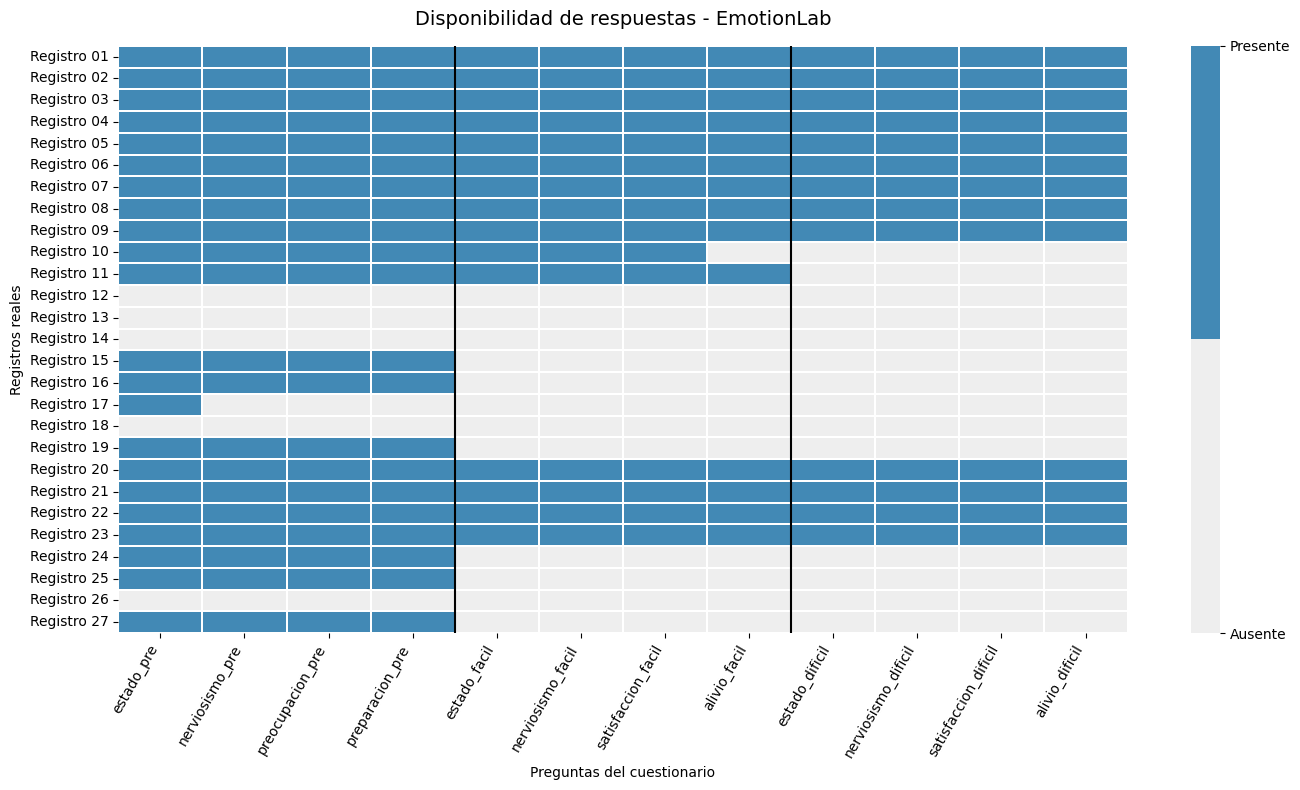

In [923]:

# =========================================================
# 3.3.3 - MAPA DE CALOR DE DISPONIBILIDAD
# =========================================================

# Creamos el espacio donde mostraremos el gráfico.

fig, ax = plt.subplots(figsize=(14, 8))

# Seaborn representa la matriz utilizando dos colores:
#
# Gris: respuesta ausente (0).
# Azul: respuesta disponible (1).

grafico = sns.heatmap(
    matriz_disponibilidad,
    cmap=["#eeeeee", "#4289b5"],
    vmin=0,
    vmax=1,
    linewidths=0.3,
    cbar_kws={"ticks": [0, 1]},
    ax=ax
)

# Agregamos etiquetas explicativas a la barra de colores.

barra = grafico.collections[0].colorbar
barra.set_ticks([0, 1])
barra.set_ticklabels(["Ausente", "Presente"])

# Marcamos visualmente los límites entre las fases
# para facilitar la comparación de sus respuestas.

ax.axvline(
    len(variables_iniciales),
    color="black",
    linewidth=1.5
)

ax.axvline(
    len(variables_iniciales) + len(variables_facil),
    color="black",
    linewidth=1.5
)

# Incorporamos títulos y etiquetas descriptivas.

ax.set_title(
    "Disponibilidad de respuestas - EmotionLab",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Preguntas del cuestionario")
ax.set_ylabel("Registros reales")

plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)

# Ajustamos los espacios y mostramos el gráfico.

plt.tight_layout()
plt.show()


## **3.4 — Estadísticas descriptivas de las respuestas reales**

### ¿Qué realizaremos en esta sección?

En esta sección estudiaremos las respuestas de los **27 registros reales de EmotionLab** mediante estadísticas descriptivas, con el objetivo de comprender cómo se distribuyen las puntuaciones de las 12 preguntas del cuestionario.

Para ello, calcularemos tres grupos de indicadores:

- **Tendencia central:** media y mediana, que permiten conocer los valores alrededor de los cuales se concentran las respuestas.
- **Dispersión:** desviación estándar y rango intercuartílico, que ayudan a identificar qué tan diferentes son las respuestas entre estudiantes.
- **Distribución y disponibilidad:** cantidad de respuestas, valores mínimos, máximos y cuartiles, que permiten conocer el rango y la concentración de las puntuaciones.

### ¿Por qué es importante?

Porque antes de comparar el nerviosismo o el estado emocional entre las distintas fases, necesitamos comprender cómo se comportan las respuestas de cada pregunta.

Esto nos permitirá identificar tendencias, diferencias y variaciones que podrían resultar relevantes para los análisis posteriores de EmotionLab.

**Importante:** utilizaremos exclusivamente las respuestas reales disponibles, sin reemplazar los valores ausentes. Debido a que trabajamos con una escala ordinal de 1 a 9, daremos especial importancia a la mediana y los cuartiles.

In [924]:

# =========================================================
# 3.4.1 - CÁLCULO DE ESTADÍSTICAS DESCRIPTIVAS
# =========================================================

# Seleccionamos las 12 preguntas de los registros reales.
# Sus valores ya fueron convertidos y validados en el 3.1.

respuestas_eda = eda_reales[variables_cuestionario]

# describe() calcula automáticamente:
# cantidad, media, desviación estándar, mínimo,
# cuartiles (25%, 50%, 75%) y máximo.
#
# Pandas excluye los valores NaN de cada cálculo.
# .T coloca las preguntas en las filas de la tabla.

estadisticas = respuestas_eda.describe().T

print("Estadísticas descriptivas calculadas.")


Estadísticas descriptivas calculadas.


In [925]:

# =========================================================
# 3.4.2 - ORGANIZACIÓN DE LAS ESTADÍSTICAS
# =========================================================

# Reemplazamos los nombres técnicos por términos
# más fáciles de comprender durante la presentación.

estadisticas = estadisticas.rename(columns={
    "count": "Cantidad",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

# Calculamos el rango intercuartílico (Q3 - Q1).
# Representa la amplitud de la mitad central
# de las respuestas disponibles.

estadisticas["Rango intercuartílico"] = (
    estadisticas["Q3"] - estadisticas["Q1"]
)

# La cantidad de respuestas debe mostrarse como entero.
# Redondeamos las demás medidas a dos decimales.

estadisticas["Cantidad"] = estadisticas["Cantidad"].astype(int)
estadisticas = estadisticas.round(2)

print("Estadísticas organizadas correctamente.")


Estadísticas organizadas correctamente.


In [926]:

# =========================================================
# 3.4.3 - PRESENTACIÓN DE LAS ESTADÍSTICAS
# =========================================================

# Mostramos la tabla con los resultados de las 12 preguntas.
# Cada fila corresponde a una variable del cuestionario.

print("ESTADÍSTICAS DESCRIPTIVAS - EMOTIONLAB")
display(estadisticas)

# Verificamos que todas las preguntas estén incluidas.

if len(estadisticas) != len(variables_cuestionario):
    raise ValueError("Faltan variables en el resumen estadístico.")

print("\nAnálisis descriptivo completado.")


ESTADÍSTICAS DESCRIPTIVAS - EMOTIONLAB


,Cantidad,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo,Rango intercuartílico
estado_pre,22,4.36,3.14,1.0,1.25,3.5,7.0,9.0,5.75
nerviosismo_pre,21,4.19,2.69,1.0,2.00,3.0,6.0,9.0,4.00
preocupacion_pre,21,3.62,2.44,1.0,1.00,4.0,5.0,9.0,4.00
preparacion_pre,21,4.29,3.04,1.0,2.00,3.0,7.0,9.0,5.00
estado_facil,15,2.87,2.64,1.0,1.00,2.0,4.0,9.0,3.00
nerviosismo_facil,15,3.33,2.72,1.0,1.00,2.0,5.0,9.0,4.00
satisfaccion_facil,15,3.00,2.67,1.0,1.50,2.0,2.5,9.0,1.00
alivio_facil,14,2.71,2.13,1.0,1.00,2.5,3.0,8.0,2.00
estado_dificil,13,1.85,1.07,1.0,1.00,2.0,2.0,4.0,1.00
nerviosismo_dificil,13,2.77,2.13,1.0,1.00,3.0,3.0,9.0,2.00



Análisis descriptivo completado.


## **3.5 — Distribución de respuestas**

### ¿Qué realizaremos en esta sección?

En esta sección analizaremos cómo se distribuyen las respuestas de los estudiantes reales en las 12 preguntas de EmotionLab, utilizando gráficos de barras para representar la frecuencia de cada puntuación.

Para ello, realizaremos tres procesos:

- **Cálculo de frecuencias:** contaremos cuántas veces aparece cada valor de la escala de 1 a 9.
- **Organización de los gráficos:** distribuiremos las 12 preguntas según las fases inicial, fácil y difícil.
- **Visualización:** representaremos las frecuencias utilizando las mismas escalas para facilitar su comparación.

### ¿Por qué es importante?

Las estadísticas descriptivas permiten conocer valores generales, como la media y la mediana, pero no muestran cómo se distribuyen todas las respuestas.

Por ejemplo, dos preguntas podrían tener la misma media, aunque sus respuestas estén concentradas en valores muy diferentes.

Estos gráficos nos ayudarán a identificar concentraciones de respuestas, diferencias entre estudiantes y posibles patrones que podrían ser relevantes durante los siguientes análisis.

**Importante:** trabajaremos exclusivamente con los registros reales. Las respuestas ausentes no se incluirán en las frecuencias ni serán reemplazadas por valores estimados.

In [927]:

# =========================================================
# 3.5.1 - CÁLCULO DE FRECUENCIAS
# =========================================================

# Organizamos las preguntas según las tres fases
# para mantener un orden lógico en los gráficos.

variables_graficos = (
    list(variables_iniciales)
    + list(variables_facil)
    + list(variables_dificil)
)

# Verificamos que estén las 12 preguntas originales,
# sin variables faltantes ni repetidas.

if (
    len(variables_graficos) != 12
    or len(set(variables_graficos)) != 12
    or set(variables_graficos) != set(variables_cuestionario)
):
    raise ValueError("Revisa las variables del cuestionario.")

# Definimos la escala utilizada en EmotionLab.

escala = range(ESCALA_MINIMA, ESCALA_MAXIMA + 1)

# value_counts() cuenta cuántas veces aparece cada respuesta.
# reindex() incluye también las puntuaciones con frecuencia 0.
#
# Guardamos las frecuencias para reutilizarlas
# sin repetir los cálculos al generar los gráficos.

frecuencias_eda = {
    variable: eda_reales[variable]
    .value_counts()
    .reindex(escala, fill_value=0)
    for variable in variables_graficos
}

print("Frecuencias calculadas para las 12 preguntas.")


Frecuencias calculadas para las 12 preguntas.


Gráficos de distribución preparados.


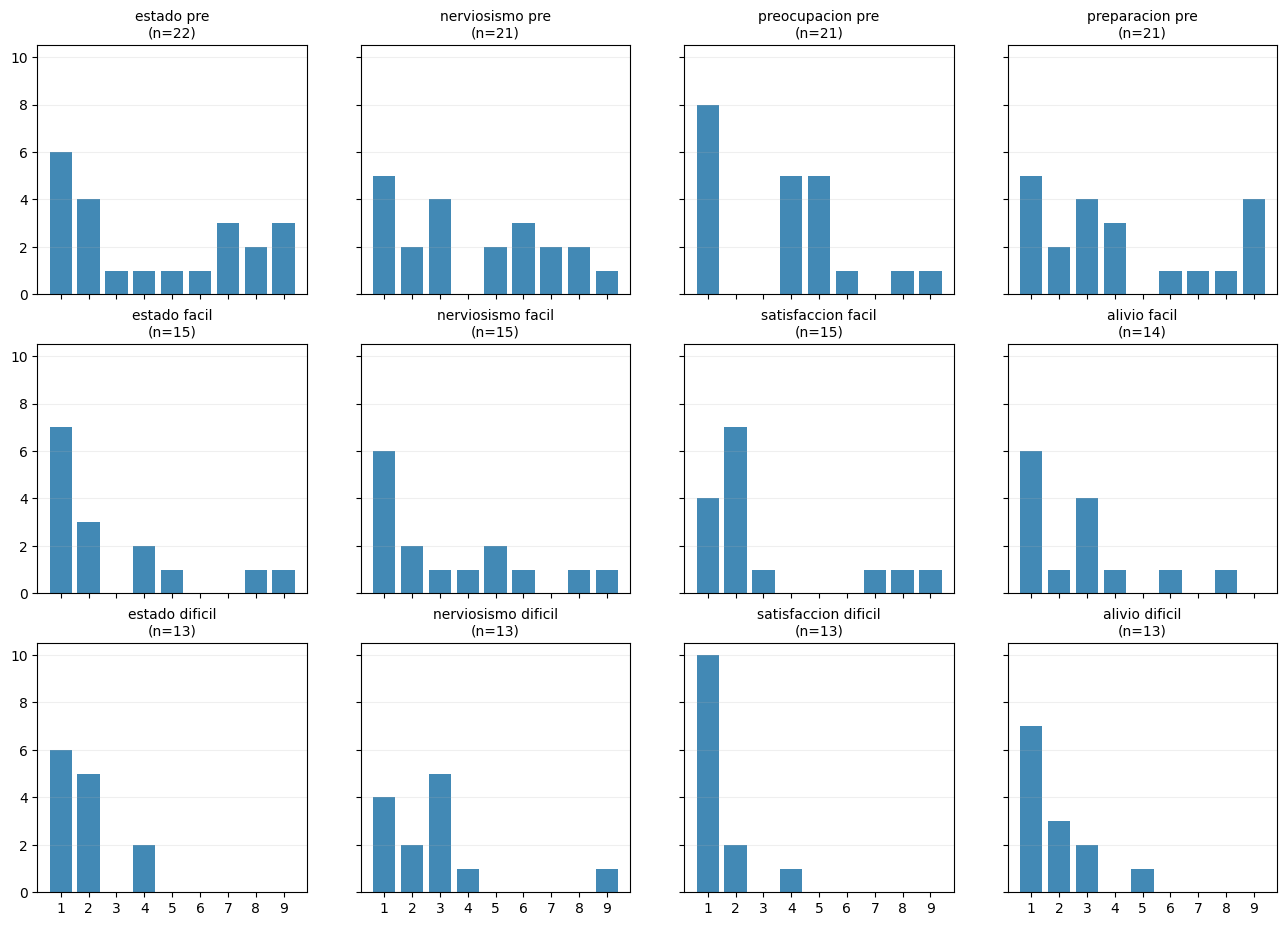

In [928]:

# =========================================================
# 3.5.2 - GRÁFICOS DE DISTRIBUCIÓN
# =========================================================

# Creamos una figura con 3 filas y 4 columnas.
#
# Cada fila representa una fase de EmotionLab:
# inicial, fácil y difícil.
#
# sharex y sharey permiten compartir las escalas
# para facilitar la comparación entre preguntas.

figura, ejes = plt.subplots(
    3, 4,
    figsize=(16, 11),
    sharex=True,
    sharey=True
)

# Recorremos las preguntas y asignamos un gráfico
# a cada variable utilizando los ejes disponibles.

for eje, variable in zip(ejes.flat, variables_graficos):

    frecuencias = frecuencias_eda[variable]

    # Representamos cuántos estudiantes seleccionaron
    # cada puntuación entre 1 y 9.

    eje.bar(
        frecuencias.index,
        frecuencias.values,
        color="#4289b5"
    )

    # Mostramos el nombre de la pregunta y su cantidad
    # de respuestas disponibles.
    #
    # n representa respuestas observadas, no el total
    # de los 27 estudiantes.

    eje.set_title(
        f"{variable.replace('_', ' ')}\n(n={frecuencias.sum()})",
        fontsize=10
    )

    eje.set_xticks(list(escala))
    eje.grid(axis="y", alpha=0.2)

print("Gráficos de distribución preparados.")


In [929]:

# =========================================================
# 3.5.3 - PRESENTACIÓN DE LAS DISTRIBUCIONES
# =========================================================

# Identificamos la frecuencia más alta de todas
# las preguntas para utilizar un mismo límite vertical.

frecuencia_maxima = max(
    frecuencias.max()
    for frecuencias in frecuencias_eda.values()
)

# Establecemos el mismo rango del eje vertical
# para evitar comparaciones visuales engañosas.

ejes[0, 0].set_ylim(
    0,
    max(1, frecuencia_maxima) + 0.5
)

# Agregamos etiquetas generales en lugar de repetir
# los nombres de los ejes en los 12 gráficos.

figura.supxlabel("Puntuación de respuesta (1 a 9)")
figura.supylabel("Cantidad de respuestas")

# Incorporamos un título que identifique el análisis.

figura.suptitle(
    "Distribución de respuestas reales - EmotionLab",
    fontsize=15
)

# Ajustamos los espacios y mostramos la figura.

plt.tight_layout()
plt.show()

print("Visualización de distribuciones completada.")


<Figure size 640x480 with 0 Axes>

Visualización de distribuciones completada.


## **3.6 — Comparación de las respuestas emocionales entre fases**

### ¿Qué realizaremos en esta sección?

En esta sección analizaremos las respuestas relacionadas con el **nerviosismo y el estado emocional** de los estudiantes durante los tres momentos de EmotionLab: inicial, dificultad fácil y dificultad difícil.

Para ello, realizaremos tres procesos:

- **Selección de indicadores:** identificaremos las preguntas de nerviosismo y estado emocional que se repiten en los tres formularios.
- **Organización de respuestas:** reuniremos las puntuaciones de cada fase para facilitar su comparación.
- **Visualización:** utilizaremos gráficos de caja (*boxplots*) y puntos individuales para observar medianas, dispersión y diferencias entre las respuestas.

### ¿Por qué es importante?

Porque necesitamos comprender si las respuestas emocionales presentan cambios entre los distintos momentos de la experiencia.

Los gráficos nos ayudarán a identificar tendencias que podrían resultar relevantes para comprender la tensión emocional percibida por los estudiantes.

**Importante:** las comparaciones serán exploratorias. No podremos afirmar que la dificultad de las presentaciones sea la causa de los cambios, y tampoco interpretaremos las puntuaciones como diagnósticos psicológicos.

In [930]:

# =========================================================
# 3.6.1 - SELECCIÓN DE LOS INDICADORES EMOCIONALES
# =========================================================

# EmotionLab registra nerviosismo y estado emocional
# en tres momentos de la experiencia.
#
# Organizamos las columnas según la fase a la que
# pertenece cada respuesta.

indicadores = {
    "Nerviosismo": {
        "Inicial": "nerviosismo_pre",
        "Fácil": "nerviosismo_facil",
        "Difícil": "nerviosismo_dificil"
    },
    "Estado emocional": {
        "Inicial": "estado_pre",
        "Fácil": "estado_facil",
        "Difícil": "estado_dificil"
    }
}

orden_etapas = ["Inicial", "Fácil", "Difícil"]

# Comprobamos que las seis variables estén disponibles
# en los registros reales preparados durante el 3.1.
#
# Si falta alguna, detenemos el análisis para evitar
# comparar información incorrecta.

variables_comparacion = [
    variable
    for columnas in indicadores.values()
    for variable in columnas.values()
]

faltantes = [
    variable for variable in variables_comparacion
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(
        f"Faltan indicadores emocionales: {faltantes}"
    )

print("Indicadores emocionales preparados correctamente.")
print("Variables seleccionadas:", len(variables_comparacion))


Indicadores emocionales preparados correctamente.
Variables seleccionadas: 6


In [931]:

# =========================================================
# 3.6.2 - ORGANIZACIÓN DE RESPUESTAS POR FASE
# =========================================================

# Seaborn necesita que las respuestas estén organizadas
# en columnas que indiquen la fase y su puntuación.
#
# melt() transforma las columnas originales en filas,
# dejando todas las respuestas bajo una misma estructura.

datos_indicadores = {}
resumen_indicadores = []

for nombre, columnas in indicadores.items():

    # Seleccionamos únicamente las tres preguntas
    # correspondientes al indicador.

    datos = eda_reales[list(columnas.values())].copy()

    # Cambiamos los nombres técnicos por las fases.
    # Por ejemplo: nerviosismo_pre pasa a ser Inicial.

    datos.columns = list(columnas.keys())

    # Unimos las respuestas en dos columnas:
    # Etapa: momento de la experiencia.
    # Respuesta: puntuación entregada por el estudiante.

    datos = datos.melt(
        var_name="Etapa",
        value_name="Respuesta"
    ).dropna(subset=["Respuesta"])

    # Conservamos solo las respuestas observadas.
    # No estimamos ni reemplazamos valores ausentes.

    datos_indicadores[nombre] = datos

    # Registramos la cantidad de respuestas y su mediana
    # para conocer el tamaño de cada grupo comparado.

    for etapa in orden_etapas:

        respuestas = datos.loc[
            datos["Etapa"] == etapa, "Respuesta"
        ]

        resumen_indicadores.append({
            "Indicador": nombre,
            "Etapa": etapa,
            "Respuestas": len(respuestas),
            "Mediana": respuestas.median()
        })

# Creamos una tabla resumida para revisar los datos.

tabla_indicadores = pd.DataFrame(resumen_indicadores)

print("RESPUESTAS EMOCIONALES POR FASE - EMOTIONLAB")
display(tabla_indicadores.round(2))


RESPUESTAS EMOCIONALES POR FASE - EMOTIONLAB


,Indicador,Etapa,Respuestas,Mediana
0,Nerviosismo,Inicial,21,3.0
1,Nerviosismo,Fácil,15,2.0
2,Nerviosismo,Difícil,13,3.0
3,Estado emocional,Inicial,22,3.5
4,Estado emocional,Fácil,15,2.0
5,Estado emocional,Difícil,13,2.0


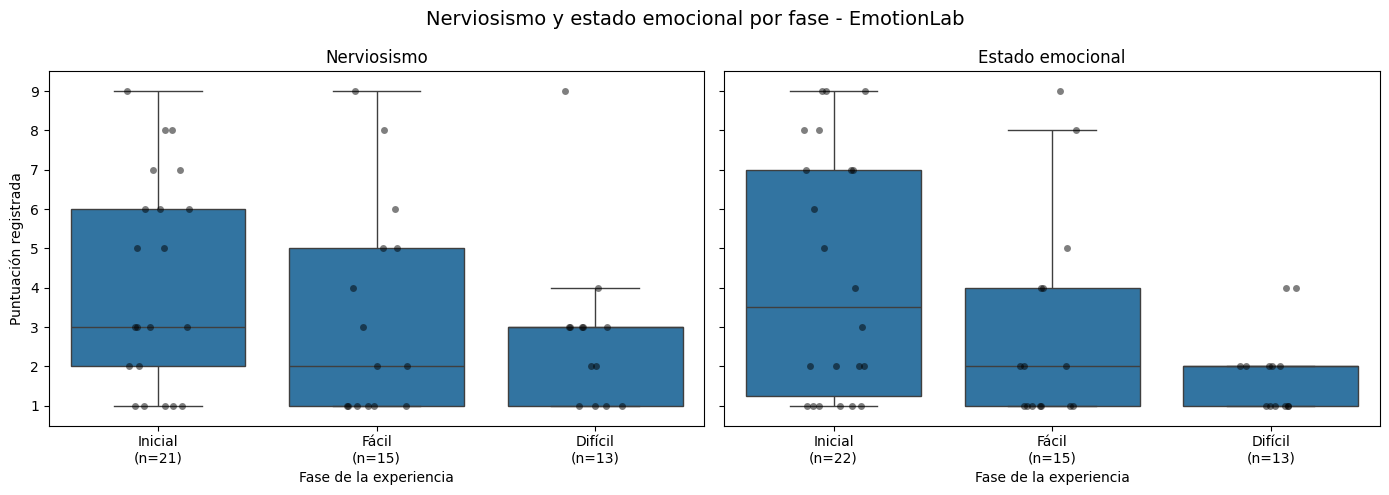

Comparación exploratoria completada.


In [932]:

# =========================================================
# 3.6.3 - COMPARACIÓN EMOCIONAL ENTRE FASES
# =========================================================

# Creamos dos gráficos en una misma figura.
# sharey=True mantiene la misma escala vertical
# para ambos indicadores.

figura, ejes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for eje, (nombre, datos) in zip(
    ejes, datos_indicadores.items()
):

    # Si no existen respuestas, mostramos un aviso
    # en lugar de generar un gráfico vacío.

    if datos.empty:
        eje.set_title(nombre)
        eje.text(
            0.5, 0.5,
            "Sin respuestas disponibles",
            ha="center",
            va="center",
            transform=eje.transAxes
        )
        eje.set_xticks([])
        continue

    # El boxplot muestra la mediana, los cuartiles
    # y la dispersión de las respuestas.
    #
    # Ocultamos los puntos extremos del boxplot
    # porque los mostraremos con stripplot.

    sns.boxplot(
        data=datos,
        x="Etapa",
        y="Respuesta",
        order=orden_etapas,
        showfliers=False,
        ax=eje
    )

    # Agregamos las respuestas individuales.
    #
    # jitter separa ligeramente los puntos para
    # que no queden todos superpuestos.
    #
    # Esto permite observar las puntuaciones reales,
    # incluyendo los posibles valores extremos.

    sns.stripplot(
        data=datos,
        x="Etapa",
        y="Respuesta",
        order=orden_etapas,
        color="black",
        alpha=0.5,
        jitter=0.15,
        ax=eje
    )

    # Mostramos cuántas respuestas tiene cada fase.
    # Es importante porque no todos los estudiantes
    # completaron los tres formularios.

    etiquetas = [
        f"{etapa}\n(n={(datos['Etapa'] == etapa).sum()})"
        for etapa in orden_etapas
    ]

    eje.set_xticks(range(len(orden_etapas)))
    eje.set_xticklabels(etiquetas)

    # Utilizamos la misma escala de 1 a 9
    # para facilitar la comparación de resultados.

    eje.set_title(nombre)
    eje.set_xlabel("Fase de la experiencia")
    eje.set_ylabel("Puntuación registrada")
    eje.set_ylim(ESCALA_MINIMA - 0.5, ESCALA_MAXIMA + 0.5)

# Agregamos el título general de la figura.

figura.suptitle(
    "Nerviosismo y estado emocional por fase - EmotionLab",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Comparación exploratoria completada.")


## **3.7 — Análisis de correlaciones**

### ¿Qué realizaremos en esta sección?

Analizaremos las relaciones entre las 12 variables de EmotionLab utilizando el coeficiente de correlación de **Spearman**, un método adecuado para explorar asociaciones entre respuestas ordinales.

Dividiremos el análisis en cuatro partes:

- **Preparación:** seleccionaremos las respuestas reales que utilizaremos en las correlaciones.
- **Cálculo:** identificaremos las asociaciones entre variables y la cantidad de estudiantes disponibles para cada comparación.
- **Revisión:** organizaremos los resultados en tablas para comprender qué correlaciones pudieron calcularse.
- **Visualización:** generaremos un mapa de calor que permita identificar asociaciones positivas y negativas.

### ¿Por qué es importante?

Este análisis nos ayudará a comprender si determinadas respuestas tienden a variar conjuntamente. Por ejemplo, podremos explorar si los estudiantes que declaran mayor nerviosismo también presentan ciertas tendencias en sus respuestas de preparación o satisfacción.

Esto puede aportar información relevante para comprender las relaciones entre las variables antes de desarrollar el modelo de Machine Learning.

**Consideración:** una correlación no demuestra causalidad. Además, trabajaremos exclusivamente con los datos reales disponibles y exigiremos un mínimo de cinco estudiantes con respuestas en ambas variables para calcular cada correlación exploratoria.

In [933]:

# =========================================================
# 3.7.1 - PREPARACIÓN DE LOS DATOS PARA CORRELACIONES
# =========================================================

# Utilizamos los registros reales preparados en el 3.1.
# No incorporamos datos sintéticos ni estimamos respuestas.

# Verificamos que las variables del cuestionario existan
# y no estén repetidas.

faltantes = [
    variable for variable in variables_cuestionario
    if variable not in eda_reales.columns
]

if faltantes or len(set(variables_cuestionario)) != 12:
    raise ValueError(
        f"Revisa las 12 variables del cuestionario. "
        f"Columnas faltantes: {faltantes}"
    )

# Seleccionamos únicamente las respuestas que analizaremos.
# No es necesario crear otra copia porque no las modificaremos.

respuestas_correlacion = eda_reales[variables_cuestionario]

print("Variables preparadas:", respuestas_correlacion.shape[1])
print("Registros reales:", len(respuestas_correlacion))


Variables preparadas: 12
Registros reales: 27


In [934]:

# =========================================================
# 3.7.2 - CÁLCULO DE CORRELACIONES DE SPEARMAN
# =========================================================

# Establecemos el mínimo de pares necesarios.
# Cada par corresponde a un estudiante que respondió
# las dos preguntas que estamos comparando.

minimo_pares = 5

# corr() calcula las asociaciones de Spearman.
# min_periods evita calcular correlaciones cuando
# existen menos de cinco pares válidos.
#
# Pandas excluye los NaN de cada comparación sin
# eliminar al estudiante de todos los demás análisis.

matriz_correlacion = respuestas_correlacion.corr(
    method="spearman",
    min_periods=minimo_pares
)

# Creamos una matriz donde:
# 1 = respuesta presente.
# 0 = respuesta ausente.

presencia = respuestas_correlacion.notna().astype(int)

# Multiplicamos la matriz transpuesta por la original.
# Así contamos cuántos estudiantes tienen respuestas
# disponibles en cada combinación de preguntas.

matriz_pares = presencia.T @ presencia

print("Correlaciones de Spearman calculadas.")
print("Mínimo de pares exigidos:", minimo_pares)


Correlaciones de Spearman calculadas.
Mínimo de pares exigidos: 5


In [935]:

# =========================================================
# 3.7.3 - REVISIÓN DE LOS RESULTADOS
# =========================================================

# Primero mostramos cuántos estudiantes tienen
# respuestas disponibles para cada par de variables.

print("ESTUDIANTES DISPONIBLES POR COMPARACIÓN")
display(matriz_pares)

# Después mostramos los coeficientes de Spearman.
# Redondeamos a dos decimales para facilitar la lectura.

print("\nMATRIZ DE CORRELACIONES - EMOTIONLAB")
display(matriz_correlacion.round(2))

# Identificamos las correlaciones que no pudieron
# calcularse por falta de datos o ausencia de variación.
#
# Estos valores aparecerán como NaN y NO deben
# interpretarse como correlaciones iguales a cero.

correlaciones_ausentes = matriz_correlacion.isna()

print("\nRevisión de correlaciones completada.")


ESTUDIANTES DISPONIBLES POR COMPARACIÓN


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
estado_pre,22,21,21,21,15,15,15,14,13,13,13,13
nerviosismo_pre,21,21,21,21,15,15,15,14,13,13,13,13
preocupacion_pre,21,21,21,21,15,15,15,14,13,13,13,13
preparacion_pre,21,21,21,21,15,15,15,14,13,13,13,13
estado_facil,15,15,15,15,15,15,15,14,13,13,13,13
nerviosismo_facil,15,15,15,15,15,15,15,14,13,13,13,13
satisfaccion_facil,15,15,15,15,15,15,15,14,13,13,13,13
alivio_facil,14,14,14,14,14,14,14,14,13,13,13,13
estado_dificil,13,13,13,13,13,13,13,13,13,13,13,13
nerviosismo_dificil,13,13,13,13,13,13,13,13,13,13,13,13



MATRIZ DE CORRELACIONES - EMOTIONLAB


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
estado_pre,1.00,0.56,0.17,0.73,0.65,0.42,0.52,0.30,0.11,0.13,0.21,0.43
nerviosismo_pre,0.56,1.00,0.29,0.52,0.51,0.49,0.70,0.31,0.13,0.25,0.07,0.43
preocupacion_pre,0.17,0.29,1.00,0.24,-0.09,-0.11,-0.05,-0.03,0.45,0.60,0.29,-0.07
preparacion_pre,0.73,0.52,0.24,1.00,0.70,0.69,0.43,0.75,0.35,0.64,0.08,0.59
estado_facil,0.65,0.51,-0.09,0.70,1.00,0.76,0.74,0.75,0.24,0.22,0.20,0.51
nerviosismo_facil,0.42,0.49,-0.11,0.69,0.76,1.00,0.67,0.84,0.16,0.39,0.17,0.54
satisfaccion_facil,0.52,0.70,-0.05,0.43,0.74,0.67,1.00,0.60,0.10,-0.00,-0.25,0.20
alivio_facil,0.30,0.31,-0.03,0.75,0.75,0.84,0.60,1.00,0.29,0.62,0.07,0.58
estado_dificil,0.11,0.13,0.45,0.35,0.24,0.16,0.10,0.29,1.00,0.55,0.49,0.15
nerviosismo_dificil,0.13,0.25,0.60,0.64,0.22,0.39,-0.00,0.62,0.55,1.00,0.44,0.65



Revisión de correlaciones completada.


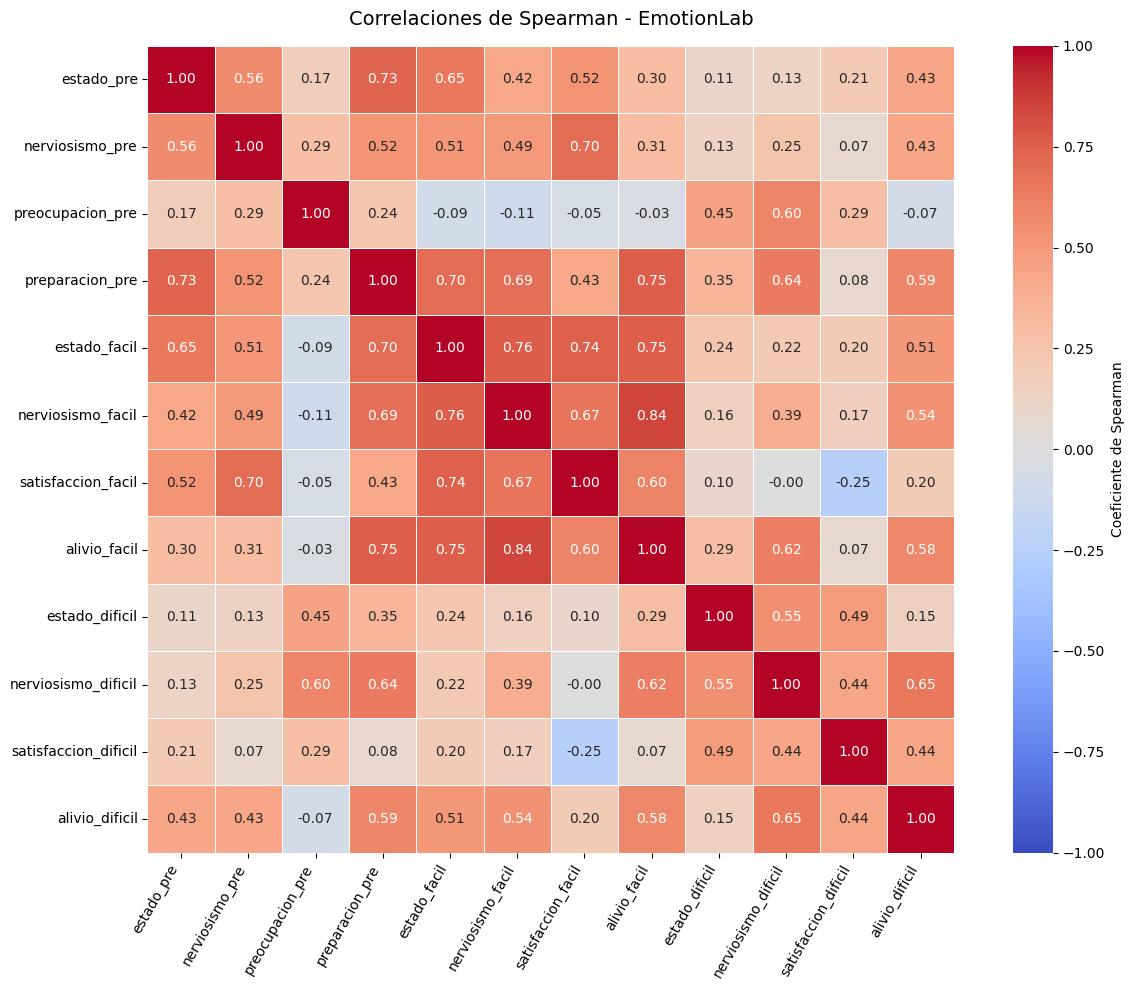

Mapa de correlaciones generado correctamente.


In [936]:

# =========================================================
# 3.7.4 - MAPA DE CALOR DE CORRELACIONES
# =========================================================

# Verificamos que exista al menos una correlación válida.
# Si todas son NaN, no generaremos un gráfico vacío.

if matriz_correlacion.notna().any().any():

    # Creamos el espacio donde mostraremos el mapa.

    fig, ax = plt.subplots(figsize=(13, 10))

    # Cada celda representa la correlación entre dos preguntas.
    #
    # Rojo: asociación positiva.
    # Azul: asociación negativa.
    # Valores cercanos a 0: asociación monotónica débil.
    #
    # mask oculta las correlaciones que no se pudieron
    # calcular por falta de datos o variación.

    sns.heatmap(
        matriz_correlacion,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        mask=correlaciones_ausentes,
        linewidths=0.4,
        square=True,
        cbar_kws={"label": "Coeficiente de Spearman"},
        ax=ax
    )

    # Ajustamos el título y las etiquetas para que
    # las 12 variables puedan identificarse claramente.

    ax.set_title(
        "Correlaciones de Spearman - EmotionLab",
        fontsize=14,
        pad=15
    )

    plt.xticks(rotation=60, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    print("Mapa de correlaciones generado correctamente.")

else:
    print("No existen correlaciones suficientes para graficar.")


##**3.8 — Perfil global del estudiante**

### ¿Qué realizaremos en esta sección?

Construiremos un perfil descriptivo individual de los estudiantes de EmotionLab, utilizando las respuestas registradas durante las fases inicial, fácil y difícil.

Para ello, realizaremos tres procesos:

- **Selección:** identificaremos a los estudiantes que completaron las 12 preguntas de los tres formularios.
- **Cálculo de indicadores:** obtendremos la mediana del nerviosismo, la mediana del estado emocional y los cambios numéricos entre el inicio y el final.
- **Resumen:** presentaremos los perfiles individuales y sus estadísticas descriptivas generales.

### ¿Por qué es importante?

Los análisis anteriores nos permitieron conocer las tendencias generales de los estudiantes. Sin embargo, esas tendencias no muestran necesariamente lo que ocurrió con cada participante.

Este apartado nos ayudará a identificar diferencias individuales y estudiar cómo cambiaron las puntuaciones de un mismo estudiante durante la experiencia.

**Importante:** los indicadores calculados son descriptivos. No representan todavía el índice de tensión de EmotionLab ni permiten determinar niveles clínicos de estrés.

Trabajaremos únicamente con estudiantes que tengan las 12 respuestas completas, sin estimar valores faltantes.

In [937]:

# =========================================================
# 3.8.1 - SELECCIÓN DE PERFILES COMPLETOS
# =========================================================

# Para construir un perfil global necesitamos conocer
# las respuestas de las tres fases de EmotionLab.
#
# Seleccionamos únicamente los registros que contienen
# las 12 preguntas completas del cuestionario.

perfiles_completos = eda_reales.dropna(
    subset=variables_cuestionario
).copy()

# Definimos las preguntas que representan nerviosismo
# y estado emocional en cada momento de la experiencia.
#
# Conservamos el orden: Inicial, Fácil y Difícil.

columnas_nerviosismo = [
    "nerviosismo_pre",
    "nerviosismo_facil",
    "nerviosismo_dificil"
]

columnas_estado = [
    "estado_pre",
    "estado_facil",
    "estado_dificil"
]

# Comprobamos que las variables y el identificador
# estén disponibles antes de realizar los cálculos.

columnas_requeridas = (
    columnas_nerviosismo
    + columnas_estado
    + ["id_estudiante"]
)

faltantes = [
    columna for columna in columnas_requeridas
    if columna not in perfiles_completos.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas para el perfil: {faltantes}")

print("Registros reales:", len(eda_reales))
print("Perfiles completos:", len(perfiles_completos))


Registros reales: 27
Perfiles completos: 13


In [938]:

# =========================================================
# 3.8.2 - CÁLCULO DEL PERFIL GLOBAL
# =========================================================

# Calculamos la mediana de nerviosismo y estado emocional
# utilizando las respuestas de las tres fases.
#
# median(axis=1) calcula el valor central por estudiante,
# en lugar de calcularlo para todos los participantes.

perfiles_completos["mediana_nerviosismo"] = (
    perfiles_completos[columnas_nerviosismo].median(axis=1)
)

perfiles_completos["mediana_estado"] = (
    perfiles_completos[columnas_estado].median(axis=1)
)

# Calculamos el cambio entre la evaluación final
# (dificultad difícil) y la evaluación inicial.
#
# Cambio positivo: la puntuación final es mayor.
# Cambio negativo: la puntuación final es menor.
# Cambio cero: ambas puntuaciones son iguales.

perfiles_completos["cambio_nerviosismo"] = (
    perfiles_completos["nerviosismo_dificil"]
    - perfiles_completos["nerviosismo_pre"]
)

perfiles_completos["cambio_estado"] = (
    perfiles_completos["estado_dificil"]
    - perfiles_completos["estado_pre"]
)

# Estos cambios representan diferencias numéricas.
# Su interpretación emocional depende del significado
# de cada escala utilizada en Unity.

print("Indicadores individuales calculados correctamente.")


Indicadores individuales calculados correctamente.


In [939]:

# =========================================================
# 3.8.3 - RESUMEN DE LOS PERFILES GLOBALES
# =========================================================

# Seleccionamos los cuatro indicadores calculados
# para construir una tabla descriptiva individual.

columnas_perfil = [
    "mediana_nerviosismo",
    "mediana_estado",
    "cambio_nerviosismo",
    "cambio_estado"
]

# Conservamos el identificador seudónimo para mantener
# la correspondencia con los registros originales.

perfil_global = perfiles_completos[
    ["id_estudiante"] + columnas_perfil
].copy()

print("PERFIL GLOBAL - EMOTIONLAB")
print("Estudiantes analizados:", len(perfil_global))

if not perfil_global.empty:

    # Para mostrar los resultados utilizamos etiquetas
    # temporales, evitando exponer identificadores
    # originales durante la presentación.

    perfil_presentacion = perfil_global.copy()

    perfil_presentacion["id_estudiante"] = [
        f"Registro {i:02d}"
        for i in range(1, len(perfil_global) + 1)
    ]

    display(perfil_presentacion)

    # describe() resume la distribución de los indicadores
    # entre los estudiantes con cuestionarios completos.
    #
    # Calcula cantidad, media, mediana, desviación estándar,
    # valores mínimos, máximos y cuartiles.

    print("\nRESUMEN ESTADÍSTICO DE LOS PERFILES")
    display(perfil_global[columnas_perfil].describe().round(2))

else:
    print("No existen cuestionarios completos para este análisis.")

print("\nAnálisis de perfiles globales finalizado.")


PERFIL GLOBAL - EMOTIONLAB
Estudiantes analizados: 13


,id_estudiante,mediana_nerviosismo,mediana_estado,cambio_nerviosismo,cambio_estado
0,Registro 01,3.0,1.0,0.0,3.0
1,Registro 02,3.0,2.0,0.0,0.0
2,Registro 03,1.0,1.0,2.0,3.0
3,Registro 04,2.0,2.0,-3.0,-1.0
4,Registro 05,3.0,2.0,0.0,0.0
5,Registro 06,1.0,1.0,0.0,0.0
6,Registro 07,2.0,1.0,7.0,0.0
7,Registro 08,1.0,1.0,0.0,0.0
8,Registro 09,1.0,1.0,0.0,-5.0
19,Registro 10,1.0,1.0,-4.0,0.0



RESUMEN ESTADÍSTICO DE LOS PERFILES


,mediana_nerviosismo,mediana_estado,cambio_nerviosismo,cambio_estado
count,13.00,13.00,13.00,13.00
mean,2.15,1.54,-0.31,-0.46
std,1.21,0.88,2.84,2.37
min,1.00,1.00,-4.00,-5.00
25%,1.00,1.00,-2.00,-1.00
50%,2.00,1.00,0.00,0.00
75%,3.00,2.00,0.00,0.00
max,5.00,4.00,7.00,3.00



Análisis de perfiles globales finalizado.


##**3.9 — Revisión exploratoria de valores extremos**

### ¿Qué realizaremos en esta sección?

En esta sección revisaremos las respuestas de los estudiantes reales de EmotionLab para identificar puntuaciones que se encuentren alejadas de la distribución central de cada pregunta.

Utilizaremos el **rango intercuartílico (IQR)**, un método estadístico que permite detectar posibles valores extremos mediante los cuartiles Q1 y Q3.

El análisis se dividirá en tres partes:

- **Cálculo de cuartiles:** obtendremos Q1, Q3 y el rango intercuartílico de las 12 preguntas.
- **Identificación de valores extremos:** calcularemos los límites estadísticos y contaremos las respuestas que se encuentren fuera de ellos.
- **Revisión de resultados:** presentaremos una tabla para reconocer qué variables contienen posibles valores extremos.

### ¿Por qué es importante?

Este procedimiento nos permitirá identificar respuestas poco frecuentes y estudiar la variabilidad existente entre los estudiantes.

Sin embargo, **un valor extremo no necesariamente es una respuesta incorrecta**. Por ejemplo, si la mayoría de los participantes responde 1 en una pregunta, una respuesta de 8 podría identificarse como extrema y seguir siendo válida dentro de la escala de EmotionLab.

Por esta razón, no eliminaremos ni modificaremos las respuestas identificadas. El análisis será exclusivamente descriptivo y utilizará los registros reales disponibles.

In [940]:

# =========================================================
# 3.9.1 - CÁLCULO DEL RANGO INTERCUARTÍLICO
# =========================================================

# Utilizamos las 12 preguntas de los registros reales.
# Los valores ausentes se excluyen automáticamente
# del cálculo de los cuartiles.

respuestas_extremos = eda_reales[variables_cuestionario]

# Calculamos Q1 (25 %) y Q3 (75 %) para cada pregunta.
#
# Q1: primer cuartil de las respuestas.
# Q3: tercer cuartil de las respuestas.

cuartiles = respuestas_extremos.quantile([0.25, 0.75])

q1 = cuartiles.loc[0.25]
q3 = cuartiles.loc[0.75]

# El IQR representa la diferencia entre Q3 y Q1.
# Nos permite medir la dispersión de la mitad
# central de las respuestas de cada variable.

rango_iqr = q3 - q1

print("Cuartiles y rangos intercuartílicos calculados.")


Cuartiles y rangos intercuartílicos calculados.


In [941]:

# =========================================================
# 3.9.2 - IDENTIFICACIÓN DE VALORES EXTREMOS
# =========================================================

# Establecemos los límites estadísticos:
#
# Inferior = Q1 - 1.5 * IQR
# Superior = Q3 + 1.5 * IQR
#
# Una respuesta fuera de estos límites será
# considerada un posible valor extremo por IQR.

limite_inferior = q1 - 1.5 * rango_iqr
limite_superior = q3 + 1.5 * rango_iqr

# Comparamos las respuestas de cada pregunta
# con sus límites correspondientes.
#
# lt() identifica valores menores al límite inferior.
# gt() identifica valores mayores al límite superior.
#
# axis="columns" permite comparar cada columna
# con el límite calculado para esa misma pregunta.

marcas_extremos = (
    respuestas_extremos.lt(limite_inferior, axis="columns")
    | respuestas_extremos.gt(limite_superior, axis="columns")
)

# Contamos cuántas respuestas fueron evaluadas
# y cuántas se encuentran fuera de los límites.

cantidad_respuestas = respuestas_extremos.count()
cantidad_extremos = marcas_extremos.sum()

# Si una pregunta no tiene respuestas disponibles,
# dejamos su cantidad de extremos sin calcular (NaN).
# No debemos confundir "sin datos" con "cero extremos".

cantidad_extremos = cantidad_extremos.where(
    cantidad_respuestas.gt(0),
    np.nan
)

print("Posibles valores extremos identificados.")


Posibles valores extremos identificados.


In [942]:

# =========================================================
# 3.9.3 - RESUMEN DE LOS VALORES EXTREMOS
# =========================================================

# Organizamos los resultados de las 12 preguntas.
# Cada fila mostrará sus respuestas disponibles,
# límites estadísticos y cantidad de posibles extremos.

tabla_extremos = pd.DataFrame({
    "Variable": variables_cuestionario,
    "Respuestas evaluadas": cantidad_respuestas.values,
    "Límite inferior": limite_inferior.values,
    "Límite superior": limite_superior.values,
    "Valores extremos por IQR": cantidad_extremos.values
})

# Redondeamos solamente la visualización.
# Los cálculos anteriores mantienen su precisión original.

print("REVISIÓN DE VALORES EXTREMOS - EMOTIONLAB")
display(tabla_extremos.round(2))

# Sumamos las respuestas identificadas como extremas.
# Este total representa respuestas, no estudiantes únicos.

total_extremos = int(cantidad_extremos.sum())

print("\nRespuestas evaluadas:", int(cantidad_respuestas.sum()))
print("Posibles valores extremos:", total_extremos)

# Una variable con IQR = 0 tiene Q1 y Q3 iguales.
# En ese caso, cualquier puntuación distinta de ese
# valor central puede quedar marcada como extrema.
#
# Esto requiere especial precaución con muestras pequeñas.

variables_iqr_cero = rango_iqr[
    rango_iqr.eq(0) & cantidad_respuestas.gt(0)
].index.tolist()

if variables_iqr_cero:
    print("\nAtención: variables con IQR igual a cero:")
    print(", ".join(variables_iqr_cero))

# Recordamos que las puntuaciones identificadas
# no se eliminan ni modifican en el dataset.

print(
    "\nAnálisis exploratorio completado. "
    "No se modificaron ni eliminaron respuestas."
)


REVISIÓN DE VALORES EXTREMOS - EMOTIONLAB


,Variable,Respuestas evaluadas,Límite inferior,Límite superior,Valores extremos por IQR
0,estado_pre,22,-7.38,15.62,0
1,nerviosismo_pre,21,-4.00,12.00,0
2,preocupacion_pre,21,-5.00,11.00,0
3,preparacion_pre,21,-5.50,14.50,0
4,estado_facil,15,-3.50,8.50,1
5,nerviosismo_facil,15,-5.00,11.00,0
6,satisfaccion_facil,15,0.00,4.00,3
7,alivio_facil,14,-2.00,6.00,1
8,estado_dificil,13,-0.50,3.50,2
9,nerviosismo_dificil,13,-2.00,6.00,1



Respuestas evaluadas: 196
Posibles valores extremos: 12

Atención: variables con IQR igual a cero:
satisfaccion_dificil

Análisis exploratorio completado. No se modificaron ni eliminaron respuestas.


## Conclusión de la Etapa 3: Análisis Exploratorio de Datos (EDA)

Durante esta etapa analizamos las respuestas de los estudiantes reales de EmotionLab, con el objetivo de comprender cómo se distribuyen sus puntuaciones, identificar posibles relaciones entre variables y estudiar las diferencias observadas durante las tres fases de la experiencia.

El análisis se realizó exclusivamente con los **27 registros reales**, sin incorporar datos sintéticos ni reemplazar respuestas faltantes.

### 1. Preparación y disponibilidad de los datos

Comenzamos verificando que las respuestas estuvieran correctamente preparadas para los análisis estadísticos.

Los principales resultados fueron:

- **12 variables** correspondientes a los tres cuestionarios.
- **196 respuestas disponibles** de 324 posibles (60,49 %).
- **128 respuestas ausentes** (39,51 %).
- **13 estudiantes** con los tres formularios completamente respondidos.

También observamos que la disponibilidad de cuestionarios completos disminuyó entre las fases: 21 en la inicial, 14 en la fácil y 13 en la difícil.

### 2. Distribución y comportamiento de las respuestas

Mediante estadísticas descriptivas, gráficos de barras y diagramas de caja estudiamos cómo se distribuyeron las puntuaciones.

Al comparar las medianas de los principales indicadores, obtuvimos:

| Indicador | Inicial | Fácil | Difícil |
|---|---:|---:|---:|
| Nerviosismo | 3 | 2 | 3 |
| Estado emocional | 3,5 | 2 | 2 |

Estos resultados muestran diferencias entre las distribuciones de las tres fases. Sin embargo, no necesariamente representan cambios individuales, porque la cantidad de respuestas disponibles varía entre formularios.

Además, la interpretación del estado emocional depende del significado de la escala utilizada en Unity.

### 3. Correlaciones y perfiles individuales

El análisis de Spearman permitió identificar asociaciones entre algunas respuestas.

Una de las correlaciones más elevadas se observó entre **nerviosismo y alivio en la fase fácil (ρ = 0,84)**. No obstante, estas relaciones son exploratorias y no demuestran causalidad.

También construimos perfiles descriptivos para los **13 estudiantes con cuestionarios completos**, calculando sus medianas y cambios individuales entre el inicio y el final de la experiencia.

Estos perfiles nos permitieron reconocer diferencias entre participantes que no siempre resultan visibles al observar únicamente las estadísticas generales.

### 4. Revisión de valores extremos

Mediante el criterio del rango intercuartílico identificamos **12 respuestas potencialmente extremas** entre las 196 respuestas disponibles.

También observamos que la variable `satisfaccion_dificil` presentó un rango intercuartílico igual a cero, debido a la concentración de puntuaciones en el valor 1.

Estas respuestas no se consideraron errores automáticamente, ya que todas permanecen dentro de la escala válida de EmotionLab.

Por esta razón, **no eliminamos ni modificamos ninguna respuesta** durante el análisis.

### 5. Resultado final de la etapa

La Etapa 3 nos permitió conocer mejor las características de los datos recopilados e identificar aspectos importantes para continuar con el proyecto:

- Las respuestas presentan diferentes distribuciones y niveles de variabilidad.
- Existen asociaciones exploratorias entre determinadas variables.
- La información faltante limita algunas comparaciones entre fases.
- Los perfiles individuales permiten complementar los resultados generales.
- La cantidad reducida de participantes exige interpretar los resultados con precaución.

**En conclusión**, logramos establecer una base estadística para comprender las respuestas de los estudiantes y orientar las siguientes etapas de EmotionLab.

Estos resultados servirán como referencia para continuar con el desarrollo experimental del sistema, manteniendo una distinción clara entre las respuestas observadas, los indicadores descriptivos y las futuras agrupaciones de Machine Learning.

Es importante destacar que los resultados obtenidos **no constituyen diagnósticos psicológicos ni permiten generalizar conclusiones a toda la población estudiantil**.

# Etapa 4: Construcción del índice exploratorio de tensión percibida

## Objetivo

Durante esta etapa desarrollaremos un procedimiento para resumir las respuestas emocionales de los estudiantes y obtener un **índice global de tensión percibida** durante la experiencia de EmotionLab.

A diferencia de los análisis anteriores, donde estudiamos las respuestas individualmente, ahora buscaremos combinar la información de las tres fases para obtener un resultado general de cada participante.

### 1. Indicadores que utilizaremos

El índice se construirá a partir de dos variables presentes en los tres cuestionarios:

- **Nerviosismo:** permitirá representar la intensidad de nerviosismo declarada por el estudiante.
- **Estado emocional:** funcionará como un indicador complementario para interpretar su experiencia.

Asignaremos una mayor ponderación al nerviosismo y revisaremos la orientación de ambas escalas antes de combinar las respuestas.

### 2. Construcción del índice

Desarrollaremos el cálculo mediante tres procesos:

- **Análisis por fase:** combinaremos los indicadores de nerviosismo y estado emocional de cada formulario.
- **Índice global:** integraremos los resultados de las fases inicial, fácil y difícil.
- **Clasificación exploratoria:** estudiaremos criterios para interpretar el índice mediante tres categorías.

Las categorías propuestas son:

- **Estado de calma:** tensión percibida relativamente baja.
- **Tensión moderada:** valores intermedios del índice.
- **Tensión elevada:** tensión percibida relativamente alta.

Las ponderaciones y los límites de estas categorías deberán documentarse y evaluarse antes de utilizarlos como una clasificación definitiva.

### 3. Tratamiento de respuestas incompletas

Consideraremos la disponibilidad de información antes de calcular el índice:

- **Tres fases completas:** permitirán calcular el índice global sin estimaciones.
- **Dos fases completas:** estudiaremos si es viable estimar la fase faltante utilizando las respuestas del mismo estudiante.
- **Una fase completa:** podremos mostrar información parcial, pero no asignaremos una clasificación global equivalente a una experiencia completa.

Cualquier valor estimado deberá distinguirse claramente de las respuestas observadas.

### 4. Diferencia con Machine Learning

EmotionLab utilizará dos procedimientos con propósitos diferentes:

- **Índice de tensión percibida:** aplicará una fórmula definida por el proyecto para resumir las respuestas emocionales.
- **Machine Learning no supervisado:** buscará identificar grupos de estudiantes con patrones de respuesta similares.

Esto significa que el modelo de Machine Learning no determinará automáticamente las categorías del índice, ni sus agrupaciones equivaldrán necesariamente a niveles de estrés.

### 5. Consideraciones metodológicas

Durante el desarrollo tendremos presentes las siguientes limitaciones:

- Trabajaremos con los **27 registros reales**, considerando que solo 13 tienen los cuestionarios completos.
- Las respuestas son autodeclaradas y utilizan una escala ordinal de 1 a 9.
- Las ponderaciones y categorías serán experimentales, no derivadas de una escala psicológica validada.
- No modificaremos las respuestas originales.
- El índice no constituirá un diagnóstico clínico ni una medición validada del estrés.

En conclusión, esta etapa permitirá avanzar desde el análisis descriptivo hacia la construcción de un indicador propio de EmotionLab, manteniendo una separación clara entre las respuestas reales, los cálculos experimentales y las futuras agrupaciones de Machine Learning.


## **4.1 — Configuración del índice de tensión percibida**

### ¿Qué realizaremos en esta sección?

En esta sección definiremos la configuración inicial del índice exploratorio de tensión percibida de EmotionLab, estableciendo los indicadores, las ponderaciones y las variables necesarias para su cálculo.

El procedimiento se dividirá en tres partes:

- **Ponderaciones:** asignaremos un 70 % de importancia al nerviosismo y un 30 % al estado emocional.
- **Organización:** identificaremos las preguntas correspondientes a las fases inicial, fácil y difícil.
- **Validación:** comprobaremos que las ponderaciones sean correctas y que todas las variables estén disponibles.

### ¿Por qué es importante?

Porque necesitamos establecer reglas consistentes antes de combinar las respuestas de los estudiantes. Esto nos ayudará a evitar errores de configuración y permitirá aplicar el mismo procedimiento en las tres fases.

**Importante:** estas ponderaciones son experimentales y no corresponden a una escala psicológica validada. Antes de calcular el índice tendremos que confirmar cómo interpretar la escala de estado emocional utilizada en Unity.

Durante esta sección no calcularemos puntuaciones ni asignaremos categorías a los estudiantes.

In [943]:

# =========================================================
# 4.1.1 - CONFIGURACIÓN DE LAS PONDERACIONES
# =========================================================

# Definimos la importancia de cada indicador:

# Nerviosismo: 70 % del cálculo.
# Estado emocional: 30 % del cálculo.

# Estos valores son experimentales y fueron
# establecidos como criterio de nuestro proyecto.

PESO_NERVIOSISMO = 0.70
PESO_ESTADO = 0.30

# Comprobamos que los pesos estén entre 0 y 1.
# También verificamos que juntos sumen el 100 %.
#
# np.isclose() permite comparar números decimales
# evitando problemas de precisión matemática.

pesos = [PESO_NERVIOSISMO, PESO_ESTADO]

if not all(np.isfinite(peso) and 0 <= peso <= 1 for peso in pesos):
    raise ValueError("Las ponderaciones deben estar entre 0 y 1.")

if not np.isclose(sum(pesos), 1.0):
    raise ValueError("Las ponderaciones deben sumar el 100 %.")

print("Ponderaciones verificadas correctamente.")


Ponderaciones verificadas correctamente.


In [944]:

# =========================================================
# 4.1.2 - ORGANIZACIÓN DE LOS INDICADORES POR FASE
# =========================================================

# Seleccionamos las preguntas de nerviosismo y estado
# emocional que se repiten en las tres fases.

# Utilizamos los nombres existentes en eda_reales,
# que fueron preparados y validados en la Etapa 3.

# Cada tupla contiene:
# (variable de nerviosismo, variable de estado emocional)

indicadores_por_etapa = {
    "inicial": ("nerviosismo_pre", "estado_pre"),
    "facil": ("nerviosismo_facil", "estado_facil"),
    "dificil": ("nerviosismo_dificil", "estado_dificil")
}

# Reunimos las seis variables que necesitamos
# para calcular posteriormente el índice.

variables_indice = [
    variable
    for columnas in indicadores_por_etapa.values()
    for variable in columnas
]

# Verificamos que exista cada pregunta en el dataset.
# Si falta alguna, detenemos el proceso antes de
# intentar realizar cálculos con información incorrecta.

faltantes = [
    variable for variable in variables_indice
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables para construir el índice: {faltantes}"
    )

# Comprobamos que no hayamos repetido variables
# ni configurado una cantidad incorrecta de indicadores.

if len(variables_indice) != 6 or len(set(variables_indice)) != 6:
    raise ValueError("La configuración de indicadores es incorrecta.")

print("Indicadores de las tres fases verificados.")


Indicadores de las tres fases verificados.


In [945]:

# =========================================================
# 4.1.3 - RESUMEN DE LA CONFIGURACIÓN DEL ÍNDICE
# =========================================================

# Confirmamos que, en los tres formularios de Unity,
# los valores altos representan mayor tensión percibida.


ORIENTACION_ESTADO_VALIDADA = True

# Organizamos las variables en una tabla para
# facilitar su revisión durante el Capstone.

tabla_configuracion = pd.DataFrame([
    {
        "Fase": etapa.capitalize(),
        "Nerviosismo": nerviosismo,
        "Estado emocional": estado
    }
    for etapa, (nerviosismo, estado)
    in indicadores_por_etapa.items()
])

# Mostramos los parámetros definidos.

print("CONFIGURACIÓN DEL ÍNDICE - EMOTIONLAB")

print(f"Nerviosismo: {PESO_NERVIOSISMO:.0%}")
print(f"Estado emocional: {PESO_ESTADO:.0%}")

print("\nVARIABLES POR FASE")
display(tabla_configuracion)

# Informamos las condiciones pendientes antes
# de comenzar los cálculos del índice.

print("\nEstado de la configuración: preparada.")
print("Orientación de estado emocional: pendiente de validar.")
print("Clasificación de tensión: no calculada.")


CONFIGURACIÓN DEL ÍNDICE - EMOTIONLAB
Nerviosismo: 70%
Estado emocional: 30%

VARIABLES POR FASE


,Fase,Nerviosismo,Estado emocional
0,Inicial,nerviosismo_pre,estado_pre
1,Facil,nerviosismo_facil,estado_facil
2,Dificil,nerviosismo_dificil,estado_dificil



Estado de la configuración: preparada.
Orientación de estado emocional: pendiente de validar.
Clasificación de tensión: no calculada.


##**4.2 — Preparación de los datos para el índice de tensión**

### ¿Qué realizaremos en esta sección?

Prepararemos los registros reales de EmotionLab para construir posteriormente el índice exploratorio de tensión percibida, conservando las respuestas originales y los identificadores de cada estudiante.

El procedimiento tendrá tres partes:

- **Preparación:** seleccionaremos los registros reales y las 12 variables del cuestionario.
- **Validación:** comprobaremos los identificadores y la disponibilidad de los seis indicadores necesarios.
- **Revisión:** identificaremos cuántos estudiantes tienen información completa y cuántos presentan respuestas ausentes.

### ¿Por qué es importante?

Porque no todos los estudiantes completaron los tres formularios. Antes de calcular el índice debemos distinguir a quienes cuentan con información suficiente de aquellos cuyos registros requieren una evaluación adicional.


In [946]:

# =========================================================
# 4.2.1 - PREPARACIÓN DE LOS REGISTROS REALES
# =========================================================

# Recuperamos las seis variables configuradas en el 4.1.
# Cada fase contiene nerviosismo y estado emocional.

variables_indice = [
    variable
    for par in indicadores_por_etapa.values()
    for variable in par
]

# Necesitamos el identificador y las 12 preguntas.
# Comprobamos su existencia antes de seleccionarlas.

columnas_trabajo = ["id_estudiante"] + list(variables_cuestionario)
columnas_necesarias = list(dict.fromkeys(columnas_trabajo + variables_indice))

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Verificamos que se hayan definido seis indicadores
# diferentes, dos para cada fase de EmotionLab.

if len(variables_indice) != 6 or len(set(variables_indice)) != 6:
    raise ValueError("La configuración del índice es incorrecta.")

# Creamos una copia independiente para calcular el índice.
# Las demás variables del cuestionario se conservan
# como información contextual para los análisis posteriores.

resultados_tension = eda_reales[columnas_trabajo].copy()

print("Registros preparados:", len(resultados_tension))
print("Indicadores del índice:", len(variables_indice))


Registros preparados: 27
Indicadores del índice: 6


In [947]:

# =========================================================
# 4.2.2 - VALIDACIÓN DE IDENTIFICADORES Y RESPUESTAS
# =========================================================

# Revisamos los identificadores sin modificar los originales.
# Convertimos temporalmente a texto para detectar
# valores vacíos y espacios en blanco.

ids = resultados_tension["id_estudiante"].astype("string").str.strip()

if ids.isna().any() or ids.eq("").any():
    raise ValueError("Existen estudiantes sin identificador válido.")

# Cada estudiante debe aparecer una sola vez.
# Esto evita calcular perfiles duplicados.

if ids.duplicated().any():
    raise ValueError("Existen identificadores duplicados.")

# Contamos los valores ausentes de los seis indicadores.
# isna() identifica los campos que no tienen respuesta.

nulos_indice = resultados_tension[variables_indice].isna().sum()

print("IDENTIFICADORES Y RESPUESTAS - EMOTIONLAB")
print("Identificadores: correctos")

print("\nRespuestas ausentes por indicador:")
display(nulos_indice.to_frame(name="Valores ausentes"))


IDENTIFICADORES Y RESPUESTAS - EMOTIONLAB
Identificadores: correctos

Respuestas ausentes por indicador:


,Valores ausentes
nerviosismo_pre,6
estado_pre,5
nerviosismo_facil,12
estado_facil,12
nerviosismo_dificil,14
estado_dificil,14


In [948]:

# =========================================================
# 4.2.3 - RESUMEN DE LOS DATOS PREPARADOS
# =========================================================

# Comprobamos qué estudiantes tienen las seis respuestas.
#
# notna() identifica las respuestas presentes.
# all(axis=1) exige que las seis estén disponibles
# en el mismo registro.

perfiles_validos = resultados_tension[variables_indice].notna().all(axis=1)

# Contamos los registros completos e incompletos.

estudiantes_completos = int(perfiles_validos.sum())
estudiantes_incompletos = len(resultados_tension) - estudiantes_completos

print("DISPONIBILIDAD PARA EL ÍNDICE - EMOTIONLAB")

print("Registros reales:", len(resultados_tension))
print("Estudiantes con seis indicadores:", estudiantes_completos)
print("Estudiantes con indicadores faltantes:", estudiantes_incompletos)

# Mostramos las primeras cinco filas para revisar
# la estructura de los datos.
#
# En la visualización reemplazamos los identificadores
# por etiquetas temporales para proteger su privacidad.
# Los identificadores originales permanecen en
# resultados_tension para los cálculos posteriores.

vista_previa = resultados_tension.head().copy()

vista_previa["id_estudiante"] = [
    f"Registro {i:02d}"
    for i in range(1, len(vista_previa) + 1)
]

print("\nVista inicial de los datos:")
display(vista_previa)

print("\nPreparación del índice completada.")
print("No se eliminaron ni estimaron respuestas.")


DISPONIBILIDAD PARA EL ÍNDICE - EMOTIONLAB
Registros reales: 27
Estudiantes con seis indicadores: 13
Estudiantes con indicadores faltantes: 14

Vista inicial de los datos:


,id_estudiante,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
0,Registro 01,1.0,3.0,4.0,3.0,1.0,4.0,2.0,3.0,4.0,3.0,1.0,1.0
1,Registro 02,2.0,3.0,1.0,4.0,2.0,3.0,1.0,2.0,2.0,3.0,4.0,5.0
2,Registro 03,1.0,1.0,9.0,1.0,1.0,1.0,1.0,1.0,4.0,3.0,2.0,1.0
3,Registro 04,3.0,5.0,4.0,3.0,2.0,1.0,2.0,1.0,2.0,2.0,1.0,1.0
4,Registro 05,2.0,3.0,1.0,4.0,5.0,6.0,7.0,6.0,2.0,3.0,1.0,3.0



Preparación del índice completada.
No se eliminaron ni estimaron respuestas.


##**4.3 — Criterio de suficiencia de información**

### ¿Qué realizaremos en esta sección?

En esta sección estableceremos los criterios para determinar si las respuestas de un estudiante son suficientes para calcular su índice global de tensión percibida.

El índice necesita dos indicadores por fase: nerviosismo y estado emocional. Por lo tanto, cada estudiante puede contar con un máximo de **seis respuestas distribuidas en tres fases**.

Realizaremos tres procesos:

- **Revisión de respuestas:** identificaremos cuántos indicadores están disponibles y cuántas fases están completas.
- **Clasificación de disponibilidad:** diferenciaremos los estudiantes que pueden evaluarse directamente, aquellos que podrían requerir estimaciones y quienes no cuentan con información suficiente.
- **Resumen de resultados:** mostraremos la cantidad de estudiantes en cada condición para orientar los cálculos posteriores.

### ¿Por qué es importante?

Porque **tener cuatro respuestas disponibles no significa necesariamente tener dos fases completas**. Necesitamos comprobar que cada fase contenga tanto nerviosismo como estado emocional.

Esta revisión evitará calcular un índice global utilizando información insuficiente o interpretar respuestas estimadas como si hubieran sido entregadas realmente por los estudiantes.

Durante esta sección no realizaremos estimaciones ni asignaremos categorías de tensión. Únicamente identificaremos la disponibilidad de información.

In [949]:

# =========================================================
# 4.3.1 - COMPROBACIÓN DE LA INFORMACIÓN DISPONIBLE
# =========================================================

# Recuperamos las seis variables utilizadas en el índice.
# Estas ya fueron verificadas durante la Etapa 4.2.
#
# notna() identifica qué respuestas están presentes.
# No modifica ni reemplaza los valores faltantes.

presencia_indice = resultados_tension[variables_indice].notna()

# Contamos cuántas de las seis respuestas tiene
# disponible cada estudiante.

resultados_tension["respuestas_para_indice"] = (
    presencia_indice.sum(axis=1)
)

# Una fase está completa solamente cuando contiene
# sus dos indicadores: nerviosismo y estado emocional.
#
# all(axis=1) comprueba ambos valores por estudiante.

disponibilidad_fases = pd.DataFrame({
    fase: presencia_indice[list(columnas)].all(axis=1)
    for fase, columnas in indicadores_por_etapa.items()
})

# Contamos cuántas fases completas tiene cada registro.
#
# Un estudiante puede tener entre 0 y 3 fases completas.

resultados_tension["fases_completas"] = (
    disponibilidad_fases.sum(axis=1)
)

print("Disponibilidad de respuestas y fases calculada.")


Disponibilidad de respuestas y fases calculada.


In [950]:

# =========================================================
# 4.3.2 - CLASIFICACIÓN DE LA DISPONIBILIDAD
# =========================================================

# Comprobamos que la configuración considere
# exactamente las tres fases de EmotionLab.

if len(indicadores_por_etapa) != 3:
    raise ValueError("El índice debe considerar tres fases.")

# Evaluable:
# El estudiante tiene las tres fases completas.
# Su índice podrá calcularse sin estimaciones.

resultados_tension["apto_indice_global"] = (
    resultados_tension["fases_completas"] == 3
)

# Pendiente de estimación:
# El estudiante tiene dos fases completas.
#
# Posteriormente estudiaremos si podemos estimar
# los indicadores faltantes de la tercera fase.
# Esto todavía no significa que la estimación esté aprobada.

resultados_tension["requiere_estimacion"] = (
    resultados_tension["fases_completas"] == 2
)

# np.select() permite asignar un estado según
# las condiciones anteriores.
#
# Los registros con menos de dos fases completas
# quedarán clasificados como datos insuficientes.

resultados_tension["estado_evaluacion"] = np.select(
    [
        resultados_tension["apto_indice_global"],
        resultados_tension["requiere_estimacion"]
    ],
    [
        "Evaluable",
        "Pendiente de estimación"
    ],
    default="Datos insuficientes"
)

print("Criterios de suficiencia aplicados correctamente.")


Criterios de suficiencia aplicados correctamente.


In [951]:

# =========================================================
# 4.3.3 - RESUMEN DE SUFICIENCIA DE INFORMACIÓN
# =========================================================

# Contamos los estudiantes de cada condición.
#
# reindex() mantiene el mismo orden de categorías,
# incluso cuando alguna no tenga estudiantes.

orden_estados = [
    "Evaluable",
    "Pendiente de estimación",
    "Datos insuficientes"
]

resumen_evaluables = (
    resultados_tension["estado_evaluacion"]
    .value_counts()
    .reindex(orden_estados, fill_value=0)
)

# Verificamos que todos los estudiantes
# estén representados en el resumen.

if resumen_evaluables.sum() != len(resultados_tension):
    raise ValueError("La clasificación de estudiantes es incorrecta.")

print("SUFICIENCIA DE INFORMACIÓN - EMOTIONLAB")
display(resumen_evaluables.to_frame(name="Estudiantes"))

# Preparamos una tabla con los resultados individuales.
# Los identificadores originales permanecen conservados
# en resultados_tension, pero no los mostramos aquí.

columnas_resumen = [
    "respuestas_para_indice",
    "fases_completas",
    "estado_evaluacion"
]

vista_suficiencia = resultados_tension[columnas_resumen].copy()

vista_suficiencia.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_suficiencia) + 1)]
)

print("\nDISPONIBILIDAD POR ESTUDIANTE")
display(vista_suficiencia)

# Mostramos las cantidades finales.

print("\nRESULTADO GENERAL")
print("Registros reales:", len(resultados_tension))
print("Evaluables:", int(resultados_tension["apto_indice_global"].sum()))
print("Pendientes de estimación:", int(resultados_tension["requiere_estimacion"].sum()))
print("Datos insuficientes:", int(resumen_evaluables["Datos insuficientes"]))

print("\nClasificación completada. No se estimaron respuestas.")


SUFICIENCIA DE INFORMACIÓN - EMOTIONLAB


,Estudiantes
estado_evaluacion,
Evaluable,13
Pendiente de estimación,2
Datos insuficientes,12



DISPONIBILIDAD POR ESTUDIANTE


,Registro,respuestas_para_indice,fases_completas,estado_evaluacion
0,Registro 01,6,3,Evaluable
1,Registro 02,6,3,Evaluable
2,Registro 03,6,3,Evaluable
3,Registro 04,6,3,Evaluable
4,Registro 05,6,3,Evaluable
5,Registro 06,6,3,Evaluable
6,Registro 07,6,3,Evaluable
7,Registro 08,6,3,Evaluable
8,Registro 09,6,3,Evaluable
9,Registro 10,4,2,Pendiente de estimación



RESULTADO GENERAL
Registros reales: 27
Evaluables: 13
Pendientes de estimación: 2
Datos insuficientes: 12

Clasificación completada. No se estimaron respuestas.


## **4.4 — Cálculo del índice de tensión percibida**

### ¿Qué realizaremos en esta sección?

En esta sección implementaremos el procedimiento que permitirá calcular un índice exploratorio de tensión percibida para cada una de las tres fases de EmotionLab.

Utilizaremos las ponderaciones establecidas anteriormente:

- **70 % de nerviosismo:** indicador principal del cálculo.
- **30 % de estado emocional:** indicador complementario.
- **Tres momentos de evaluación:** inicial, fácil y difícil.

### ¿Por qué es importante?

Este procedimiento nos permitirá combinar dos respuestas emocionales en una puntuación por fase, facilitando la comparación de los resultados de un estudiante durante la experiencia.

Antes de aplicar la fórmula, debemos verificar que ambos indicadores representen la tensión en la misma dirección. De lo contrario, el índice podría entregar resultados difíciles de interpretar o incorrectos.

In [952]:

# =========================================================
# 4.4.1 - PREPARACIÓN DEL CÁLCULO
# =========================================================

# Antes de combinar nerviosismo y estado emocional,
# necesitamos confirmar qué significa una puntuación
# alta en las preguntas de estado emocional de Unity.
#
# No invertimos la escala porque tanto nerviosismo
# como estado emocional aumentan hacia mayor tensión.
#
# 1 = menor tensión percibida.
# 9 = mayor tensión percibida.

INVERTIR_ESTADO = False

# La validación de la orientación fue definida en el 4.1.
# Mientras sea False, no calcularemos índices.

# Organizamos las columnas donde guardaremos los
# resultados de cada fase.

columnas_indices = [
    f"indice_{etapa}"
    for etapa in indicadores_por_etapa
]

# Verificamos que estén disponibles las seis respuestas
# necesarias para aplicar la fórmula.

faltantes = [
    variable
    for columnas in indicadores_por_etapa.values()
    for variable in columnas
    if variable not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan variables del índice: {faltantes}")

print("Variables y columnas del índice preparadas.")
print("Orientación emocional validada:", ORIENTACION_ESTADO_VALIDADA)


Variables y columnas del índice preparadas.
Orientación emocional validada: True


In [953]:

# =========================================================
# 4.4.2 - CÁLCULO DEL ÍNDICE POR FASE
# =========================================================

# Confirmamos que la orientación emocional esté validada.
# En Unity, los valores aumentan de menor a mayor tensión.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("La orientación emocional no está validada.")

if INVERTIR_ESTADO is not False:
    raise ValueError("Revisa la configuración de la escala.")

# Recorremos las tres fases de EmotionLab.
# En cada fase aplicamos la misma fórmula:
#
# Índice = 70 % nerviosismo + 30 % estado emocional.
#
# Si falta alguna respuesta, el resultado será NaN.
# Las respuestas originales no se modifican.

for fase, (col_nerviosismo, col_estado) in indicadores_por_etapa.items():

    resultados_tension[f"indice_{fase}"] = (
        resultados_tension[col_nerviosismo] * PESO_NERVIOSISMO
        + resultados_tension[col_estado] * PESO_ESTADO
    )

# Comprobamos cuántos índices se calcularon.

columnas_indices = [
    f"indice_{fase}" for fase in indicadores_por_etapa
]

print("ÍNDICES CALCULADOS - EMOTIONLAB")

display(
    resultados_tension[columnas_indices]
    .notna()
    .sum()
    .to_frame(name="Índices disponibles")
)

print("\nCálculo de índices individuales completado.")


ÍNDICES CALCULADOS - EMOTIONLAB


,Índices disponibles
indice_inicial,21
indice_facil,15
indice_dificil,13



Cálculo de índices individuales completado.


In [954]:

# =========================================================
# 4.4.3 - REVISIÓN DE LOS ÍNDICES POR FASE
# =========================================================

# Mostramos los primeros diez registros con sus
# índices de las fases inicial, fácil y difícil.
# Utilizamos identificadores temporales.

vista_indices = resultados_tension[
    columnas_indices
].head(10).copy()

vista_indices.insert(
    0,
    "Registro",
    [
        f"Registro {i:02d}"
        for i in range(1, len(vista_indices) + 1)
    ]
)

print("ÍNDICES DE TENSIÓN POR FASE - EMOTIONLAB")
display(vista_indices.round(2))

# =========================================================
# DISPONIBILIDAD DE RESPUESTAS
# =========================================================

# Contamos los estudiantes que tienen las dos
# respuestas necesarias para calcular cada fase.

disponibilidad_indices = pd.Series({
    etapa: resultados_tension[
        list(columnas)
    ].notna().all(axis=1).sum()
    for etapa, columnas in indicadores_por_etapa.items()
}, name="Respuestas completas")

print("\nDISPONIBILIDAD POR FASE")
display(disponibilidad_indices.to_frame())

# =========================================================
# VALIDACIÓN DE ÍNDICES CALCULADOS
# =========================================================

# Comprobamos directamente si existen índices
# calculados, sin depender de variables temporales
# de otras celdas del notebook.

indices_disponibles = (
    resultados_tension[columnas_indices]
    .notna()
    .sum()
)

if indices_disponibles.gt(0).any():

    print("\nÍNDICES CALCULADOS")

    display(
        indices_disponibles.to_frame(
            name="Índices disponibles"
        )
    )

    print("\nRevisión de índices completada correctamente.")

else:

    print("\nTodavía no existen índices calculados.")
    print("Revisa el cálculo de la Etapa 4.4.2.")


ÍNDICES DE TENSIÓN POR FASE - EMOTIONLAB


,Registro,indice_inicial,indice_facil,indice_dificil
0,Registro 01,2.4,3.1,3.3
1,Registro 02,2.7,2.7,2.7
2,Registro 03,1.0,1.0,3.3
3,Registro 04,4.4,1.3,2.0
4,Registro 05,2.7,5.7,2.7
5,Registro 06,1.0,1.0,1.0
6,Registro 07,1.7,1.7,6.6
7,Registro 08,1.0,4.7,1.0
8,Registro 09,2.5,1.0,1.0
9,Registro 10,8.0,8.0,NaN



DISPONIBILIDAD POR FASE


,Respuestas completas
inicial,21
facil,15
dificil,13



ÍNDICES CALCULADOS


,Índices disponibles
indice_inicial,21
indice_facil,15
indice_dificil,13



Revisión de índices completada correctamente.


## **4.5 — Cálculo del índice global de tensión percibida**

### ¿Qué realizaremos en esta sección?

En esta sección prepararemos el cálculo del índice global de tensión percibida, reuniendo los resultados obtenidos en las tres fases de EmotionLab.

El procedimiento tendrá tres partes:

- **Verificación:** comprobaremos que los índices por fase estén disponibles y que la orientación emocional haya sido validada.
- **Cálculo:** obtendremos el promedio de los tres índices, dando la misma importancia a cada fase.
- **Validación:** revisaremos que solamente los estudiantes con información completa reciban un resultado global y que este respete la escala de 1 a 9.

### ¿Por qué es importante?

Porque necesitamos un indicador que resuma la experiencia completa del estudiante, en lugar de interpretar únicamente una de sus presentaciones.

Este procedimiento también evitará calcular resultados utilizando solamente una o dos fases sin identificar la información faltante.

**Importante:** el índice global será experimental y no representará un diagnóstico psicológico ni una clasificación generada por Machine Learning.

Mientras la orientación de la escala emocional esté pendiente, conservaremos los índices sin calcular.

In [955]:

# =========================================================
# 4.5.1 - VERIFICACIÓN DE LOS ÍNDICES POR FASE
# =========================================================

# Recuperamos las columnas de los índices individuales
# definidos durante la Etapa 4.4.

columnas_indices = [
    f"indice_{fase}"
    for fase in indicadores_por_etapa
]

# Comprobamos que existan los tres índices y los
# criterios de suficiencia definidos en la Etapa 4.3.

columnas_necesarias = columnas_indices + [
    "apto_indice_global",
    "requiere_estimacion",
    "estado_evaluacion"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Necesitamos exactamente tres fases para que el
# promedio represente la experiencia completa.

cantidad_fases = len(columnas_indices)

if cantidad_fases != 3:
    raise ValueError("El índice global necesita tres fases.")

# Confirmamos si ya podemos interpretar las respuestas
# de estado emocional según la escala de Unity.
#
# No basta con tener respuestas completas:
# también debemos conocer su orientación.

orientacion_confirmada = (
    ORIENTACION_ESTADO_VALIDADA is True
    and type(INVERTIR_ESTADO) is bool
)

# Recuperamos los registros que cumplen el criterio
# de suficiencia: tres fases con ambos indicadores.

evaluables = resultados_tension["apto_indice_global"]

print("VERIFICACIÓN DEL ÍNDICE GLOBAL - EMOTIONLAB")
print("Fases consideradas:", cantidad_fases)
print("Estudiantes evaluables:", int(evaluables.sum()))
print("Orientación emocional validada:", orientacion_confirmada)


VERIFICACIÓN DEL ÍNDICE GLOBAL - EMOTIONLAB
Fases consideradas: 3
Estudiantes evaluables: 13
Orientación emocional validada: True


In [956]:

# =========================================================
# 4.5.2 - CÁLCULO DEL ÍNDICE GLOBAL
# =========================================================

# El cálculo solo se realiza cuando la orientación
# de la escala emocional ha sido confirmada.
#
# De esta manera evitamos generar puntuaciones
# cuya interpretación todavía es incierta.

if orientacion_confirmada:

    # Comprobamos que todos los estudiantes evaluables
    # tengan sus tres índices previamente calculados.
    #
    # Si falta algún índice, no debemos continuar
    # con un promedio incompleto.

    indices_completos = (
        resultados_tension[columnas_indices]
        .notna()
        .all(axis=1)
    )

    if not indices_completos.equals(evaluables):
        raise ValueError(
            "Los índices individuales no coinciden con "
            "los criterios de suficiencia. "
            "Revisa el cálculo de la Etapa 4.4."
        )

    # mean(axis=1) obtiene el promedio por estudiante.
    #
    # skipna=False exige los tres valores.
    # Si falta alguno, el resultado será NaN.

    resultados_tension["indice_global"] = (
        resultados_tension[columnas_indices]
        .mean(axis=1, skipna=False)
        .where(evaluables)
    )

    print("Índices globales calculados correctamente.")

else:

    # Mientras no se valide la orientación emocional,
    # dejamos todos los índices globales como NaN.
    #
    # Esto también evita conservar resultados antiguos
    # que pudieran haberse calculado incorrectamente.

    resultados_tension["indice_global"] = np.nan

    print("Cálculo pendiente.")
    print("Primero debemos validar la escala emocional de Unity.")


Índices globales calculados correctamente.


In [957]:

# =========================================================
# 4.5.3 - VALIDACIÓN Y RESUMEN DEL ÍNDICE GLOBAL
# =========================================================

# Recuperamos los índices globales disponibles.
# Los valores NaN no se consideran resultados calculados.

indices_validos = resultados_tension["indice_global"].dropna()

# Si la orientación fue validada, comprobamos que
# todos los estudiantes evaluables tengan un índice.

if orientacion_confirmada:

    if len(indices_validos) != int(evaluables.sum()):
        raise ValueError(
            "La cantidad de índices no coincide "
            "con los estudiantes evaluables."
        )

    # Verificamos que las puntuaciones sean finitas
    # y permanezcan dentro de la escala de 1 a 9.

    if (
        not np.isfinite(indices_validos).all()
        or not indices_validos.between(
            ESCALA_MINIMA, ESCALA_MAXIMA
        ).all()
    ):
        raise ValueError(
            "Se encontraron índices globales inválidos."
        )

# Independientemente de la orientación, ningún
# estudiante con datos insuficientes puede tener
# un índice global en esta etapa.

if resultados_tension.loc[~evaluables, "indice_global"].notna().any():
    raise ValueError(
        "Se calcularon índices para registros no evaluables."
    )

# Presentamos un resumen con la cantidad de estudiantes
# según los criterios establecidos anteriormente.

print("RESULTADOS DEL ÍNDICE GLOBAL - EMOTIONLAB")

print("Índices calculados:", len(indices_validos))
print("Estudiantes evaluables:", int(evaluables.sum()))
print(
    "Pendientes de estimación:",
    int(resultados_tension["requiere_estimacion"].sum())
)
print(
    "Datos insuficientes:",
    int((resultados_tension["estado_evaluacion"]
         == "Datos insuficientes").sum())
)

# Mostramos los índices por fase y el índice global.
# Reemplazamos los identificadores por etiquetas
# temporales para la visualización del Capstone.

columnas_mostrar = [
    "estado_evaluacion",
    *columnas_indices,
    "indice_global"
]

vista_global = resultados_tension[columnas_mostrar].copy()

vista_global.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_global) + 1)]
)

print("\nÍNDICES POR ESTUDIANTE")
display(vista_global.round(2))

if not orientacion_confirmada:
    print("\nLos índices permanecen pendientes de cálculo.")
else:
    print("\nCálculo exploratorio completado.")


RESULTADOS DEL ÍNDICE GLOBAL - EMOTIONLAB
Índices calculados: 13
Estudiantes evaluables: 13
Pendientes de estimación: 2
Datos insuficientes: 12

ÍNDICES POR ESTUDIANTE


,Registro,estado_evaluacion,indice_inicial,indice_facil,indice_dificil,indice_global
0,Registro 01,Evaluable,2.4,3.1,3.3,2.93
1,Registro 02,Evaluable,2.7,2.7,2.7,2.70
2,Registro 03,Evaluable,1.0,1.0,3.3,1.77
3,Registro 04,Evaluable,4.4,1.3,2.0,2.57
4,Registro 05,Evaluable,2.7,5.7,2.7,3.70
5,Registro 06,Evaluable,1.0,1.0,1.0,1.00
6,Registro 07,Evaluable,1.7,1.7,6.6,3.33
7,Registro 08,Evaluable,1.0,4.7,1.0,2.23
8,Registro 09,Evaluable,2.5,1.0,1.0,1.50
9,Registro 10,Pendiente de estimación,8.0,8.0,NaN,NaN



Cálculo exploratorio completado.


## **4.6 — Evolución del índice durante la experiencia**

### ¿Qué realizaremos en esta sección?

En esta sección prepararemos una visualización que permita observar los cambios del índice exploratorio de tensión percibida durante las tres fases de EmotionLab.

El procedimiento tendrá tres partes:

- **Selección de estudiantes:** identificaremos a quienes tengan los tres índices calculados a partir de respuestas observadas.
- **Cálculo de promedios:** obtendremos el promedio del índice de los mismos participantes en cada fase.
- **Visualización:** construiremos un gráfico de líneas para comparar las trayectorias individuales y la tendencia general del grupo.

### ¿Por qué es importante?

Un índice global resume toda la experiencia en un solo valor, pero no muestra cómo cambiaron las puntuaciones entre las distintas presentaciones.

Este gráfico permitirá observar esas variaciones sin perder la información de cada fase.


In [958]:

# =========================================================
# 4.6.1 - SELECCIÓN DE ESTUDIANTES PARA EL GRÁFICO
# =========================================================

# Organizamos las tres fases y sus respectivas columnas.

etapas = ["Inicial", "Fácil", "Difícil"]

columnas_indices = [
    "indice_inicial",
    "indice_facil",
    "indice_dificil"
]

# Comprobamos que existan las columnas necesarias.

columnas_necesarias = columnas_indices + ["apto_indice_global"]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Solo utilizaremos índices cuya orientación emocional
# haya sido validada previamente.
#
# Si todavía no conocemos esa orientación, dejamos
# la selección vacía para evitar gráficos incorrectos.

orientacion_confirmada = (
    ORIENTACION_ESTADO_VALIDADA is True
    and type(INVERTIR_ESTADO) is bool
)

if orientacion_confirmada:

    # Seleccionamos estudiantes evaluables con los tres
    # índices presentes en una misma experiencia.

    estudiantes_evaluables = resultados_tension.loc[
        resultados_tension["apto_indice_global"]
        & resultados_tension[columnas_indices].notna().all(axis=1)
    ].copy()

else:

    # Conservamos la estructura sin incluir estudiantes.
    # No modificamos los datos originales.

    estudiantes_evaluables = resultados_tension.iloc[0:0].copy()

print("PREPARACIÓN DE LA VISUALIZACIÓN - EMOTIONLAB")
print("Estudiantes disponibles para graficar:", len(estudiantes_evaluables))

if not orientacion_confirmada:
    print("Pendiente: validar la orientación emocional de Unity.")


PREPARACIÓN DE LA VISUALIZACIÓN - EMOTIONLAB
Estudiantes disponibles para graficar: 13


In [959]:

# =========================================================
# 4.6.2 - PROMEDIO DEL ÍNDICE POR FASE
# =========================================================

# Preparamos una tabla para mostrar los resultados
# de cada momento de evaluación.
#
# Al utilizar únicamente estudiantes con tres índices,
# mantenemos el mismo grupo en todas las comparaciones.

if not estudiantes_evaluables.empty:

    # mean() calcula el promedio de cada columna,
    # es decir, de cada fase de EmotionLab.

    promedios_indices = (
        estudiantes_evaluables[columnas_indices].mean()
    )

    # Organizamos los resultados para facilitar
    # su lectura durante la presentación.

    tabla_promedios_indices = pd.DataFrame({
        "Etapa": etapas,
        "Promedio del índice": promedios_indices.values
    })

    print("PROMEDIOS POR FASE - EMOTIONLAB")
    display(tabla_promedios_indices.round(2))

else:

    # No mostramos promedios ficticios cuando
    # todavía no existen índices calculados.

    tabla_promedios_indices = pd.DataFrame(
        columns=["Etapa", "Promedio del índice"]
    )

    print("Todavía no existen índices para calcular promedios.")
    print("Las respuestas originales permanecen conservadas.")


PROMEDIOS POR FASE - EMOTIONLAB


,Etapa,Promedio del índice
0,Inicial,2.85
1,Fácil,2.38
2,Difícil,2.49


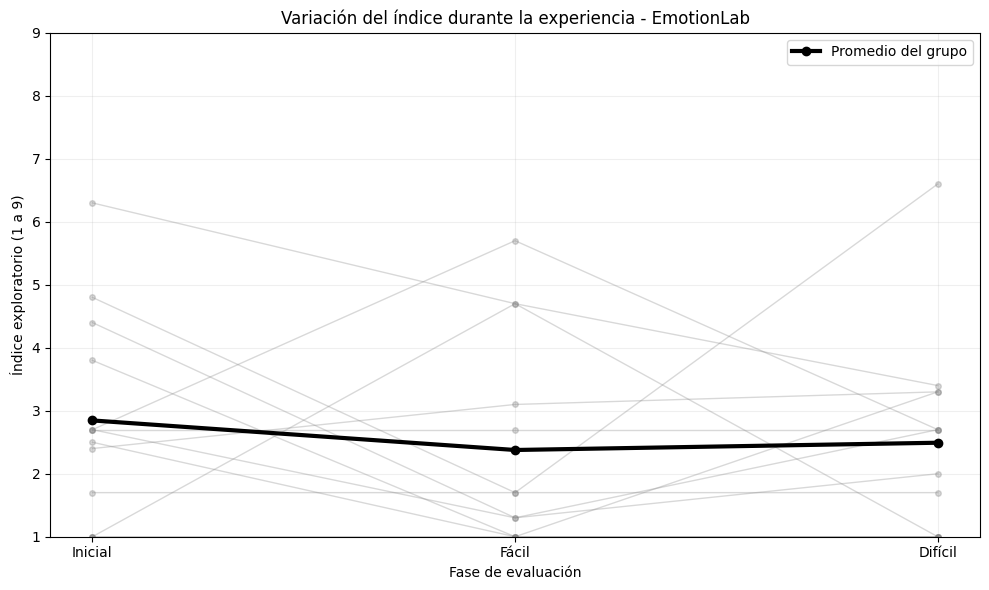

Estudiantes representados: 13
Visualización exploratoria completada.


In [960]:

# =========================================================
# 4.6.3 - VISUALIZACIÓN DEL ÍNDICE POR FASE
# =========================================================

# Generamos el gráfico solamente cuando existan
# estudiantes con los tres índices calculados.

if estudiantes_evaluables.empty:

    print("GRÁFICO PENDIENTE - EMOTIONLAB")
    print("No existen tres índices válidos por estudiante.")
    print("Primero debemos completar las verificaciones del 4.4.")

else:

    # Creamos el espacio donde mostraremos el gráfico.

    fig, ax = plt.subplots(figsize=(10, 6))

    # Convertimos los índices a una matriz numérica.
    #
    # Cada fila representa un estudiante.
    # Cada columna representa una fase.
    #
    # Al transponerla (.T), Matplotlib puede dibujar
    # una línea por estudiante sin utilizar un ciclo for.

    trayectorias = estudiantes_evaluables[
        columnas_indices
    ].to_numpy(dtype=float)

    # Representamos las trayectorias individuales.
    #
    # El gris permite mostrar las diferencias entre
    # estudiantes sin destacar a uno en particular.

    ax.plot(
        range(3),
        trayectorias.T,
        marker="o",
        markersize=4,
        color="gray",
        alpha=0.3,
        linewidth=1
    )

    # Calculamos el promedio de las tres fases
    # para los mismos estudiantes seleccionados.

    promedios = trayectorias.mean(axis=0)

    # Destacamos el promedio general en negro.

    ax.plot(
        range(3),
        promedios,
        marker="o",
        color="black",
        linewidth=3,
        label="Promedio del grupo"
    )

    # Configuramos las etiquetas y la escala.

    ax.set_xticks(range(3), etapas)
    ax.set_ylim(ESCALA_MINIMA, ESCALA_MAXIMA)
    ax.set_yticks(
        range(ESCALA_MINIMA, ESCALA_MAXIMA + 1)
    )

    ax.set_title(
        "Variación del índice durante la experiencia - EmotionLab"
    )

    ax.set_xlabel("Fase de evaluación")
    ax.set_ylabel("Índice exploratorio (1 a 9)")

    # Agregamos una cuadrícula ligera y la leyenda
    # para facilitar la interpretación visual.

    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()

    print("Estudiantes representados:", len(estudiantes_evaluables))
    print("Visualización exploratoria completada.")


## **4.7 — Análisis de sensibilidad del índice de tensión**

**¿Qué realizaremos en esta sección?**

En esta sección evaluaremos qué tan sensibles son los resultados del índice exploratorio de tensión percibida de EmotionLab frente a cambios en las ponderaciones utilizadas.

Actualmente, nuestro índice considera un 70 % de nerviosismo y un 30 % de estado emocional. Sin embargo, estas ponderaciones son experimentales, por lo que necesitamos comprobar cuánto influyen en las puntuaciones obtenidas.

**1. Configuraciones que compararemos**

Analizaremos tres escenarios utilizando las mismas respuestas de los estudiantes:

60 % / 40 %: mayor participación del estado emocional.

70 % / 30 %: configuración principal de EmotionLab.

80 % / 20 %: mayor participación del nerviosismo.

**2. Comparación de resultados**

Para cada configuración realizaremos los siguientes cálculos:

Índice por fase: calcularemos las puntuaciones de las evaluaciones inicial, fácil y difícil.

Índice global: obtendremos el promedio de las tres fases.

Diferencias: compararemos cada resultado alternativo con la configuración principal.

Sensibilidad: identificaremos el cambio absoluto promedio y la mayor diferencia registrada.

**3. ¿Por qué es importante?**

Este análisis nos permitirá identificar si los resultados son relativamente estables o si cambian considerablemente cuando modificamos las ponderaciones.

Si pequeñas variaciones en los porcentajes producen grandes diferencias, significaría que el índice depende significativamente de las decisiones experimentales que tomamos.

**4. Consideraciones metodológicas**

Trabajaremos con los 13 estudiantes evaluables, utilizando únicamente respuestas reales completas.

Mantendremos la orientación confirmada de la escala: valores mayores representan mayor tensión percibida.

No modificaremos los datos originales ni realizaremos estimaciones.

No asignaremos categorías de tensión hasta establecer y evaluar sus umbrales.

El análisis de sensibilidad no demuestra que una ponderación sea psicológicamente más válida que otra.

In [961]:

# =========================================================
# 4.7.1 - PREPARACIÓN DEL ANÁLISIS DE SENSIBILIDAD
# =========================================================

# Antes de comparar ponderaciones, comprobamos que
# la orientación emocional haya sido confirmada
# y que el índice principal ya esté calculado.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("Primero debemos validar la escala emocional.")

if type(INVERTIR_ESTADO) is not bool:
    raise ValueError("La inversión de la escala no está definida.")

# Seleccionamos únicamente estudiantes con las tres
# fases completas, sin utilizar valores estimados.

evaluables = resultados_tension["apto_indice_global"]

sensibilidad = resultados_tension.loc[
    evaluables, variables_indice
].copy()

# Guardamos el índice global original del 70/30
# para comprobar posteriormente los nuevos cálculos.

indice_referencia = resultados_tension.loc[
    evaluables, "indice_global"
]

if sensibilidad.empty or indice_referencia.isna().any():
    raise ValueError("No existen índices completos para comparar.")

if sensibilidad.isna().any().any():
    raise ValueError("Hay respuestas faltantes en los evaluables.")

print("Estudiantes seleccionados:", len(sensibilidad))


Estudiantes seleccionados: 13


In [962]:

# =========================================================
# 4.7.2 - CÁLCULO DE LOS ÍNDICES ALTERNATIVOS
# =========================================================

# Confirmamos que la orientación emocional esté validada
# antes de calcular índices con nuevas ponderaciones.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("La orientación emocional no está validada.")

# Esta función aplica las ponderaciones a cada fase
# y devuelve el promedio de las tres evaluaciones.

def calcular_indice_alternativo(datos, peso_nerviosismo):

    if not np.isfinite(peso_nerviosismo) or not 0 <= peso_nerviosismo <= 1:
        raise ValueError("La ponderación debe estar entre 0 y 1.")

    peso_estado = 1 - peso_nerviosismo
    indices = []

    for nerviosismo, estado in indicadores_por_etapa.values():

        estado_ajustado = datos[estado]

        # Invertimos la escala únicamente si la
        # configuración previamente validada lo requiere.

        if INVERTIR_ESTADO:
            estado_ajustado = (
                ESCALA_MINIMA + ESCALA_MAXIMA - estado_ajustado
            )

        # Calculamos el índice de esta fase.

        indice = (
            datos[nerviosismo] * peso_nerviosismo
            + estado_ajustado * peso_estado
        )

        indices.append(indice)

    # Obtenemos el promedio de las tres fases.
    # Cada índice debe estar disponible.

    return pd.concat(indices, axis=1).mean(
        axis=1, skipna=False
    )


# Definimos las tres ponderaciones experimentales.

escenarios = {
    "60_40": 0.60,
    "70_30": 0.70,
    "80_20": 0.80
}

# Creamos las columnas correspondientes a cada escenario.
#
# IMPORTANTE:
# Escribimos indice_ sin una barra invertida.
# Los nombres deben ser exactamente iguales
# a los utilizados en las siguientes celdas.

for nombre, peso in escenarios.items():

    sensibilidad[f"indice_{nombre}"] = (
        calcular_indice_alternativo(sensibilidad, peso)
    )

# Comprobamos que las tres columnas se hayan creado.

columnas_esperadas = [
    "indice_60_40",
    "indice_70_30",
    "indice_80_20"
]

faltantes = [
    columna for columna in columnas_esperadas
    if columna not in sensibilidad.columns
]

if faltantes:
    raise ValueError(f"No se crearon estas columnas: {faltantes}")

print("Índices alternativos calculados correctamente.")

print("\nColumnas generadas:")
print(columnas_esperadas)

print("\nVista de los resultados:")
display(sensibilidad[columnas_esperadas].head().round(2))


Índices alternativos calculados correctamente.

Columnas generadas:
['indice_60_40', 'indice_70_30', 'indice_80_20']

Vista de los resultados:


,indice_60_40,indice_70_30,indice_80_20
0,2.80,2.93,3.07
1,2.60,2.70,2.80
2,1.80,1.77,1.73
3,2.53,2.57,2.60
4,3.60,3.70,3.80


In [963]:

# =========================================================
# 4.7.3 - COMPARACIÓN ENTRE PONDERACIONES
# =========================================================

# El escenario 70/30 debe reproducir el índice global
# calculado en la Etapa 4.5.
#
# np.allclose() compara números decimales considerando
# las pequeñas diferencias de precisión matemática.

if not np.allclose(
    sensibilidad["indice_70_30"],
    indice_referencia,
    rtol=0,
    atol=1e-10
):
    raise ValueError(
        "El escenario 70/30 no coincide con el índice original."
    )

# Calculamos las diferencias respecto del 70/30.
#
# Resultado positivo: el índice alternativo aumentó.
# Resultado negativo: el índice alternativo disminuyó.
# Resultado cero: no hubo cambios.

for escenario in ["60_40", "80_20"]:

    sensibilidad[f"diferencia_{escenario}"] = (
        sensibilidad[f"indice_{escenario}"]
        - sensibilidad["indice_70_30"]
    )

# Comprobamos que todos los índices alternativos
# permanezcan dentro de la escala de EmotionLab.

columnas_escenarios = [
    f"indice_{nombre}" for nombre in escenarios
]

indices_alternativos = sensibilidad[columnas_escenarios]

if not (
    np.isfinite(indices_alternativos.to_numpy()).all()
    and indices_alternativos.ge(ESCALA_MINIMA).all().all()
    and indices_alternativos.le(ESCALA_MAXIMA).all().all()
):
    raise ValueError("Se encontraron índices alternativos inválidos.")

print("Comparación de escenarios verificada correctamente.")
print("El escenario 70/30 reproduce el índice principal.")


Comparación de escenarios verificada correctamente.
El escenario 70/30 reproduce el índice principal.


In [964]:

# =========================================================
# 4.7.4 - RESULTADOS DEL ANÁLISIS DE SENSIBILIDAD
# =========================================================

# Seleccionamos los índices y sus diferencias.
# Mostraremos identificadores temporales para
# no exponer los originales durante la presentación.

columnas_resultado = [
    "indice_60_40",
    "indice_70_30",
    "indice_80_20",
    "diferencia_60_40",
    "diferencia_80_20"
]

vista_sensibilidad = sensibilidad[columnas_resultado].round(2).copy()

# Recuperamos la posición de cada registro dentro
# del conjunto original de estudiantes reales.

posiciones = resultados_tension.index.get_indexer(
    sensibilidad.index
)

vista_sensibilidad.insert(
    0, "Registro",
    [f"Registro {i + 1:02d}" for i in posiciones]
)

print("COMPARACIÓN DE PONDERACIONES - EMOTIONLAB")
display(vista_sensibilidad.reset_index(drop=True))

# Calculamos dos medidas de sensibilidad:
#
# Cambio promedio absoluto:
# cuánto cambia generalmente el índice.
#
# Cambio máximo absoluto:
# la mayor diferencia observada en un estudiante.
#
# abs() evita que aumentos y disminuciones
# se cancelen entre sí.

resumen_sensibilidad = pd.DataFrame([
    {
        "Escenario": escenario.replace("_", "/"),
        "Cambio promedio absoluto": sensibilidad[
            f"diferencia_{escenario}"
        ].abs().mean(),
        "Cambio máximo absoluto": sensibilidad[
            f"diferencia_{escenario}"
        ].abs().max()
    }
    for escenario in ["60_40", "80_20"]
])

print("\nRESUMEN DE SENSIBILIDAD RESPECTO DEL 70/30")
display(resumen_sensibilidad.round(4))


COMPARACIÓN DE PONDERACIONES - EMOTIONLAB


,Registro,indice_60_40,indice_70_30,indice_80_20,diferencia_60_40,diferencia_80_20
0,Registro 01,2.80,2.93,3.07,-0.13,0.13
1,Registro 02,2.60,2.70,2.80,-0.10,0.10
2,Registro 03,1.80,1.77,1.73,0.03,-0.03
3,Registro 04,2.53,2.57,2.60,-0.03,0.03
4,Registro 05,3.60,3.70,3.80,-0.10,0.10
5,Registro 06,1.00,1.00,1.00,0.00,0.00
6,Registro 07,3.00,3.33,3.67,-0.33,0.33
7,Registro 08,2.20,2.23,2.27,-0.03,0.03
8,Registro 09,1.67,1.50,1.33,0.17,-0.17
9,Registro 20,1.80,1.93,2.07,-0.13,0.13



RESUMEN DE SENSIBILIDAD RESPECTO DEL 70/30


,Escenario,Cambio promedio absoluto,Cambio máximo absoluto
0,60/40,0.1051,0.3333
1,80/20,0.1051,0.3333


##**4.8 — Preparación de resultados del índice de tensión**

¿Qué realizaremos en esta sección?

En esta sección organizaremos los resultados del índice exploratorio de tensión percibida de EmotionLab en una tabla que reúna la información principal de cada estudiante.

Para ello, realizaremos tres procesos:

Organización: reuniremos los índices de las fases inicial, fácil y difícil, junto con el índice global.

Identificación: conservaremos los identificadores seudónimos y el estado de evaluación de cada estudiante.

Validación: comprobaremos que los resultados sean consistentes y que no existan clasificaciones asignadas incorrectamente.

1. Información que conservaremos

La tabla incluirá:

Identificador del estudiante: permitirá relacionar cada resultado con su registro.

Respuestas disponibles: indicará cuántos de los seis indicadores necesarios fueron respondidos.

Índices por fase: mostrarán la puntuación calculada para cada momento de la experiencia.

Índice global: representará el promedio de las tres evaluaciones.

Estado de evaluación: distinguirá a los estudiantes evaluables, pendientes de estimación y con datos insuficientes.

Categoría de tensión: quedará pendiente hasta establecer los criterios de clasificación.

2. Disponibilidad de resultados

De acuerdo con los análisis anteriores, contamos con:

13 estudiantes evaluables: tienen un índice global calculado sin estimaciones.

2 estudiantes pendientes de estimación: cuentan con dos fases completas.

12 estudiantes con datos insuficientes: no cumplen los criterios para obtener un índice global.

Los registros incompletos conservarán sus respuestas disponibles sin recibir clasificaciones globales injustificadas.

3. ¿Por qué es importante?

Esta preparación permitirá disponer de los resultados en una estructura consistente, facilitando su utilización en otras partes de EmotionLab.

También nos ayudará a evitar errores como:

Asignar categorías de tensión a estudiantes sin un índice global válido.

Confundir respuestas estimadas con respuestas realmente observadas.

Perder la correspondencia entre los resultados y sus registros originales.

4. Preparación para AWS

Guardaremos la tabla en la variable resultados_heuristicos, que servirá como referencia para futuras visualizaciones y para definir los datos que intercambiará el backend.

Sin embargo, la integración con AWS requerirá implementar y comprobar posteriormente los mecanismos de comunicación, validación y protección de la información.

**En conclusión**, esta preparación permitirá centralizar los índices de tensión percibida y sus estados de evaluación, facilitando su utilización posterior sin alterar las respuestas originales.

In [965]:

# =========================================================
# 4.8.1 - PREPARACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Reunimos las columnas necesarias para presentar
# los resultados del índice exploratorio de EmotionLab.
#
# Conservamos los índices de las tres fases, el resultado
# global y el estado de disponibilidad de cada estudiante.

columnas_resultado = [
    "id_estudiante",
    "respuestas_para_indice",
    "fases_completas",
    "estado_evaluacion",
    "indice_inicial",
    "indice_facil",
    "indice_dificil",
    "indice_global"
]

# Antes de seleccionar los datos comprobamos que
# todas las columnas estén disponibles.

faltantes = [
    columna for columna in columnas_resultado
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Creamos una copia independiente.
# No modificamos los resultados de las etapas anteriores.

resultados_heuristicos = resultados_tension[
    columnas_resultado
].copy()

# Preparamos la columna destinada a las categorías.
#
# Por ahora todas quedan pendientes porque todavía
# no tenemos umbrales de clasificación validados.
#
# Esto evita conservar categorías antiguas que
# pudieran haberse generado con criterios provisionales.

resultados_heuristicos["categoria_tension"] = pd.NA

print("Tabla de resultados heurísticos preparada.")
print("Registros conservados:", len(resultados_heuristicos))


Tabla de resultados heurísticos preparada.
Registros conservados: 27


In [966]:

# =========================================================
# 4.8.2 - VALIDACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Confirmamos que la tabla conserva la misma cantidad
# de estudiantes reales que utilizamos en el EDA.

if len(resultados_heuristicos) != len(eda_reales):
    raise ValueError("La cantidad de estudiantes no coincide.")

# Comprobamos que los identificadores sean válidos.
# La conversión temporal a texto permite detectar
# identificadores vacíos o con espacios.

ids = resultados_heuristicos["id_estudiante"].astype("string").str.strip()

if ids.isna().any() or ids.eq("").any() or ids.duplicated().any():
    raise ValueError("Existen identificadores inválidos o duplicados.")

# Solo los estudiantes clasificados como Evaluables
# deben tener un índice global en esta etapa.
#
# Los pendientes de estimación y los registros con
# datos insuficientes conservarán el resultado como NaN.

evaluables = resultados_heuristicos["estado_evaluacion"].eq("Evaluable")
con_indice = resultados_heuristicos["indice_global"].notna()

if not evaluables.equals(con_indice):
    raise ValueError(
        "Los índices globales no coinciden con "
        "los estados de evaluación."
    )

# Verificamos que el índice global corresponda al
# promedio de las tres fases, sin valores estimados.

columnas_indices = [
    "indice_inicial",
    "indice_facil",
    "indice_dificil"
]

promedio_fases = resultados_heuristicos[columnas_indices].mean(
    axis=1, skipna=False
)

if not np.allclose(
    resultados_heuristicos.loc[evaluables, "indice_global"],
    promedio_fases.loc[evaluables],
    rtol=0,
    atol=1e-10
):
    raise ValueError("Existen índices globales inconsistentes.")

# Comprobamos que todos los índices calculados
# estén dentro de la escala definida en EmotionLab.

valores = resultados_heuristicos[
    columnas_indices + ["indice_global"]
].to_numpy(dtype=float)

valores_presentes = valores[~np.isnan(valores)]

if not (
    np.isfinite(valores_presentes).all()
    and ((valores_presentes >= ESCALA_MINIMA)
         & (valores_presentes <= ESCALA_MAXIMA)).all()
):
    raise ValueError("Se encontraron índices fuera de la escala.")

print("Validación de resultados completada correctamente.")
print("Índices globales verificados:", int(con_indice.sum()))
print("Categorías de tensión: pendientes de clasificación.")


Validación de resultados completada correctamente.
Índices globales verificados: 13
Categorías de tensión: pendientes de clasificación.


In [967]:

# =========================================================
# 4.8.3 - PRESENTACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Creamos una copia para mostrar los resultados.
# Conservamos los identificadores originales en memoria,
# pero utilizamos etiquetas temporales en la presentación.

vista_heuristica = resultados_heuristicos.drop(
    columns="id_estudiante"
).copy()

vista_heuristica.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_heuristica) + 1)]
)

# Redondeamos solo la visualización.
# Los resultados almacenados mantienen su precisión.

print("RESULTADOS HEURÍSTICOS - EMOTIONLAB")
display(vista_heuristica.round(2))

# Agrupamos los estudiantes según su estado.
# reindex() mantiene las tres categorías visibles
# aunque alguna no tenga estudiantes.

resumen_heuristicos = (
    resultados_heuristicos["estado_evaluacion"]
    .value_counts()
    .reindex(
        ["Evaluable", "Pendiente de estimación", "Datos insuficientes"],
        fill_value=0
    )
)

print("\nRESUMEN DE DISPONIBILIDAD")
display(resumen_heuristicos.to_frame(name="Estudiantes"))

# Presentamos las cantidades de resultados disponibles.

print("\nRESUMEN GENERAL")
print("Registros reales:", len(resultados_heuristicos))
print("Índices globales:", resultados_heuristicos["indice_global"].notna().sum())
print("Categorías asignadas:", resultados_heuristicos["categoria_tension"].notna().sum())

print("\nTabla preparada para los siguientes análisis.")


RESULTADOS HEURÍSTICOS - EMOTIONLAB


,Registro,respuestas_para_indice,fases_completas,estado_evaluacion,indice_inicial,indice_facil,indice_dificil,indice_global,categoria_tension
0,Registro 01,6,3,Evaluable,2.4,3.1,3.3,2.93,<NA>
1,Registro 02,6,3,Evaluable,2.7,2.7,2.7,2.70,<NA>
2,Registro 03,6,3,Evaluable,1.0,1.0,3.3,1.77,<NA>
3,Registro 04,6,3,Evaluable,4.4,1.3,2.0,2.57,<NA>
4,Registro 05,6,3,Evaluable,2.7,5.7,2.7,3.70,<NA>
5,Registro 06,6,3,Evaluable,1.0,1.0,1.0,1.00,<NA>
6,Registro 07,6,3,Evaluable,1.7,1.7,6.6,3.33,<NA>
7,Registro 08,6,3,Evaluable,1.0,4.7,1.0,2.23,<NA>
8,Registro 09,6,3,Evaluable,2.5,1.0,1.0,1.50,<NA>
9,Registro 10,4,2,Pendiente de estimación,8.0,8.0,NaN,NaN,<NA>



RESUMEN DE DISPONIBILIDAD


,Estudiantes
estado_evaluacion,
Evaluable,13
Pendiente de estimación,2
Datos insuficientes,12



RESUMEN GENERAL
Registros reales: 27
Índices globales: 13
Categorías asignadas: 0

Tabla preparada para los siguientes análisis.


## Conclusión de la Etapa 4: Índice exploratorio de tensión percibida

Durante esta etapa desarrollamos e implementamos el índice exploratorio de tensión percibida de EmotionLab, con el objetivo de resumir las respuestas de nerviosismo y estado emocional registradas durante las tres fases de la experiencia.

### 1. Construcción del índice

Establecimos una fórmula experimental que combina dos indicadores:

- **Nerviosismo:** ponderación del 70 %.
- **Estado emocional:** ponderación del 30 %.
- **Escala de evaluación:** valores de 1 a 9, donde las puntuaciones mayores representan mayor tensión percibida según la orientación confirmada de los cuestionarios.

Calculamos un índice independiente para las fases inicial, fácil y difícil. Posteriormente, obtuvimos un índice global mediante el promedio de las tres evaluaciones.

### 2. Disponibilidad de información

De los **27 registros reales** recopilados, identificamos:

- **13 estudiantes evaluables:** cuentan con las seis respuestas necesarias y un índice global calculado.
- **2 estudiantes pendientes de estimación:** tienen dos fases completas.
- **12 estudiantes con datos insuficientes:** no cumplen los requisitos para calcular un índice global.

Durante esta etapa conservamos las respuestas originales y no realizamos estimaciones de valores faltantes.

### 3. Resultados de tensión percibida

Al analizar los 13 estudiantes evaluables, obtuvimos los siguientes promedios:

| Fase | Índice promedio |
|---|---:|
| Inicial | 2,85 |
| Fácil | 2,38 |
| Difícil | 2,49 |

Los resultados muestran una disminución del índice promedio durante la fase fácil y un ligero aumento durante la fase difícil.

Sin embargo, las trayectorias individuales evidencian diferencias entre estudiantes, por lo que no todos experimentaron las mismas variaciones.

Estas diferencias tampoco permiten afirmar que la dificultad de las presentaciones haya causado los cambios observados.

### 4. Análisis de sensibilidad

Comparamos tres configuraciones de ponderación: **60/40, 70/30 y 80/20**, utilizando los mismos 13 estudiantes.

Los resultados fueron:

- **Cambio promedio absoluto:** 0,1051 puntos.
- **Cambio máximo absoluto:** 0,3333 puntos.
- **Consistencia:** la configuración 70/30 reprodujo correctamente el índice original.

Estos resultados sugieren que las puntuaciones presentan una sensibilidad numérica relativamente baja frente a las modificaciones de ponderación evaluadas.

No obstante, esta estabilidad matemática no demuestra la validez psicológica de la fórmula.

### 5. Limitaciones y funcionalidades pendientes

Aunque logramos implementar el cálculo del índice, todavía existen aspectos que debemos considerar:

- **Ponderaciones experimentales:** los porcentajes utilizados no provienen de una escala psicológica validada.
- **Muestra limitada:** solamente 13 estudiantes cuentan con un índice global calculado.
- **Estimaciones pendientes:** todavía debemos evaluar cómo tratar los casos con dos fases completas.
- **Categorías de tensión:** aún no hemos establecido umbrales suficientemente justificados para clasificar los resultados en calma, tensión moderada o tensión elevada.

Es importante destacar que el índice representa una interpretación experimental de respuestas autodeclaradas y **no constituye un diagnóstico clínico de estrés**.

### 6. Resultado final y próxima etapa

La Etapa 4 permitió desarrollar un procedimiento funcional para calcular índices de tensión por fase y un resultado global, además de generar visualizaciones, comprobar la consistencia de los cálculos y analizar su sensibilidad.

También organizamos los resultados en la variable `resultados_heuristicos`, conservando los 27 registros reales y diferenciando los índices calculados de aquellos pendientes.

Con estos resultados podremos avanzar hacia la **Etapa 5: Preparación de datos para Machine Learning**, donde seleccionaremos y transformaremos las variables necesarias para aplicar posteriormente algoritmos de agrupamiento no supervisado.

**En conclusión**, logramos construir una herramienta exploratoria que resume las respuestas emocionales de los estudiantes durante una experiencia de EmotionLab, estableciendo una base técnica para los análisis posteriores y manteniendo claramente diferenciados los indicadores experimentales de las agrupaciones obtenidas mediante Machine Learning.

# Etapa 5: Entrenamiento y evaluación de Machine Learning

## Objetivo

Durante esta etapa desarrollaremos y evaluaremos modelos de **Machine Learning no supervisado** para identificar patrones de similitud entre las respuestas emocionales de los estudiantes de EmotionLab.

Utilizaremos dos indicadores: **nerviosismo y estado emocional**, registrados durante las fases inicial, fácil y difícil.

Además del entrenamiento con datos reales, estudiaremos si la incorporación controlada de registros sintéticos permite obtener agrupaciones numéricas más estables.

## 1. Datos disponibles

Nuestro dataset híbrido contiene 600 registros:

- **27 registros reales:** respuestas obtenidas de estudiantes que participaron en EmotionLab.
- **573 registros sintéticos:** datos generados artificialmente para complementar la experimentación.

De los 27 estudiantes reales, solamente **13 cuentan con los seis indicadores completos** para el entrenamiento inicial.

Los registros sintéticos podrán utilizarse como apoyo experimental, pero no se considerarán participantes independientes ni evidencia directa de generalización, esto debido a que al ser datos generados a partir de los ya existentes carecen de validez para considerarse como participantes independientes.

## 2. Algoritmos de Machine Learning

Evaluaremos tres algoritmos de aprendizaje no supervisado:

- **K-Means:** agrupa registros mediante centroides, identificando perfiles con respuestas numéricamente similares.
- **Clustering jerárquico:** construye agrupaciones progresivas según las distancias entre los perfiles.
- **Gaussian Mixture Models (GMM):** utiliza distribuciones probabilísticas para identificar componentes y estimar la pertenencia de cada registro a ellos.

Los tres modelos trabajarán con las seis respuestas emocionales, sin utilizar el índice exploratorio de tensión de la Etapa 4 como etiqueta de entrenamiento.

## 3. Estrategia de entrenamiento

Para estudiar el efecto de los datos sintéticos, desarrollaremos diferentes configuraciones.

### Modelo de referencia: datos reales

Entrenaremos los algoritmos utilizando los 13 registros reales completos.

Este modelo permitirá explorar las agrupaciones presentes en las respuestas efectivamente observadas.

### Modelos experimentales: datos híbridos

Entrenaremos configuraciones alternativas combinando los registros reales completos con datos sintéticos adecuados.

Evaluaremos tres proporciones de influencia sintética:

- **10 %:** incorporación conservadora de información sintética.
- **25 %:** incorporación intermedia.
- **50 %:** influencia equilibrada entre información real y sintética.

Estos porcentajes representarán el peso total asignado a los registros sintéticos durante el entrenamiento, no necesariamente la cantidad de registros utilizados.

Aplicaremos ponderaciones cuando el algoritmo lo permita y estudiaremos alternativas apropiadas para aquellos que no admitan pesos directamente.

**Objetivo de la comparación:** determinar si la incorporación sintética produce agrupaciones más estables, sin asumir que un mayor volumen de datos garantiza mejores resultados.

## 4. Preparación de los datos

Antes del entrenamiento realizaremos las siguientes operaciones:

- **Selección:** identificaremos las seis variables correspondientes a las tres fases.
- **Separación:** distinguiremos los registros reales de los sintéticos.
- **Validación:** revisaremos respuestas faltantes, valores fuera de escala y consistencia de los datos generados.
- **Preprocesamiento:** evaluaremos las transformaciones necesarias para los algoritmos basados en distancias.
- **Control de influencia:** estableceremos el peso de los datos sintéticos para evitar que dominen automáticamente las agrupaciones.

Los datos originales se conservarán sin modificaciones y los registros incompletos no recibirán imputaciones automáticas.

## 5. Entrenamiento y evaluación

Compararemos las configuraciones mediante:

- **Silhouette Score:** evalúa la cohesión y separación de las agrupaciones.
- **Davies-Bouldin:** mide la similitud relativa entre los grupos.
- **Estabilidad:** analiza cuánto cambian las agrupaciones ante distintas inicializaciones o pequeñas modificaciones de los datos.
- **PCA:** permite visualizar los perfiles y agrupamientos en dos dimensiones.
- **Análisis de perfiles:** describe las características numéricas de los grupos identificados.

Para mantener una comparación coherente, evaluaremos las agrupaciones sobre el mismo conjunto de perfiles reales disponibles.

También revisaremos las diferencias entre los modelos entrenados únicamente con datos reales y aquellos que incorporen información sintética.

## 6. Prevención del sobreajuste y limitaciones

Entrenar modelos con solamente 13 registros completos puede producir agrupaciones sensibles a pequeñas variaciones de los datos.

La incorporación de registros sintéticos podría ayudar a explorar configuraciones más estables, pero **no garantiza que disminuya el sobreajuste ni sustituye la recopilación de nuevos estudiantes reales**.

Consideraremos especialmente que:

- Los datos sintéticos pueden reproducir sesgos de los registros originales.
- Una mayor estabilidad matemática no demuestra necesariamente una mejor generalización.
- Si los registros sintéticos se generaron utilizando los mismos estudiantes empleados en la evaluación, los resultados no constituirán una validación independiente.
- Los grupos obtenidos no representan diagnósticos clínicos ni categorías psicológicas validadas.

Cuando resulte posible, evaluaremos procedimientos de separación por estudiante antes de generar datos sintéticos, evitando utilizar información de evaluación durante el entrenamiento.


**En conclusión**, esta etapa permitirá investigar si la incorporación controlada de información sintética aporta estabilidad al aprendizaje no supervisado, sin confundir los resultados artificiales con evidencia obtenida de nuevos participantes reales.

## 5.1 — Preparación de datos para entrenamiento real e híbrido

### ¿Qué realizaremos?

Durante esta sección prepararemos dos conjuntos de entrenamiento para comparar el comportamiento de K-Means, clustering jerárquico y Gaussian Mixture Models (GMM).

Trabajaremos con seis indicadores de nerviosismo y estado emocional correspondientes a las fases inicial, fácil y difícil.

El procedimiento contempla:

1. **Preparación de datos reales:** identificaremos los estudiantes que tienen los seis indicadores completos.
2. **Identificación de datos sintéticos:** separaremos los registros reales de los artificiales dentro del dataset híbrido.
3. **Validación:** comprobaremos que las respuestas sean numéricas, estén dentro de la escala de 1 a 9 y conserven su procedencia.
4. **Preparación de escenarios:** organizaremos las matrices de entrenamiento y las ponderaciones experimentales.

No modificaremos los cuestionarios originales ni utilizaremos las categorías heurísticas de tensión como etiquetas.

### ¿Por qué prepararemos dos estrategias?

El entrenamiento con pocos registros reales puede generar agrupaciones sensibles a pequeñas variaciones de la muestra.

Por ello, estudiaremos si incorporar datos sintéticos con una influencia controlada permite mejorar la estabilidad del agrupamiento.

La comparación será exploratoria: los registros artificiales no sustituyen la validación con nuevos estudiantes reales ni garantizan por sí mismos una reducción del sobreajuste.

In [968]:

# =========================================================
# 5.1.1 - PREPARACIÓN DE LOS DATOS REALES
# =========================================================

# Seleccionamos los seis indicadores que utilizarán
# los algoritmos de Machine Learning.

variables_ml = [
    "nerviosismo_pre",
    "estado_pre",
    "nerviosismo_facil",
    "estado_facil",
    "nerviosismo_dificil",
    "estado_dificil"
]

# Verificamos que las variables estén disponibles.

columnas_requeridas = ["id_estudiante"] + variables_ml

faltantes = [
    col for col in columnas_requeridas
    if col not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas reales: {faltantes}")

# Creamos una copia sin modificar el dataset original.

datos_reales_ml = eda_reales[columnas_requeridas].copy()

# Confirmamos que las respuestas sean numéricas.
# Los valores ausentes permanecen como NaN.

datos_reales_ml[variables_ml] = (
    datos_reales_ml[variables_ml]
    .apply(pd.to_numeric, errors="raise")
)

# Validamos la escala de 1 a 9.

valores = datos_reales_ml[variables_ml]
fuera_escala = valores.notna() & (
    valores.lt(ESCALA_MINIMA) | valores.gt(ESCALA_MAXIMA)
)

if fuera_escala.any().any():
    raise ValueError("Hay respuestas reales fuera de escala.")

# Seleccionamos los registros con las seis respuestas.

reales_completos_ml = datos_reales_ml.dropna(
    subset=variables_ml
).copy()

print("PREPARACIÓN DE DATOS REALES")
print("Participantes reales:", len(datos_reales_ml))
print("Registros completos:", len(reales_completos_ml))
print("Registros incompletos:",
      len(datos_reales_ml) - len(reales_completos_ml))

# Resumen de respuestas disponibles por variable.

display(
    datos_reales_ml[variables_ml]
    .notna()
    .sum()
    .to_frame("Respuestas disponibles")
)


PREPARACIÓN DE DATOS REALES
Participantes reales: 27
Registros completos: 13
Registros incompletos: 14


,Respuestas disponibles
nerviosismo_pre,21
estado_pre,22
nerviosismo_facil,15
estado_facil,15
nerviosismo_dificil,13
estado_dificil,13


In [969]:

# =========================================================
# 5.1.2 - IDENTIFICACIÓN DEL DATASET HÍBRIDO
# =========================================================

# Utilizamos directamente el dataset original
# de EmotionLab, evitando buscar entre las copias
# generadas durante etapas anteriores.

if "dataset" not in globals():
    raise ValueError(
        "No se encontró el dataset original. "
        "Ejecuta primero la etapa de carga de datos."
    )

if not isinstance(dataset, pd.DataFrame):
    raise TypeError("La variable dataset no es un DataFrame.")

# Creamos una copia independiente.
# Esto permite ejecutar nuevamente el apartado
# sin modificar los datos originales.

dataset_hibrido_ml = dataset.copy()

# Unificamos los nombres de las variables cuando
# procedan de la estructura de inferencia.

equivalencias_ml = {
    "inicial_nerviosismo": "nerviosismo_pre",
    "inicial_sentir_hoy": "estado_pre",
    "facil_nerviosismo_cierre": "nerviosismo_facil",
    "facil_sentir_hoy_cierre": "estado_facil",
    "dificil_nerviosismo_cierre": "nerviosismo_dificil",
    "dificil_sentir_hoy_cierre": "estado_dificil"
}

# Renombramos únicamente las columnas que existan
# y comprobamos que no se generen duplicados.

dataset_hibrido_ml.rename(
    columns=equivalencias_ml,
    inplace=True
)

if dataset_hibrido_ml.columns.duplicated().any():
    raise ValueError(
        "Se encontraron nombres de columnas duplicados."
    )

# Verificamos que las seis variables estén disponibles.

faltantes = [
    columna for columna in variables_ml
    if columna not in dataset_hibrido_ml.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables necesarias: {faltantes}"
    )

# Comprobamos la cantidad esperada de registros.

if len(dataset_hibrido_ml) != 600:
    raise ValueError(
        "El dataset no contiene los 600 registros esperados."
    )

print("DATASET HÍBRIDO IDENTIFICADO - EMOTIONLAB")
print("Variable original: dataset")
print("Registros:", len(dataset_hibrido_ml))
print("Variables de Machine Learning:", len(variables_ml))

print("\nColumnas disponibles:")
print(dataset_hibrido_ml.columns.tolist())


DATASET HÍBRIDO IDENTIFICADO - EMOTIONLAB
Variable original: dataset
Registros: 600
Variables de Machine Learning: 6

Columnas disponibles:
['id_estudiante', 'tipo_origen', 'bloque_origen', 'edad', 'genero', 'n_respuestas', 'integridad', 'alivio_dificil', 'alivio_facil', 'estado_dificil', 'estado_facil', 'estado_pre', 'nerviosismo_dificil', 'nerviosismo_facil', 'nerviosismo_pre', 'preocupacion_pre', 'preparacion_pre', 'satisfaccion_dificil', 'satisfaccion_facil', 'tipo_registro', 'id_semilla']


In [970]:

# =========================================================
# 5.1.3 - SEPARACIÓN DE DATOS REALES Y SINTÉTICOS
# =========================================================

# Posibles nombres de la columna que identifica
# la procedencia de cada registro.

columnas_origen = [
    "origen",
    "tipo_registro",
    "tipo_dato",
    "origen_dato",
    "fuente",
    "es_sintetico"
]

etiquetas_reales = {"real", "original", "observado"}
etiquetas_sinteticas = {
    "sintetico", "sintetica", "synthetic",
    "artificial", "generado", "simulado"
}

# Intentamos localizar una columna de procedencia
# con valores reconocibles.

procedencia = None

for columna in columnas_origen:

    if columna not in dataset_hibrido_ml.columns:
        continue

    serie = dataset_hibrido_ml[columna]

    if columna == "es_sintetico":
        if serie.dropna().isin([True, False, 0, 1]).all():
            procedencia = serie.map(
                {True: "sintetico", False: "real"}
            )
            if procedencia.notna().all():
                break

    etiquetas = (
        serie.astype("string")
        .str.strip()
        .str.lower()
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
    )

    if etiquetas.isin(
        etiquetas_reales | etiquetas_sinteticas
    ).all():

        procedencia = etiquetas.map(
            lambda valor: (
                "real" if valor in etiquetas_reales
                else "sintetico"
            )
        )
        break

# Si no encontramos etiquetas, comprobamos si los
# identificadores permiten reconocer los datos reales.

if procedencia is None:

    if "id_estudiante" not in dataset_hibrido_ml.columns:
        raise ValueError(
            "No existe información suficiente para "
            "distinguir datos reales y sintéticos."
        )

    ids = dataset_hibrido_ml["id_estudiante"]
    mascara_real = ids.isin(datos_reales_ml["id_estudiante"])

    if (
        mascara_real.sum() != len(datos_reales_ml)
        or not ids.is_unique
    ):
        raise ValueError(
            "Los identificadores no permiten separar "
            "con seguridad los registros."
        )

    # Verificamos que coincidan las seis respuestas
    # originales de los estudiantes identificados.

    original = datos_reales_ml.set_index(
        "id_estudiante"
    )[variables_ml].sort_index()

    encontrados = dataset_hibrido_ml.loc[
        mascara_real
    ].set_index("id_estudiante")[variables_ml].sort_index()

    encontrados = encontrados.apply(
        pd.to_numeric, errors="raise"
    )

    if not np.allclose(
        original.to_numpy(dtype=float),
        encontrados.to_numpy(dtype=float),
        equal_nan=True
    ):
        raise ValueError(
            "Las respuestas originales no coinciden "
            "con los registros del dataset híbrido."
        )

    procedencia = pd.Series(
        np.where(mascara_real, "real", "sintetico"),
        index=dataset_hibrido_ml.index
    )

# Guardamos la procedencia y comprobamos las cantidades.

dataset_hibrido_ml["origen_ml"] = procedencia

conteo_origen = (
    dataset_hibrido_ml["origen_ml"].value_counts()
)

if (
    conteo_origen.get("real", 0) != 27
    or conteo_origen.get("sintetico", 0) != 573
):
    raise ValueError(
        "La procedencia no coincide con "
        "27 registros reales y 573 sintéticos."
    )

print("PROCEDENCIA VALIDADA")
display(conteo_origen.to_frame("Registros"))


PROCEDENCIA VALIDADA


,Registros
origen_ml,
sintetico,573
real,27


In [971]:

# =========================================================
# 5.1.4 - MATRICES DE ENTRENAMIENTO
# =========================================================

# Comprobamos que las respuestas híbridas sean numéricas.
# Los valores ausentes se mantienen sin imputar.

dataset_hibrido_ml[variables_ml] = (
    dataset_hibrido_ml[variables_ml]
    .apply(pd.to_numeric, errors="raise")
)

# Validamos el intervalo permitido de 1 a 9.

valores = dataset_hibrido_ml[variables_ml]

fuera_escala = valores.notna() & (
    valores.lt(ESCALA_MINIMA) | valores.gt(ESCALA_MAXIMA)
)

if fuera_escala.any().any():
    raise ValueError("Existen respuestas híbridas fuera de escala.")

# Conservamos únicamente los perfiles completos
# para los entrenamientos iniciales.

hibridos_completos_ml = dataset_hibrido_ml.dropna(
    subset=variables_ml
).copy()

# Creamos las dos matrices de entrenamiento.

X_real_ml = reales_completos_ml[variables_ml].copy()
X_hibrido_ml = hibridos_completos_ml[variables_ml].copy()

# Identificamos qué registros son reales y sintéticos
# dentro de la matriz híbrida.

origen_hibrido_ml = hibridos_completos_ml["origen_ml"]

n_reales = int(origen_hibrido_ml.eq("real").sum())
n_sinteticos = int(origen_hibrido_ml.eq("sintetico").sum())

if n_reales != len(X_real_ml) or n_sinteticos == 0:
    raise ValueError(
        "Los registros completos no permiten "
        "preparar ambos entrenamientos."
    )

# Definimos el peso total experimental de los sintéticos.
# Cada grupo de datos reparte su influencia entre sus filas.

proporciones_sinteticas = [0.10, 0.25, 0.50]

pesos_hibridos_ml = {}

for proporcion in proporciones_sinteticas:

    nombre = f"hibrido_{int(proporcion * 100)}"

    pesos_hibridos_ml[nombre] = np.where(
        origen_hibrido_ml.eq("real"),
        (1 - proporcion) / n_reales,
        proporcion / n_sinteticos
    )

# Presentamos la preparación final.

resumen_entrenamiento = pd.DataFrame([
    {"Conjunto": "Real", "Registros completos": len(X_real_ml)},
    {"Conjunto": "Híbrido", "Registros completos": len(X_hibrido_ml)},
    {"Conjunto": "Híbrido - reales", "Registros completos": n_reales},
    {"Conjunto": "Híbrido - sintéticos", "Registros completos": n_sinteticos}
])

print("CONJUNTOS DE ENTRENAMIENTO - EMOTIONLAB")
display(resumen_entrenamiento)

print("\nEscenarios híbridos preparados:")
print(list(pesos_hibridos_ml))

print("\nPreparación del apartado 5.1 completada.")


CONJUNTOS DE ENTRENAMIENTO - EMOTIONLAB


,Conjunto,Registros completos
0,Real,13
1,Híbrido,349
2,Híbrido - reales,13
3,Híbrido - sintéticos,336



Escenarios híbridos preparados:
['hibrido_10', 'hibrido_25', 'hibrido_50']

Preparación del apartado 5.1 completada.


In [972]:

# =========================================================
# 5.1.5 - IMPUTACIÓN EXPERIMENTAL POR MEDIANA
# =========================================================

# Agrupamos las preguntas por fase y por indicador.
# Utilizaremos las respuestas del propio estudiante
# para estimar valores faltantes del mismo indicador.

fases_ml = [
    ["nerviosismo_pre", "estado_pre"],
    ["nerviosismo_facil", "estado_facil"],
    ["nerviosismo_dificil", "estado_dificil"]
]

indicadores_ml = [
    ["nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"],
    ["estado_pre", "estado_facil", "estado_dificil"]
]

def imputar_por_mediana_ml(datos):

    # Creamos una copia independiente.
    # Las respuestas originales no se modifican.

    resultado = datos.copy()
    observadas = resultado[variables_ml].notna()

    # Exigimos al menos cuatro respuestas observadas
    # y participación en dos fases diferentes.

    n_observadas = observadas.sum(axis=1)

    n_fases = sum(
        observadas[columnas].any(axis=1).astype(int)
        for columnas in fases_ml
    )

    aptos = n_observadas.ge(4) & n_fases.ge(2)

    # Calculamos la mediana de cada indicador
    # utilizando las fases respondidas por el estudiante.

    for columnas in indicadores_ml:

        medianas = resultado.loc[
            aptos, columnas
        ].median(axis=1)

        for columna in columnas:
            resultado.loc[aptos, columna] = (
                resultado.loc[aptos, columna]
                .fillna(medianas)
            )

    # Identificamos cuántos valores fueron estimados.
    # Los registros no aptos conservan sus NaN.

    resultado["n_observadas_ml"] = n_observadas
    resultado["n_imputadas_ml"] = (
        observadas.eq(False)
        & resultado[variables_ml].notna()
    ).sum(axis=1)

    resultado["apto_entrenamiento_ml"] = aptos

    # Ningún registro apto debe quedar incompleto.

    if resultado.loc[aptos, variables_ml].isna().any().any():
        raise ValueError("La imputación dejó registros incompletos.")

    return resultado


# Aplicamos el procedimiento por separado
# a los datos reales y al dataset híbrido.

datos_reales_imputados_ml = imputar_por_mediana_ml(
    datos_reales_ml
)

datos_hibridos_imputados_ml = imputar_por_mediana_ml(
    dataset_hibrido_ml
)

# Preparamos las matrices con los registros aptos.

X_real_imputado_ml = datos_reales_imputados_ml.loc[
    datos_reales_imputados_ml["apto_entrenamiento_ml"],
    variables_ml
].copy()

aptos_hibridos = datos_hibridos_imputados_ml[
    "apto_entrenamiento_ml"
]

X_hibrido_imputado_ml = datos_hibridos_imputados_ml.loc[
    aptos_hibridos, variables_ml
].copy()

origen_hibrido_imputado_ml = (
    datos_hibridos_imputados_ml.loc[
        aptos_hibridos, "origen_ml"
    ].copy()
)

print("IMPUTACIÓN POR MEDIANA - EMOTIONLAB")
print("Registros reales aptos:", len(X_real_imputado_ml))
print("Registros híbridos aptos:", len(X_hibrido_imputado_ml))

print(
    "Respuestas reales estimadas:",
    int(datos_reales_imputados_ml["n_imputadas_ml"].sum())
)

print(
    "Respuestas híbridas estimadas:",
    int(datos_hibridos_imputados_ml["n_imputadas_ml"].sum())
)


IMPUTACIÓN POR MEDIANA - EMOTIONLAB
Registros reales aptos: 15
Registros híbridos aptos: 418
Respuestas reales estimadas: 4
Respuestas híbridas estimadas: 138


## 5.2 — Preprocesamiento y transformación de datos

### ¿Qué realizaremos?

Durante esta sección prepararemos las variables que utilizarán los algoritmos K-Means, clustering jerárquico y Gaussian Mixture Models (GMM).

Trabajaremos con los 349 registros completos identificados en la sección anterior, diferenciando los 13 perfiles reales de los 336 sintéticos.

El procedimiento tendrá cuatro objetivos:

1. **Verificar la consistencia:** confirmar que los registros reales coincidan con los cuestionarios originales y revisar la procedencia de los datos sintéticos.
2. **Comparar las distribuciones:** observar posibles diferencias entre las respuestas reales y las generadas artificialmente.
3. **Estandarizar las variables:** preparar las seis características numéricas utilizando una transformación común.
4. **Comprobar las ponderaciones:** verificar que los escenarios híbridos del 10 %, 25 % y 50 % representen correctamente la influencia sintética establecida.

Utilizaremos las respuestas reales completas como referencia para ajustar la transformación, aplicando posteriormente los mismos parámetros al conjunto híbrido.

**Resultado esperado:** dos matrices de entrenamiento comparables y tres configuraciones híbridas preparadas para los experimentos posteriores.

La preparación no demuestra todavía que incorporar registros sintéticos mejore el modelo. Esa hipótesis se evaluará mediante métricas y pruebas de estabilidad durante el entrenamiento.

In [973]:

# =========================================================
# 5.2.1 - VERIFICACIÓN DE DATOS Y PROCEDENCIA
# =========================================================

# Seleccionamos los registros originales dentro
# del dataset híbrido.

reales_hibrido = dataset_hibrido_ml.loc[
    dataset_hibrido_ml["origen_ml"].eq("real")
].copy()

# Confirmamos que sus identificadores correspondan
# a los 27 participantes del dataset original.

if (
    reales_hibrido["id_estudiante"].duplicated().any()
    or set(reales_hibrido["id_estudiante"])
       != set(datos_reales_ml["id_estudiante"])
):
    raise ValueError(
        "Los identificadores reales no coinciden."
    )

# Ordenamos ambos conjuntos por identificador
# para comparar las mismas respuestas.

original = (
    datos_reales_ml
    .set_index("id_estudiante")[variables_ml]
    .sort_index()
    .to_numpy(dtype=float)
)

hibrido = (
    reales_hibrido
    .set_index("id_estudiante")[variables_ml]
    .sort_index()
    .to_numpy(dtype=float)
)

# Comparamos los valores, incluyendo las respuestas
# ausentes, sin modificar ninguno de los datasets.

if not np.allclose(
    original, hibrido,
    rtol=0, atol=1e-10,
    equal_nan=True
):
    raise ValueError(
        "Las respuestas reales no coinciden."
    )

print("Los 27 registros reales coinciden con los originales.")

# Revisamos la información de procedencia sintética.
# Esto NO demuestra independencia de los registros.

if "id_semilla" in dataset_hibrido_ml.columns:

    semillas = dataset_hibrido_ml.loc[
        dataset_hibrido_ml["origen_ml"].eq("sintetico"),
        "id_semilla"
    ]

    print("\nTRAZABILIDAD DE DATOS SINTÉTICOS")
    print("Registros con semilla:", semillas.notna().sum())
    print("Semillas diferentes:", semillas.nunique())

else:
    print("\nNo existe una columna id_semilla.")


Los 27 registros reales coinciden con los originales.

TRAZABILIDAD DE DATOS SINTÉTICOS
Registros con semilla: 573
Semillas diferentes: 22


In [974]:

# =========================================================
# 5.2.2 - COMPARACIÓN DE DISTRIBUCIONES
# =========================================================

# Separamos únicamente los 336 perfiles sintéticos
# que cuentan con las seis respuestas completas.

X_sintetico_ml = X_hibrido_ml.loc[
    origen_hibrido_ml.eq("sintetico")
].copy()

# Comparamos promedios y desviaciones estándar.
# Los resultados son descriptivos; no indican
# por sí solos cuál dataset produce mejores modelos.

comparacion_distribuciones = pd.DataFrame({
    "Media real": X_real_ml.mean(),
    "Media sintética": X_sintetico_ml.mean(),
    "Desv. real": X_real_ml.std(),
    "Desv. sintética": X_sintetico_ml.std()
})

comparacion_distribuciones["Diferencia medias"] = (
    comparacion_distribuciones["Media sintética"]
    - comparacion_distribuciones["Media real"]
)

print("COMPARACIÓN DE VARIABLES REALES Y SINTÉTICAS")
display(comparacion_distribuciones.round(2))

# Identificamos variables sin variación en los
# perfiles reales, ya que aportan poca información
# para distinguir estudiantes mediante distancias.

variables_constantes = (
    X_real_ml.columns[X_real_ml.nunique() <= 1].tolist()
)

if variables_constantes:
    print("\nVariables constantes:", variables_constantes)
else:
    print("\nLas seis variables presentan variación real.")


COMPARACIÓN DE VARIABLES REALES Y SINTÉTICAS


,Media real,Media sintética,Desv. real,Desv. sintética,Diferencia medias
nerviosismo_pre,3.08,3.44,1.89,2.09,0.36
estado_pre,2.31,2.52,1.97,2.09,0.21
nerviosismo_facil,2.54,2.73,1.85,2.16,0.19
estado_facil,2.00,2.11,1.41,1.70,0.11
nerviosismo_dificil,2.77,3.30,2.13,2.53,0.53
estado_dificil,1.85,1.92,1.07,1.09,0.08



Las seis variables presentan variación real.


In [975]:

# =========================================================
# 5.2.3 - ESTANDARIZACIÓN DE VARIABLES
# =========================================================


# Comprobamos que ambas matrices utilizan las
# mismas seis variables y el mismo orden.

if list(X_real_ml.columns) != list(X_hibrido_ml.columns):
    raise ValueError("Las variables no coinciden.")

if not X_hibrido_ml.index.equals(origen_hibrido_ml.index):
    raise ValueError("La procedencia perdió su alineación.")

# Creamos y ajustamos el escalador usando
# únicamente las observaciones reales completas.

escalador_ml = StandardScaler()
escalador_ml.fit(X_real_ml)

# Aplicamos exactamente la misma transformación
# al conjunto real y al conjunto híbrido.

X_real_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_real_ml),
    columns=variables_ml,
    index=X_real_ml.index
)

X_hibrido_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_hibrido_ml),
    columns=variables_ml,
    index=X_hibrido_ml.index
)

# Comprobamos que la transformación no produzca
# valores ausentes o infinitos.

if not (
    np.isfinite(X_real_escalado_ml.to_numpy()).all()
    and np.isfinite(X_hibrido_escalado_ml.to_numpy()).all()
):
    raise ValueError("El escalado produjo valores inválidos.")

# Guardamos los parámetros para poder aplicar
# posteriormente la misma transformación.

parametros_escalado = pd.DataFrame({
    "Media de referencia": escalador_ml.mean_,
    "Desviación de referencia": np.sqrt(escalador_ml.var_)
}, index=variables_ml)

print("ESTANDARIZACIÓN COMPLETADA")
display(parametros_escalado.round(3))

print("\nDimensiones de las matrices:")
print("Real:", X_real_escalado_ml.shape)
print("Híbrida:", X_hibrido_escalado_ml.shape)


ESTANDARIZACIÓN COMPLETADA


,Media de referencia,Desviación de referencia
nerviosismo_pre,3.077,1.817
estado_pre,2.308,1.897
nerviosismo_facil,2.538,1.781
estado_facil,2.000,1.359
nerviosismo_dificil,2.769,2.044
estado_dificil,1.846,1.026



Dimensiones de las matrices:
Real: (13, 6)
Híbrida: (349, 6)


In [976]:

# =========================================================
# 5.2.4 - VALIDACIÓN DE PONDERACIONES HÍBRIDAS
# =========================================================

# Cada escenario distribuye un peso total entre
# los registros reales y sintéticos disponibles.
#
# Los porcentajes NO representan la cantidad de filas,
# sino su influencia total dentro del entrenamiento.

escenarios_pesos = {
    "hibrido_10": 0.10,
    "hibrido_25": 0.25,
    "hibrido_50": 0.50
}

mascara_real = origen_hibrido_ml.eq("real").to_numpy()
mascara_sintetica = origen_hibrido_ml.eq("sintetico").to_numpy()

resumen_pesos_ml = []

for nombre, proporcion in escenarios_pesos.items():

    pesos = np.asarray(
        pesos_hibridos_ml[nombre], dtype=float
    )

    # Verificamos longitud y validez de los pesos.

    if (
        len(pesos) != len(X_hibrido_escalado_ml)
        or not np.isfinite(pesos).all()
        or (pesos < 0).any()
    ):
        raise ValueError(f"Pesos inválidos: {nombre}")

    peso_real = pesos[mascara_real].sum()
    peso_sintetico = pesos[mascara_sintetica].sum()

    # El peso total debe ser 1 y las proporciones
    # deben coincidir con las configuraciones previstas.

    if not (
        np.isclose(pesos.sum(), 1.0)
        and np.isclose(peso_sintetico, proporcion)
        and np.isclose(peso_real, 1 - proporcion)
    ):
        raise ValueError(f"Ponderación incorrecta: {nombre}")

    resumen_pesos_ml.append({
        "Escenario": nombre,
        "Peso real (%)": peso_real * 100,
        "Peso sintético (%)": peso_sintetico * 100,
        "Registros": len(pesos)
    })

# Presentamos los tres escenarios preparados.

resumen_pesos_ml = pd.DataFrame(resumen_pesos_ml)

print("VALIDACIÓN DE ENTRENAMIENTOS HÍBRIDOS")
display(resumen_pesos_ml.round(2))

print("\nMatrices y ponderaciones preparadas correctamente.")


VALIDACIÓN DE ENTRENAMIENTOS HÍBRIDOS


,Escenario,Peso real (%),Peso sintético (%),Registros
0,hibrido_10,90.0,10.0,349
1,hibrido_25,75.0,25.0,349
2,hibrido_50,50.0,50.0,349



Matrices y ponderaciones preparadas correctamente.


In [977]:

# =========================================================
# 5.2.5 - ESCALADO DE REGISTROS IMPUTADOS
# =========================================================

# Aplicamos el mismo escalador del apartado 5.2.3.
# No volvemos a ajustarlo utilizando datos sintéticos.

X_real_imputado_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_real_imputado_ml),
    columns=variables_ml,
    index=X_real_imputado_ml.index
)

X_hibrido_imputado_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_hibrido_imputado_ml),
    columns=variables_ml,
    index=X_hibrido_imputado_ml.index
)

# Comprobamos que los resultados sean válidos
# y no contengan respuestas faltantes.

for nombre, matriz in {
    "Real imputado": X_real_imputado_escalado_ml,
    "Híbrido imputado": X_hibrido_imputado_escalado_ml
}.items():

    if not np.isfinite(matriz.to_numpy()).all():
        raise ValueError(f"Valores inválidos en {nombre}")

print("ESCALADO DE DATOS IMPUTADOS")
print("Real:", X_real_imputado_escalado_ml.shape)
print("Híbrido:", X_hibrido_imputado_escalado_ml.shape)

print("\nTransformación completada correctamente.")


ESCALADO DE DATOS IMPUTADOS
Real: (15, 6)
Híbrido: (418, 6)

Transformación completada correctamente.


In [978]:

# =========================================================
# 5.2.6 - PONDERACIONES HÍBRIDAS CON IMPUTACIÓN
# =========================================================

# Comprobamos que los datos imputados y su procedencia
# estén disponibles antes de calcular las ponderaciones.

if "origen_hibrido_imputado_ml" not in globals():
    raise ValueError(
        "Falta la procedencia de los registros imputados. "
        "Ejecuta nuevamente el apartado 5.1.5."
    )

# Aseguramos que cada registro tenga una etiqueta
# de procedencia y que el orden coincida con la matriz.

origen = origen_hibrido_imputado_ml.reindex(
    X_hibrido_imputado_escalado_ml.index
)

if origen.isna().any():
    raise ValueError("Existen registros sin procedencia.")

# Contamos registros reales y sintéticos.

mascara_real = origen.eq("real").to_numpy()
mascara_sintetica = origen.eq("sintetico").to_numpy()

if not (mascara_real | mascara_sintetica).all():
    raise ValueError("Existen procedencias desconocidas.")

n_reales = int(mascara_real.sum())
n_sinteticos = int(mascara_sintetica.sum())

if n_reales == 0 or n_sinteticos == 0:
    raise ValueError("Faltan registros reales o sintéticos.")

# Creamos el diccionario que necesita el apartado 5.4.
# Cada escenario tendrá su propio vector de pesos.

pesos_hibridos_imputados_ml = {}
resumen_pesos_imputados = []

for porcentaje in [10, 25, 50]:

    proporcion = porcentaje / 100
    escenario = f"hibrido_{porcentaje}"

    pesos = np.where(
        mascara_real,
        (1 - proporcion) / n_reales,
        proporcion / n_sinteticos
    )

    # Verificamos que los pesos sean válidos
    # y representen las proporciones esperadas.

    if not (
        np.isfinite(pesos).all()
        and np.isclose(pesos.sum(), 1)
        and np.isclose(pesos[mascara_sintetica].sum(), proporcion)
    ):
        raise ValueError(f"Pesos inválidos: {escenario}")

    pesos_hibridos_imputados_ml[escenario] = pesos

    resumen_pesos_imputados.append({
        "Escenario": escenario,
        "Registros reales": n_reales,
        "Registros sintéticos": n_sinteticos,
        "Peso real (%)": pesos[mascara_real].sum() * 100,
        "Peso sintético (%)": pesos[mascara_sintetica].sum() * 100
    })

# Presentamos los escenarios correctamente generados.

resumen_pesos_imputados = pd.DataFrame(
    resumen_pesos_imputados
)

print("PONDERACIONES HÍBRIDAS CON IMPUTACIÓN")
display(resumen_pesos_imputados.round(2))

print("\nEscenarios disponibles:")
print(list(pesos_hibridos_imputados_ml))

print("\nPreparación completada correctamente.")


PONDERACIONES HÍBRIDAS CON IMPUTACIÓN


,Escenario,Registros reales,Registros sintéticos,Peso real (%),Peso sintético (%)
0,hibrido_10,15,403,90.0,10.0
1,hibrido_25,15,403,75.0,25.0
2,hibrido_50,15,403,50.0,50.0



Escenarios disponibles:
['hibrido_10', 'hibrido_25', 'hibrido_50']

Preparación completada correctamente.


## 5.3 — Entrenamiento experimental de K-Means

### ¿Qué realizaremos?

Durante esta sección entrenaremos el algoritmo K-Means utilizando las matrices estandarizadas que preparamos anteriormente.

Compararemos dos estrategias principales:

- **Entrenamiento real:** utilizará los 13 estudiantes con los seis indicadores completos.
- **Entrenamiento híbrido:** utilizará los 349 perfiles completos, controlando la influencia total de los registros sintéticos mediante ponderaciones del 10 %, 25 % y 50 %.

### Metodología

El procedimiento incluirá cuatro actividades:

1. **Entrenamiento:** probaremos configuraciones de 2, 3 y 4 grupos.
2. **Evaluación:** calcularemos métricas de cohesión y separación sobre los mismos 13 perfiles reales.
3. **Estabilidad:** comprobaremos cuánto cambian las agrupaciones al utilizar distintas inicializaciones del algoritmo.
4. **Comparación:** estudiaremos las diferencias entre las configuraciones reales e híbridas.

### ¿Qué buscamos determinar?

Investigaremos si la incorporación controlada de datos sintéticos produce agrupaciones con mejores métricas y mayor estabilidad que el entrenamiento realizado únicamente con respuestas reales.

Los resultados serán exploratorios y no permitirán afirmar todavía que el modelo generaliza mejor a estudiantes nuevos, especialmente porque los registros sintéticos proceden de una muestra real reducida.

El modelo seleccionado posteriormente deberá justificarse mediante el conjunto de resultados y sus limitaciones, no solamente por obtener la puntuación Silhouette más alta.

In [979]:

# =========================================================
# 5.3.1 - ENTRENAMIENTO EXPERIMENTAL DE K-MEANS
# =========================================================


# Definimos las cantidades de grupos que exploraremos.
# Probamos pocos grupos debido a que contamos con
# solamente 13 estudiantes reales completos.

cantidades_grupos = [2, 3, 4]

# Preparamos las cuatro configuraciones de entrenamiento.
#
# Real: utiliza solamente 13 estudiantes.
# Híbridos: utilizan 349 perfiles con pesos controlados.

configuraciones_kmeans = {
    "real": {
        "X": X_real_escalado_ml,
        "pesos": None
    }
}

for escenario in ["hibrido_10", "hibrido_25", "hibrido_50"]:

    configuraciones_kmeans[escenario] = {
        "X": X_hibrido_escalado_ml,
        "pesos": pesos_hibridos_ml[escenario]
    }

# Guardaremos los modelos y sus predicciones sobre
# los mismos 13 estudiantes reales.

modelos_kmeans = {}
predicciones_kmeans = {}

for escenario, configuracion in configuraciones_kmeans.items():

    for k in cantidades_grupos:

        modelo = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            max_iter=300,
            random_state=42
        )

        # Entrenamos utilizando los datos y pesos
        # correspondientes a cada configuración.

        modelo.fit(
            configuracion["X"],
            sample_weight=configuracion["pesos"]
        )

        clave = (escenario, k)

        modelos_kmeans[clave] = modelo

        # Todos los modelos se evalúan sobre las
        # mismas 13 respuestas reales completas.

        predicciones_kmeans[clave] = modelo.predict(
            X_real_escalado_ml
        )

print("ENTRENAMIENTO K-MEANS - EMOTIONLAB")
print("Configuraciones:", len(configuraciones_kmeans))
print("Cantidades de grupos:", cantidades_grupos)
print("Modelos entrenados:", len(modelos_kmeans))
print("Perfiles utilizados para comparar:", len(X_real_escalado_ml))


ENTRENAMIENTO K-MEANS - EMOTIONLAB
Configuraciones: 4
Cantidades de grupos: [2, 3, 4]
Modelos entrenados: 12
Perfiles utilizados para comparar: 13


In [980]:

# =========================================================
# 5.3.2 - EVALUACIÓN DE AGRUPAMIENTOS K-MEANS
# =========================================================


resultados_evaluacion_kmeans = []

# Utilizamos siempre las mismas respuestas reales,
# independientemente del conjunto de entrenamiento.

X_evaluacion = X_real_escalado_ml.to_numpy()

for (escenario, k), modelo in modelos_kmeans.items():

    etiquetas = predicciones_kmeans[(escenario, k)]

    # Contamos los estudiantes reales asignados
    # a cada grupo.

    grupos, cantidades = np.unique(
        etiquetas, return_counts=True
    )

    n_grupos = len(grupos)
    menor_grupo = int(cantidades.min())

    # Algunas configuraciones híbridas podrían
    # generar grupos sin estudiantes reales.
    # Por eso validamos las métricas antes de calcularlas.

    silhouette = np.nan
    davies_bouldin = np.nan

    if 2 <= n_grupos < len(X_evaluacion):

        silhouette = silhouette_score(
            X_evaluacion, etiquetas
        )

        davies_bouldin = davies_bouldin_score(
            X_evaluacion, etiquetas
        )

    resultados_evaluacion_kmeans.append({
        "Escenario": escenario,
        "k": k,
        "Grupos en reales": n_grupos,
        "Menor grupo": menor_grupo,
        "Silhouette real": silhouette,
        "Davies-Bouldin real": davies_bouldin
    })

# Organizamos los resultados para comparar.

resultados_kmeans = pd.DataFrame(
    resultados_evaluacion_kmeans
)

print("EVALUACIÓN DE K-MEANS SOBRE 13 ESTUDIANTES REALES")
display(resultados_kmeans.round(3))


EVALUACIÓN DE K-MEANS SOBRE 13 ESTUDIANTES REALES


,Escenario,k,Grupos en reales,Menor grupo,Silhouette real,Davies-Bouldin real
0,real,2,2,3,0.275,1.227
1,real,3,3,3,0.235,1.309
2,real,4,4,1,0.267,0.859
3,hibrido_10,2,2,3,0.275,1.227
4,hibrido_10,3,3,3,0.235,1.309
5,hibrido_10,4,4,2,0.211,1.135
6,hibrido_25,2,2,3,0.275,1.227
7,hibrido_25,3,3,1,0.264,0.945
8,hibrido_25,4,4,1,0.267,0.859
9,hibrido_50,2,2,3,0.275,1.227


In [981]:

# =========================================================
# 5.3.3 - ESTABILIDAD DE K-MEANS
# =========================================================


# Repetimos el entrenamiento con distintas
# semillas de inicialización para cada escenario.

semillas_kmeans = [11, 21, 31, 41, 51]

resultados_estabilidad = []

for escenario, configuracion in configuraciones_kmeans.items():

    for k in cantidades_grupos:

        predicciones_repetidas = []

        for semilla in semillas_kmeans:

            modelo = KMeans(
                n_clusters=k,
                init="k-means++",
                n_init=10,
                max_iter=300,
                random_state=semilla
            )

            modelo.fit(
                configuracion["X"],
                sample_weight=configuracion["pesos"]
            )

            # Evaluamos cada repetición sobre
            # los mismos estudiantes reales.

            predicciones_repetidas.append(
                modelo.predict(X_real_escalado_ml)
            )

        # Comparamos todas las parejas de repeticiones.
        # ARI = 1 significa asignaciones equivalentes,
        # aunque cambien los números de los grupos.

        valores_ari = [
            adjusted_rand_score(
                predicciones_repetidas[i],
                predicciones_repetidas[j]
            )
            for i, j in combinations(
                range(len(predicciones_repetidas)), 2
            )
        ]

        resultados_estabilidad.append({
            "Escenario": escenario,
            "k": k,
            "ARI promedio": np.mean(valores_ari),
            "ARI mínimo": np.min(valores_ari)
        })

# Presentamos las métricas de estabilidad.

estabilidad_kmeans = pd.DataFrame(
    resultados_estabilidad
)

print("ESTABILIDAD ANTE INICIALIZACIONES - K-MEANS")
display(estabilidad_kmeans.round(3))


ESTABILIDAD ANTE INICIALIZACIONES - K-MEANS


,Escenario,k,ARI promedio,ARI mínimo
0,real,2,1.000,1.000
1,real,3,0.691,0.462
2,real,4,0.902,0.754
3,hibrido_10,2,1.000,1.000
4,hibrido_10,3,0.902,0.756
5,hibrido_10,4,0.849,0.748
6,hibrido_25,2,1.000,1.000
7,hibrido_25,3,1.000,1.000
8,hibrido_25,4,1.000,1.000
9,hibrido_50,2,1.000,1.000


COMPARACIÓN EXPERIMENTAL - K-MEANS


,Escenario,k,Grupos en reales,Menor grupo,Silhouette real,Davies-Bouldin real,ARI promedio,ARI mínimo,ARI vs real,Diferencia Silhouette
0,real,2,2,3,0.275,1.227,1.000,1.000,1.000,0.000
1,real,3,3,3,0.235,1.309,0.691,0.462,1.000,0.000
2,real,4,4,1,0.267,0.859,0.902,0.754,1.000,0.000
3,hibrido_10,2,2,3,0.275,1.227,1.000,1.000,1.000,0.000
4,hibrido_10,3,3,3,0.235,1.309,0.902,0.756,1.000,0.000
5,hibrido_10,4,4,2,0.211,1.135,0.849,0.748,0.534,-0.056
6,hibrido_25,2,2,3,0.275,1.227,1.000,1.000,1.000,0.000
7,hibrido_25,3,3,1,0.264,0.945,1.000,1.000,0.590,0.029
8,hibrido_25,4,4,1,0.267,0.859,1.000,1.000,1.000,0.000
9,hibrido_50,2,2,3,0.275,1.227,1.000,1.000,1.000,0.000


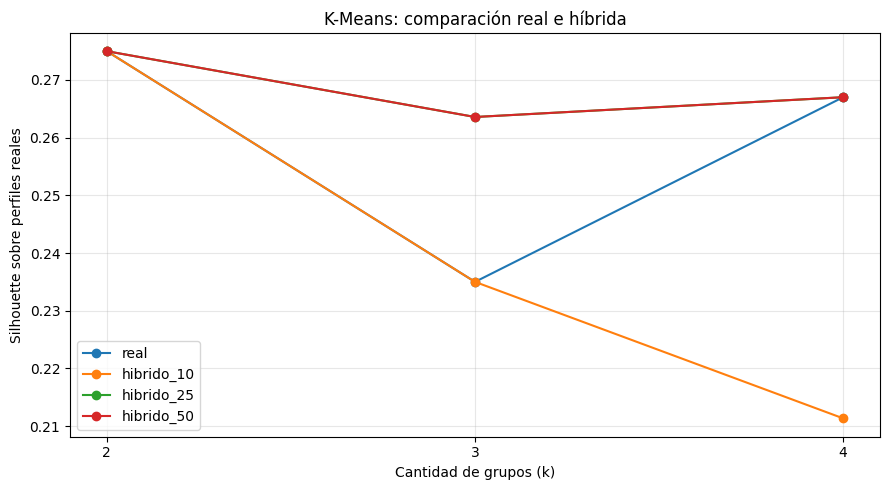

Comparación experimental de K-Means completada.
La selección definitiva requiere revisar
calidad, estabilidad y dependencia sintética.


In [982]:

# =========================================================
# 5.3.4 - COMPARACIÓN FINAL DE K-MEANS
# =========================================================


# Unimos las métricas de calidad y estabilidad.

comparacion_kmeans = resultados_kmeans.merge(
    estabilidad_kmeans,
    on=["Escenario", "k"],
    validate="one_to_one"
)

# Incorporamos el acuerdo con el modelo real
# de referencia para la misma cantidad de grupos.
#
# Esta medida indica semejanza entre asignaciones,
# no superioridad de un modelo sobre otro.

comparacion_kmeans["ARI vs real"] = [
    adjusted_rand_score(
        predicciones_kmeans[("real", k)],
        predicciones_kmeans[(escenario, k)]
    )
    for escenario, k in zip(
        comparacion_kmeans["Escenario"],
        comparacion_kmeans["k"]
    )
]

# Calculamos la diferencia de Silhouette respecto
# al modelo entrenado únicamente con datos reales.

silhouette_referencia = (
    comparacion_kmeans
    .query("Escenario == 'real'")
    .set_index("k")["Silhouette real"]
)

comparacion_kmeans["Diferencia Silhouette"] = (
    comparacion_kmeans["Silhouette real"]
    - comparacion_kmeans["k"].map(silhouette_referencia)
)

print("COMPARACIÓN EXPERIMENTAL - K-MEANS")
display(comparacion_kmeans.round(3))

# Visualizamos los resultados sobre los mismos
# 13 perfiles reales, usando un color por escenario.

plt.figure(figsize=(9, 5))

for escenario in configuraciones_kmeans:

    datos = comparacion_kmeans.loc[
        comparacion_kmeans["Escenario"].eq(escenario)
    ].sort_values("k")

    plt.plot(
        datos["k"],
        datos["Silhouette real"],
        marker="o",
        label=escenario
    )

plt.title("K-Means: comparación real e híbrida")
plt.xlabel("Cantidad de grupos (k)")
plt.ylabel("Silhouette sobre perfiles reales")
plt.xticks(cantidades_grupos)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Comparación experimental de K-Means completada.")
print("La selección definitiva requiere revisar")
print("calidad, estabilidad y dependencia sintética.")


### 5.3 — Resultados del entrenamiento experimental de K-Means

Durante esta sección entrenamos 12 configuraciones experimentales de K-Means, comparando datos reales y datos híbridos con influencias sintéticas del 10 %, 25 % y 50 %.

**Principales resultados:**

- **Dos grupos:** todas las estrategias obtuvieron Silhouette de 0,275 y estabilidad ARI de 1,000, sin diferencias en las asignaciones sobre los estudiantes reales.
- **Tres grupos:** las configuraciones híbridas del 25 % y 50 % aumentaron Silhouette de 0,235 a 0,264 y alcanzaron estabilidad de 1,000, aunque generaron un grupo con un único estudiante.
- **Cuatro grupos:** varias configuraciones presentaron grupos demasiado pequeños para obtener interpretaciones sólidas.

Los resultados muestran que incorporar registros sintéticos puede modificar la estabilidad y distribución de los agrupamientos, pero no produjo una mejora consistente en todas las configuraciones.

**Conclusión:** K-Means con dos grupos se considera una alternativa preliminar por su consistencia y ausencia de grupos unitarios. Sin embargo, las puntuaciones de separación son relativamente bajas y todavía no contamos con evidencia suficiente para afirmar que el entrenamiento híbrido reduzca el sobreajuste o generalice mejor a estudiantes nuevos.

La selección definitiva permanecerá pendiente hasta comparar los otros algoritmos y evaluar el efecto de la imputación por mediana.

## 5.4 — Evaluación de K-Means con imputación por mediana

### ¿Qué realizaremos?

Durante esta sección estudiaremos cómo influye la imputación por mediana en los modelos de K-Means entrenados anteriormente.

En la Etapa 5.3 utilizamos 13 perfiles reales completos y 336 sintéticos completos. Ahora incorporaremos los registros adicionales que cumplen los criterios de estimación definidos en la Etapa 5.1.

El procedimiento comprenderá cuatro actividades:

1. **Validación:** comprobar que los registros imputados conservan las respuestas originales.
2. **Evaluación de la mediana:** ocultar temporalmente respuestas conocidas y comparar sus valores reales con los estimados.
3. **Entrenamiento:** repetir los experimentos de K-Means con conjuntos reales e híbridos imputados.
4. **Comparación:** analizar las diferencias en calidad y estabilidad respecto de los modelos de la Etapa 5.3.

### ¿Por qué realizaremos esta prueba?

La imputación permitirá incorporar información parcialmente incompleta, pero los valores estimados pueden modificar las relaciones entre estudiantes y, por consiguiente, las agrupaciones.

Nuestro objetivo será determinar si esta técnica aporta información útil sin introducir alteraciones excesivas.

Los resultados se interpretarán de manera exploratoria. La imputación no convierte las respuestas faltantes en observaciones reales ni garantiza una mejora del modelo.

In [983]:

# =========================================================
# 5.4.1 - VALIDACIÓN DE DATOS IMPUTADOS
# =========================================================

# Verificamos que las matrices imputadas estén disponibles.

if (
    "X_real_imputado_ml" not in globals()
    or "X_hibrido_imputado_ml" not in globals()
    or "X_real_imputado_escalado_ml" not in globals()
    or "X_hibrido_imputado_escalado_ml" not in globals()
    or "pesos_hibridos_imputados_ml" not in globals()
):
    raise ValueError(
        "Ejecuta primero las celdas 5.1.5, 5.2.5 y 5.2.6."
    )

# Comprobamos que los 13 perfiles reales originales
# permanezcan exactamente iguales después de imputar.

originales = X_real_ml[variables_ml]

conservados = X_real_imputado_ml.loc[
    originales.index, variables_ml
]

if not np.allclose(
    originales.to_numpy(),
    conservados.to_numpy(),
    rtol=0,
    atol=1e-10
):
    raise ValueError(
        "La imputación modificó respuestas observadas."
    )

# Identificamos los perfiles adicionales incorporados.

nuevos_reales = X_real_imputado_ml.index.difference(
    X_real_ml.index
)

# Comprobamos que ambas matrices estén completas.

for nombre, matriz in {
    "Real": X_real_imputado_ml,
    "Híbrido": X_hibrido_imputado_ml
}.items():

    if matriz[variables_ml].isna().any().any():
        raise ValueError(
            f"Hay respuestas faltantes en {nombre}."
        )

print("VALIDACIÓN DE IMPUTACIÓN - EMOTIONLAB")
print("Reales completos originales:", len(X_real_ml))
print("Reales adicionales imputados:", len(nuevos_reales))
print("Total reales aptos:", len(X_real_imputado_ml))
print("Total híbridos aptos:", len(X_hibrido_imputado_ml))

print("\nLas respuestas originales fueron conservadas.")


VALIDACIÓN DE IMPUTACIÓN - EMOTIONLAB
Reales completos originales: 13
Reales adicionales imputados: 2
Total reales aptos: 15
Total híbridos aptos: 418

Las respuestas originales fueron conservadas.


In [984]:

# =========================================================
# 5.4.2 - EVALUACIÓN DEL ERROR DE IMPUTACIÓN
# =========================================================

# Simulamos respuestas faltantes utilizando los
# 13 estudiantes que sí respondieron todo.
#
# Como conocemos sus respuestas originales,
# podemos medir el error de la estimación.

pruebas_mediana = []

situaciones = {
    "Pregunta individual": [[v] for v in variables_ml],
    "Formulario completo": fases_ml
}

for tipo, grupos_variables in situaciones.items():

    for idx in X_real_ml.index:

        original = X_real_ml.loc[[idx]].copy()

        for columnas_ocultas in grupos_variables:

            # Ocultamos temporalmente las respuestas.
            # El registro original permanece intacto.

            simulado = original.copy()
            simulado.loc[idx, columnas_ocultas] = np.nan

            # Aplicamos nuestra función de imputación.

            estimado = imputar_por_mediana_ml(simulado)

            if not estimado.loc[idx, "apto_entrenamiento_ml"]:
                raise ValueError(
                    "Un caso de prueba no resultó apto."
                )

            # Comparamos cada respuesta estimada
            # con el valor real que habíamos ocultado.

            for variable in columnas_ocultas:

                valor_real = float(original.loc[idx, variable])
                valor_estimado = float(estimado.loc[idx, variable])

                pruebas_mediana.append({
                    "Tipo": tipo,
                    "Variable": variable,
                    "Valor real": valor_real,
                    "Valor estimado": valor_estimado,
                    "Error absoluto": abs(
                        valor_real - valor_estimado
                    )
                })

# Calculamos los errores del procedimiento.

evaluacion_mediana_ml = pd.DataFrame(pruebas_mediana)

resumen_mediana_ml = (
    evaluacion_mediana_ml
    .groupby("Tipo")
    .agg(
        Comparaciones=("Error absoluto", "size"),
        MAE=("Error absoluto", "mean"),
        Error_maximo=("Error absoluto", "max")
    )
    .reset_index()
)

print("EVALUACIÓN DE IMPUTACIÓN POR MEDIANA")
display(resumen_mediana_ml.round(3))

print("\nError promedio por variable:")
display(
    evaluacion_mediana_ml
    .groupby("Variable")["Error absoluto"]
    .mean()
    .to_frame("MAE")
    .round(3)
)


EVALUACIÓN DE IMPUTACIÓN POR MEDIANA


,Tipo,Comparaciones,MAE,Error_maximo
0,Formulario completo,78,1.41,7.0
1,Pregunta individual,78,1.41,7.0



Error promedio por variable:


,MAE
Variable,
estado_dificil,1.231
estado_facil,1.000
estado_pre,1.308
nerviosismo_dificil,1.577
nerviosismo_facil,1.615
nerviosismo_pre,1.731


In [985]:

# =========================================================
# 5.4.3 - ENTRENAMIENTO DE K-MEANS CON IMPUTACIÓN
# =========================================================


# Definimos las matrices y los pesos correspondientes
# a los nuevos conjuntos de entrenamiento.

configuraciones_imputadas = {
    "real": {
        "X": X_real_imputado_escalado_ml,
        "pesos": None
    }
}

for escenario in ["hibrido_10", "hibrido_25", "hibrido_50"]:

    configuraciones_imputadas[escenario] = {
        "X": X_hibrido_imputado_escalado_ml,
        "pesos": pesos_hibridos_imputados_ml[escenario]
    }

# Guardamos los modelos y sus resultados.

modelos_kmeans_imputados = {}
predicciones_kmeans_imputados = {}
resultados_imputados = []

# Utilizamos exactamente los mismos 13 estudiantes
# para comparar con los resultados del apartado 5.3.

X_evaluacion = X_real_escalado_ml

for escenario, configuracion in configuraciones_imputadas.items():

    for k in [2, 3, 4]:

        modelo = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            max_iter=300,
            random_state=42
        )

        modelo.fit(
            configuracion["X"],
            sample_weight=configuracion["pesos"]
        )

        clave = (escenario, k)

        modelos_kmeans_imputados[clave] = modelo

        etiquetas = modelo.predict(X_evaluacion)
        predicciones_kmeans_imputados[clave] = etiquetas

        # Contamos los grupos presentes en los
        # 13 estudiantes reales de evaluación.

        grupos, cantidades = np.unique(
            etiquetas, return_counts=True
        )

        silhouette = np.nan
        davies = np.nan

        if 2 <= len(grupos) < len(X_evaluacion):

            silhouette = silhouette_score(
                X_evaluacion, etiquetas
            )

            davies = davies_bouldin_score(
                X_evaluacion, etiquetas
            )

        # Medimos cuánto cambiaron las agrupaciones
        # respecto de los modelos originales del 5.3.

        ari_original = adjusted_rand_score(
            predicciones_kmeans[clave],
            etiquetas
        )

        resultados_imputados.append({
            "Escenario": escenario,
            "k": k,
            "Registros entrenamiento": len(
                configuracion["X"]
            ),
            "Grupos reales": len(grupos),
            "Menor grupo": int(cantidades.min()),
            "Silhouette": silhouette,
            "Davies-Bouldin": davies,
            "ARI vs 5.3": ari_original
        })

evaluacion_kmeans_imputados = pd.DataFrame(
    resultados_imputados
)

print("K-MEANS CON IMPUTACIÓN - EMOTIONLAB")
display(evaluacion_kmeans_imputados.round(3))


K-MEANS CON IMPUTACIÓN - EMOTIONLAB


,Escenario,k,Registros entrenamiento,Grupos reales,Menor grupo,Silhouette,Davies-Bouldin,ARI vs 5.3
0,real,2,15,1,13,NaN,NaN,0.000
1,real,3,15,2,3,0.275,1.227,0.497
2,real,4,15,3,2,0.242,1.106,0.808
3,hibrido_10,2,418,1,13,NaN,NaN,0.000
4,hibrido_10,3,418,2,3,0.275,1.227,0.497
5,hibrido_10,4,418,3,2,0.242,1.106,0.663
6,hibrido_25,2,418,1,13,NaN,NaN,0.000
7,hibrido_25,3,418,2,3,0.275,1.227,0.769
8,hibrido_25,4,418,3,1,0.264,0.945,0.641
9,hibrido_50,2,418,1,13,NaN,NaN,0.000


In [986]:

# =========================================================
# 5.4.4 - COMPARACIÓN FINAL CON Y SIN IMPUTACIÓN
# =========================================================


# Evaluamos estabilidad ante cinco inicializaciones.

semillas = [11, 21, 31, 41, 51]

estabilidad_imputados = []

for escenario, configuracion in configuraciones_imputadas.items():

    for k in [2, 3, 4]:

        predicciones = []

        for semilla in semillas:

            modelo = KMeans(
                n_clusters=k,
                init="k-means++",
                n_init=10,
                max_iter=300,
                random_state=semilla
            )

            modelo.fit(
                configuracion["X"],
                sample_weight=configuracion["pesos"]
            )

            predicciones.append(
                modelo.predict(X_real_escalado_ml)
            )

        # Comparamos todas las parejas de ejecuciones.

        valores_ari = [
            adjusted_rand_score(
                predicciones[i],
                predicciones[j]
            )
            for i, j in combinations(
                range(len(predicciones)), 2
            )
        ]

        estabilidad_imputados.append({
            "Escenario": escenario,
            "k": k,
            "ARI estabilidad imputado": np.mean(valores_ari)
        })

estabilidad_imputados = pd.DataFrame(
    estabilidad_imputados
)

# Recuperamos los resultados originales del 5.3.

referencia_53 = comparacion_kmeans[
    ["Escenario", "k", "Silhouette real", "ARI promedio"]
].rename(columns={
    "Silhouette real": "Silhouette original",
    "ARI promedio": "ARI estabilidad original"
})

# Reunimos las métricas para comparar ambos métodos.

comparacion_54 = (
    evaluacion_kmeans_imputados
    .merge(
        estabilidad_imputados,
        on=["Escenario", "k"]
    )
    .merge(
        referencia_53,
        on=["Escenario", "k"]
    )
)

comparacion_54["Cambio Silhouette"] = (
    comparacion_54["Silhouette"]
    - comparacion_54["Silhouette original"]
)

comparacion_54["Cambio estabilidad"] = (
    comparacion_54["ARI estabilidad imputado"]
    - comparacion_54["ARI estabilidad original"]
)

print("COMPARACIÓN K-MEANS: ORIGINAL VS IMPUTADO")

display(
    comparacion_54[[
        "Escenario",
        "k",
        "Registros entrenamiento",
        "Menor grupo",
        "Silhouette original",
        "Silhouette",
        "Cambio Silhouette",
        "ARI estabilidad original",
        "ARI estabilidad imputado",
        "Cambio estabilidad",
        "ARI vs 5.3"
    ]].round(3)
)

print("\nEvaluación experimental completada.")


COMPARACIÓN K-MEANS: ORIGINAL VS IMPUTADO


,Escenario,k,Registros entrenamiento,Menor grupo,Silhouette original,Silhouette,Cambio Silhouette,ARI estabilidad original,ARI estabilidad imputado,Cambio estabilidad,ARI vs 5.3
0,real,2,15,13,0.275,NaN,NaN,1.000,1.000,0.000,0.000
1,real,3,15,3,0.235,0.275,0.040,0.691,1.000,0.309,0.497
2,real,4,15,2,0.267,0.242,-0.025,0.902,0.634,-0.267,0.808
3,hibrido_10,2,418,13,0.275,NaN,NaN,1.000,1.000,0.000,0.000
4,hibrido_10,3,418,3,0.235,0.275,0.040,0.902,1.000,0.098,0.497
5,hibrido_10,4,418,2,0.211,0.242,0.030,0.849,0.677,-0.172,0.663
6,hibrido_25,2,418,13,0.275,NaN,NaN,1.000,1.000,0.000,0.000
7,hibrido_25,3,418,3,0.264,0.275,0.011,1.000,1.000,0.000,0.769
8,hibrido_25,4,418,1,0.267,0.264,-0.003,1.000,1.000,0.000,0.641
9,hibrido_50,2,418,13,0.275,NaN,NaN,1.000,1.000,0.000,0.000



Evaluación experimental completada.


### 5.4 — Resultados de K-Means con imputación por mediana

Durante esta sección evaluamos el efecto de incorporar respuestas estimadas mediante la mediana al entrenamiento de K-Means.

### Resultados principales

- **Disponibilidad:** aumentamos de 13 a 15 registros reales aptos y de 349 a 418 registros híbridos aptos.
- **Precisión de la imputación:** obtuvimos un error absoluto medio de 1,41 puntos y errores máximos de 7 puntos en las pruebas realizadas.
- **Agrupamiento con dos grupos:** los 13 estudiantes reales de evaluación quedaron concentrados en un único grupo, impidiendo calcular Silhouette.
- **Agrupamiento con tres y cuatro grupos:** algunas configuraciones presentaron valores de Silhouette similares o superiores a los originales, pero utilizaron menos grupos efectivos entre los estudiantes reales.
- **Estabilidad:** determinados modelos presentaron ARI de 1,000, aunque esto no siempre representó un agrupamiento útil.

### Interpretación

La imputación por mediana permitió recuperar registros incompletos, pero introdujo cambios importantes en la distribución de las agrupaciones.

Los resultados no demuestran que incorporar respuestas estimadas mejore la calidad de K-Means. Además, el error observado indica que debemos utilizar esta técnica con precaución.

### Conclusión

El procedimiento de imputación es funcional y permite aprovechar parcialmente la información incompleta. Sin embargo, no encontramos evidencia suficiente para considerarlo superior al entrenamiento basado únicamente en registros completos.

Por ahora, mantendremos los modelos entrenados con respuestas completas como referencia principal y conservaremos la imputación para experimentos adicionales y el tratamiento controlado de cuestionarios incompletos.

La selección definitiva del modelo de EmotionLab permanecerá pendiente hasta comparar los resultados de los otros algoritmos y evaluar su estabilidad.

## 5.5 — Entrenamiento y evaluación de clustering jerárquico

### ¿Qué realizaremos?

Durante esta sección entrenaremos modelos de clustering jerárquico aglomerativo para identificar agrupaciones entre los perfiles emocionales de EmotionLab.

A diferencia de K-Means, este algoritmo comienza considerando cada registro como un grupo independiente y combina progresivamente los grupos más semejantes.

Utilizaremos el método **Ward**, que busca minimizar el aumento de la variabilidad interna al fusionar grupos.

### 1. Estrategias de entrenamiento

Compararemos cuatro configuraciones:

- **Real:** solamente registros reales.
- **Híbrido 10 %:** incorporación limitada de registros sintéticos.
- **Híbrido 25 %:** incorporación intermedia.
- **Híbrido 50 %:** participación equilibrada de registros reales y sintéticos.

Evaluaremos cada estrategia utilizando datos completos y datos imputados por mediana.

### 2. Diferencia respecto de K-Means

El clustering jerárquico aglomerativo utilizado no admite directamente las ponderaciones individuales que aplicamos en K-Means.

Por ello, construiremos conjuntos híbridos mediante **muestreo controlado de registros sintéticos**, aproximando las proporciones experimentales.

Repetiremos la selección de registros artificiales para comprobar cuánto dependen los agrupamientos de las muestras escogidas.

### 3. Evaluación

Probaremos 2, 3 y 4 grupos utilizando:

- **Silhouette:** cohesión y separación entre grupos.
- **Davies-Bouldin:** similitud relativa entre agrupaciones.
- **Adjusted Rand Index (ARI):** acuerdo entre diferentes agrupamientos.
- **Tamaño de grupos:** identificación de agrupaciones demasiado pequeñas.
- **Estabilidad:** variaciones producidas por distintas muestras sintéticas.

Las evaluaciones utilizarán siempre los mismos 13 perfiles reales completos, permitiendo comparaciones descriptivas con los resultados de K-Means.

In [987]:

# =========================================================
# 5.5.1 - PREPARACIÓN PARA CLUSTERING JERÁRQUICO
# =========================================================


# Comprobamos que la procedencia de cada registro
# coincida con su matriz de entrenamiento.

def extraer_sinteticos(X, origen):

    if not X.index.equals(origen.index):
        raise ValueError(
            "La procedencia no coincide con los registros."
        )

    return X.loc[origen.eq("sintetico")].copy()


# Preparamos las dos versiones de los datos:
# - Completos: sin estimaciones.
# - Imputados: incluyen las respuestas estimadas.

conjuntos_jerarquicos = {
    "completos": {
        "reales": X_real_escalado_ml.copy(),
        "sinteticos": extraer_sinteticos(
            X_hibrido_escalado_ml,
            origen_hibrido_ml
        )
    },
    "imputados": {
        "reales": X_real_imputado_escalado_ml.copy(),
        "sinteticos": extraer_sinteticos(
            X_hibrido_imputado_escalado_ml,
            origen_hibrido_imputado_ml
        )
    }
}

# Los 13 estudiantes originales deben estar presentes
# en ambas versiones con las mismas respuestas escaladas.

for tipo, datos in conjuntos_jerarquicos.items():

    reales = datos["reales"]
    sinteticos = datos["sinteticos"]

    if not X_real_escalado_ml.index.isin(reales.index).all():
        raise ValueError(f"Faltan estudiantes reales: {tipo}")

    if not np.allclose(
        reales.loc[X_real_escalado_ml.index].to_numpy(),
        X_real_escalado_ml.to_numpy()
    ):
        raise ValueError(
            f"Se modificaron los perfiles originales: {tipo}"
        )

    if (
        reales.index.has_duplicates
        or sinteticos.index.has_duplicates
        or not np.isfinite(reales.to_numpy()).all()
        or not np.isfinite(sinteticos.to_numpy()).all()
    ):
        raise ValueError(
            f"Hay registros inválidos o duplicados: {tipo}"
        )

# Mostramos las cantidades disponibles.

resumen_jerarquico = pd.DataFrame([
    {
        "Conjunto": tipo,
        "Reales": len(datos["reales"]),
        "Sintéticos": len(datos["sinteticos"])
    }
    for tipo, datos in conjuntos_jerarquicos.items()
])

print("DATOS PARA CLUSTERING JERÁRQUICO")
display(resumen_jerarquico)

print("Preparación completada correctamente.")


DATOS PARA CLUSTERING JERÁRQUICO


,Conjunto,Reales,Sintéticos
0,completos,13,336
1,imputados,15,403


Preparación completada correctamente.


In [988]:

# =========================================================
# 5.5.2 - ENTRENAMIENTO DE CLUSTERING JERÁRQUICO
# =========================================================

# Definimos las configuraciones y las cantidades
# de grupos que evaluaremos.

escenarios_jerarquicos = {
    "real": 0.00,
    "hibrido_10": 0.10,
    "hibrido_25": 0.25,
    "hibrido_50": 0.50
}

cantidades_grupos_jerarquico = [2, 3, 4]

# Repetimos la selección sintética con 10 semillas.
# El clustering jerárquico Ward es determinista
# sobre un conjunto fijo; lo que variará será la
# muestra de datos sintéticos incorporada.

semillas_jerarquico = list(range(11, 21))

def seleccionar_sinteticos_jerarquico(datos, cantidad, semilla):

    # Mezclamos las filas de forma reproducible.

    mezclados = datos.sample(frac=1, random_state=semilla)

    # Cuando existe id_semilla, priorizamos registros
    # provenientes de semillas diferentes.

    if "id_semilla" in dataset_hibrido_ml.columns:

        semillas_origen = dataset_hibrido_ml.loc[
            mezclados.index, "id_semilla"
        ]

        diversos = mezclados.loc[
            ~semillas_origen.duplicated()
        ]

        if len(diversos) >= cantidad:
            return diversos.iloc[:cantidad]

        restantes = mezclados.drop(index=diversos.index)

        return pd.concat([
            diversos,
            restantes.iloc[:cantidad - len(diversos)]
        ])

    return mezclados.iloc[:cantidad]


# Guardamos modelos, asignaciones y métricas.

modelos_jerarquicos = {}
predicciones_jerarquicas = {}
resultados_jerarquicos = []

# Los 13 estudiantes completos serán nuestra
# referencia común de evaluación.

X_eval_jerarquico = X_real_escalado_ml

for version, datos in conjuntos_jerarquicos.items():

    X_reales = datos["reales"]
    X_sinteticos = datos["sinteticos"]

    for k in cantidades_grupos_jerarquico:

        # Primero entrenamos el modelo de referencia
        # con todos los registros reales aptos.

        referencia = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        etiquetas_referencia = referencia.fit_predict(
            X_reales
        )

        etiquetas_referencia = pd.Series(
            etiquetas_referencia,
            index=X_reales.index
        ).loc[X_eval_jerarquico.index].to_numpy()

        # Después comparamos los modelos híbridos.

        for escenario, proporcion in escenarios_jerarquicos.items():

            cantidad_sintetica = (
                round(len(X_reales) * proporcion / (1 - proporcion))
                if proporcion > 0 else 0
            )

            if cantidad_sintetica > len(X_sinteticos):
                raise ValueError("No hay suficientes sintéticos.")

            semillas = (
                [0] if escenario == "real"
                else semillas_jerarquico
            )

            for semilla in semillas:

                # Construimos el conjunto de entrenamiento
                # con los reales y una muestra sintética.

                if cantidad_sintetica:

                    muestra = seleccionar_sinteticos_jerarquico(
                        X_sinteticos,
                        cantidad_sintetica,
                        semilla
                    )

                    X_entrenamiento = pd.concat([
                        X_reales, muestra
                    ])

                else:
                    X_entrenamiento = X_reales

                modelo = AgglomerativeClustering(
                    n_clusters=k,
                    linkage="ward"
                )

                etiquetas = modelo.fit_predict(
                    X_entrenamiento
                )

                # Los registros reales ocupan las
                # primeras posiciones del entrenamiento.

                etiquetas_reales = pd.Series(
                    etiquetas[:len(X_reales)],
                    index=X_reales.index
                ).loc[X_eval_jerarquico.index].to_numpy()

                clave = (version, escenario, k, semilla)

                modelos_jerarquicos[clave] = modelo
                predicciones_jerarquicas[clave] = etiquetas_reales

                grupos, cantidades = np.unique(
                    etiquetas_reales,
                    return_counts=True
                )

                silhouette = np.nan
                davies = np.nan

                if 2 <= len(grupos) < len(X_eval_jerarquico):

                    silhouette = silhouette_score(
                        X_eval_jerarquico,
                        etiquetas_reales
                    )

                    davies = davies_bouldin_score(
                        X_eval_jerarquico,
                        etiquetas_reales
                    )

                resultados_jerarquicos.append({
                    "Versión": version,
                    "Escenario": escenario,
                    "k": k,
                    "Semilla": semilla,
                    "Reales entrenamiento": len(X_reales),
                    "Sintéticos entrenamiento": cantidad_sintetica,
                    "Grupos en reales": len(grupos),
                    "Menor grupo": int(cantidades.min()),
                    "Silhouette": silhouette,
                    "Davies-Bouldin": davies,
                    "ARI vs referencia": adjusted_rand_score(
                        etiquetas_referencia,
                        etiquetas_reales
                    )
                })

resultados_jerarquicos = pd.DataFrame(
    resultados_jerarquicos
)

print("ENTRENAMIENTO JERÁRQUICO COMPLETADO")
print("Modelos ejecutados:", len(modelos_jerarquicos))

print("\nCantidad de registros utilizados:")
display(
    resultados_jerarquicos[[
        "Versión", "Escenario",
        "Reales entrenamiento",
        "Sintéticos entrenamiento"
    ]].drop_duplicates().reset_index(drop=True)
)


ENTRENAMIENTO JERÁRQUICO COMPLETADO
Modelos ejecutados: 186

Cantidad de registros utilizados:


,Versión,Escenario,Reales entrenamiento,Sintéticos entrenamiento
0,completos,real,13,0
1,completos,hibrido_10,13,1
2,completos,hibrido_25,13,4
3,completos,hibrido_50,13,13
4,imputados,real,15,0
5,imputados,hibrido_10,15,2
6,imputados,hibrido_25,15,5
7,imputados,hibrido_50,15,15


In [989]:

# =========================================================
# 5.5.3 - EVALUACIÓN Y ESTABILIDAD JERÁRQUICA
# =========================================================

resumen_evaluacion_jerarquica = []

# Agrupamos los resultados por conjunto, escenario
# y cantidad de grupos solicitada.

for (version, escenario, k), grupo in resultados_jerarquicos.groupby(
    ["Versión", "Escenario", "k"],
    sort=False
):

    # Recuperamos las asignaciones obtenidas
    # en cada repetición del entrenamiento.

    asignaciones = [
        predicciones_jerarquicas[
            (version, escenario, k, int(semilla))
        ]
        for semilla in grupo["Semilla"]
    ]

    # Comparamos las asignaciones entre muestras.
    # El modelo real solo se ejecutó una vez porque
    # Ward es determinista para datos fijos.

    ari_pares = [
        adjusted_rand_score(a, b)
        for a, b in combinations(asignaciones, 2)
    ]

    resumen_evaluacion_jerarquica.append({
        "Versión": version,
        "Escenario": escenario,
        "k": k,
        "Repeticiones": len(grupo),
        "Menor grupo observado": grupo["Menor grupo"].min(),
        "Grupos efectivos mín.": grupo["Grupos en reales"].min(),
        "Grupos efectivos máx.": grupo["Grupos en reales"].max(),
        "Silhouette promedio": grupo["Silhouette"].mean(),
        "Davies-Bouldin promedio": grupo["Davies-Bouldin"].mean(),
        "ARI vs real promedio": grupo["ARI vs referencia"].mean(),
        "ARI estabilidad": (
            np.mean(ari_pares) if ari_pares else np.nan
        ),
        "ARI estabilidad mínimo": (
            np.min(ari_pares) if ari_pares else np.nan
        ),
        "Evaluaciones válidas": grupo["Silhouette"].notna().sum()
    })

comparacion_jerarquica = pd.DataFrame(
    resumen_evaluacion_jerarquica
)

print("COMPARACIÓN EXPERIMENTAL - CLUSTERING JERÁRQUICO")

display(
    comparacion_jerarquica.round(3)
)

print("\nNota: ARI de estabilidad no aplica")
print("al entrenamiento real sin remuestreo.")


COMPARACIÓN EXPERIMENTAL - CLUSTERING JERÁRQUICO


,Versión,Escenario,k,Repeticiones,Menor grupo observado,Grupos efectivos mín.,Grupos efectivos máx.,Silhouette promedio,Davies-Bouldin promedio,ARI vs real promedio,ARI estabilidad,ARI estabilidad mínimo,Evaluaciones válidas
0,completos,real,2,1,3,2,2,0.275,1.227,1.000,NaN,NaN,1
1,completos,hibrido_10,2,10,3,2,2,0.275,1.227,1.000,1.000,1.000,10
2,completos,hibrido_25,2,10,3,2,2,0.271,1.274,0.969,0.937,0.687,10
3,completos,hibrido_50,2,10,2,2,2,0.263,1.294,0.903,0.811,0.416,10
4,completos,real,3,1,3,3,3,0.235,1.309,1.000,NaN,NaN,1
5,completos,hibrido_10,3,10,1,2,3,0.244,1.171,0.814,0.720,0.441,10
6,completos,hibrido_25,3,10,1,2,3,0.254,1.123,0.703,0.677,0.462,10
7,completos,hibrido_50,3,10,1,3,3,0.252,0.977,0.598,0.763,0.344,10
8,completos,real,4,1,1,4,4,0.267,0.859,1.000,NaN,NaN,1
9,completos,hibrido_10,4,10,1,3,4,0.262,0.937,0.971,0.952,0.882,10



Nota: ARI de estabilidad no aplica
al entrenamiento real sin remuestreo.


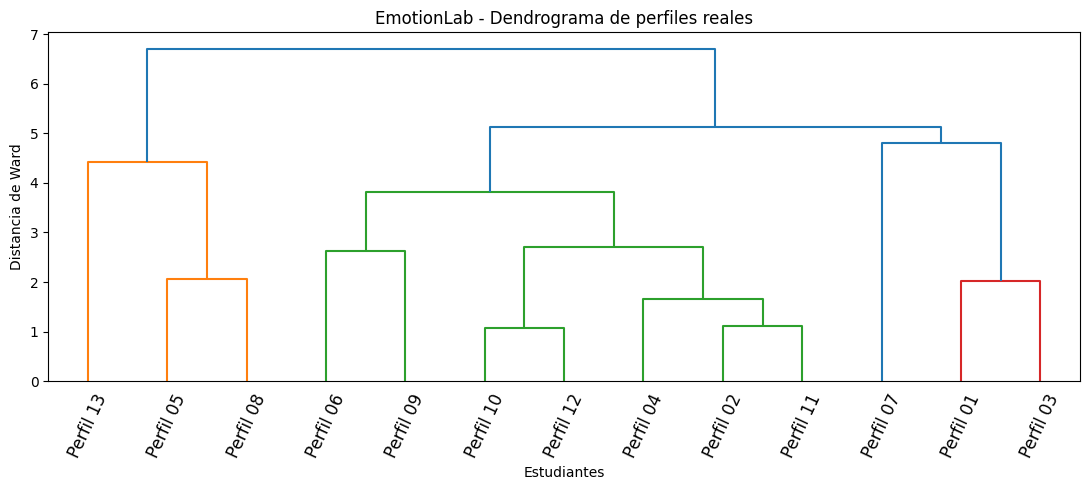

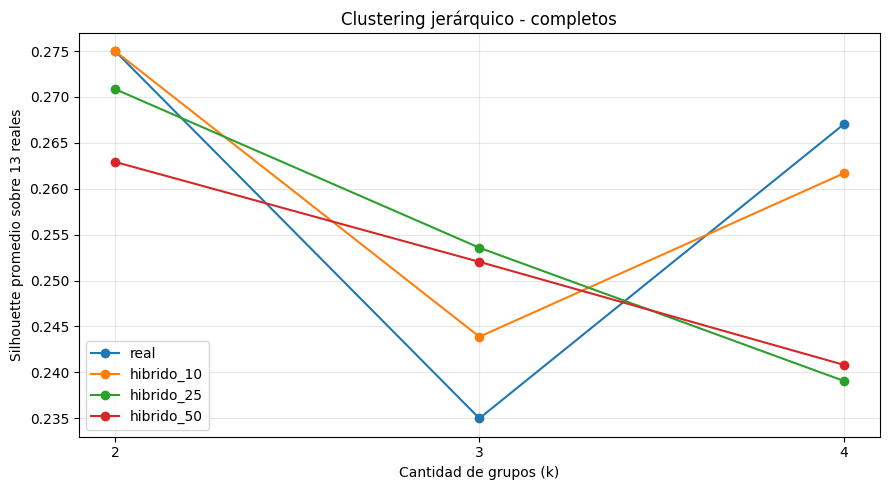

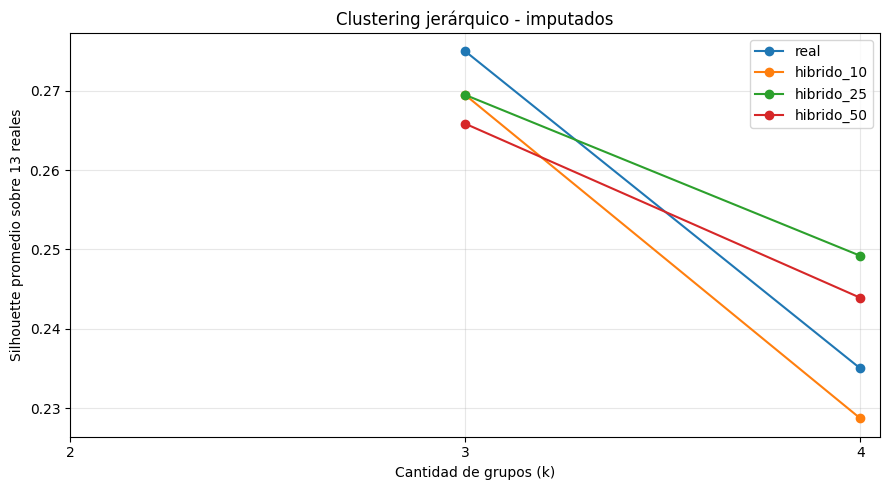

Visualizaciones jerárquicas completadas.


In [990]:

# =========================================================
# 5.5.4 - VISUALIZACIÓN DE CLUSTERING JERÁRQUICO
# =========================================================

# Construimos el dendrograma utilizando los
# 13 perfiles reales completos, sin imputaciones.

matriz_enlaces = linkage(
    X_real_escalado_ml.to_numpy(),
    method="ward"
)

plt.figure(figsize=(11, 5))

dendrogram(
    matriz_enlaces,
    labels=[
        f"Perfil {i:02d}"
        for i in range(1, len(X_real_escalado_ml) + 1)
    ],
    leaf_rotation=65
)

plt.title("EmotionLab - Dendrograma de perfiles reales")
plt.xlabel("Estudiantes")
plt.ylabel("Distancia de Ward")
plt.tight_layout()
plt.show()

# Comparamos la separación promedio de los
# agrupamientos en ambas versiones del dataset.

for version in ["completos", "imputados"]:

    datos = comparacion_jerarquica.loc[
        comparacion_jerarquica["Versión"].eq(version)
    ]

    plt.figure(figsize=(9, 5))

    for escenario in escenarios_jerarquicos:

        seleccion = datos.loc[
            datos["Escenario"].eq(escenario)
        ].sort_values("k")

        plt.plot(
            seleccion["k"],
            seleccion["Silhouette promedio"],
            marker="o",
            label=escenario
        )

    plt.title(f"Clustering jerárquico - {version}")
    plt.xlabel("Cantidad de grupos (k)")
    plt.ylabel("Silhouette promedio sobre 13 reales")
    plt.xticks(cantidades_grupos_jerarquico)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Visualizaciones jerárquicas completadas.")


### 5.5 — Resultados del entrenamiento de clustering jerárquico

Durante esta sección ejecutamos **186 configuraciones experimentales** de clustering jerárquico, comparando registros reales e híbridos, tanto completos como imputados por mediana.

### Principales resultados

- **Datos completos:** el entrenamiento real con dos grupos obtuvo Silhouette de 0,275 y Davies-Bouldin de 1,227.
- **Entrenamiento híbrido:** la configuración del 10 % mantuvo las mismas métricas con dos grupos y obtuvo estabilidad ARI de 1,000.
- **Mayor influencia sintética:** las configuraciones del 25 % y 50 % no produjeron mejoras consistentes en separación y estabilidad.
- **Imputación por mediana:** con dos grupos, los 13 estudiantes de evaluación quedaron concentrados en una única agrupación.
- **Dendrograma:** permitió visualizar las relaciones de semejanza entre los perfiles reales.

### Interpretación

Los resultados muestran que el clustering jerárquico puede identificar patrones de similitud entre las respuestas emocionales de los estudiantes.

Sin embargo, aumentar la presencia de datos sintéticos no mejoró consistentemente los agrupamientos, mientras que incorporar registros imputados produjo agrupaciones menos diferenciadas en determinadas configuraciones.

Las puntuaciones de Silhouette también sugieren una separación relativamente débil entre los perfiles analizados.

### Conclusión

El clustering jerárquico constituye una alternativa útil para estudiar y visualizar las relaciones entre estudiantes.

No obstante, los resultados no proporcionan evidencia suficiente para considerarlo superior a K-Means.

Por ahora, **K-Means con dos grupos se mantiene como candidato preliminar**, debido a sus métricas, su consistencia en las pruebas realizadas y su capacidad para asignar grupos a nuevos registros.

La selección definitiva permanecerá pendiente hasta evaluar Gaussian Mixture Models (GMM) y completar la comparación general de algoritmos.

## 5.6 — Entrenamiento y evaluación de Gaussian Mixture Models (GMM)

### ¿Qué realizaremos?

Durante esta sección entrenaremos modelos de Gaussian Mixture Models para identificar agrupaciones probabilísticas entre las respuestas emocionales de los estudiantes de EmotionLab.

A diferencia de K-Means, GMM representa los grupos mediante distribuciones gaussianas y estima la pertenencia de cada estudiante a sus distintos componentes.

### 1. Estrategias de entrenamiento

Compararemos dos estrategias principales:

- **Entrenamiento real:** utilizará los 13 registros reales completos.
- **Entrenamiento híbrido:** combinará registros reales y sintéticos, aproximando proporciones experimentales del 10 %, 25 % y 50 % de datos artificiales.

También realizaremos pruebas con los conjuntos que incorporan imputación por mediana: 15 registros reales aptos y 418 registros híbridos aptos.

### 2. Regularización del modelo

Debido al tamaño reducido de nuestra muestra, utilizaremos una configuración de covarianza diagonal y regularización numérica para disminuir el riesgo de ajustar distribuciones excesivamente específicas.

Esta configuración será experimental y no garantizará por sí sola la eliminación del sobreajuste.

### 3. Entrenamiento y evaluación

Probaremos modelos con 2, 3 y 4 componentes, considerando:

- Silhouette y Davies-Bouldin para estudiar la separación de los grupos.
- Adjusted Rand Index (ARI) para evaluar la estabilidad.
- Cantidad de estudiantes por grupo para detectar agrupaciones demasiado pequeñas.
- Convergencia para comprobar si el procedimiento de entrenamiento finalizó correctamente.
- Probabilidades de pertenencia para analizar la incertidumbre interna de las asignaciones.

### 4. Comparación con los algoritmos anteriores

Evaluaremos las agrupaciones sobre los mismos 13 estudiantes reales completos utilizados en K-Means y clustering jerárquico.

Así podremos comparar el comportamiento matemático de los algoritmos sin confundir los registros sintéticos con participantes independientes.

In [991]:

# =========================================================
# 5.6.1 - PREPARACIÓN DE CONJUNTOS PARA GMM
# =========================================================


# Extraemos los sintéticos conservando el mismo orden
# y la correspondencia con su procedencia.

def obtener_sinteticos_gmm(matriz, origen):

    if not matriz.index.equals(origen.index):
        raise ValueError("Los índices y la procedencia no coinciden.")

    return matriz.loc[origen.eq("sintetico")].copy()


# Preparamos dos versiones independientes.
# Ambas utilizan el escalador definido en la Etapa 5.2.

conjuntos_gmm = {
    "completos": {
        "reales": X_real_escalado_ml.copy(),
        "sinteticos": obtener_sinteticos_gmm(
            X_hibrido_escalado_ml,
            origen_hibrido_ml
        )
    },
    "imputados": {
        "reales": X_real_imputado_escalado_ml.copy(),
        "sinteticos": obtener_sinteticos_gmm(
            X_hibrido_imputado_escalado_ml,
            origen_hibrido_imputado_ml
        )
    }
}

# Los 13 perfiles originales serán nuestra referencia
# común para evaluar todas las configuraciones.

X_evaluacion_gmm = X_real_escalado_ml.copy()

for version, datos in conjuntos_gmm.items():

    reales = datos["reales"]
    sinteticos = datos["sinteticos"]

    if list(reales.columns) != variables_ml:
        raise ValueError(f"Variables incorrectas: {version}")

    if list(sinteticos.columns) != variables_ml:
        raise ValueError(f"Variables sintéticas incorrectas: {version}")

    if not np.allclose(
        reales.loc[X_evaluacion_gmm.index].to_numpy(),
        X_evaluacion_gmm.to_numpy()
    ):
        raise ValueError("Los registros originales fueron modificados.")

    if not (
        np.isfinite(reales.to_numpy()).all()
        and np.isfinite(sinteticos.to_numpy()).all()
    ):
        raise ValueError(f"Existen valores inválidos: {version}")

# Resumen de los conjuntos disponibles.

resumen_datos_gmm = pd.DataFrame([
    {
        "Versión": version,
        "Reales": len(datos["reales"]),
        "Sintéticos": len(datos["sinteticos"])
    }
    for version, datos in conjuntos_gmm.items()
])

print("DATOS PARA GAUSSIAN MIXTURE MODELS")
display(resumen_datos_gmm)


DATOS PARA GAUSSIAN MIXTURE MODELS


,Versión,Reales,Sintéticos
0,completos,13,336
1,imputados,15,403


In [992]:

# =========================================================
# 5.6.2 - ENTRENAMIENTO EXPERIMENTAL DE GMM
# =========================================================

# Configuraciones experimentales.

escenarios_gmm = {
    "real": 0.00,
    "hibrido_10": 0.10,
    "hibrido_25": 0.25,
    "hibrido_50": 0.50
}

componentes_gmm = [2, 3, 4]
semillas_gmm = [11, 21, 31, 41, 51]

# Seleccionamos sintéticos priorizando distintas semillas
# de origen cuando esa información esté disponible.

def seleccionar_sinteticos_gmm(datos, cantidad, semilla):

    mezclados = datos.sample(frac=1, random_state=semilla)

    if "id_semilla" not in dataset_hibrido_ml.columns:
        return mezclados.iloc[:cantidad]

    origen_semilla = dataset_hibrido_ml.loc[
        mezclados.index, "id_semilla"
    ]

    diversos = mezclados.loc[
        ~origen_semilla.duplicated()
    ]

    if len(diversos) >= cantidad:
        return diversos.iloc[:cantidad]

    restantes = mezclados.drop(index=diversos.index)

    return pd.concat([
        diversos,
        restantes.iloc[:cantidad - len(diversos)]
    ])


# Entrenaremos cinco repeticiones por configuración.
# Guardamos modelos y asignaciones para analizarlos.

modelos_gmm = {}
predicciones_gmm = {}
resultados_gmm = []

for version, datos in conjuntos_gmm.items():

    X_reales = datos["reales"]
    X_sinteticos = datos["sinteticos"]

    for escenario, proporcion in escenarios_gmm.items():

        # Calculamos la cantidad aproximada de sintéticos
        # necesaria para alcanzar la proporción solicitada.

        cantidad = round(
            len(X_reales) * proporcion / (1 - proporcion)
        )

        if cantidad > len(X_sinteticos):
            raise ValueError("No hay suficientes datos sintéticos.")

        for k in componentes_gmm:

            for semilla in semillas_gmm:

                # Creamos el conjunto de esta repetición.

                if cantidad > 0:

                    muestra = seleccionar_sinteticos_gmm(
                        X_sinteticos,
                        cantidad,
                        semilla
                    )

                    X_entrenamiento = pd.concat(
                        [X_reales, muestra],
                        ignore_index=True
                    )

                else:
                    X_entrenamiento = X_reales

                # Covarianza diagonal y regularización
                # para limitar la complejidad del ajuste.

                modelo = GaussianMixture(
                    n_components=k,
                    covariance_type="diag",
                    reg_covar=0.1,
                    n_init=3,
                    max_iter=300,
                    random_state=semilla
                )

                modelo.fit(X_entrenamiento)

                # Evaluamos sobre los mismos 13 reales.

                etiquetas = modelo.predict(X_evaluacion_gmm)
                probabilidades = modelo.predict_proba(
                    X_evaluacion_gmm
                )

                clave = (version, escenario, k, semilla)

                modelos_gmm[clave] = modelo
                predicciones_gmm[clave] = etiquetas

                grupos, tamaños = np.unique(
                    etiquetas, return_counts=True
                )

                silhouette = np.nan
                davies = np.nan

                if 2 <= len(grupos) < len(X_evaluacion_gmm):

                    silhouette = silhouette_score(
                        X_evaluacion_gmm, etiquetas
                    )

                    davies = davies_bouldin_score(
                        X_evaluacion_gmm, etiquetas
                    )

                resultados_gmm.append({
                    "Versión": version,
                    "Escenario": escenario,
                    "k": k,
                    "Semilla": semilla,
                    "Registros entrenamiento": len(X_entrenamiento),
                    "Sintéticos usados": cantidad,
                    "Grupos reales": len(grupos),
                    "Menor grupo": int(tamaños.min()),
                    "Silhouette": silhouette,
                    "Davies-Bouldin": davies,
                    "Probabilidad máxima media": (
                        probabilidades.max(axis=1).mean()
                    ),
                    "Convergió": bool(modelo.converged_)
                })

resultados_gmm = pd.DataFrame(resultados_gmm)

print("ENTRENAMIENTO GMM - EMOTIONLAB")
print("Modelos entrenados:", len(modelos_gmm))
print("Modelos convergentes:", resultados_gmm["Convergió"].sum())

display(
    resultados_gmm[[
        "Versión", "Escenario", "k",
        "Registros entrenamiento", "Sintéticos usados"
    ]].drop_duplicates().reset_index(drop=True)
)


ENTRENAMIENTO GMM - EMOTIONLAB
Modelos entrenados: 120
Modelos convergentes: 120


,Versión,Escenario,k,Registros entrenamiento,Sintéticos usados
0,completos,real,2,13,0
1,completos,real,3,13,0
2,completos,real,4,13,0
3,completos,hibrido_10,2,14,1
4,completos,hibrido_10,3,14,1
5,completos,hibrido_10,4,14,1
6,completos,hibrido_25,2,17,4
7,completos,hibrido_25,3,17,4
8,completos,hibrido_25,4,17,4
9,completos,hibrido_50,2,26,13


In [993]:

# =========================================================
# 5.6.3 - EVALUACIÓN Y ESTABILIDAD DE GMM
# =========================================================

resumenes_gmm = []

for (version, escenario, k), grupo in resultados_gmm.groupby(
    ["Versión", "Escenario", "k"],
    sort=False
):

    # Recuperamos las asignaciones realizadas sobre
    # los mismos 13 estudiantes en cada repetición.

    asignaciones = [
        predicciones_gmm[
            (version, escenario, k, int(semilla))
        ]
        for semilla in grupo["Semilla"]
    ]

    # Medimos la coincidencia entre repeticiones.
    # ARI no depende del número asignado a cada grupo.

    valores_ari = [
        adjusted_rand_score(a, b)
        for a, b in combinations(asignaciones, 2)
    ]

    # Comparamos contra la versión real del mismo
    # conjunto y número de componentes.

    referencia = predicciones_gmm[
        (version, "real", k, semillas_gmm[0])
    ]

    ari_referencia = [
        adjusted_rand_score(referencia, etiquetas)
        for etiquetas in asignaciones
    ]

    resumenes_gmm.append({
        "Versión": version,
        "Escenario": escenario,
        "k": k,
        "Silhouette promedio": grupo["Silhouette"].mean(),
        "Davies-Bouldin promedio": grupo["Davies-Bouldin"].mean(),
        "ARI estabilidad": np.mean(valores_ari),
        "ARI mínimo": np.min(valores_ari),
        "ARI vs real": np.mean(ari_referencia),
        "Menor grupo": grupo["Menor grupo"].min(),
        "Grupos efectivos mín.": grupo["Grupos reales"].min(),
        "Grupos efectivos máx.": grupo["Grupos reales"].max(),
        "Repeticiones válidas": grupo["Silhouette"].notna().sum(),
        "Convergencias": int(grupo["Convergió"].sum()),
        "Pertenencia máxima media": (
            grupo["Probabilidad máxima media"].mean()
        )
    })

comparacion_gmm = pd.DataFrame(resumenes_gmm)

print("COMPARACIÓN EXPERIMENTAL - GMM")
display(comparacion_gmm.round(3))

print("\nEvaluación de estabilidad completada.")


COMPARACIÓN EXPERIMENTAL - GMM


,Versión,Escenario,k,Silhouette promedio,Davies-Bouldin promedio,ARI estabilidad,ARI mínimo,ARI vs real,Menor grupo,Grupos efectivos mín.,Grupos efectivos máx.,Repeticiones válidas,Convergencias,Pertenencia máxima media
0,completos,real,2,0.260,1.287,0.745,0.416,0.869,2,2,2,5,5,0.995
1,completos,real,3,0.176,1.227,0.354,0.091,0.559,1,3,3,5,5,0.995
2,completos,real,4,0.246,0.895,0.824,0.560,0.648,1,4,4,5,5,0.999
3,completos,hibrido_10,2,0.275,1.227,1.000,1.000,1.000,3,2,2,5,5,1.000
4,completos,hibrido_10,3,0.222,1.264,0.553,0.376,0.627,1,3,3,5,5,0.986
5,completos,hibrido_10,4,0.243,0.809,0.553,0.269,0.404,1,4,4,5,5,1.000
6,completos,hibrido_25,2,0.220,1.345,0.271,-0.140,0.553,2,2,2,5,5,0.986
7,completos,hibrido_25,3,0.206,1.243,0.463,0.239,0.580,1,3,3,5,5,0.987
8,completos,hibrido_25,4,0.216,0.874,0.436,0.215,0.539,1,4,4,5,5,0.991
9,completos,hibrido_50,2,0.262,1.295,0.875,0.687,0.937,3,2,2,5,5,0.992



Evaluación de estabilidad completada.


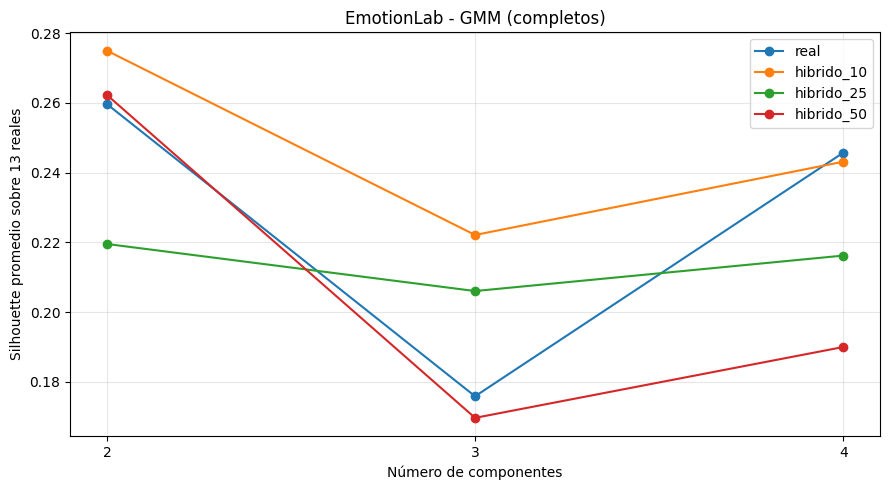

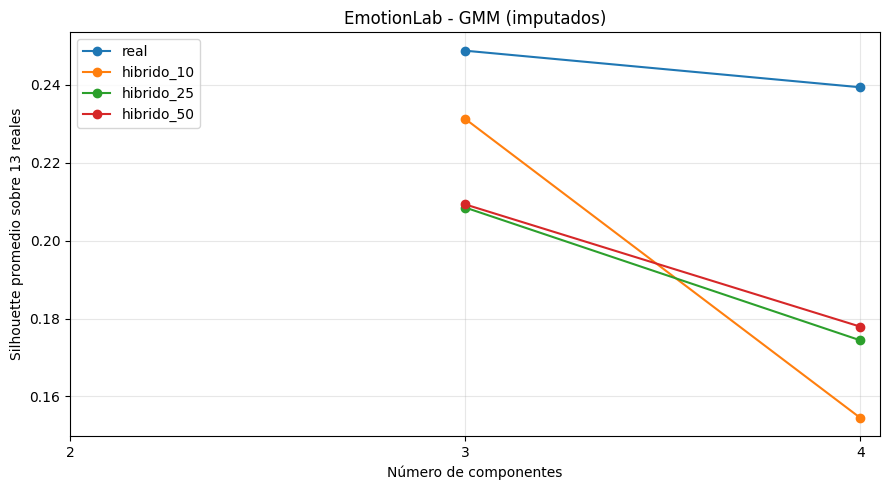

EJEMPLO DE PERTENENCIA A COMPONENTES - GMM


,Registro,Componente,Probabilidad máxima
0,Registro 01,0,1.0
1,Registro 02,0,1.0
2,Registro 03,0,1.0
3,Registro 04,0,1.0
4,Registro 05,1,1.0
5,Registro 06,0,1.0
6,Registro 07,0,1.0
7,Registro 08,1,1.0
8,Registro 09,0,1.0
9,Registro 10,0,1.0


In [994]:

# =========================================================
# 5.6.4 - VISUALIZACIÓN DE RESULTADOS GMM
# =========================================================


# Generamos un gráfico independiente para cada
# versión: registros completos e imputados.

for version in ["completos", "imputados"]:

    datos = comparacion_gmm.loc[
        comparacion_gmm["Versión"].eq(version)
    ]

    plt.figure(figsize=(9, 5))

    for escenario in escenarios_gmm:

        seleccion = datos.loc[
            datos["Escenario"].eq(escenario)
        ].sort_values("k")

        plt.plot(
            seleccion["k"],
            seleccion["Silhouette promedio"],
            marker="o",
            label=escenario
        )

    plt.title(f"EmotionLab - GMM ({version})")
    plt.xlabel("Número de componentes")
    plt.ylabel("Silhouette promedio sobre 13 reales")
    plt.xticks(componentes_gmm)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Mostramos un ejemplo de pertenencia probabilística.
# Utilizamos provisionalmente GMM real con k = 2.
# Esto NO constituye una selección definitiva.

modelo_ejemplo_gmm = modelos_gmm[
    ("completos", "real", 2, semillas_gmm[0])
]

probabilidades_ejemplo = modelo_ejemplo_gmm.predict_proba(
    X_evaluacion_gmm
)

ejemplo_pertenencia_gmm = pd.DataFrame({
    "Registro": [
        f"Registro {i:02d}"
        for i in range(1, len(X_evaluacion_gmm) + 1)
    ],
    "Componente": probabilidades_ejemplo.argmax(axis=1),
    "Probabilidad máxima": probabilidades_ejemplo.max(axis=1)
})

print("EJEMPLO DE PERTENENCIA A COMPONENTES - GMM")
display(ejemplo_pertenencia_gmm.round(3))


### 5.6 — Resultados del entrenamiento de Gaussian Mixture Models

Durante esta sección entrenamos y evaluamos 120 configuraciones de GMM, utilizando datos reales e híbridos, tanto completos como imputados por mediana.

### Principales resultados

- **Convergencia:** los 120 entrenamientos alcanzaron el criterio de convergencia.
- **Entrenamiento real:** GMM con dos componentes obtuvo Silhouette de 0,260 y estabilidad ARI de 0,745.
- **Híbrido del 10 %:** obtuvo Silhouette de 0,275 y estabilidad ARI de 1,000, siendo la configuración más consistente entre las evaluadas con dos componentes.
- **Híbridos del 25 % y 50 %:** no produjeron mejoras consistentes.
- **Imputación por mediana:** con dos componentes, los estudiantes reales quedaron concentrados en un único grupo, impidiendo calcular métricas de separación.
- **Pertenencia probabilística:** GMM produjo probabilidades internas elevadas, que no deben confundirse con precisión predictiva ni certeza psicológica.

### Interpretación

Los resultados indican que GMM puede identificar agrupaciones entre los perfiles de EmotionLab y que una incorporación limitada de datos sintéticos puede modificar favorablemente determinadas métricas.

Sin embargo, la muestra real sigue siendo reducida y las mejoras observadas no demuestran capacidad de generalización a nuevos estudiantes.

Además, las configuraciones con imputación no presentaron ventajas consistentes frente al entrenamiento con registros completos.

### Conclusión

GMM constituye una alternativa técnicamente viable para el análisis exploratorio de EmotionLab, especialmente por su capacidad para estimar probabilidades de pertenencia a componentes.

No obstante, sus resultados no demuestran una superioridad general frente a K-Means.

**K-Means con dos grupos se mantiene como candidato preliminar**, debido a su consistencia, simplicidad de implementación y compatibilidad con la asignación de nuevos registros.

La selección definitiva requerirá comparar los tres algoritmos bajo criterios comunes y revisar la estabilidad de sus agrupaciones frente a cambios en los registros utilizados.

## 5.7 — Comparación general y selección experimental del modelo

### ¿Qué realizaremos?

Durante esta sección compararemos los resultados de los tres algoritmos de aprendizaje no supervisado desarrollados para EmotionLab:

- **K-Means:** agrupamiento mediante centroides.
- **Clustering jerárquico:** agrupamiento basado en relaciones de semejanza.
- **Gaussian Mixture Models (GMM):** agrupamiento probabilístico mediante distribuciones gaussianas.

### 1. Comparación de resultados

Reuniremos las métricas de Silhouette, Davies-Bouldin, estabilidad ARI y tamaño de los grupos, utilizando los 13 perfiles reales completos como referencia común.

Separaremos los resultados de los entrenamientos con datos completos de aquellos que incorporaron estimaciones mediante la mediana.

### 2. Sensibilidad a la muestra

Además de las pruebas anteriores, retiraremos un estudiante real por vez y volveremos a entrenar los tres algoritmos con los 12 restantes.

Compararemos las agrupaciones resultantes con las obtenidas utilizando los 13 estudiantes, para estudiar su sensibilidad ante cambios en la muestra.

### 3. Revisión del entrenamiento híbrido

Comprobaremos qué configuraciones presentaron ventajas frente al entrenamiento real y revisaremos la trazabilidad de los registros sintéticos.

Estas comparaciones no demostrarán generalización independiente mientras los datos sintéticos puedan depender de los estudiantes utilizados para evaluar.

### 4. Selección experimental

Consideraremos conjuntamente:

- Calidad de separación de los grupos.
- Estabilidad ante cambios en el entrenamiento.
- Tamaño y cantidad efectiva de los grupos.
- Dependencia de datos sintéticos o estimados.
- Capacidad técnica de asignar un grupo a nuevos estudiantes.

In [995]:

# =========================================================
# 5.7.1 - COMPARACIÓN GENERAL DE ALGORITMOS
# =========================================================

# Verificamos que existan los resultados necesarios.

requeridas = [
    "comparacion_kmeans",
    "comparacion_jerarquica",
    "comparacion_gmm"
]

faltantes = [v for v in requeridas if v not in globals()]

if faltantes:
    raise ValueError(f"Faltan resultados: {faltantes}")

# Unificamos los nombres de las métricas para comparar
# los tres algoritmos en una misma tabla.

km = comparacion_kmeans.rename(columns={
    "Silhouette real": "Silhouette",
    "Davies-Bouldin real": "Davies-Bouldin",
    "ARI promedio": "ARI estabilidad",
    "Grupos en reales": "Grupos mínimos"
}).copy()

km["Algoritmo"] = "K-Means"
km["Versión"] = "completos"
km["Grupos máximos"] = km["Grupos mínimos"]
km["Repeticiones válidas"] = km["Silhouette"].notna().astype(int)

jer = comparacion_jerarquica.loc[
    comparacion_jerarquica["Versión"].eq("completos")
].rename(columns={
    "Silhouette promedio": "Silhouette",
    "Davies-Bouldin promedio": "Davies-Bouldin",
    "Menor grupo observado": "Menor grupo",
    "Grupos efectivos mín.": "Grupos mínimos",
    "Grupos efectivos máx.": "Grupos máximos",
    "Evaluaciones válidas": "Repeticiones válidas"
}).copy()

jer["Algoritmo"] = "Jerárquico"

gmm = comparacion_gmm.loc[
    comparacion_gmm["Versión"].eq("completos")
].rename(columns={
    "Silhouette promedio": "Silhouette",
    "Davies-Bouldin promedio": "Davies-Bouldin",
    "Grupos efectivos mín.": "Grupos mínimos",
    "Grupos efectivos máx.": "Grupos máximos"
}).copy()

gmm["Algoritmo"] = "GMM"

# Seleccionamos las mismas columnas de cada modelo.

columnas_comparacion = [
    "Algoritmo", "Versión", "Escenario", "k",
    "Silhouette", "Davies-Bouldin",
    "ARI estabilidad", "Menor grupo",
    "Grupos mínimos", "Grupos máximos",
    "Repeticiones válidas"
]

tabla_modelos_57 = pd.concat(
    [
        km[columnas_comparacion],
        jer[columnas_comparacion],
        gmm[columnas_comparacion]
    ],
    ignore_index=True
)

# Una configuración es descriptivamente adecuada
# si mantiene k grupos efectivos y ningún grupo
# observado tiene menos de dos estudiantes.
#
# Este filtro NO demuestra validez psicológica.

tabla_modelos_57["Agrupación utilizable"] = (
    tabla_modelos_57["Grupos mínimos"].eq(tabla_modelos_57["k"])
    & tabla_modelos_57["Grupos máximos"].eq(tabla_modelos_57["k"])
    & tabla_modelos_57["Menor grupo"].ge(2)
    & tabla_modelos_57["Silhouette"].notna()
)

print("COMPARACIÓN GENERAL - EMOTIONLAB")
display(tabla_modelos_57.round(3))

print("\nCONFIGURACIONES CON DOS GRUPOS")
display(
    tabla_modelos_57.loc[
        tabla_modelos_57["k"].eq(2)
    ].sort_values(
        ["Silhouette", "Davies-Bouldin"],
        ascending=[False, True]
    ).round(3)
)


COMPARACIÓN GENERAL - EMOTIONLAB


,Algoritmo,Versión,Escenario,k,Silhouette,Davies-Bouldin,ARI estabilidad,Menor grupo,Grupos mínimos,Grupos máximos,Repeticiones válidas,Agrupación utilizable
0,K-Means,completos,real,2,0.275,1.227,1.000,3,2,2,1,True
1,K-Means,completos,real,3,0.235,1.309,0.691,3,3,3,1,True
2,K-Means,completos,real,4,0.267,0.859,0.902,1,4,4,1,False
3,K-Means,completos,hibrido_10,2,0.275,1.227,1.000,3,2,2,1,True
4,K-Means,completos,hibrido_10,3,0.235,1.309,0.902,3,3,3,1,True
5,K-Means,completos,hibrido_10,4,0.211,1.135,0.849,2,4,4,1,True
6,K-Means,completos,hibrido_25,2,0.275,1.227,1.000,3,2,2,1,True
7,K-Means,completos,hibrido_25,3,0.264,0.945,1.000,1,3,3,1,False
8,K-Means,completos,hibrido_25,4,0.267,0.859,1.000,1,4,4,1,False
9,K-Means,completos,hibrido_50,2,0.275,1.227,1.000,3,2,2,1,True



CONFIGURACIONES CON DOS GRUPOS


,Algoritmo,Versión,Escenario,k,Silhouette,Davies-Bouldin,ARI estabilidad,Menor grupo,Grupos mínimos,Grupos máximos,Repeticiones válidas,Agrupación utilizable
0,K-Means,completos,real,2,0.275,1.227,1.000,3,2,2,1,True
3,K-Means,completos,hibrido_10,2,0.275,1.227,1.000,3,2,2,1,True
6,K-Means,completos,hibrido_25,2,0.275,1.227,1.000,3,2,2,1,True
9,K-Means,completos,hibrido_50,2,0.275,1.227,1.000,3,2,2,1,True
12,Jerárquico,completos,real,2,0.275,1.227,NaN,3,2,2,1,True
13,Jerárquico,completos,hibrido_10,2,0.275,1.227,1.000,3,2,2,10,True
27,GMM,completos,hibrido_10,2,0.275,1.227,1.000,3,2,2,5,True
14,Jerárquico,completos,hibrido_25,2,0.271,1.274,0.937,3,2,2,10,True
15,Jerárquico,completos,hibrido_50,2,0.263,1.294,0.811,2,2,2,10,True
33,GMM,completos,hibrido_50,2,0.262,1.295,0.875,3,2,2,5,True


In [996]:

# =========================================================
# 5.7.2 - ACUERDO ENTRE MODELOS E IMPUTACIÓN
# =========================================================

from sklearn.metrics import adjusted_rand_score

# Recuperamos asignaciones sobre los mismos 13 reales.
# GMM utiliza la primera semilla evaluada en 5.6.

asignaciones_57 = {
    "K-Means real": predicciones_kmeans[("real", 2)],
    "Jerárquico real": predicciones_jerarquicas[
        ("completos", "real", 2, 0)
    ],
    "GMM híbrido 10": predicciones_gmm[
        ("completos", "hibrido_10", 2, 11)
    ]
}

# Calculamos el acuerdo entre las agrupaciones.
# ARI = 1 indica que las particiones son equivalentes.

nombres = list(asignaciones_57)

acuerdo_57 = pd.DataFrame(
    [
        [
            adjusted_rand_score(
                asignaciones_57[a],
                asignaciones_57[b]
            )
            for b in nombres
        ]
        for a in nombres
    ],
    index=nombres,
    columns=nombres
)

print("ACUERDO ENTRE ALGORITMOS - ARI")
display(acuerdo_57.round(3))

# Revisamos las versiones imputadas con k = 2.
# Nos interesa saber cuántos grupos efectivos
# aparecen entre los 13 estudiantes reales.

revision_imputados_57 = pd.concat([
    evaluacion_kmeans_imputados.loc[
        evaluacion_kmeans_imputados["k"].eq(2),
        ["Escenario", "Grupos reales", "Silhouette"]
    ].assign(Algoritmo="K-Means"),

    comparacion_jerarquica.loc[
        comparacion_jerarquica["Versión"].eq("imputados")
        & comparacion_jerarquica["k"].eq(2),
        ["Escenario", "Grupos efectivos mín.",
         "Silhouette promedio"]
    ].rename(columns={
        "Grupos efectivos mín.": "Grupos reales",
        "Silhouette promedio": "Silhouette"
    }).assign(Algoritmo="Jerárquico"),

    comparacion_gmm.loc[
        comparacion_gmm["Versión"].eq("imputados")
        & comparacion_gmm["k"].eq(2),
        ["Escenario", "Grupos efectivos mín.",
         "Silhouette promedio"]
    ].rename(columns={
        "Grupos efectivos mín.": "Grupos reales",
        "Silhouette promedio": "Silhouette"
    }).assign(Algoritmo="GMM")
], ignore_index=True)

print("\nREVISIÓN DE MODELOS IMPUTADOS - k = 2")
display(
    revision_imputados_57[
        ["Algoritmo", "Escenario", "Grupos reales", "Silhouette"]
    ].round(3)
)


ACUERDO ENTRE ALGORITMOS - ARI


,K-Means real,Jerárquico real,GMM híbrido 10
K-Means real,1.0,1.0,1.0
Jerárquico real,1.0,1.0,1.0
GMM híbrido 10,1.0,1.0,1.0



REVISIÓN DE MODELOS IMPUTADOS - k = 2


,Algoritmo,Escenario,Grupos reales,Silhouette
0,K-Means,real,1,NaN
1,K-Means,hibrido_10,1,NaN
2,K-Means,hibrido_25,1,NaN
3,K-Means,hibrido_50,1,NaN
4,Jerárquico,real,1,NaN
5,Jerárquico,hibrido_10,1,NaN
6,Jerárquico,hibrido_25,1,NaN
7,Jerárquico,hibrido_50,1,NaN
8,GMM,real,1,NaN
9,GMM,hibrido_10,1,NaN


In [997]:

# =========================================================
# 5.7.3 - SENSIBILIDAD AL RETIRAR ESTUDIANTES
# =========================================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Recuperamos los valores originales sin escalar.
# Esto permite ajustar un nuevo escalador en cada
# repetición usando solo los estudiantes restantes.

X_original_57 = X_real_ml.loc[
    X_real_escalado_ml.index, variables_ml
].copy()

# Asignaciones de referencia obtenidas con los
# 13 estudiantes completos y dos grupos.

referencias_57 = {
    "K-Means": np.asarray(
        predicciones_kmeans[("real", 2)]
    ),
    "Jerárquico": np.asarray(
        predicciones_jerarquicas[("completos", "real", 2, 0)]
    ),
    "GMM": np.asarray(
        predicciones_gmm[("completos", "real", 2, 11)]
    )
}

resultados_loo_57 = []

# Repetimos el experimento retirando una fila por vez.

for excluido in range(len(X_original_57)):

    # Seleccionamos los otros 12 estudiantes.
    # No imputamos ni incorporamos sintéticos.

    mascara = np.ones(len(X_original_57), dtype=bool)
    mascara[excluido] = False

    X_entrenamiento = StandardScaler().fit_transform(
        X_original_57.iloc[mascara]
    )

    # Entrenamos los tres algoritmos con idénticos
    # registros y cantidad de grupos.

    km = KMeans(
        n_clusters=2,
        n_init=10,
        random_state=42
    )
    etiquetas_km = km.fit_predict(X_entrenamiento)

    jer = AgglomerativeClustering(
        n_clusters=2,
        linkage="ward"
    )
    etiquetas_jer = jer.fit_predict(X_entrenamiento)

    gmm = GaussianMixture(
        n_components=2,
        covariance_type="diag",
        reg_covar=0.1,
        n_init=3,
        max_iter=300,
        random_state=11
    )
    etiquetas_gmm = gmm.fit_predict(X_entrenamiento)

    asignaciones = {
        "K-Means": etiquetas_km,
        "Jerárquico": etiquetas_jer,
        "GMM": etiquetas_gmm
    }

    for algoritmo, etiquetas in asignaciones.items():

        # Comparamos las asignaciones de los 12
        # estudiantes con la partición original
        # de 13, excluyendo al mismo participante.

        ari = adjusted_rand_score(
            referencias_57[algoritmo][mascara],
            etiquetas
        )

        grupos, cantidades = np.unique(
            etiquetas, return_counts=True
        )

        silhouette = np.nan

        if 2 <= len(grupos) < len(X_entrenamiento):
            silhouette = silhouette_score(
                X_entrenamiento, etiquetas
            )

        resultados_loo_57.append({
            "Algoritmo": algoritmo,
            "Estudiante excluido": excluido + 1,
            "ARI vs referencia": ari,
            "Silhouette": silhouette,
            "Grupos efectivos": len(grupos),
            "Menor grupo": int(cantidades.min())
        })

# Resumimos las 13 repeticiones de cada algoritmo.

resultados_loo_57 = pd.DataFrame(resultados_loo_57)

estabilidad_loo_57 = (
    resultados_loo_57
    .groupby("Algoritmo")
    .agg(
        Repeticiones=("ARI vs referencia", "size"),
        ARI_promedio=("ARI vs referencia", "mean"),
        ARI_minimo=("ARI vs referencia", "min"),
        Silhouette_promedio=("Silhouette", "mean"),
        Menor_grupo=("Menor grupo", "min")
    )
    .reset_index()
)

print("SENSIBILIDAD A LA MUESTRA - 13 EXCLUSIONES")
display(estabilidad_loo_57.round(3))


SENSIBILIDAD A LA MUESTRA - 13 EXCLUSIONES


,Algoritmo,Repeticiones,ARI_promedio,ARI_minimo,Silhouette_promedio,Menor_grupo
0,GMM,13,0.743,-0.103,0.249,1
1,Jerárquico,13,1.000,1.000,0.274,2
2,K-Means,13,1.000,1.000,0.274,2


In [998]:

# =========================================================
# 5.7.4 - AUDITORÍA DE PROCEDENCIA SINTÉTICA
# =========================================================

# Seleccionamos los registros sintéticos originales.
# No usamos las respuestas imputadas en esta revisión.

sinteticos_57 = dataset_hibrido_ml.loc[
    dataset_hibrido_ml["origen_ml"].eq("sintetico")
].copy()

if "id_semilla" not in sinteticos_57.columns:
    raise ValueError(
        "No existe id_semilla para revisar la procedencia."
    )

# Obtenemos los identificadores originales y los
# correspondientes a los 13 estudiantes evaluables.

ids_reales_57 = set(
    datos_reales_ml["id_estudiante"]
    .dropna().astype(str).str.strip()
)

ids_evaluables_57 = set(
    datos_reales_ml.loc[
        X_real_ml.index, "id_estudiante"
    ].dropna().astype(str).str.strip()
)

# Normalizamos las semillas solo para comparar
# identificadores; no modificamos la columna original.

semillas_57 = (
    sinteticos_57["id_semilla"]
    .astype("string")
    .str.strip()
)

coincide_real = semillas_57.isin(ids_reales_57)
coincide_evaluable = semillas_57.isin(ids_evaluables_57)

# Resumimos qué parte de la dependencia es verificable
# mediante coincidencia exacta de identificadores.

auditoria_sintetica_57 = pd.DataFrame([{
    "Registros sintéticos": len(sinteticos_57),
    "Con semilla identificada": int(semillas_57.notna().sum()),
    "Semillas diferentes": int(semillas_57.nunique()),
    "Coinciden con ID real": int(coincide_real.sum()),
    "Coinciden con ID evaluable": int(coincide_evaluable.sum())
}])

print("AUDITORÍA DE DATOS SINTÉTICOS - EMOTIONLAB")
display(auditoria_sintetica_57)

print("\nIMPORTANTE:")
print("Una coincidencia exacta permite rastrear dependencia.")
print("La ausencia de coincidencias no demuestra independencia.")
print("Debemos revisar el generador antes de validar")
print("modelos híbridos con participantes reservados.")


AUDITORÍA DE DATOS SINTÉTICOS - EMOTIONLAB


,Registros sintéticos,Con semilla identificada,Semillas diferentes,Coinciden con ID real,Coinciden con ID evaluable
0,573,573,22,573,336



IMPORTANTE:
Una coincidencia exacta permite rastrear dependencia.
La ausencia de coincidencias no demuestra independencia.
Debemos revisar el generador antes de validar
modelos híbridos con participantes reservados.


CANDIDATOS EXPERIMENTALES - EMOTIONLAB


,Algoritmo,Escenario,k,Silhouette,Davies-Bouldin,ARI estabilidad,ARI LOO real,Menor grupo,Inferencia directa
0,K-Means,real,2,0.275,1.227,1.000,1.000,3,True
3,K-Means,hibrido_10,2,0.275,1.227,1.000,NaN,3,True
6,K-Means,hibrido_25,2,0.275,1.227,1.000,NaN,3,True
9,K-Means,hibrido_50,2,0.275,1.227,1.000,NaN,3,True
12,Jerárquico,real,2,0.275,1.227,NaN,1.000,3,False
13,Jerárquico,hibrido_10,2,0.275,1.227,1.000,NaN,3,False
27,GMM,hibrido_10,2,0.275,1.227,1.000,NaN,3,True
14,Jerárquico,hibrido_25,2,0.271,1.274,0.937,NaN,3,False
15,Jerárquico,hibrido_50,2,0.263,1.294,0.811,NaN,2,False
33,GMM,hibrido_50,2,0.262,1.295,0.875,NaN,3,True


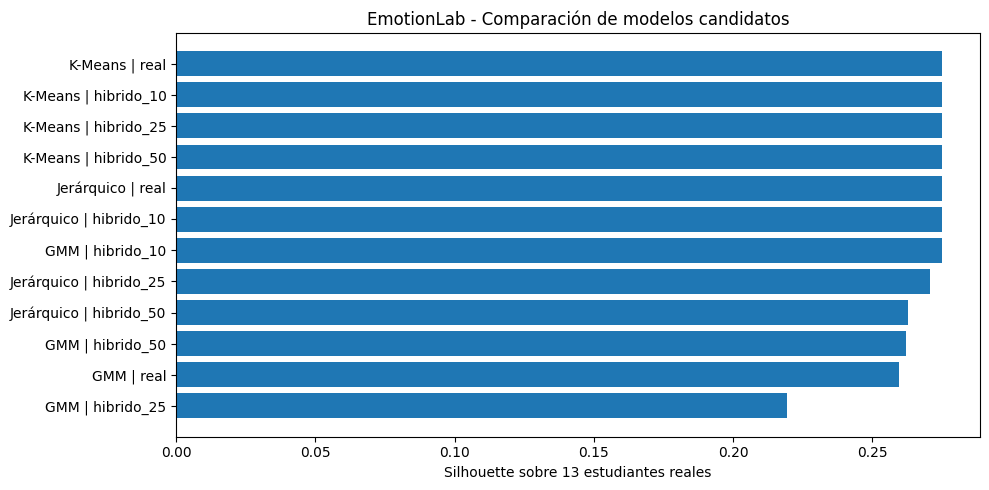


PRESELECCIÓN COMPLETADA
Revisar el ARI LOO, la dependencia sintética
y la capacidad de inferencia antes de elegir.


In [999]:

# =========================================================
# 5.7.5 - RESUMEN Y PRESELECCIÓN EXPERIMENTAL
# =========================================================

import matplotlib.pyplot as plt

# Recuperamos los modelos con dos grupos y
# una agrupación utilizable sobre los 13 reales.

candidatos_57 = tabla_modelos_57.loc[
    tabla_modelos_57["k"].eq(2)
    & tabla_modelos_57["Agrupación utilizable"]
].copy()

# Incorporamos la sensibilidad a la muestra solamente
# para los modelos reales: no hemos realizado una
# exclusión equivalente libre de filtración en híbridos.

ari_loo = estabilidad_loo_57.set_index(
    "Algoritmo"
)["ARI_promedio"]

candidatos_57["ARI LOO real"] = [
    ari_loo.get(algoritmo, np.nan)
    if escenario == "real" else np.nan
    for algoritmo, escenario in zip(
        candidatos_57["Algoritmo"],
        candidatos_57["Escenario"]
    )
]

# Registramos si el algoritmo puede asignar directamente
# grupos a nuevos perfiles mediante predict().

inferencia_directa = {
    "K-Means": True,
    "GMM": True,
    "Jerárquico": False
}

candidatos_57["Inferencia directa"] = (
    candidatos_57["Algoritmo"].map(inferencia_directa)
)

# Ordenamos los modelos únicamente para facilitar
# su revisión, no para declarar un ganador automático.

candidatos_57 = candidatos_57.sort_values(
    ["Silhouette", "Davies-Bouldin"],
    ascending=[False, True]
)

print("CANDIDATOS EXPERIMENTALES - EMOTIONLAB")

display(
    candidatos_57[[
        "Algoritmo", "Escenario", "k",
        "Silhouette", "Davies-Bouldin",
        "ARI estabilidad", "ARI LOO real",
        "Menor grupo", "Inferencia directa"
    ]].round(3)
)

# Visualizamos la calidad observada en los 13 reales.

plt.figure(figsize=(10, 5))

etiquetas = (
    candidatos_57["Algoritmo"]
    + " | "
    + candidatos_57["Escenario"]
)

plt.barh(etiquetas, candidatos_57["Silhouette"])
plt.xlabel("Silhouette sobre 13 estudiantes reales")
plt.title("EmotionLab - Comparación de modelos candidatos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nPRESELECCIÓN COMPLETADA")
print("Revisar el ARI LOO, la dependencia sintética")
print("y la capacidad de inferencia antes de elegir.")


### 5.7 — Resultados de la comparación general y selección experimental

Durante esta sección comparamos los resultados de K-Means, clustering jerárquico y Gaussian Mixture Models (GMM), considerando la calidad, estabilidad y utilidad técnica de sus agrupaciones.

### Principales resultados

- **Comparación:** K-Means real, clustering jerárquico real y GMM híbrido del 10 % obtuvieron Silhouette de 0,275 con dos grupos.
- **Acuerdo:** los tres modelos identificaron agrupaciones equivalentes sobre los 13 estudiantes evaluados, obteniendo ARI de 1,000.
- **Sensibilidad a la muestra:** K-Means y clustering jerárquico mantuvieron un ARI de 1,000 al retirar individualmente a los estudiantes. GMM real obtuvo un ARI promedio de 0,743.
- **Entrenamiento híbrido:** los 573 registros sintéticos estaban vinculados a 22 participantes reales, por lo que no constituyen observaciones independientes.
- **Imputación:** incorporar respuestas estimadas mediante mediana no mejoró consistentemente los agrupamientos.

### Selección experimental

Considerando las métricas y las necesidades técnicas del sistema, **seleccionamos provisionalmente K-Means con dos grupos, entrenado con los 13 perfiles reales completos**.

Esta configuración ofrece una solución sencilla y reproducible que permite asignar agrupaciones a nuevos estudiantes mediante el método `predict()`.

No encontramos evidencia suficiente para afirmar que el entrenamiento híbrido o la imputación por mediana produzcan un modelo superior.

### Limitaciones

Las agrupaciones presentan una separación relativamente baja, con Silhouette de 0,275, y se basan en una muestra real reducida.

La estabilidad observada no demuestra capacidad de generalización a estudiantes nuevos. Además, los grupos identificados representan similitud numérica entre respuestas, no categorías psicológicas validadas ni diagnósticos clínicos.

### Conclusión

La comparación permitió justificar técnicamente la selección de K-Means como modelo experimental candidato para EmotionLab.

Los datos sintéticos y los procedimientos de imputación seguirán disponibles para pruebas y futuras mejoras, mientras que el modelo principal conservará inicialmente el entrenamiento basado en respuestas reales completas.

La validación definitiva requerirá incorporar nuevos participantes y comprobar el comportamiento del modelo sobre información independiente.

## 5.8 — Interpretación de agrupaciones y visualización mediante PCA

### ¿Qué realizaremos?

Durante esta sección analizaremos las agrupaciones obtenidas mediante K-Means, utilizando el modelo experimental seleccionado en la Etapa 5.7.

Trabajaremos con los 13 estudiantes reales completos y sus seis respuestas de nerviosismo y estado emocional.

Realizaremos cuatro actividades:

1. **Identificación de grupos:** examinaremos cuántos estudiantes pertenecen a cada agrupación.
2. **Análisis de perfiles:** compararemos las respuestas promedio de nerviosismo y estado emocional.
3. **Visualización con PCA:** representaremos los estudiantes en dos dimensiones para facilitar la interpretación.
4. **Evaluación individual:** revisaremos qué tan semejantes son los estudiantes a los demás integrantes de su grupo.

### ¿Por qué utilizaremos PCA?

El Análisis de Componentes Principales (PCA) permite transformar nuestras seis variables en componentes que resumen parte de la variabilidad de los datos.

Esto facilitará visualizar las agrupaciones identificadas por K-Means, aunque la representación bidimensional no conservará necesariamente toda la información original.

### Consideraciones

Los grupos corresponden a patrones de similitud numérica. No representan automáticamente estados de calma, tensión moderada o tensión elevada.

Además, PCA se utilizará únicamente para visualizar e interpretar los resultados, sin modificar el modelo seleccionado ni volver a entrenarlo.

In [1000]:

# =========================================================
# 5.8.1 - RECUPERACIÓN DE AGRUPACIONES K-MEANS
# =========================================================


# Recuperamos el modelo seleccionado en la Etapa 5.7.
# No entrenamos nuevamente el algoritmo.

clave_modelo_58 = ("real", 2)

modelo_seleccionado_ml = modelos_kmeans[clave_modelo_58]

etiquetas_58 = np.asarray(
    predicciones_kmeans[clave_modelo_58]
)

# Verificamos que corresponda a los 13 estudiantes
# reales completos y que existan dos grupos.

if (
    len(etiquetas_58) != len(X_real_ml)
    or len(np.unique(etiquetas_58)) != 2
):
    raise ValueError("Las agrupaciones no son consistentes.")

# Confirmamos que el modelo almacenado genere
# las mismas asignaciones calculadas anteriormente.

if not np.array_equal(
    etiquetas_58,
    modelo_seleccionado_ml.predict(X_real_escalado_ml)
):
    raise ValueError("Las predicciones no coinciden.")

# Recuperamos la posición de cada estudiante dentro
# del conjunto original de 27 registros reales.

posiciones = datos_reales_ml.index.get_indexer(
    X_real_ml.index
)

if (posiciones < 0).any():
    raise ValueError("No se encontraron algunos estudiantes.")

# Creamos identificadores temporales para presentar
# resultados sin exponer los identificadores originales.

perfiles_ml_58 = X_real_ml[variables_ml].copy()

perfiles_ml_58.insert(
    0,
    "Registro",
    [f"Registro {i + 1:02d}" for i in posiciones]
)

perfiles_ml_58["Grupo"] = [
    f"Grupo {etiqueta}" for etiqueta in etiquetas_58
]

# Contamos la cantidad de estudiantes por grupo.

resumen_grupos_58 = (
    perfiles_ml_58["Grupo"]
    .value_counts()
    .sort_index()
    .to_frame("Estudiantes")
)

print("AGRUPACIONES K-MEANS - EMOTIONLAB")
display(resumen_grupos_58)

print("\nAsignaciones individuales:")
display(
    perfiles_ml_58[["Registro", "Grupo"]]
    .reset_index(drop=True)
)

print("\nModelo recuperado correctamente.")


AGRUPACIONES K-MEANS - EMOTIONLAB


,Estudiantes
Grupo,
Grupo 0,3
Grupo 1,10



Asignaciones individuales:


,Registro,Grupo
0,Registro 01,Grupo 1
1,Registro 02,Grupo 1
2,Registro 03,Grupo 1
3,Registro 04,Grupo 1
4,Registro 05,Grupo 0
5,Registro 06,Grupo 1
6,Registro 07,Grupo 1
7,Registro 08,Grupo 0
8,Registro 09,Grupo 1
9,Registro 20,Grupo 1



Modelo recuperado correctamente.


In [1001]:

# =========================================================
# 5.8.2 - COMPARACIÓN DE PERFILES EMOCIONALES
# =========================================================

# Calculamos los promedios de las seis variables
# para cada agrupación identificada.

medias_grupos_58 = (
    perfiles_ml_58
    .groupby("Grupo")[variables_ml]
    .mean()
)

# También calculamos las medianas para reducir
# la influencia descriptiva de valores extremos.

medianas_grupos_58 = (
    perfiles_ml_58
    .groupby("Grupo")[variables_ml]
    .median()
)

print("PROMEDIOS POR GRUPO - ESCALA 1 A 9")
display(medias_grupos_58.round(2))

print("\nMEDIANAS POR GRUPO")
display(medianas_grupos_58.round(2))

# Medimos las diferencias entre las medias.
# Un valor positivo significa que el Grupo 1
# obtuvo una puntuación promedio mayor.

diferencias_grupos_58 = (
    medias_grupos_58.loc["Grupo 1"]
    - medias_grupos_58.loc["Grupo 0"]
)

resumen_diferencias_58 = pd.DataFrame({
    "Diferencia Grupo 1 - Grupo 0": diferencias_grupos_58,
    "Diferencia absoluta": diferencias_grupos_58.abs()
}).sort_values("Diferencia absoluta", ascending=False)

print("\nVARIABLES CON MAYORES DIFERENCIAS")
display(resumen_diferencias_58.round(2))


PROMEDIOS POR GRUPO - ESCALA 1 A 9


,nerviosismo_pre,estado_pre,nerviosismo_facil,estado_facil,nerviosismo_dificil,estado_dificil
Grupo,,,,,,
Grupo 0,3.33,3.33,5.33,4.33,2.67,1.67
Grupo 1,3.00,2.00,1.70,1.30,2.80,1.90



MEDIANAS POR GRUPO


,nerviosismo_pre,estado_pre,nerviosismo_facil,estado_facil,nerviosismo_dificil,estado_dificil
Grupo,,,,,,
Grupo 0,3.0,2.0,5.0,4.0,3.0,2.0
Grupo 1,3.0,1.5,1.0,1.0,2.5,1.5



VARIABLES CON MAYORES DIFERENCIAS


,Diferencia Grupo 1 - Grupo 0,Diferencia absoluta
nerviosismo_facil,-3.63,3.63
estado_facil,-3.03,3.03
estado_pre,-1.33,1.33
nerviosismo_pre,-0.33,0.33
estado_dificil,0.23,0.23
nerviosismo_dificil,0.13,0.13


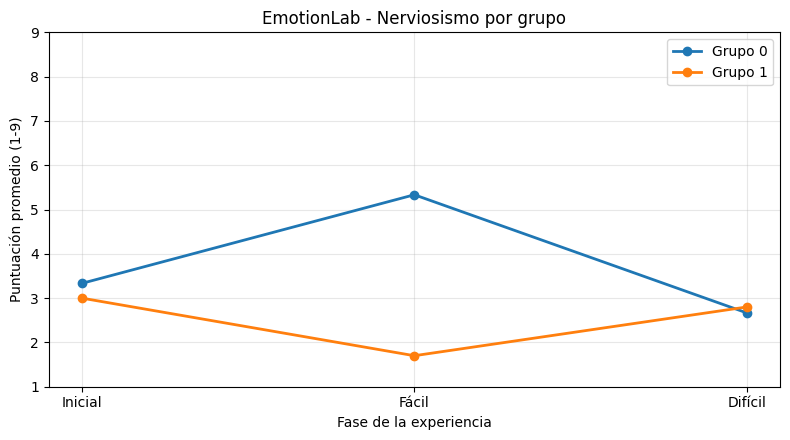

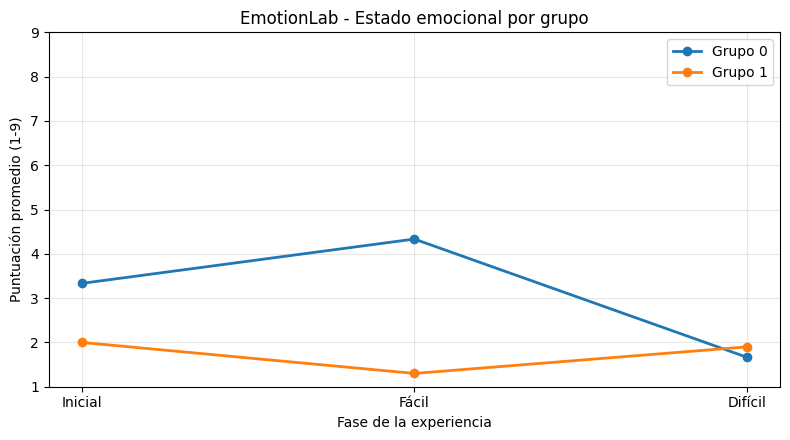

Evolución emocional por grupo visualizada.


In [1002]:

# =========================================================
# 5.8.3 - EVOLUCIÓN EMOCIONAL POR GRUPO
# =========================================================


# Definimos las tres fases de EmotionLab
# y sus respectivas variables de evaluación.

fases_58 = ["Inicial", "Fácil", "Difícil"]

indicadores_58 = {
    "Nerviosismo": [
        "nerviosismo_pre",
        "nerviosismo_facil",
        "nerviosismo_dificil"
    ],
    "Estado emocional": [
        "estado_pre",
        "estado_facil",
        "estado_dificil"
    ]
}

# Creamos un gráfico independiente por indicador.

for indicador, columnas in indicadores_58.items():

    plt.figure(figsize=(8, 4.5))

    for grupo, promedios in medias_grupos_58.iterrows():

        plt.plot(
            fases_58,
            promedios[columnas].to_numpy(dtype=float),
            marker="o",
            linewidth=2,
            label=grupo
        )

    plt.title(f"EmotionLab - {indicador} por grupo")
    plt.xlabel("Fase de la experiencia")
    plt.ylabel("Puntuación promedio (1-9)")
    plt.ylim(1, 9)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Evolución emocional por grupo visualizada.")


VARIANZA EXPLICADA POR PCA
Componente 1: 33.05%
Componente 2: 21.89%
Total explicado: 54.94%


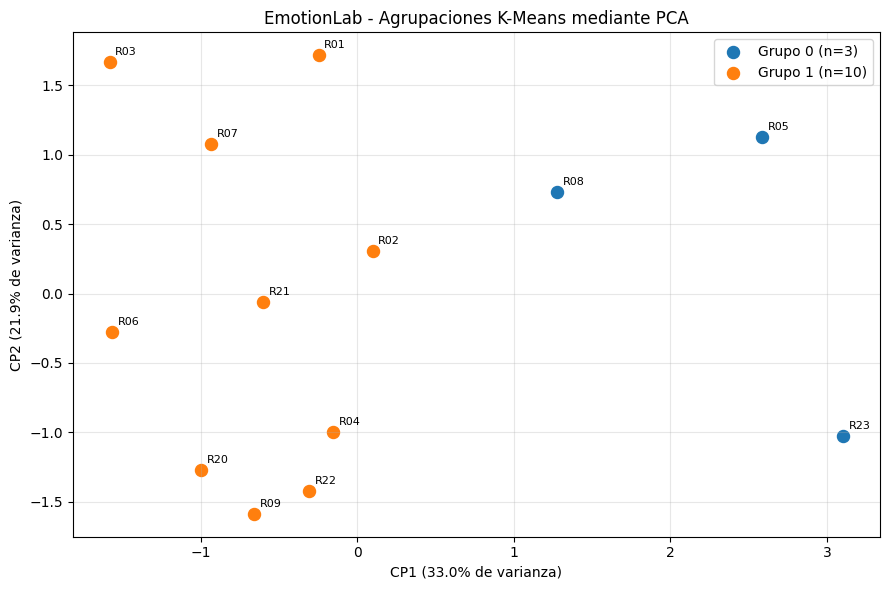

In [1003]:

# =========================================================
# 5.8.4 - VISUALIZACIÓN DE AGRUPACIONES CON PCA
# =========================================================


# Aplicamos PCA sobre las seis variables escaladas.
# Esta transformación es solo para visualización:
# no modifica el entrenamiento de K-Means.

pca_58 = PCA(n_components=2)

coordenadas_pca_58 = pca_58.fit_transform(
    X_real_escalado_ml[variables_ml]
)

# Conservamos los identificadores de presentación
# y las agrupaciones previamente obtenidas.

resultados_pca_58 = pd.DataFrame(
    coordenadas_pca_58,
    columns=["CP1", "CP2"],
    index=X_real_ml.index
)

resultados_pca_58["Registro"] = perfiles_ml_58["Registro"]
resultados_pca_58["Grupo"] = perfiles_ml_58["Grupo"]

# Calculamos cuánta variabilidad explican
# los componentes principales.

varianza_pca_58 = pca_58.explained_variance_ratio_

print("VARIANZA EXPLICADA POR PCA")
print(f"Componente 1: {varianza_pca_58[0]:.2%}")
print(f"Componente 2: {varianza_pca_58[1]:.2%}")
print(f"Total explicado: {varianza_pca_58.sum():.2%}")

# Visualizamos los estudiantes según sus grupos.

plt.figure(figsize=(9, 6))

for grupo, datos in resultados_pca_58.groupby("Grupo"):

    plt.scatter(
        datos["CP1"],
        datos["CP2"],
        s=75,
        label=f"{grupo} (n={len(datos)})"
    )

    # Mostramos un identificador abreviado para
    # reconocer los registros sin exponer sus IDs.

    for _, fila in datos.iterrows():

        plt.annotate(
            fila["Registro"].replace("Registro ", "R"),
            (fila["CP1"], fila["CP2"]),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.title("EmotionLab - Agrupaciones K-Means mediante PCA")
plt.xlabel(f"CP1 ({varianza_pca_58[0]:.1%} de varianza)")
plt.ylabel(f"CP2 ({varianza_pca_58[1]:.1%} de varianza)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [1004]:

# =========================================================
# 5.8.5 - COHESIÓN INDIVIDUAL DE LOS GRUPOS
# =========================================================


# Calculamos Silhouette para cada estudiante
# utilizando las seis variables estandarizadas.

silhouette_individual_58 = silhouette_samples(
    X_real_escalado_ml[variables_ml],
    etiquetas_58
)

# Organizamos los resultados por participante.

cohesion_estudiantes_58 = perfiles_ml_58[
    ["Registro", "Grupo"]
].copy()

cohesion_estudiantes_58["Silhouette individual"] = (
    silhouette_individual_58
)

# Resumimos la cohesión dentro de cada grupo.

resumen_cohesion_58 = (
    cohesion_estudiantes_58
    .groupby("Grupo")
    .agg(
        Estudiantes=("Registro", "size"),
        Silhouette_promedio=("Silhouette individual", "mean"),
        Silhouette_minimo=("Silhouette individual", "min")
    )
)

# Comprobamos la puntuación global del modelo.

silhouette_global_58 = silhouette_score(
    X_real_escalado_ml[variables_ml],
    etiquetas_58
)

print("COHESIÓN DE LAS AGRUPACIONES - EMOTIONLAB")
display(resumen_cohesion_58.round(3))

print("\nSILHOUETTE POR ESTUDIANTE")
display(
    cohesion_estudiantes_58
    .sort_values("Silhouette individual")
    .reset_index(drop=True)
    .round(3)
)

print(f"\nSilhouette global: {silhouette_global_58:.3f}")

# Verificamos que coincide con la evaluación
# realizada en las etapas anteriores.

if not np.isclose(silhouette_global_58, 0.275, atol=0.001):
    print("Advertencia: revisar diferencias con la Etapa 5.7.")

print("\nEvaluación individual completada.")


COHESIÓN DE LAS AGRUPACIONES - EMOTIONLAB


,Estudiantes,Silhouette_promedio,Silhouette_minimo
Grupo,,,
Grupo 0,3,0.212,0.129
Grupo 1,10,0.294,0.196



SILHOUETTE POR ESTUDIANTE


,Registro,Grupo,Silhouette individual
0,Registro 08,Grupo 0,0.129
1,Registro 23,Grupo 0,0.151
2,Registro 07,Grupo 1,0.196
3,Registro 01,Grupo 1,0.197
4,Registro 09,Grupo 1,0.217
5,Registro 02,Grupo 1,0.231
6,Registro 22,Grupo 1,0.312
7,Registro 04,Grupo 1,0.327
8,Registro 03,Grupo 1,0.329
9,Registro 06,Grupo 1,0.353



Silhouette global: 0.275

Evaluación individual completada.


### 5.8 — Resumen de resultados e interpretación de agrupaciones

Durante esta sección analizamos los dos grupos identificados por K-Means utilizando los 13 estudiantes reales con respuestas completas.

**Principales resultados:**

- **Grupo 0:** integrado por 3 estudiantes, presentó puntuaciones más elevadas de nerviosismo y estado emocional durante la fase fácil.
- **Grupo 1:** integrado por 10 estudiantes, presentó puntuaciones más bajas durante la fase fácil, con un ligero aumento del nerviosismo en la fase difícil.
- **Diferencias principales:** nerviosismo fácil (3,63 puntos) y estado emocional fácil (3,03 puntos).
- **PCA:** los dos componentes principales explicaron el 54,94 % de la variabilidad de las respuestas.
- **Silhouette global:** 0,275, indicando una separación relativamente débil entre las agrupaciones.

### Interpretación

Los resultados sugieren que K-Means identificó dos perfiles diferenciados principalmente por sus respuestas durante la fase fácil.

Sin embargo, las agrupaciones presentan una separación limitada y el Grupo 0 contiene solamente tres estudiantes, por lo que no podemos generalizar estos patrones a toda la población estudiantil.

### Conclusión

El análisis permitió caracterizar las agrupaciones numéricas identificadas por EmotionLab y visualizar sus diferencias entre las tres fases.

**Los grupos representan patrones exploratorios de respuestas autodeclaradas, no diagnósticos clínicos ni categorías psicológicas validadas.**

## 5.9 — Validación funcional del modelo de Machine Learning

### ¿Qué realizaremos?

Durante esta sección verificaremos el funcionamiento del modelo K-Means seleccionado, entrenado con 13 perfiles reales completos y configurado con dos agrupaciones.

Nuestro objetivo será comprobar que el modelo pueda utilizarse posteriormente para procesar las respuestas provenientes de Unity y AWS.

### Procedimiento

1. **Validación del modelo:** comprobaremos que K-Means y el escalador correspondan al entrenamiento seleccionado.
2. **Tratamiento de respuestas faltantes:** aplicaremos la mediana del mismo indicador entre las fases disponibles.
3. **Pruebas funcionales:** simularemos cuestionarios completos, parcialmente incompletos y sin información suficiente.
4. **Pruebas de robustez:** evaluaremos cuánto cambian las asignaciones cuando ocultamos temporalmente respuestas conocidas.

### Criterios de imputación

Para estimar respuestas exigiremos al menos cuatro de los seis indicadores observados y respuestas disponibles en dos fases diferentes.

Los valores estimados quedarán identificados y no reemplazarán las respuestas originales.

In [1005]:

# =========================================================
# 5.9.1 - VALIDACIÓN DEL MODELO SELECCIONADO
# =========================================================


# Recuperamos el K-Means real con dos grupos
# seleccionado provisionalmente en la Etapa 5.7.

modelo_final_ml = modelos_kmeans[("real", 2)]
columnas_modelo_ml = list(variables_ml)

# Comprobamos que tanto el modelo como el escalador
# estén entrenados y utilicen las seis variables.

check_is_fitted(modelo_final_ml)
check_is_fitted(escalador_ml)

if (
    modelo_final_ml.n_clusters != 2
    or modelo_final_ml.n_features_in_ != 6
    or list(X_real_ml.columns) != columnas_modelo_ml
):
    raise ValueError("La configuración del modelo es incorrecta.")

# Verificamos que el escalador reproduzca exactamente
# los datos utilizados durante el entrenamiento.

X_verificacion = escalador_ml.transform(
    X_real_ml[columnas_modelo_ml]
)

if not np.allclose(
    X_verificacion,
    X_real_escalado_ml[columnas_modelo_ml].to_numpy(),
    rtol=0,
    atol=1e-10
):
    raise ValueError("El escalador no coincide con el original.")

# Las asignaciones también deben ser iguales
# a las obtenidas durante la Etapa 5.3.

if not np.array_equal(
    modelo_final_ml.predict(X_verificacion),
    predicciones_kmeans[("real", 2)]
):
    raise ValueError("Las predicciones originales cambiaron.")

print("MODELO VALIDADO - EMOTIONLAB")
print("Algoritmo: K-Means")
print("Grupos:", modelo_final_ml.n_clusters)
print("Variables:", len(columnas_modelo_ml))
print("Registros de entrenamiento:", len(X_real_ml))
print("Modelo y escalador consistentes.")


MODELO VALIDADO - EMOTIONLAB
Algoritmo: K-Means
Grupos: 2
Variables: 6
Registros de entrenamiento: 13
Modelo y escalador consistentes.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [1006]:

# =========================================================
# 5.9.2 - INFERENCIA CON IMPUTACIÓN POR MEDIANA
# =========================================================

# Esta función procesa las seis respuestas emocionales.
# Si faltan datos, utiliza la mediana del mismo indicador
# entre las fases disponibles del estudiante.

def predecir_emotionlab_ml(respuestas):

    datos = {}

    # Validamos las respuestas.
    # None y NaN representan preguntas no respondidas.

    for variable in columnas_modelo_ml:

        valor = respuestas.get(variable)

        if valor is None or pd.isna(valor):
            datos[variable] = np.nan
            continue

        try:
            valor = float(valor)
        except (ValueError, TypeError):
            raise ValueError(f"Respuesta no numérica: {variable}")

        if not (
            np.isfinite(valor)
            and valor.is_integer()
            and ESCALA_MINIMA <= valor <= ESCALA_MAXIMA
        ):
            raise ValueError(f"Respuesta inválida: {variable}")

        datos[variable] = valor

    # Contamos las respuestas originales disponibles
    # y las fases en las que existe alguna respuesta.

    n_observadas = sum(
        pd.notna(valor) for valor in datos.values()
    )

    n_fases = sum(
        any(pd.notna(datos[v]) for v in columnas)
        for columnas in fases_ml
    )

    # Exigimos al menos cuatro respuestas originales
    # y participación en dos fases diferentes.

    if n_observadas < 4 or n_fases < 2:

        return {
            "estado": "informacion_insuficiente",
            "grupo": None,
            "observadas": n_observadas,
            "estimadas": [],
            "variables_procesadas": None
        }

    # Identificamos las variables que serán estimadas.

    estimadas = [
        variable for variable in columnas_modelo_ml
        if pd.isna(datos[variable])
    ]

    # Completamos los valores faltantes mediante
    # la mediana del mismo indicador entre fases.

    for columnas in indicadores_ml:

        disponibles = [
            datos[v] for v in columnas
            if pd.notna(datos[v])
        ]

        if not disponibles:
            raise ValueError(
                "No existen respuestas para uno de los indicadores."
            )

        mediana = float(np.median(disponibles))

        for variable in columnas:
            if pd.isna(datos[variable]):
                datos[variable] = mediana

    # Construimos la entrada con las seis variables
    # en el mismo orden utilizado en el entrenamiento.

    entrada = pd.DataFrame(
        [datos],
        columns=columnas_modelo_ml
    )

    # Aplicamos el escalador original.
    # Conservamos los nombres de las columnas
    # para evitar advertencias de scikit-learn.

    entrada_escalada = pd.DataFrame(
        escalador_ml.transform(entrada),
        columns=columnas_modelo_ml,
        index=entrada.index
    )

    # Realizamos la asignación de grupo con K-Means.

    grupo = int(
        modelo_final_ml.predict(entrada_escalada)[0]
    )

    # Devolvemos el grupo y la información necesaria
    # para distinguir respuestas reales y estimadas.

    return {
        "estado": (
            "calculado_con_estimacion"
            if estimadas else "calculado_sin_estimacion"
        ),
        "grupo": grupo,
        "observadas": n_observadas,
        "estimadas": estimadas,
        "variables_procesadas": datos
    }


print("Función de inferencia preparada correctamente.")


Función de inferencia preparada correctamente.


In [1007]:

# =========================================================
# 5.9.3 - PRUEBAS FUNCIONALES DE INFERENCIA
# =========================================================

# Tomamos un perfil completo como referencia
# sin mostrar el identificador original.

perfil = X_real_ml.iloc[0].to_dict()

# Construimos diferentes situaciones de prueba.

casos_prueba = {
    "Completo": perfil.copy(),

    "Falta una pregunta": {
        **perfil,
        "nerviosismo_facil": None
    },

    "Falta formulario difícil": {
        **perfil,
        "nerviosismo_dificil": None,
        "estado_dificil": None
    },

    "Solo fase inicial": {
        variable: (
            perfil[variable]
            if variable in fases_ml[0] else None
        )
        for variable in columnas_modelo_ml
    },

    "Sin respuestas": {
        variable: None
        for variable in columnas_modelo_ml
    }
}

resultados_pruebas_59 = []

for nombre, respuestas in casos_prueba.items():

    resultado = predecir_emotionlab_ml(respuestas)

    resultados_pruebas_59.append({
        "Caso": nombre,
        "Estado": resultado["estado"],
        "Observadas": resultado["observadas"],
        "Estimadas": len(resultado["estimadas"]),
        "Grupo": resultado["grupo"]
    })

print("PRUEBAS FUNCIONALES - EMOTIONLAB")

display(pd.DataFrame(resultados_pruebas_59))

print("\nPruebas de inferencia completadas.")


PRUEBAS FUNCIONALES - EMOTIONLAB


,Caso,Estado,Observadas,Estimadas,Grupo
0,Completo,calculado_sin_estimacion,6,0,1.0
1,Falta una pregunta,calculado_con_estimacion,5,1,1.0
2,Falta formulario difícil,calculado_con_estimacion,4,2,1.0
3,Solo fase inicial,informacion_insuficiente,2,0,NaN
4,Sin respuestas,informacion_insuficiente,0,0,NaN



Pruebas de inferencia completadas.


In [1008]:

# =========================================================
# 5.9.4 - ROBUSTEZ DE INFERENCIA ANTE VALORES FALTANTES
# =========================================================

pruebas_robustez_59 = []

# Probamos los 13 estudiantes completos.
# Ocultamos una pregunta o una fase completa,
# conservando el modelo K-Means fijo.

for _, fila in X_real_ml.iterrows():

    original = fila[columnas_modelo_ml].to_dict()

    # Predicción con las seis respuestas observadas.

    referencia = predecir_emotionlab_ml(original)
    grupo_original = referencia["grupo"]

    situaciones = {
        "Pregunta individual": [[v] for v in columnas_modelo_ml],
        "Formulario completo": fases_ml
    }

    for tipo, grupos_variables in situaciones.items():

        for columnas_ocultas in grupos_variables:

            simulado = original.copy()

            for variable in columnas_ocultas:
                simulado[variable] = None

            resultado = predecir_emotionlab_ml(simulado)

            if resultado["grupo"] is None:
                raise ValueError("Un caso de prueba no pudo evaluarse.")

            pruebas_robustez_59.append({
                "Tipo": tipo,
                "Coincide": resultado["grupo"] == grupo_original,
                "Cambió": resultado["grupo"] != grupo_original
            })

# Resumimos el acuerdo con las asignaciones originales.

robustez_59 = pd.DataFrame(pruebas_robustez_59)

resumen_robustez_59 = (
    robustez_59.groupby("Tipo")
    .agg(
        Pruebas=("Coincide", "size"),
        Asignaciones_iguales=("Coincide", "sum"),
        Cambios_de_grupo=("Cambió", "sum")
    )
)

resumen_robustez_59["Concordancia (%)"] = (
    resumen_robustez_59["Asignaciones_iguales"]
    / resumen_robustez_59["Pruebas"] * 100
)

print("ROBUSTEZ ANTE RESPUESTAS FALTANTES")
display(resumen_robustez_59.round(2))

print("\nLa concordancia mide estabilidad de asignación,")
print("no exactitud clínica ni generalización.")


ROBUSTEZ ANTE RESPUESTAS FALTANTES


,Pruebas,Asignaciones_iguales,Cambios_de_grupo,Concordancia (%)
Tipo,,,,
Formulario completo,39,37,2,94.87
Pregunta individual,78,76,2,97.44



La concordancia mide estabilidad de asignación,
no exactitud clínica ni generalización.


### 5.9.4 — Resultados de robustez ante respuestas faltantes

Durante esta sección evaluamos cómo cambia la asignación de grupos cuando estimamos respuestas faltantes mediante la mediana.

Utilizamos los 13 estudiantes reales completos y simulamos dos situaciones:

- **Pregunta individual faltante:** 76 de 78 asignaciones se mantuvieron iguales, obteniendo una concordancia del 97,44 %.
- **Formulario completo faltante:** 37 de 39 asignaciones se mantuvieron iguales, alcanzando una concordancia del 94,87 %.

Los resultados indican que el modelo K-Means conserva mayoritariamente sus asignaciones cuando se aplica la imputación por mediana en estas simulaciones.

Sin embargo, la estabilidad no garantiza que las respuestas estimadas sean exactas ni que el modelo generalice correctamente a nuevos estudiantes.

**En conclusión**, la imputación por mediana presenta resultados favorables como mecanismo experimental para procesar cuestionarios incompletos, aunque debe conservarse la identificación de los valores estimados y mantenerse una interpretación cautelosa de las agrupaciones.

## 5.10 — Conclusión de la Etapa 5: Machine Learning

Durante esta etapa desarrollamos, entrenamos y evaluamos tres algoritmos de aprendizaje no supervisado para identificar patrones de similitud entre las respuestas emocionales de los estudiantes de EmotionLab.

Utilizamos seis variables correspondientes al nerviosismo y estado emocional registrados durante las fases inicial, fácil y difícil.

## 1. Preparación de datos

Trabajamos con un dataset híbrido de **600 registros**, compuesto por:

- **27 registros reales:** respuestas obtenidas de estudiantes.
- **573 registros sintéticos:** datos generados artificialmente a partir de participantes reales.
- **349 registros completos:** 13 reales y 336 sintéticos.
- **418 registros aptos tras imputación:** 15 reales y 403 sintéticos.

Evaluamos el entrenamiento con datos reales y tres configuraciones híbridas, controlando o aproximando la participación sintética del 10 %, 25 % y 50 % según las capacidades de cada algoritmo.

## 2. Entrenamiento y comparación de algoritmos

Entrenamos y comparamos tres métodos:

- **K-Means:** agrupamiento mediante centroides.
- **Clustering jerárquico:** agrupamiento mediante relaciones de semejanza.
- **Gaussian Mixture Models (GMM):** agrupamiento probabilístico con regularización.

Entre las configuraciones de dos grupos, obtuvimos:

| Modelo | Silhouette |
|---|---:|
| K-Means real | 0,275 |
| Clustering jerárquico real | 0,275 |
| GMM híbrido 10 % | 0,275 |
| GMM real | 0,260 |

Los tres primeros modelos identificaron agrupaciones equivalentes sobre los 13 estudiantes reales, con un acuerdo ARI de 1,000.

Sin embargo, las puntuaciones de Silhouette indican una **separación relativamente débil**, por lo que debemos interpretar los grupos de manera exploratoria.

## 3. Entrenamiento híbrido y estabilidad

Los experimentos demostraron que incorporar registros sintéticos puede modificar las agrupaciones, pero no produjo mejoras consistentes en todos los algoritmos.

Además, comprobamos que los 573 registros sintéticos proceden de 22 participantes reales, por lo que no representan observaciones independientes.

Durante las pruebas de exclusión individual, K-Means real con dos grupos mantuvo un ARI de 1,000, mostrando estabilidad frente a la retirada de un participante en las condiciones evaluadas.

Esta estabilidad no demuestra que el modelo generalice correctamente a estudiantes nuevos.

## 4. Imputación por mediana

Implementamos un procedimiento experimental para estimar respuestas faltantes utilizando la mediana del mismo indicador entre las fases disponibles.

Los resultados fueron:

- **Error absoluto medio:** 1,41 puntos.
- **Error máximo observado:** 7 puntos.
- **Concordancia al omitir una pregunta:** 97,44 %.
- **Concordancia al omitir un formulario completo:** 94,87 %.

La imputación permitió incorporar registros adicionales, pero no mejoró consistentemente el entrenamiento de los algoritmos.

Por ello, mantendremos las respuestas completas como base del modelo seleccionado y utilizaremos la estimación por mediana como mecanismo experimental para procesar cuestionarios incompletos.

## 5. Selección e interpretación del modelo

Seleccionamos provisionalmente **K-Means con dos grupos**, entrenado con los 13 estudiantes reales completos.

Esta decisión considera:

- **Calidad:** Silhouette de 0,275.
- **Estabilidad:** ARI de 1,000 en las pruebas de exclusión individual.
- **Simplicidad:** entrenamiento e inferencia mediante una estructura reproducible.
- **Integración:** capacidad de asignar nuevos perfiles utilizando `predict()`.

El modelo identificó dos agrupaciones:

- **Grupo 0:** 3 estudiantes, con mayores puntuaciones durante la fase fácil.
- **Grupo 1:** 10 estudiantes, con menores puntuaciones durante la fase fácil.

Las principales diferencias entre ambos grupos se observaron en nerviosismo fácil (3,63 puntos) y estado emocional fácil (3,03 puntos).

Mediante PCA representamos los perfiles en dos dimensiones, conservando el **54,94 % de la variabilidad** de las seis características.

Estos grupos describen patrones numéricos, no categorías clínicas de estrés.

## 6. Validación funcional

También comprobamos que el modelo y su escalador podían procesar las seis variables emocionales y generar asignaciones de grupo.

Simulamos cuestionarios completos, preguntas faltantes y formularios incompletos, verificando que la estimación mediante mediana permite generar predicciones cuando se cumplen nuestros criterios mínimos de información.

Los registros insuficientes permanecen sin asignación de grupo.

Estas pruebas demuestran funcionamiento técnico en los casos simulados, pero no constituyen validación clínica ni evaluación independiente.

## 7. Limitaciones y trabajo pendiente

Identificamos las siguientes limitaciones:

- **Muestra reducida:** solamente 13 estudiantes reales completos para el entrenamiento principal.
- **Separación limitada:** los grupos presentan un Silhouette relativamente bajo.
- **Dependencia sintética:** los registros artificiales derivan de participantes existentes.
- **Imputación imperfecta:** las respuestas estimadas pueden diferir considerablemente de las originales.
- **Validación pendiente:** necesitamos incorporar nuevos estudiantes reales para evaluar el comportamiento del modelo con información independiente.

También queda pendiente comprobar la inferencia completa con los JSON generados por Unity y la comunicación con AWS.

## Conclusión general

Durante la Etapa 5 desarrollamos una comparación experimental entre tres algoritmos de aprendizaje no supervisado y seleccionamos provisionalmente K-Means con dos grupos como candidato para EmotionLab.

La comparación de entrenamientos reales, híbridos e imputados permitió identificar ventajas y limitaciones de cada procedimiento, evitando asumir que una mayor cantidad de datos artificiales produce necesariamente mejores resultados.

**En conclusión**, contamos con un modelo experimental capaz de identificar agrupaciones numéricas entre las respuestas emocionales y de procesar cuestionarios incompletos mediante un procedimiento controlado de estimación.

La siguiente etapa permitirá continuar el desarrollo técnico del modelo seleccionado, manteniendo su interpretación exploratoria y la necesidad de validarlo con nuevos participantes reales.

# Etapa 6 — Empaquetado y preparación del modelo de EmotionLab

## Objetivo

Durante esta etapa prepararemos el modelo de Machine Learning seleccionado para que pueda ejecutarse fuera de Google Colab y posteriormente integrarse con Unity y AWS.

Utilizaremos **K-Means con dos grupos**, entrenado con los 13 estudiantes reales completos y las seis variables emocionales correspondientes a las fases inicial, fácil y difícil.

### 1. Preparación del modelo

Comprobaremos que el modelo conserve sus parámetros originales, el escalador y el orden correcto de las variables utilizadas durante el entrenamiento.

No volveremos a entrenarlo ni modificaremos sus agrupaciones.

### 2. Empaquetado

Prepararemos los archivos necesarios para ejecutar el modelo en otro entorno:

- **Modelo K-Means:** permitirá asignar nuevas respuestas a los grupos identificados.
- **StandardScaler:** aplicará la misma transformación utilizada durante el entrenamiento.
- **Configuración:** conservará las seis variables, sus escalas y las reglas de validación.
- **Módulo de inferencia:** recibirá respuestas, comprobará su integridad y generará las asignaciones.

### 3. Tratamiento de respuestas incompletas

Conservaremos el procedimiento de imputación por mediana desarrollado en la Etapa 5.

Cuando existan respuestas faltantes, el sistema podrá estimarlas utilizando las respuestas disponibles del mismo indicador en las otras fases, siempre que se cumplan los requisitos mínimos.

Las respuestas originales permanecerán diferenciadas de las estimadas.

### 4. Pruebas de funcionamiento

Comprobaremos que los archivos exportados puedan cargarse nuevamente y reproduzcan las predicciones obtenidas en Colab.

También verificaremos el procesamiento de respuestas completas, parcialmente incompletas e insuficientes.


### 6.1 — Verificación del modelo y sus componentes

En este apartado comprobaremos que K-Means y StandardScaler se encuentren correctamente entrenados y que utilicen las mismas seis variables de EmotionLab.

También verificaremos que las predicciones originales se mantengan y que el procedimiento de imputación continúe funcionando con datos completos e incompletos.

Estas comprobaciones permitirán preparar el modelo para su exportación, evitando incompatibilidades entre los componentes utilizados durante el entrenamiento y la futura inferencia.

In [1009]:

# =========================================================
# 6.1.1 - VERIFICACIÓN DEL MODELO Y ESCALADOR
# =========================================================



# Recuperamos el modelo seleccionado en la Etapa 5.
# No volvemos a entrenarlo.

modelo_final_ml = modelos_kmeans[("real", 2)]
columnas_modelo_ml = list(variables_ml)

# Comprobamos que el modelo y el escalador
# contengan los parámetros aprendidos.

check_is_fitted(modelo_final_ml)
check_is_fitted(escalador_ml)

# Validamos la configuración original.

if modelo_final_ml.n_clusters != 2:
    raise ValueError("K-Means no contiene dos grupos.")

if (
    modelo_final_ml.n_features_in_ != 6
    or escalador_ml.n_features_in_ != 6
):
    raise ValueError("La cantidad de variables no coincide.")

# Si los componentes conservaron nombres de columnas,
# comprobamos también su orden exacto.

for componente in [modelo_final_ml, escalador_ml]:

    if hasattr(componente, "feature_names_in_"):

        if list(componente.feature_names_in_) != columnas_modelo_ml:
            raise ValueError(
                "El orden de las variables es incorrecto."
            )

print("MODELO Y ESCALADOR VERIFICADOS")
print("Algoritmo: K-Means")
print("Grupos:", modelo_final_ml.n_clusters)
print("Variables:", len(columnas_modelo_ml))
print("Estado: componentes entrenados y compatibles.")


MODELO Y ESCALADOR VERIFICADOS
Algoritmo: K-Means
Grupos: 2
Variables: 6
Estado: componentes entrenados y compatibles.


In [1010]:

# =========================================================
# 6.1.2 - CONSISTENCIA DE LAS PREDICCIONES
# =========================================================


# Comprobamos que las filas originales mantengan
# el mismo orden que durante el entrenamiento.

if not X_real_ml.index.equals(X_real_escalado_ml.index):
    raise ValueError("Los registros perdieron su orden.")

# Reproducimos el escalado con los 13 estudiantes
# reales completos.

X_verificacion = pd.DataFrame(
    escalador_ml.transform(X_real_ml[columnas_modelo_ml]),
    columns=columnas_modelo_ml,
    index=X_real_ml.index
)

# Verificamos que coincide con los valores utilizados
# originalmente para entrenar K-Means.

if not np.allclose(
    X_verificacion.to_numpy(),
    X_real_escalado_ml[columnas_modelo_ml].to_numpy(),
    rtol=0,
    atol=1e-10
):
    raise ValueError("El escalado original no coincide.")

# Generamos nuevamente las asignaciones y las
# comparamos con las guardadas en la Etapa 5.

predicciones_verificadas = modelo_final_ml.predict(
    X_verificacion
)

if not np.array_equal(
    predicciones_verificadas,
    predicciones_kmeans[("real", 2)]
):
    raise ValueError("Las agrupaciones originales cambiaron.")

# Calculamos las métricas directamente sobre
# los resultados verificados.

silhouette_final = silhouette_score(
    X_verificacion, predicciones_verificadas
)

davies_final = davies_bouldin_score(
    X_verificacion, predicciones_verificadas
)

print("CONSISTENCIA DEL MODELO - EMOTIONLAB")
print("Registros verificados:", len(X_verificacion))
print("Silhouette:", round(silhouette_final, 3))
print("Davies-Bouldin:", round(davies_final, 3))

print("\nDistribución de estudiantes:")
display(
    pd.Series(predicciones_verificadas)
    .value_counts()
    .sort_index()
    .to_frame("Estudiantes")
)

print("\nLas predicciones coinciden con el entrenamiento.")


CONSISTENCIA DEL MODELO - EMOTIONLAB
Registros verificados: 13
Silhouette: 0.275
Davies-Bouldin: 1.227

Distribución de estudiantes:


,Estudiantes
0,3
1,10



Las predicciones coinciden con el entrenamiento.


In [1011]:

# =========================================================
# 6.1.3 - VERIFICACIÓN FUNCIONAL DE LA IMPUTACIÓN
# =========================================================

# Comprobamos que la función de inferencia
# desarrollada en la Etapa 5 esté disponible.

if "predecir_emotionlab_ml" not in globals():
    raise ValueError(
        "Ejecuta primero el apartado 5.9.2."
    )

# Seleccionamos un perfil real completo.
# No modificamos sus respuestas originales.

perfil_completo = X_real_ml.iloc[0].to_dict()

# Caso 1: todas las respuestas disponibles.

resultado_completo = predecir_emotionlab_ml(
    perfil_completo
)

# Caso 2: faltan las dos respuestas de la fase difícil.
# Usamos None y NaN para comprobar ambos formatos.

perfil_incompleto = perfil_completo.copy()
perfil_incompleto["nerviosismo_dificil"] = None
perfil_incompleto["estado_dificil"] = np.nan

resultado_estimado = predecir_emotionlab_ml(
    perfil_incompleto
)

# Caso 3: todas las respuestas están ausentes.

perfil_vacio = {
    variable: None
    for variable in columnas_modelo_ml
}

resultado_insuficiente = predecir_emotionlab_ml(
    perfil_vacio
)

# Comprobamos que la función devuelva
# los tres estados esperados.

if resultado_completo["estado"] != "calculado_sin_estimacion":
    raise ValueError("Falló la inferencia completa.")

if (
    resultado_estimado["estado"] != "calculado_con_estimacion"
    or len(resultado_estimado["estimadas"]) != 2
):
    raise ValueError("Falló la imputación por mediana.")

if (
    resultado_insuficiente["estado"] != "informacion_insuficiente"
    or resultado_insuficiente["grupo"] is not None
):
    raise ValueError("Falló el control de datos insuficientes.")

# Mostramos los resultados funcionales.

resumen_pruebas_61 = pd.DataFrame([
    {
        "Prueba": "Respuestas completas",
        "Estado": resultado_completo["estado"],
        "Grupo": resultado_completo["grupo"],
        "Estimadas": len(resultado_completo["estimadas"])
    },
    {
        "Prueba": "Fase difícil faltante",
        "Estado": resultado_estimado["estado"],
        "Grupo": resultado_estimado["grupo"],
        "Estimadas": len(resultado_estimado["estimadas"])
    },
    {
        "Prueba": "Sin respuestas",
        "Estado": resultado_insuficiente["estado"],
        "Grupo": resultado_insuficiente["grupo"],
        "Estimadas": len(resultado_insuficiente["estimadas"])
    }
])

print("PRUEBAS FUNCIONALES - EMOTIONLAB")
display(resumen_pruebas_61)

print("\nModelo e imputación verificados correctamente.")


PRUEBAS FUNCIONALES - EMOTIONLAB


,Prueba,Estado,Grupo,Estimadas
0,Respuestas completas,calculado_sin_estimacion,1.0,0
1,Fase difícil faltante,calculado_con_estimacion,1.0,2
2,Sin respuestas,informacion_insuficiente,NaN,0



Modelo e imputación verificados correctamente.


### 6.1.4 — Resultados y conclusión de la verificación del modelo

Durante este apartado verificamos el funcionamiento y la consistencia del modelo K-Means seleccionado para EmotionLab, junto con su escalador y el procedimiento de imputación por mediana.

Las comprobaciones confirmaron que el modelo conserva su configuración original de dos grupos y seis variables, sin necesidad de realizar un nuevo entrenamiento.

Al reproducir las predicciones de los 13 estudiantes reales completos, obtuvimos un índice Silhouette de **0,275** y un índice Davies-Bouldin de **1,227**, manteniendo la distribución original de tres estudiantes en el grupo 0 y diez en el grupo 1.

También verificamos tres escenarios de inferencia:

- **Respuestas completas:** el sistema asignó correctamente un grupo sin estimar valores.
- **Fase difícil incompleta:** el sistema estimó las dos respuestas faltantes y generó una asignación de grupo.
- **Ausencia total de respuestas:** el sistema identificó información insuficiente y evitó generar una asignación.

Estos resultados confirman que los componentes mantienen su consistencia y que la función de inferencia puede procesar los casos funcionales evaluados.

**En conclusión**, el modelo experimental de EmotionLab se encuentra preparado para avanzar a la etapa de exportación y almacenamiento de sus componentes. Las pruebas realizadas verifican su funcionamiento técnico, aunque no constituyen una validación de su precisión con estudiantes nuevos ni de su capacidad para medir clínicamente el estrés.

### 6.2 — Almacenamiento y exportación del modelo

En este apartado prepararemos los archivos necesarios para conservar el modelo de Machine Learning desarrollado durante la Etapa 5 de EmotionLab.

Exportaremos el modelo K-Means seleccionado y su escalador StandardScaler utilizando Joblib, una herramienta que permite serializar objetos de Python y recuperarlos posteriormente.

Además, registraremos los metadatos técnicos, incluyendo las seis variables utilizadas durante el entrenamiento, la configuración de agrupamiento y las versiones de las bibliotecas principales.

Por último, verificaremos la integridad de los archivos generados y comprobaremos que, al recuperar el modelo, sus predicciones coincidan con los resultados originales.

**El objetivo es disponer de una versión identificable, reutilizable y verificable del modelo**, preparada para incorporar posteriormente las reglas de imputación y la integración con AWS.

In [1012]:

# =========================================================
# 6.2.1 - ALMACENAMIENTO DEL MODELO Y ESCALADOR
# =========================================================

# Recuperamos los componentes verificados en el 6.1.
# No realizamos un nuevo entrenamiento.

modelo_exportar = modelo_final_ml
escalador_exportar = escalador_ml
variables_exportar = list(columnas_modelo_ml)

# ---------------------------------------------------------
# 1. VERIFICACIÓN DE COMPONENTES
# ---------------------------------------------------------

check_is_fitted(modelo_exportar)
check_is_fitted(escalador_exportar)

if modelo_exportar.n_clusters != 2:
    raise ValueError("El modelo debe tener dos grupos.")

if len(variables_exportar) != 6:
    raise ValueError("Se esperaban seis variables.")

if (
    modelo_exportar.n_features_in_ != 6
    or escalador_exportar.n_features_in_ != 6
):
    raise ValueError("Cantidad de variables incompatible.")

# Comprobamos los nombres originales de las variables.

for componente in [modelo_exportar, escalador_exportar]:

    if hasattr(componente, "feature_names_in_"):

        if list(componente.feature_names_in_) != variables_exportar:
            raise ValueError("El orden de las variables no coincide.")

# ---------------------------------------------------------
# 2. PREPARACIÓN DEL DIRECTORIO
# ---------------------------------------------------------

# Esta carpeta almacenará los componentes del modelo
# mientras desarrollamos la Etapa 6.

carpeta_modelo = Path("emotionlab_modelo_v1")

carpeta_modelo.mkdir(
    parents=True,
    exist_ok=True
)

ruta_modelo = carpeta_modelo / "modelo_kmeans_v1.joblib"
ruta_escalador = carpeta_modelo / "escalador_v1.joblib"
ruta_metadatos = carpeta_modelo / "metadatos_v1.json"

# ---------------------------------------------------------
# 3. ALMACENAMIENTO DE COMPONENTES
# ---------------------------------------------------------

joblib.dump(
    modelo_exportar,
    ruta_modelo,
    compress=3
)

joblib.dump(
    escalador_exportar,
    ruta_escalador,
    compress=3
)

# ---------------------------------------------------------
# 4. REGISTRO DE METADATOS
# ---------------------------------------------------------

# Registramos únicamente información técnica.
# No incluimos datos personales de estudiantes.

metadatos_modelo = {
    "proyecto": "EmotionLab",
    "version_modelo": "1.0.0-experimental",
    "algoritmo": "KMeans",
    "numero_grupos": int(modelo_exportar.n_clusters),
    "origen_entrenamiento": "reales_completos",
    "registros_entrenamiento": int(len(X_real_ml)),
    "numero_variables": len(variables_exportar),
    "variables": variables_exportar,
    "escala_respuestas": {
        "minimo": 1,
        "maximo": 9
    },
    "preprocesamiento": "StandardScaler",
    "archivos": {
        "modelo": ruta_modelo.name,
        "escalador": ruta_escalador.name
    },
    "versiones": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__
    }
}

ruta_metadatos.write_text(
    json.dumps(
        metadatos_modelo,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 5. CONFIRMACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - ALMACENAMIENTO DEL MODELO")
print("Modelo:", ruta_modelo)
print("Escalador:", ruta_escalador)
print("Metadatos:", ruta_metadatos)

print("\nComponentes almacenados correctamente.")
print("No se ha generado ningún ZIP definitivo.")


EMOTIONLAB - ALMACENAMIENTO DEL MODELO
Modelo: emotionlab_modelo_v1/modelo_kmeans_v1.joblib
Escalador: emotionlab_modelo_v1/escalador_v1.joblib
Metadatos: emotionlab_modelo_v1/metadatos_v1.json

Componentes almacenados correctamente.
No se ha generado ningún ZIP definitivo.


In [1013]:

# =========================================================
# 6.2.2 - VERIFICACIÓN DE INTEGRIDAD SHA-256
# =========================================================

# ---------------------------------------------------------
# 1. FUNCIÓN PARA CALCULAR HASHES
# ---------------------------------------------------------

def calcular_sha256(ruta_archivo):

    resumen = hashlib.sha256()

    with open(ruta_archivo, "rb") as archivo:

        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            resumen.update(bloque)

    return resumen.hexdigest()


# ---------------------------------------------------------
# 2. IDENTIFICAMOS LOS ARCHIVOS DEL MODELO
# ---------------------------------------------------------

archivos_verificar = [
    ruta_modelo,
    ruta_escalador,
    ruta_metadatos
]

# Comprobamos que todos los archivos existan.

for archivo in archivos_verificar:

    if not archivo.is_file():
        raise FileNotFoundError(
            f"No se encontró el archivo: {archivo}"
        )

# ---------------------------------------------------------
# 3. GENERAMOS EL MANIFIESTO DE INTEGRIDAD
# ---------------------------------------------------------

manifest_integridad = {
    archivo.name: calcular_sha256(archivo)
    for archivo in archivos_verificar
}

ruta_manifest = (
    carpeta_modelo / "manifest_sha256_v1.json"
)

ruta_manifest.write_text(
    json.dumps(
        manifest_integridad,
        indent=4
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

tabla_integridad = pd.DataFrame([
    {
        "Archivo": nombre,
        "SHA-256": resumen
    }
    for nombre, resumen in manifest_integridad.items()
])

print("EMOTIONLAB - INTEGRIDAD DE COMPONENTES")
display(tabla_integridad)

print("\nManifiesto de integridad almacenado correctamente.")


EMOTIONLAB - INTEGRIDAD DE COMPONENTES


,Archivo,SHA-256
0,modelo_kmeans_v1.joblib,c23a1864fb109f26a77b72e6836ac99b54cd84dee95890...
1,escalador_v1.joblib,d369fa9b0ff2855465dd4a402efe9a5f0ae003dc6ddeea...
2,metadatos_v1.json,383621f5b6dcb663e6fe400e4ee2a0721c73f5e663b01f...



Manifiesto de integridad almacenado correctamente.


In [1014]:

# =========================================================
# 6.2.3 - RECUPERACIÓN Y VERIFICACIÓN DEL MODELO
# =========================================================

# ---------------------------------------------------------
# 1. CARGAMOS METADATOS Y MANIFIESTO
# ---------------------------------------------------------

with open(ruta_metadatos, "r", encoding="utf-8") as archivo:
    metadatos_recuperados = json.load(archivo)

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_recuperado = json.load(archivo)

# ---------------------------------------------------------
# 2. VERIFICAMOS LA INTEGRIDAD
# ---------------------------------------------------------

for ruta in [ruta_modelo, ruta_escalador, ruta_metadatos]:

    if calcular_sha256(ruta) != manifest_recuperado[ruta.name]:
        raise ValueError(
            f"Error de integridad: {ruta.name}"
        )

# ---------------------------------------------------------
# 3. COMPROBAMOS LAS VERSIONES DEL ENTORNO
# ---------------------------------------------------------

versiones_actuales = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__
}

if versiones_actuales != metadatos_recuperados["versiones"]:
    raise ValueError(
        "El entorno actual es diferente al de exportación."
    )

# ---------------------------------------------------------
# 4. RECUPERAMOS EL MODELO Y ESCALADOR
# ---------------------------------------------------------

# Solo debemos cargar archivos confiables
# generados y conservados por nuestro proyecto.

modelo_recuperado = joblib.load(ruta_modelo)
escalador_recuperado = joblib.load(ruta_escalador)

check_is_fitted(modelo_recuperado)
check_is_fitted(escalador_recuperado)

# ---------------------------------------------------------
# 5. COMPROBAMOS LAS PREDICCIONES
# ---------------------------------------------------------

variables_recuperadas = metadatos_recuperados["variables"]

X_recuperado = pd.DataFrame(
    escalador_recuperado.transform(
        X_real_ml[variables_recuperadas]
    ),
    columns=variables_recuperadas,
    index=X_real_ml.index
)

predicciones_recuperadas = modelo_recuperado.predict(
    X_recuperado
)

# Comparamos con las asignaciones originales
# almacenadas durante la Etapa 5.

predicciones_originales = np.asarray(
    predicciones_kmeans[("real", 2)]
)

if not np.array_equal(
    predicciones_recuperadas,
    predicciones_originales
):
    raise ValueError(
        "Las predicciones recuperadas no coinciden."
    )

# Comprobamos también la transformación original.

if not np.allclose(
    X_recuperado.to_numpy(),
    X_real_escalado_ml[variables_recuperadas].to_numpy(),
    atol=1e-10,
    rtol=0
):
    raise ValueError(
        "El escalador recuperado generó resultados distintos."
    )

# ---------------------------------------------------------
# 6. RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - RECUPERACIÓN DEL MODELO")
print("Integridad de archivos: correcta")
print("Modelo y escalador: recuperados")
print("Registros verificados:", len(predicciones_recuperadas))
print("Coincidencia de predicciones: 100 %")
print("Coincidencia del escalado: correcta")


EMOTIONLAB - RECUPERACIÓN DEL MODELO
Integridad de archivos: correcta
Modelo y escalador: recuperados
Registros verificados: 13
Coincidencia de predicciones: 100 %
Coincidencia del escalado: correcta


In [1015]:

# =========================================================
# 6.2.4 - REVISIÓN DE ARCHIVOS ALMACENADOS
# =========================================================

# Objetivo:
# Confirmar que todos los componentes necesarios
# del apartado 6.2 están presentes y son legibles.
#
# No creamos ni descargamos el paquete definitivo.
# Esa operación corresponde al apartado 6.6.

# ---------------------------------------------------------
# 1. ARCHIVOS ESPERADOS
# ---------------------------------------------------------

archivos_esperados = [
    ruta_modelo,
    ruta_escalador,
    ruta_metadatos,
    ruta_manifest
]

# ---------------------------------------------------------
# 2. VERIFICAMOS SU EXISTENCIA Y TAMAÑO
# ---------------------------------------------------------

registros_archivos = []

for archivo in archivos_esperados:

    existe = archivo.is_file()

    tamaño_bytes = (
        archivo.stat().st_size if existe else 0
    )

    registros_archivos.append({
        "Archivo": archivo.name,
        "Existe": existe,
        "Tamaño (KB)": round(tamaño_bytes / 1024, 2),
        "Estado": (
            "Correcto"
            if existe and tamaño_bytes > 0
            else "Error"
        )
    })

tabla_archivos_62 = pd.DataFrame(registros_archivos)

print("EMOTIONLAB - COMPONENTES ALMACENADOS")
display(tabla_archivos_62)

# ---------------------------------------------------------
# 3. VALIDACIÓN FINAL DEL APARTADO
# ---------------------------------------------------------

if not (tabla_archivos_62["Estado"] == "Correcto").all():
    raise ValueError(
        "Faltan archivos o existen componentes vacíos."
    )

print("\nLos cuatro archivos están disponibles.")
print("Almacenamiento preliminar verificado.")
print("Paquete ZIP definitivo: pendiente para el 6.6.")


EMOTIONLAB - COMPONENTES ALMACENADOS


,Archivo,Existe,Tamaño (KB),Estado
0,modelo_kmeans_v1.joblib,True,0.77,Correcto
1,escalador_v1.joblib,True,0.67,Correcto
2,metadatos_v1.json,True,0.83,Correcto
3,manifest_sha256_v1.json,True,0.28,Correcto



Los cuatro archivos están disponibles.
Almacenamiento preliminar verificado.
Paquete ZIP definitivo: pendiente para el 6.6.


### 6.2.5 — Resultados y conclusión del almacenamiento del modelo

Durante este apartado realizamos el almacenamiento y la verificación de los componentes principales del modelo de Machine Learning de EmotionLab, con el objetivo de garantizar su conservación y posterior reutilización sin necesidad de repetir el entrenamiento.

Utilizamos **Joblib** para guardar el modelo K-Means seleccionado y su escalador StandardScaler, conservando la configuración original de dos grupos y seis variables emocionales. Además, generamos un archivo de metadatos que registra la configuración técnica del modelo y las versiones de las bibliotecas utilizadas.

Para comprobar la integridad de los componentes, implementamos un procedimiento de verificación mediante **SHA-256**, generando un manifiesto con las huellas digitales de los archivos almacenados.

Posteriormente, recuperamos el modelo y el escalador desde sus respectivos archivos y verificamos su funcionamiento utilizando los 13 registros reales completos empleados durante el entrenamiento.

Los resultados confirmaron:

- **Integridad de archivos:** verificación satisfactoria de los componentes almacenados.
- **Recuperación del modelo y escalador:** realizada correctamente.
- **Coincidencia de predicciones:** 100 % respecto de las asignaciones originales de los 13 estudiantes.
- **Consistencia del escalado:** los valores transformados coincidieron con los resultados originales.
- **Disponibilidad de archivos:** los cuatro componentes generados existen y presentan tamaños válidos.

Estos resultados demuestran que el procedimiento de almacenamiento y recuperación conserva el comportamiento del modelo en los registros evaluados. Sin embargo, esta comprobación corresponde a una prueba de consistencia técnica y no representa una validación predictiva con estudiantes nuevos.

**En conclusión**, completamos satisfactoriamente el apartado 6.2, estableciendo una base para reutilizar el modelo experimental de EmotionLab. En los siguientes apartados incorporaremos la configuración de imputación por mediana y el módulo independiente de inferencia, antes de realizar las pruebas externas y generar el paquete definitivo al finalizar la Etapa 6.

### 6.3 — Configuración de variables y reglas de imputación

En este apartado estableceremos una configuración independiente para el procesamiento de las respuestas emocionales utilizadas por el modelo de Machine Learning de EmotionLab.

La configuración incluirá las seis variables del modelo, su organización en tres fases, los dos indicadores evaluados y los criterios necesarios para procesar respuestas incompletas.

Mantendremos el procedimiento de imputación por mediana desarrollado durante la Etapa 5, utilizando las respuestas disponibles del mismo indicador en las distintas fases del estudiante.

También conservaremos los requisitos mínimos de cuatro respuestas observadas y participación en al menos dos fases para permitir la asignación de un grupo.

Finalmente, verificaremos que estas reglas coincidan con las utilizadas anteriormente y almacenaremos su configuración para incorporarla posteriormente al módulo reutilizable de inferencia.

El objetivo es garantizar que las futuras predicciones mantengan los mismos criterios de procesamiento utilizados durante el desarrollo experimental del modelo.

In [1016]:

# =========================================================
# 6.3.1 - CONFIGURACIÓN DE VARIABLES E IMPUTACIÓN
# =========================================================

# Utilizamos las bibliotecas importadas al inicio
# de la Etapa 6.

# ---------------------------------------------------------
# 1. RECUPERAMOS LOS METADATOS DEL MODELO
# ---------------------------------------------------------

with open(ruta_metadatos, "r", encoding="utf-8") as archivo:
    metadatos_63 = json.load(archivo)

variables_63 = list(metadatos_63["variables"])

# Comprobamos que utilizamos exactamente las variables
# del modelo original, en el mismo orden.

if variables_63 != list(columnas_modelo_ml):
    raise ValueError(
        "Las variables no coinciden con el modelo original."
    )


# ---------------------------------------------------------
# 2. DEFINIMOS LAS REGLAS DE INFERENCIA
# ---------------------------------------------------------

configuracion_63 = {

    "proyecto": "EmotionLab",

    "version_configuracion": "1.0.0-experimental",

    # Orden obligatorio para StandardScaler y K-Means.
    "variables": variables_63,

    # Escala utilizada por los cuestionarios de Unity.
    "escala": {
        "minimo": 1,
        "maximo": 9,
        "respuestas_originales_enteras": True
    },

    # Cada fase contiene dos indicadores.
    "fases": {
        "inicial": [
            "nerviosismo_pre",
            "estado_pre"
        ],
        "facil": [
            "nerviosismo_facil",
            "estado_facil"
        ],
        "dificil": [
            "nerviosismo_dificil",
            "estado_dificil"
        ]
    },

    # La mediana se calcula separadamente
    # para nerviosismo y estado emocional.
    "indicadores": {
        "nerviosismo": [
            "nerviosismo_pre",
            "nerviosismo_facil",
            "nerviosismo_dificil"
        ],
        "estado_emocional": [
            "estado_pre",
            "estado_facil",
            "estado_dificil"
        ]
    },

    # Requisitos experimentales definidos en 5.1.5.
    "criterios_minimos": {
        "respuestas_observadas": 4,
        "fases_observadas": 2
    },

    # Tratamiento de respuestas incompletas.
    "imputacion": {
        "metodo": "mediana_por_indicador_entre_fases",
        "redondear_valores_estimados": False,
        "conservar_respuestas_originales": True,
        "identificar_variables_estimadas": True
    },

    # Estados definidos en el apartado 5.9.2.
    "estados": {
        "completo": "calculado_sin_estimacion",
        "imputado": "calculado_con_estimacion",
        "insuficiente": "informacion_insuficiente"
    }
}


# ---------------------------------------------------------
# 3. ALMACENAMOS LA CONFIGURACIÓN
# ---------------------------------------------------------

ruta_configuracion_63 = (
    carpeta_modelo / "configuracion_inferencia_v1.json"
)

ruta_configuracion_63.write_text(
    json.dumps(
        configuracion_63,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# ---------------------------------------------------------
# 4. CONFIRMAMOS EL ALMACENAMIENTO
# ---------------------------------------------------------

print("EMOTIONLAB - CONFIGURACIÓN DE INFERENCIA")
print("Archivo:", ruta_configuracion_63)
print("Variables:", len(configuracion_63["variables"]))
print("Fases:", len(configuracion_63["fases"]))
print("Indicadores:", len(configuracion_63["indicadores"]))
print("\nConfiguración almacenada correctamente.")


EMOTIONLAB - CONFIGURACIÓN DE INFERENCIA
Archivo: emotionlab_modelo_v1/configuracion_inferencia_v1.json
Variables: 6
Fases: 3
Indicadores: 2

Configuración almacenada correctamente.


In [1017]:

# =========================================================
# 6.3.2 - VALIDACIÓN DE LA CONFIGURACIÓN
# =========================================================

# ---------------------------------------------------------
# 1. RECUPERAMOS EL ARCHIVO
# ---------------------------------------------------------

with open(
    ruta_configuracion_63,
    "r",
    encoding="utf-8"
) as archivo:

    configuracion_recuperada_63 = json.load(archivo)


# ---------------------------------------------------------
# 2. VERIFICAMOS LAS VARIABLES Y SU ORDEN
# ---------------------------------------------------------

variables = configuracion_recuperada_63["variables"]

if variables != list(columnas_modelo_ml):
    raise ValueError(
        "El orden de las variables no es correcto."
    )

if len(variables) != 6 or len(set(variables)) != 6:
    raise ValueError(
        "La configuración debe contener seis variables únicas."
    )


# ---------------------------------------------------------
# 3. VERIFICAMOS LA ORGANIZACIÓN POR FASES
# ---------------------------------------------------------

fases_configuradas = list(
    configuracion_recuperada_63["fases"].values()
)

if fases_configuradas != [list(f) for f in fases_ml]:
    raise ValueError(
        "Las fases no coinciden con la Etapa 5."
    )

# Verificamos que cada variable aparezca una sola vez.

variables_fases = [
    variable
    for fase in fases_configuradas
    for variable in fase
]

if (
    len(variables_fases) != 6
    or set(variables_fases) != set(variables)
):
    raise ValueError(
        "La distribución de variables por fase es incorrecta."
    )


# ---------------------------------------------------------
# 4. VERIFICAMOS LOS INDICADORES
# ---------------------------------------------------------

indicadores_configurados = list(
    configuracion_recuperada_63["indicadores"].values()
)

if indicadores_configurados != [
    list(i) for i in indicadores_ml
]:
    raise ValueError(
        "Los indicadores no coinciden con la Etapa 5."
    )

variables_indicadores = [
    variable
    for indicador in indicadores_configurados
    for variable in indicador
]

if (
    len(variables_indicadores) != 6
    or set(variables_indicadores) != set(variables)
):
    raise ValueError(
        "La distribución por indicadores es incorrecta."
    )


# ---------------------------------------------------------
# 5. VALIDAMOS LA ESCALA Y LOS CRITERIOS MÍNIMOS
# ---------------------------------------------------------

escala = configuracion_recuperada_63["escala"]

criterios = configuracion_recuperada_63["criterios_minimos"]

if escala["minimo"] != ESCALA_MINIMA:
    raise ValueError("La escala mínima no coincide.")

if escala["maximo"] != ESCALA_MAXIMA:
    raise ValueError("La escala máxima no coincide.")

if criterios["respuestas_observadas"] != 4:
    raise ValueError("El mínimo de respuestas cambió.")

if criterios["fases_observadas"] != 2:
    raise ValueError("El mínimo de fases cambió.")

if (
    configuracion_recuperada_63["imputacion"]["metodo"]
    != "mediana_por_indicador_entre_fases"
):
    raise ValueError("El método de imputación cambió.")


# ---------------------------------------------------------
# 6. MOSTRAMOS EL RESULTADO
# ---------------------------------------------------------

print("EMOTIONLAB - VALIDACIÓN DE CONFIGURACIÓN")
print("Variables: correctas")
print("Orden: correcto")
print("Fases: correctas")
print("Indicadores: correctos")
print("Escala: correcta")
print("Criterios mínimos: correctos")
print("Método de imputación: correcto")
print("\nConfiguración validada correctamente.")


EMOTIONLAB - VALIDACIÓN DE CONFIGURACIÓN
Variables: correctas
Orden: correcto
Fases: correctas
Indicadores: correctos
Escala: correcta
Criterios mínimos: correctos
Método de imputación: correcto

Configuración validada correctamente.


In [1018]:

# =========================================================
# 6.3.3 - PRUEBAS FUNCIONALES DE IMPUTACIÓN
# =========================================================

# ---------------------------------------------------------
# 1. PREPARAMOS LOS CASOS DE PRUEBA
# ---------------------------------------------------------

# Caso de referencia: seis respuestas observadas.

perfil_completo_63 = {
    "nerviosismo_pre": 6,
    "estado_pre": 4,
    "nerviosismo_facil": 8,
    "estado_facil": 6,
    "nerviosismo_dificil": 7,
    "estado_dificil": 5
}

# Falta una respuesta representada mediante None.

perfil_none_63 = perfil_completo_63.copy()
perfil_none_63["nerviosismo_dificil"] = None

# Falta una respuesta representada mediante NaN.

perfil_nan_63 = perfil_completo_63.copy()
perfil_nan_63["nerviosismo_dificil"] = np.nan

# Falta completamente la fase difícil.

perfil_fase_faltante_63 = perfil_completo_63.copy()
perfil_fase_faltante_63["nerviosismo_dificil"] = None
perfil_fase_faltante_63["estado_dificil"] = np.nan

# Únicamente existe información de la fase inicial.

perfil_insuficiente_63 = {
    variable: None
    for variable in columnas_modelo_ml
}

perfil_insuficiente_63["nerviosismo_pre"] = 6
perfil_insuficiente_63["estado_pre"] = 4

# No existen respuestas.

perfil_vacio_63 = {
    variable: None
    for variable in columnas_modelo_ml
}


# ---------------------------------------------------------
# 2. EJECUTAMOS LAS PRUEBAS
# ---------------------------------------------------------

casos_63 = {
    "Completo": perfil_completo_63,
    "Una respuesta None": perfil_none_63,
    "Una respuesta NaN": perfil_nan_63,
    "Fase difícil faltante": perfil_fase_faltante_63,
    "Una sola fase": perfil_insuficiente_63,
    "Sin respuestas": perfil_vacio_63
}

resultados_63 = {}

for nombre, respuestas in casos_63.items():

    resultados_63[nombre] = predecir_emotionlab_ml(
        respuestas
    )


# ---------------------------------------------------------
# 3. VERIFICAMOS LOS ESTADOS ESPERADOS
# ---------------------------------------------------------

estados_esperados_63 = {
    "Completo": "calculado_sin_estimacion",
    "Una respuesta None": "calculado_con_estimacion",
    "Una respuesta NaN": "calculado_con_estimacion",
    "Fase difícil faltante": "calculado_con_estimacion",
    "Una sola fase": "informacion_insuficiente",
    "Sin respuestas": "informacion_insuficiente"
}

for nombre, estado_esperado in estados_esperados_63.items():

    if resultados_63[nombre]["estado"] != estado_esperado:
        raise ValueError(
            f"Estado incorrecto en la prueba: {nombre}"
        )


# ---------------------------------------------------------
# 4. COMPROBAMOS LA MEDIANA ESPERADA
# ---------------------------------------------------------

# Nerviosismo: mediana de 6 y 8 = 7.
# Estado emocional: mediana de 4 y 6 = 5.

resultado_fase_63 = resultados_63["Fase difícil faltante"]

variables_estimadas_63 = (
    resultado_fase_63["variables_procesadas"]
)

if not np.isclose(
    variables_estimadas_63["nerviosismo_dificil"], 7.0
):
    raise ValueError(
        "Imputación incorrecta de nerviosismo difícil."
    )

if not np.isclose(
    variables_estimadas_63["estado_dificil"], 5.0
):
    raise ValueError(
        "Imputación incorrecta de estado difícil."
    )

if set(resultado_fase_63["estimadas"]) != {
    "nerviosismo_dificil",
    "estado_dificil"
}:
    raise ValueError(
        "No se identificaron correctamente las estimaciones."
    )

# En este ejemplo, los valores estimados coinciden
# con los originales del perfil de referencia.
# Por eso deben producir la misma asignación.

if (
    resultado_fase_63["grupo"]
    != resultados_63["Completo"]["grupo"]
):
    raise ValueError(
        "La imputación cambió inesperadamente la asignación."
    )


# ---------------------------------------------------------
# 5. PRESENTAMOS LOS RESULTADOS
# ---------------------------------------------------------

tabla_pruebas_63 = pd.DataFrame([
    {
        "Prueba": nombre,
        "Estado": resultado["estado"],
        "Grupo": resultado["grupo"],
        "Observadas": resultado["observadas"],
        "Estimadas": len(resultado["estimadas"])
    }
    for nombre, resultado in resultados_63.items()
])

print("EMOTIONLAB - PRUEBAS DE IMPUTACIÓN")
display(tabla_pruebas_63)

print("\nPruebas funcionales completadas correctamente.")


EMOTIONLAB - PRUEBAS DE IMPUTACIÓN


,Prueba,Estado,Grupo,Observadas,Estimadas
0,Completo,calculado_sin_estimacion,0.0,6,0
1,Una respuesta None,calculado_con_estimacion,0.0,5,1
2,Una respuesta NaN,calculado_con_estimacion,0.0,5,1
3,Fase difícil faltante,calculado_con_estimacion,0.0,4,2
4,Una sola fase,informacion_insuficiente,NaN,2,0
5,Sin respuestas,informacion_insuficiente,NaN,0,0



Pruebas funcionales completadas correctamente.


In [1019]:

# =========================================================
# 6.3.4 - ACTUALIZACIÓN DEL MANIFIESTO DE INTEGRIDAD
# =========================================================

# ---------------------------------------------------------
# 1. RECUPERAMOS EL MANIFIESTO ACTUAL
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_actual_63 = json.load(archivo)


# ---------------------------------------------------------
# 2. VERIFICAMOS LOS ARCHIVOS YA REGISTRADOS
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_actual_63.items():

    ruta_archivo = carpeta_modelo / nombre

    if not ruta_archivo.is_file():
        raise FileNotFoundError(
            f"Archivo registrado no encontrado: {nombre}"
        )

    if calcular_sha256(ruta_archivo) != hash_esperado:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )


# ---------------------------------------------------------
# 3. INCORPORAMOS EL NUEVO ARCHIVO
# ---------------------------------------------------------

manifest_actual_63[
    ruta_configuracion_63.name
] = calcular_sha256(ruta_configuracion_63)


# ---------------------------------------------------------
# 4. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

ruta_manifest.write_text(
    json.dumps(
        manifest_actual_63,
        indent=4
    ),
    encoding="utf-8"
)


# ---------------------------------------------------------
# 5. CONFIRMAMOS LOS ARCHIVOS REGISTRADOS
# ---------------------------------------------------------

print("EMOTIONLAB - MANIFIESTO ACTUALIZADO")

for nombre in manifest_actual_63:
    print("-", nombre)

print("\nArchivos registrados:", len(manifest_actual_63))
print("Configuración de inferencia incorporada correctamente.")
print("Paquete definitivo: pendiente para el 6.6.")


EMOTIONLAB - MANIFIESTO ACTUALIZADO
- modelo_kmeans_v1.joblib
- escalador_v1.joblib
- metadatos_v1.json
- configuracion_inferencia_v1.json

Archivos registrados: 4
Configuración de inferencia incorporada correctamente.
Paquete definitivo: pendiente para el 6.6.


### 6.3.5 — Resultados y conclusión de la configuración de inferencia

Durante este apartado desarrollamos y verificamos la configuración necesaria para gestionar las variables emocionales y las reglas de imputación utilizadas por el modelo de Machine Learning de EmotionLab.

En primer lugar, generamos el archivo `configuracion_inferencia_v1.json`, que contiene las seis variables emocionales del modelo, organizadas en tres fases (inicial, fácil y difícil) y dos indicadores (nerviosismo y estado emocional). También registramos la escala de respuestas de 1 a 9 y los criterios mínimos necesarios para procesar cuestionarios incompletos.

Posteriormente, validamos la configuración almacenada, comprobando que el orden de las variables, su distribución por fases, los indicadores y el método de imputación coincidieran con los establecidos durante la Etapa 5. Todas estas verificaciones finalizaron correctamente.

Para evaluar el funcionamiento de la imputación por mediana, realizamos seis pruebas:

- **Cuestionario completo:** procesamos las seis respuestas y obtuvimos una asignación al grupo 0 sin necesidad de estimar valores.
- **Una respuesta `None`:** identificamos y estimamos correctamente una respuesta faltante, manteniendo la asignación al grupo 0.
- **Una respuesta `NaN`:** procesamos el valor ausente mediante imputación y obtuvimos una asignación al grupo 0.
- **Fase difícil incompleta:** estimamos las dos respuestas faltantes mediante la mediana y generamos una asignación al grupo 0.
- **Información de una sola fase:** identificamos información insuficiente y evitamos generar una asignación.
- **Cuestionario sin respuestas:** rechazamos la inferencia debido a la ausencia de información.

Los resultados confirmaron que la función de inferencia existente puede procesar valores `None` y `NaN`, estimar hasta dos respuestas faltantes en los casos evaluados y evitar asignaciones cuando no se cumplen los requisitos mínimos de cuatro respuestas observadas distribuidas en al menos dos fases.

Finalmente, incorporamos el nuevo archivo de configuración al manifiesto SHA-256, que quedó actualizado con cuatro archivos registrados, permitiendo comprobar su integridad durante las siguientes etapas.

**En conclusión**, completamos satisfactoriamente la configuración y verificación de las reglas de inferencia de EmotionLab. Las pruebas demostraron que el procedimiento actual de imputación responde correctamente a los escenarios funcionales evaluados, manteniendo la distinción entre respuestas observadas, estimadas e insuficientes.

Estos resultados corresponden a una validación técnica y no garantizan la exactitud de los valores imputados ni la generalización del modelo a nuevos estudiantes. El siguiente paso será desarrollar, en el apartado **6.4**, un módulo independiente que utilice directamente esta configuración, el escalador y K-Means, permitiendo ejecutar la inferencia fuera de Google Colab.

### 6.4 — Desarrollo del módulo independiente de inferencia

En este apartado desarrollaremos un módulo Python independiente del notebook de entrenamiento, que permita utilizar el modelo experimental de EmotionLab sin ejecutar nuevamente las etapas anteriores.

El módulo recuperará K-Means y StandardScaler desde los archivos almacenados en el apartado 6.2 y utilizará la configuración de variables e imputación preparada en el apartado 6.3.

Su funcionamiento incluirá la validación de respuestas, la identificación de valores ausentes, la imputación por mediana cuando exista información suficiente y la asignación de grupos mediante el modelo entrenado.

También incorporaremos comprobaciones de integridad y pruebas de equivalencia con la función original de la Etapa 5.

El propósito es separar el entrenamiento del procesamiento de nuevas respuestas, facilitando el mantenimiento, las pruebas y la futura integración de EmotionLab con Unity y AWS.

In [1020]:

# =========================================================
# 6.4.1 - CREACIÓN DEL MÓDULO DE INFERENCIA
# =========================================================

# Guardamos el módulo dentro de la carpeta
# creada durante el apartado 6.2.

ruta_modulo_64 = (
    carpeta_modelo / "emotionlab_inferencia.py"
)

# El siguiente código se almacenará como un archivo
# Python independiente del notebook.

codigo_modulo_64 = r'''
# =========================================================
# EMOTIONLAB - MÓDULO DE INFERENCIA V1
# =========================================================

import json
import hashlib
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn

from sklearn.utils.validation import check_is_fitted


class EmotionLabPredictor:

    # -----------------------------------------------------
    # 1. CARGA DE COMPONENTES
    # -----------------------------------------------------

    def __init__(self, directorio_modelo):

        self.directorio = Path(directorio_modelo)

        # Rutas de los archivos generados en las
        # secciones 6.2 y 6.3.

        ruta_manifest = (
            self.directorio / "manifest_sha256_v1.json"
        )

        ruta_metadatos = (
            self.directorio / "metadatos_v1.json"
        )

        ruta_configuracion = (
            self.directorio / "configuracion_inferencia_v1.json"
        )

        ruta_modelo = (
            self.directorio / "modelo_kmeans_v1.joblib"
        )

        ruta_escalador = (
            self.directorio / "escalador_v1.joblib"
        )

        # Verificamos primero que existan todos
        # los archivos necesarios.

        archivos = [
            ruta_metadatos,
            ruta_configuracion,
            ruta_modelo,
            ruta_escalador
        ]

        if not ruta_manifest.is_file():
            raise FileNotFoundError(
                "No se encontró el manifiesto de integridad."
            )

        with open(
            ruta_manifest, "r", encoding="utf-8"
        ) as archivo:
            manifest = json.load(archivo)

        # Verificamos los hashes antes de cargar
        # los archivos del modelo.

        for ruta in archivos:

            if not ruta.is_file():
                raise FileNotFoundError(
                    f"Archivo no encontrado: {ruta.name}"
                )

            hash_esperado = manifest.get(ruta.name)

            if hash_esperado is None:
                raise ValueError(
                    f"Archivo sin hash registrado: {ruta.name}"
                )

            if self._sha256(ruta) != hash_esperado:
                raise ValueError(
                    f"Integridad incorrecta: {ruta.name}"
                )

        # Recuperamos los archivos de configuración.

        with open(
            ruta_metadatos, "r", encoding="utf-8"
        ) as archivo:
            self.metadatos = json.load(archivo)

        with open(
            ruta_configuracion, "r", encoding="utf-8"
        ) as archivo:
            self.configuracion = json.load(archivo)

        # Comprobamos la versión de scikit-learn.
        # No cargamos automáticamente modelos
        # entrenados con una versión distinta.

        version_original = (
            self.metadatos["versiones"]["scikit-learn"]
        )

        if sklearn.__version__ != version_original:
            raise RuntimeError(
                "La versión de scikit-learn no coincide "
                "con la utilizada durante el entrenamiento."
            )

        # Recuperamos los componentes entrenados.
        # Únicamente deben cargarse archivos confiables
        # producidos por nuestro propio proyecto.

        self.modelo = joblib.load(ruta_modelo)
        self.escalador = joblib.load(ruta_escalador)

        check_is_fitted(self.modelo)
        check_is_fitted(self.escalador)

        # -------------------------------------------------
        # 2. VALIDACIÓN DE CONFIGURACIÓN
        # -------------------------------------------------

        self.variables = list(
            self.configuracion["variables"]
        )

        self.fases = list(
            self.configuracion["fases"].values()
        )

        self.indicadores = list(
            self.configuracion["indicadores"].values()
        )

        self.min_observadas = int(
            self.configuracion[
                "criterios_minimos"
            ]["respuestas_observadas"]
        )

        self.min_fases = int(
            self.configuracion[
                "criterios_minimos"
            ]["fases_observadas"]
        )

        self.escala_minima = self.configuracion[
            "escala"
        ]["minimo"]

        self.escala_maxima = self.configuracion[
            "escala"
        ]["maximo"]

        if (
            len(self.variables) != 6
            or len(set(self.variables)) != 6
        ):
            raise ValueError(
                "Las seis variables deben ser únicas."
            )

        if self.variables != self.metadatos["variables"]:
            raise ValueError(
                "Las variables no coinciden con el modelo."
            )

        for componente in [self.modelo, self.escalador]:

            if componente.n_features_in_ != 6:
                raise ValueError(
                    "Número de variables incompatible."
                )

            if hasattr(componente, "feature_names_in_"):

                if list(
                    componente.feature_names_in_
                ) != self.variables:
                    raise ValueError(
                        "Orden de columnas incompatible."
                    )

        if (
            self.modelo.n_clusters
            != self.metadatos["numero_grupos"]
        ):
            raise ValueError(
                "Cantidad de grupos incompatible."
            )

        # Cada variable debe pertenecer exactamente
        # a una fase y a un indicador.

        for grupos in [self.fases, self.indicadores]:

            variables_agrupadas = [
                variable
                for grupo in grupos
                for variable in grupo
            ]

            if (
                len(variables_agrupadas) != 6
                or set(variables_agrupadas)
                != set(self.variables)
            ):
                raise ValueError(
                    "Configuración de variables inconsistente."
                )

        if (
            self.configuracion["imputacion"]["metodo"]
            != "mediana_por_indicador_entre_fases"
        ):
            raise ValueError(
                "Método de imputación no compatible."
            )

        if not (
            1 <= self.min_observadas <= 6
            and 1 <= self.min_fases <= len(self.fases)
        ):
            raise ValueError(
                "Criterios mínimos incorrectos."
            )

    # -----------------------------------------------------
    # 3. CÁLCULO DE INTEGRIDAD SHA-256
    # -----------------------------------------------------

    @staticmethod
    def _sha256(ruta_archivo):

        resumen = hashlib.sha256()

        with open(ruta_archivo, "rb") as archivo:

            for bloque in iter(
                lambda: archivo.read(1024 * 1024),
                b""
            ):
                resumen.update(bloque)

        return resumen.hexdigest()

    # -----------------------------------------------------
    # 4. PREDICCIÓN DE RESPUESTAS
    # -----------------------------------------------------

    def predecir(self, respuestas):

        # Solo aceptamos diccionarios normalizados
        # con los nombres de las seis variables.

        if not isinstance(respuestas, dict):
            raise TypeError(
                "Las respuestas deben ser un diccionario."
            )

        variables_desconocidas = (
            set(respuestas) - set(self.variables)
        )

        if variables_desconocidas:
            raise ValueError(
                "Se recibieron variables desconocidas: "
                + ", ".join(
                    sorted(map(str, variables_desconocidas))
                )
            )

        datos = {}

        # -------------------------------------------------
        # 4.1 VALIDACIÓN DE RESPUESTAS
        # -------------------------------------------------

        for variable in self.variables:

            valor = respuestas.get(variable)

            # Rechazamos estructuras y booleanos.
            # Estos valores no representan respuestas.

            if isinstance(
                valor,
                (bool, list, tuple, dict, set, np.ndarray)
            ):
                raise ValueError(
                    f"Respuesta inválida: {variable}"
                )

            # None y NaN representan ausencias.

            if valor is None or pd.isna(valor):
                datos[variable] = np.nan
                continue

            try:
                valor = float(valor)
            except (TypeError, ValueError, OverflowError):
                raise ValueError(
                    f"Respuesta no numérica: {variable}"
                )

            if not (
                np.isfinite(valor)
                and valor.is_integer()
                and self.escala_minima <= valor
                <= self.escala_maxima
            ):
                raise ValueError(
                    f"Respuesta fuera de escala: {variable}"
                )

            datos[variable] = valor

        # -------------------------------------------------
        # 4.2 INFORMACIÓN OBSERVADA
        # -------------------------------------------------

        observadas = sum(
            pd.notna(valor)
            for valor in datos.values()
        )

        fases_observadas = sum(
            any(pd.notna(datos[v]) for v in fase)
            for fase in self.fases
        )

        estados = self.configuracion["estados"]

        # No clasificamos perfiles insuficientes.

        if (
            observadas < self.min_observadas
            or fases_observadas < self.min_fases
        ):
            return {
                "estado": estados["insuficiente"],
                "grupo": None,
                "observadas": int(observadas),
                "estimadas": [],
                "variables_procesadas": None
            }

        # -------------------------------------------------
        # 4.3 IDENTIFICACIÓN DE DATOS FALTANTES
        # -------------------------------------------------

        estimadas = [
            variable
            for variable in self.variables
            if pd.isna(datos[variable])
        ]

        # -------------------------------------------------
        # 4.4 IMPUTACIÓN POR MEDIANA
        # -------------------------------------------------

        # Cada indicador se procesa por separado.
        # No utilizamos la mediana global del dataset.

        for indicador in self.indicadores:

            disponibles = [
                datos[v]
                for v in indicador
                if pd.notna(datos[v])
            ]

            if not disponibles:
                raise ValueError(
                    "Un indicador no tiene datos suficientes."
                )

            mediana = float(np.median(disponibles))

            for variable in indicador:

                if pd.isna(datos[variable]):
                    datos[variable] = mediana

        # -------------------------------------------------
        # 4.5 ESCALADO Y ASIGNACIÓN DE GRUPO
        # -------------------------------------------------

        entrada = pd.DataFrame(
            [datos],
            columns=self.variables
        )

        entrada_escalada = pd.DataFrame(
            self.escalador.transform(entrada),
            columns=self.variables,
            index=entrada.index
        )

        grupo = int(
            self.modelo.predict(entrada_escalada)[0]
        )

        # -------------------------------------------------
        # 4.6 DEVOLUCIÓN DE RESULTADOS
        # -------------------------------------------------

        # Convertimos los valores a tipos nativos
        # compatibles con una futura respuesta JSON.

        return {
            "estado": (
                estados["imputado"]
                if estimadas
                else estados["completo"]
            ),
            "grupo": grupo,
            "observadas": int(observadas),
            "estimadas": estimadas,
            "variables_procesadas": {
                variable: float(datos[variable])
                for variable in self.variables
            }
        }
'''

# ---------------------------------------------------------
# 2. GUARDAMOS EL CÓDIGO FUENTE
# ---------------------------------------------------------

ruta_modulo_64.write_text(
    codigo_modulo_64.lstrip(),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 3. VERIFICAMOS LA SINTAXIS
# ---------------------------------------------------------

# Esto comprueba que el archivo contiene Python válido,
# sin cargar todavía el modelo.

compile(
    ruta_modulo_64.read_text(encoding="utf-8"),
    str(ruta_modulo_64),
    "exec"
)

print("EMOTIONLAB - MÓDULO DE INFERENCIA")
print("Archivo creado:", ruta_modulo_64)
print("Sintaxis Python: correcta")
print("No se ha vuelto a entrenar el modelo.")


EMOTIONLAB - MÓDULO DE INFERENCIA
Archivo creado: emotionlab_modelo_v1/emotionlab_inferencia.py
Sintaxis Python: correcta
No se ha vuelto a entrenar el modelo.


In [1021]:

# =========================================================
# 6.4.2 - CARGA DEL MÓDULO INDEPENDIENTE
# =========================================================

# ---------------------------------------------------------
# 1. IMPORTAMOS EL ARCHIVO PYTHON GENERADO
# ---------------------------------------------------------

especificacion_64 = importlib.util.spec_from_file_location(
    "emotionlab_inferencia_v1",
    str(ruta_modulo_64.resolve())
)

if (
    especificacion_64 is None
    or especificacion_64.loader is None
):
    raise ImportError(
        "No fue posible localizar el módulo de inferencia."
    )

modulo_64 = importlib.util.module_from_spec(
    especificacion_64
)

especificacion_64.loader.exec_module(
    modulo_64
)

# ---------------------------------------------------------
# 2. CARGAMOS EL MODELO DESDE SUS ARCHIVOS
# ---------------------------------------------------------

# El módulo utiliza sus propios componentes,
# almacenados en la carpeta de EmotionLab.

inferencia_64 = modulo_64.EmotionLabPredictor(
    carpeta_modelo
)

# ---------------------------------------------------------
# 3. CONFIRMAMOS LA CARGA
# ---------------------------------------------------------

print("EMOTIONLAB - MÓDULO INDEPENDIENTE")
print("Estado: cargado correctamente")
print("Variables:", len(inferencia_64.variables))
print("Grupos:", inferencia_64.modelo.n_clusters)
print("Escalador: recuperado")
print("Configuración: recuperada")
print("Integridad de los componentes: verificada")


EMOTIONLAB - MÓDULO INDEPENDIENTE
Estado: cargado correctamente
Variables: 6
Grupos: 2
Escalador: recuperado
Configuración: recuperada
Integridad de los componentes: verificada


In [1022]:

# =========================================================
# 6.4.3 - PRUEBAS DE EQUIVALENCIA DE INFERENCIA
# =========================================================

# ---------------------------------------------------------
# 1. PREPARAMOS LAS RESPUESTAS DE PRUEBA
# ---------------------------------------------------------

# Utilizamos un registro real completo como referencia.

perfil_64 = X_real_ml.iloc[0][
    columnas_modelo_ml
].to_dict()

# Caso con una respuesta None.
caso_none_64 = perfil_64.copy()
caso_none_64["nerviosismo_dificil"] = None

# Caso con una respuesta NaN.
caso_nan_64 = perfil_64.copy()
caso_nan_64["estado_dificil"] = np.nan

# Caso con dos respuestas faltantes.
caso_fase_64 = perfil_64.copy()
caso_fase_64["nerviosismo_dificil"] = None
caso_fase_64["estado_dificil"] = np.nan

# Caso con información de una sola fase.
caso_insuficiente_64 = {
    variable: None
    for variable in columnas_modelo_ml
}

caso_insuficiente_64["nerviosismo_pre"] = 6
caso_insuficiente_64["estado_pre"] = 4

# Caso sin respuestas.
caso_vacio_64 = {
    variable: None
    for variable in columnas_modelo_ml
}

casos_prueba_64 = {
    "Completo": perfil_64,
    "Una respuesta None": caso_none_64,
    "Una respuesta NaN": caso_nan_64,
    "Fase difícil faltante": caso_fase_64,
    "Una sola fase": caso_insuficiente_64,
    "Sin respuestas": caso_vacio_64
}

# ---------------------------------------------------------
# 2. COMPARAMOS AMBAS IMPLEMENTACIONES
# ---------------------------------------------------------

resultados_comparacion_64 = []

for nombre, respuestas in casos_prueba_64.items():

    # Función original de la Etapa 5.
    original = predecir_emotionlab_ml(respuestas)

    # Nuevo módulo independiente.
    nuevo = inferencia_64.predecir(respuestas)

    # Comparamos la información principal.
    coincide = (
        original["estado"] == nuevo["estado"]
        and original["grupo"] == nuevo["grupo"]
        and original["observadas"] == nuevo["observadas"]
        and original["estimadas"] == nuevo["estimadas"]
    )

    # Comparamos también los seis valores procesados
    # cuando se ha realizado una predicción.

    if original["variables_procesadas"] is not None:

        for variable in columnas_modelo_ml:

            if not np.isclose(
                original["variables_procesadas"][variable],
                nuevo["variables_procesadas"][variable]
            ):
                coincide = False

    else:

        if nuevo["variables_procesadas"] is not None:
            coincide = False

    # El resultado debe poder serializarse como JSON.
    # No aceptamos NaN ni Infinity en la salida.

    json.dumps(nuevo, allow_nan=False)

    resultados_comparacion_64.append({
        "Prueba": nombre,
        "Estado": nuevo["estado"],
        "Grupo": nuevo["grupo"],
        "Estimadas": len(nuevo["estimadas"]),
        "Equivalencia": coincide
    })

# ---------------------------------------------------------
# 3. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

tabla_equivalencia_64 = pd.DataFrame(
    resultados_comparacion_64
)

print("EMOTIONLAB - COMPARACIÓN DE INFERENCIAS")
display(tabla_equivalencia_64)

if not tabla_equivalencia_64["Equivalencia"].all():
    raise ValueError(
        "El módulo independiente no coincide "
        "con la función original."
    )

print("\nTodas las pruebas presentan equivalencia.")
print("Resultados compatibles con JSON.")


EMOTIONLAB - COMPARACIÓN DE INFERENCIAS


,Prueba,Estado,Grupo,Estimadas,Equivalencia
0,Completo,calculado_sin_estimacion,1.0,0,True
1,Una respuesta None,calculado_con_estimacion,1.0,1,True
2,Una respuesta NaN,calculado_con_estimacion,1.0,1,True
3,Fase difícil faltante,calculado_con_estimacion,1.0,2,True
4,Una sola fase,informacion_insuficiente,NaN,0,True
5,Sin respuestas,informacion_insuficiente,NaN,0,True



Todas las pruebas presentan equivalencia.
Resultados compatibles con JSON.


In [1023]:

# =========================================================
# 6.4.3.1 - VALIDACIÓN DE ENTRADAS INCORRECTAS
# =========================================================

# ---------------------------------------------------------
# 1. DEFINIMOS CASOS QUE DEBEN SER RECHAZADOS
# ---------------------------------------------------------

casos_invalidos_64 = {
    "Valor fuera de escala": {
        **perfil_64,
        "nerviosismo_pre": 10
    },

    "Valor booleano": {
        **perfil_64,
        "nerviosismo_pre": True
    },

    "Valor infinito": {
        **perfil_64,
        "nerviosismo_pre": np.inf
    },

    "Lista como respuesta": {
        **perfil_64,
        "nerviosismo_pre": [5]
    },

    "Variable desconocida": {
        **perfil_64,
        "pregunta_inexistente": 5
    }
}

# ---------------------------------------------------------
# 2. EJECUTAMOS LAS VALIDACIONES
# ---------------------------------------------------------

resultados_invalidos_64 = []

for nombre, respuestas in casos_invalidos_64.items():

    rechazado = False

    try:
        inferencia_64.predecir(respuestas)

    except (ValueError, TypeError):
        rechazado = True

    resultados_invalidos_64.append({
        "Prueba": nombre,
        "Rechazado correctamente": rechazado
    })

# ---------------------------------------------------------
# 3. MOSTRAMOS EL RESULTADO
# ---------------------------------------------------------

tabla_invalidos_64 = pd.DataFrame(
    resultados_invalidos_64
)

print("EMOTIONLAB - VALIDACIÓN DE ENTRADAS")
display(tabla_invalidos_64)

if not tabla_invalidos_64[
    "Rechazado correctamente"
].all():
    raise ValueError(
        "Existen entradas inválidas no rechazadas."
    )

print("\nTodas las entradas inválidas fueron rechazadas.")


EMOTIONLAB - VALIDACIÓN DE ENTRADAS


,Prueba,Rechazado correctamente
0,Valor fuera de escala,True
1,Valor booleano,True
2,Valor infinito,True
3,Lista como respuesta,True
4,Variable desconocida,True



Todas las entradas inválidas fueron rechazadas.


In [1024]:

# =========================================================
# 6.4.4 - REGISTRO DE INTEGRIDAD DEL MÓDULO
# =========================================================

# ---------------------------------------------------------
# 1. RECUPERAMOS EL MANIFIESTO EXISTENTE
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_64 = json.load(archivo)

# ---------------------------------------------------------
# 2. COMPROBAMOS LOS ARCHIVOS YA REGISTRADOS
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_64.items():

    ruta_archivo = carpeta_modelo / nombre

    if not ruta_archivo.is_file():
        raise FileNotFoundError(
            f"Archivo no encontrado: {nombre}"
        )

    if calcular_sha256(ruta_archivo) != hash_esperado:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 3. REGISTRAMOS EL MÓDULO DE INFERENCIA
# ---------------------------------------------------------

manifest_64[
    ruta_modulo_64.name
] = calcular_sha256(ruta_modulo_64)

# ---------------------------------------------------------
# 4. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

ruta_manifest.write_text(
    json.dumps(
        manifest_64,
        indent=4
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 5. VERIFICAMOS EL RESULTADO
# ---------------------------------------------------------

print("EMOTIONLAB - ARCHIVOS REGISTRADOS")

for nombre in manifest_64:
    print("-", nombre)

print("\nTotal de archivos registrados:", len(manifest_64))
print("Módulo incorporado al manifiesto.")


EMOTIONLAB - ARCHIVOS REGISTRADOS
- modelo_kmeans_v1.joblib
- escalador_v1.joblib
- metadatos_v1.json
- configuracion_inferencia_v1.json
- emotionlab_inferencia.py

Total de archivos registrados: 5
Módulo incorporado al manifiesto.


### 6.4.5 — Resultados y conclusión del módulo reutilizable de inferencia

Durante este apartado desarrollamos un módulo independiente de inferencia para EmotionLab, con el propósito de separar el procesamiento de nuevas respuestas del entorno utilizado para entrenar el modelo de Machine Learning.

En primer lugar, creamos el archivo `emotionlab_inferencia.py`, incorporando las funcionalidades necesarias para recuperar el modelo K-Means, el escalador StandardScaler y la configuración de inferencia almacenada en los apartados anteriores.

La creación del archivo se completó correctamente y su sintaxis fue validada sin necesidad de realizar un nuevo entrenamiento.

Posteriormente, comprobamos que el módulo pudiera cargar sus componentes, recuperar la configuración de las seis variables y dos grupos, y verificar la integridad de los archivos utilizados.

Para evaluar su funcionamiento, realizamos seis pruebas de equivalencia entre el módulo independiente y la función original desarrollada durante la Etapa 5.

Los resultados mostraron una **coincidencia en las seis pruebas realizadas**, incluyendo cuestionarios completos, respuestas `None`, respuestas `NaN`, formularios incompletos y registros con información insuficiente.

También verificamos que los resultados del nuevo módulo fueran compatibles con el formato JSON, facilitando su futura comunicación con otros componentes del sistema.

Adicionalmente, realizamos cinco pruebas con entradas inválidas, incluyendo valores fuera de escala, booleanos, valores infinitos, listas y variables desconocidas. **Las cinco entradas fueron rechazadas correctamente**, demostrando que el módulo incorpora controles básicos de validación.

Finalmente, registramos el archivo `emotionlab_inferencia.py` en el manifiesto SHA-256, dejando cinco archivos técnicos registrados para su posterior verificación.

**En conclusión**, completamos satisfactoriamente el desarrollo inicial del módulo reutilizable de inferencia de EmotionLab. Las pruebas confirmaron su equivalencia funcional con la implementación original en los casos evaluados, manteniendo el procesamiento de respuestas incompletas mediante imputación por mediana y el control de información insuficiente.

Estos resultados representan una validación técnica dentro de Google Colab, pero no constituyen una evaluación de precisión con estudiantes nuevos ni una prueba de funcionamiento en AWS. El siguiente paso será ejecutar el módulo en un entorno independiente para comprobar que puede utilizarse sin depender del notebook original.

### 6.5 — Pruebas de ejecución independiente del módulo de inferencia

En este apartado evaluaremos el funcionamiento del módulo de inferencia de EmotionLab mediante un proceso de Python independiente del notebook de entrenamiento.

Prepararemos una copia temporal de los archivos del modelo y ejecutaremos pruebas sin utilizar directamente las variables de entrenamiento almacenadas en Google Colab.

Verificaremos la carga de los componentes, la equivalencia de las predicciones, el procesamiento de respuestas completas e incompletas, la validación de entradas inválidas y la detección de modificaciones en los archivos.

Estas pruebas permitirán evaluar la autonomía técnica del módulo antes del empaquetado definitivo, sin volver a entrenar K-Means ni modificar sus resultados originales.

In [1025]:

# =========================================================
# 6.5.1 - PREPARACIÓN DEL ENTORNO DE PRUEBAS
# =========================================================

# ---------------------------------------------------------
# 1. IDENTIFICAMOS LOS COMPONENTES NECESARIOS
# ---------------------------------------------------------

archivos_necesarios_65 = [
    "modelo_kmeans_v1.joblib",
    "escalador_v1.joblib",
    "metadatos_v1.json",
    "configuracion_inferencia_v1.json",
    "emotionlab_inferencia.py"
]

# Recuperamos el manifiesto original.

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_original_65 = json.load(archivo)

# Validamos que todos los componentes estén registrados.

if set(manifest_original_65) != set(archivos_necesarios_65):
    raise ValueError(
        "El manifiesto no coincide con los archivos esperados."
    )

# ---------------------------------------------------------
# 2. VERIFICAMOS LOS ARCHIVOS ORIGINALES
# ---------------------------------------------------------

for nombre in archivos_necesarios_65:

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(
            f"Archivo no encontrado: {nombre}"
        )

    if calcular_sha256(ruta) != manifest_original_65[nombre]:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 3. CREAMOS UN DIRECTORIO TEMPORAL
# ---------------------------------------------------------

entorno_temporal_65 = tempfile.TemporaryDirectory(
    prefix="emotionlab_pruebas_65_"
)

raiz_pruebas_65 = Path(entorno_temporal_65.name)

carpeta_pruebas_65 = raiz_pruebas_65 / "modelo"
carpeta_pruebas_65.mkdir()

# ---------------------------------------------------------
# 4. COPIAMOS LOS COMPONENTES VERIFICADOS
# ---------------------------------------------------------

for nombre in archivos_necesarios_65:

    shutil.copy2(
        carpeta_modelo / nombre,
        carpeta_pruebas_65 / nombre
    )

shutil.copy2(
    ruta_manifest,
    carpeta_pruebas_65 / ruta_manifest.name
)

# ---------------------------------------------------------
# 5. CONFIRMAMOS LA PREPARACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - ENTORNO DE PRUEBAS")
print("Directorio temporal:", raiz_pruebas_65)
print("Archivos copiados:", len(list(carpeta_pruebas_65.iterdir())))
print("Componentes originales: sin modificaciones.")


EMOTIONLAB - ENTORNO DE PRUEBAS
Directorio temporal: /tmp/emotionlab_pruebas_65_vfimqrt4
Archivos copiados: 6
Componentes originales: sin modificaciones.


In [1026]:

# =========================================================
# 6.5.2 - CREACIÓN DEL EJECUTOR INDEPENDIENTE
# =========================================================

# ---------------------------------------------------------
# 1. CÓDIGO DEL PROGRAMA EXTERNO
# ---------------------------------------------------------

codigo_ejecutor_65 = r'''
import sys
import json
import importlib.util
from pathlib import Path

# Recibimos la ubicación del modelo.
directorio = Path(sys.argv[1]).resolve()

# Cargamos explícitamente el módulo independiente.
ruta_modulo = directorio / "emotionlab_inferencia.py"

especificacion = importlib.util.spec_from_file_location(
    "emotionlab_inferencia_externa",
    str(ruta_modulo)
)

if especificacion is None or especificacion.loader is None:
    raise ImportError("No se encontró el módulo de inferencia.")

modulo = importlib.util.module_from_spec(especificacion)
especificacion.loader.exec_module(modulo)

# Recibimos un JSON mediante la entrada estándar.
respuestas = json.loads(sys.stdin.read())

# Cargamos el modelo, escalador y configuración.
predictor = modulo.EmotionLabPredictor(directorio)

# Procesamos las respuestas recibidas.
resultado = predictor.predecir(respuestas)

# Devolvemos únicamente JSON válido.
sys.stdout.write(
    json.dumps(
        resultado,
        ensure_ascii=False,
        allow_nan=False
    )
)
'''

# ---------------------------------------------------------
# 2. GUARDAMOS EL PROGRAMA EN EL ENTORNO TEMPORAL
# ---------------------------------------------------------

ruta_ejecutor_65 = (
    raiz_pruebas_65 / "ejecutor_pruebas_65.py"
)

ruta_ejecutor_65.write_text(
    codigo_ejecutor_65.lstrip(),
    encoding="utf-8"
)

compile(
    ruta_ejecutor_65.read_text(encoding="utf-8"),
    str(ruta_ejecutor_65),
    "exec"
)

# ---------------------------------------------------------
# 3. FUNCIÓN PARA EJECUTAR EL PROGRAMA EXTERNO
# ---------------------------------------------------------

def ejecutar_externo_65(respuestas, directorio=None):

    if directorio is None:
        directorio = carpeta_pruebas_65

    # Ejecutamos Python en modo aislado (-I).
    # No compartimos las variables del notebook.

    return subprocess.run(
        [
            sys.executable,
            "-I",
            str(ruta_ejecutor_65.resolve()),
            str(Path(directorio).resolve())
        ],
        input=json.dumps(respuestas, allow_nan=False),
        text=True,
        capture_output=True,
        timeout=30,
        cwd=str(raiz_pruebas_65),
        check=False
    )

# ---------------------------------------------------------
# 4. CONFIRMACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - EJECUTOR INDEPENDIENTE")
print("Archivo:", ruta_ejecutor_65)
print("Sintaxis: correcta")
print("Modo de ejecución: proceso Python aislado")


EMOTIONLAB - EJECUTOR INDEPENDIENTE
Archivo: /tmp/emotionlab_pruebas_65_vfimqrt4/ejecutor_pruebas_65.py
Sintaxis: correcta
Modo de ejecución: proceso Python aislado


In [1027]:

# =========================================================
# 6.5.3 - PRUEBAS DE INFERENCIA INDEPENDIENTE
# =========================================================

# ---------------------------------------------------------
# 1. PREPARAMOS LOS DATOS DE PRUEBA
# ---------------------------------------------------------

perfil_base_65 = {
    variable: int(X_real_ml.iloc[0][variable])
    for variable in columnas_modelo_ml
}

casos_65 = {
    "Completo": perfil_base_65.copy(),

    "Una respuesta nula": {
        **perfil_base_65,
        "nerviosismo_dificil": None
    },

    "Fase difícil faltante": {
        **perfil_base_65,
        "nerviosismo_dificil": None,
        "estado_dificil": None
    },

    "Pregunta ausente": {
        variable: valor
        for variable, valor in perfil_base_65.items()
        if variable != "estado_dificil"
    },

    "Una sola fase": {
        variable: (
            perfil_base_65[variable]
            if variable in ["nerviosismo_pre", "estado_pre"]
            else None
        )
        for variable in columnas_modelo_ml
    },

    "Sin respuestas": {
        variable: None
        for variable in columnas_modelo_ml
    },

    "Cuatro respuestas": {
        **perfil_base_65,
        "nerviosismo_pre": None,
        "estado_facil": None
    }
}

# ---------------------------------------------------------
# 2. COMPARAMOS LOS RESULTADOS
# ---------------------------------------------------------

resultados_65 = []

for nombre, respuestas in casos_65.items():

    # Predicción de la función original de Colab.
    original = predecir_emotionlab_ml(respuestas)

    # Predicción en otro proceso de Python.
    proceso = ejecutar_externo_65(respuestas)

    if proceso.returncode != 0:
        raise RuntimeError(
            f"Falló la prueba '{nombre}':\n"
            + proceso.stderr[-2000:]
        )

    # Interpretamos la respuesta JSON del proceso.
    externo = json.loads(proceso.stdout)

    # Verificamos los resultados principales.
    coincide = all([
        original["estado"] == externo["estado"],
        original["grupo"] == externo["grupo"],
        original["observadas"] == externo["observadas"],
        original["estimadas"] == externo["estimadas"]
    ])

    # Verificamos también los valores procesados.
    datos_originales = original["variables_procesadas"]
    datos_externos = externo["variables_procesadas"]

    if datos_originales is None:
        coincide = coincide and datos_externos is None

    elif datos_externos is None:
        coincide = False

    else:
        coincide = coincide and all(
            np.isclose(
                datos_originales[variable],
                datos_externos[variable],
                rtol=0,
                atol=1e-10
            )
            for variable in columnas_modelo_ml
        )

    resultados_65.append({
        "Prueba": nombre,
        "Estado": externo["estado"],
        "Grupo": externo["grupo"],
        "Observadas": externo["observadas"],
        "Estimadas": len(externo["estimadas"]),
        "Coincide": coincide
    })

# ---------------------------------------------------------
# 3. VISUALIZACIÓN Y VALIDACIÓN
# ---------------------------------------------------------

tabla_pruebas_65 = pd.DataFrame(resultados_65)

print("EMOTIONLAB - PRUEBAS EN PROCESO INDEPENDIENTE")
display(tabla_pruebas_65)

if not tabla_pruebas_65["Coincide"].all():
    raise ValueError(
        "Existen diferencias entre ambas implementaciones."
    )

print("\nTodas las predicciones coinciden.")
print("Proceso independiente: verificado.")


EMOTIONLAB - PRUEBAS EN PROCESO INDEPENDIENTE


,Prueba,Estado,Grupo,Observadas,Estimadas,Coincide
0,Completo,calculado_sin_estimacion,1.0,6,0,True
1,Una respuesta nula,calculado_con_estimacion,1.0,5,1,True
2,Fase difícil faltante,calculado_con_estimacion,1.0,4,2,True
3,Pregunta ausente,calculado_con_estimacion,1.0,5,1,True
4,Una sola fase,informacion_insuficiente,NaN,2,0,True
5,Sin respuestas,informacion_insuficiente,NaN,0,0,True
6,Cuatro respuestas,calculado_con_estimacion,1.0,4,2,True



Todas las predicciones coinciden.
Proceso independiente: verificado.


In [1028]:

# =========================================================
# 6.5.4 - PRUEBAS DE ERRORES E INTEGRIDAD
# =========================================================

# ---------------------------------------------------------
# 1. DEFINIMOS ENTRADAS INVÁLIDAS
# ---------------------------------------------------------

casos_invalidos_65 = {
    "Valor fuera de escala": {
        **perfil_base_65,
        "nerviosismo_pre": 10
    },

    "Valor booleano": {
        **perfil_base_65,
        "estado_pre": True
    },

    "Valor no numérico": {
        **perfil_base_65,
        "estado_facil": "texto"
    },

    "Lista como respuesta": {
        **perfil_base_65,
        "nerviosismo_facil": [5]
    },

    "Variable desconocida": {
        **perfil_base_65,
        "variable_inexistente": 5
    }
}

# ---------------------------------------------------------
# 2. COMPROBAMOS QUE SEAN RECHAZADAS
# ---------------------------------------------------------

resultados_invalidos_65 = []

for nombre, respuestas in casos_invalidos_65.items():

    proceso = ejecutar_externo_65(respuestas)

    rechazado = (
        proceso.returncode != 0
        and "ValueError" in proceso.stderr
    )

    resultados_invalidos_65.append({
        "Prueba": nombre,
        "Rechazado": rechazado
    })

tabla_invalidos_65 = pd.DataFrame(
    resultados_invalidos_65
)

print("EMOTIONLAB - ENTRADAS INVÁLIDAS")
display(tabla_invalidos_65)

if not tabla_invalidos_65["Rechazado"].all():
    raise ValueError(
        "No se rechazaron todas las entradas inválidas."
    )

# ---------------------------------------------------------
# 3. CREAMOS UNA COPIA PARA PROBAR LA INTEGRIDAD
# ---------------------------------------------------------

carpeta_alterada_65 = (
    raiz_pruebas_65 / "modelo_alterado"
)

shutil.copytree(
    carpeta_pruebas_65,
    carpeta_alterada_65,
    dirs_exist_ok=True
)

# Modificamos solamente la copia de configuración.
# Añadimos un salto de línea para alterar su SHA-256
# sin modificar su contenido JSON.

ruta_alterada_65 = (
    carpeta_alterada_65
    / "configuracion_inferencia_v1.json"
)

with open(ruta_alterada_65, "a", encoding="utf-8") as archivo:
    archivo.write("\n")

# ---------------------------------------------------------
# 4. INTENTAMOS CARGAR EL MODELO MODIFICADO
# ---------------------------------------------------------

proceso_alterado_65 = ejecutar_externo_65(
    perfil_base_65,
    directorio=carpeta_alterada_65
)

integridad_detectada_65 = (
    proceso_alterado_65.returncode != 0
    and "Integridad incorrecta" in proceso_alterado_65.stderr
)

if not integridad_detectada_65:
    raise ValueError(
        "El módulo no detectó correctamente "
        "la modificación del archivo."
    )

# ---------------------------------------------------------
# 5. COMPROBAMOS QUE EL MODELO ORIGINAL SIGA INTACTO
# ---------------------------------------------------------

for nombre, hash_original in manifest_original_65.items():

    ruta = carpeta_modelo / nombre

    if calcular_sha256(ruta) != hash_original:
        raise ValueError(
            f"Se modificó un archivo original: {nombre}"
        )

# ---------------------------------------------------------
# 6. RESULTADOS
# ---------------------------------------------------------

print("\nEMOTIONLAB - VERIFICACIÓN DE INTEGRIDAD")
print("Modificación detectada:", integridad_detectada_65)
print("Archivos originales: intactos")
print("Pruebas de seguridad e integridad finalizadas.")


EMOTIONLAB - ENTRADAS INVÁLIDAS


,Prueba,Rechazado
0,Valor fuera de escala,True
1,Valor booleano,True
2,Valor no numérico,True
3,Lista como respuesta,True
4,Variable desconocida,True



EMOTIONLAB - VERIFICACIÓN DE INTEGRIDAD
Modificación detectada: True
Archivos originales: intactos
Pruebas de seguridad e integridad finalizadas.


### 6.5.5 — Resultados y conclusión de las pruebas independientes

Durante este apartado verificamos que el módulo de inferencia de EmotionLab pudiera funcionar en un proceso Python independiente del notebook, recuperando correctamente K-Means, StandardScaler y su configuración.

Realizamos **siete pruebas de equivalencia**, obteniendo coincidencia en todos los casos, incluyendo respuestas completas, nulas e incompletas. Además, el sistema rechazó correctamente las cinco entradas inválidas evaluadas.

También comprobamos que el mecanismo SHA-256 detectara modificaciones en los archivos, manteniendo intactos los componentes originales.

**En conclusión**, confirmamos el funcionamiento independiente del módulo y su capacidad para procesar respuestas incompletas mediante imputación por mediana. Aunque todavía debemos comprobar su compatibilidad con AWS, los resultados permiten avanzar al apartado 6.6, correspondiente al empaquetado definitivo de EmotionLab.

### 6.6 — Validación final de los componentes del modelo

Durante este apartado verificaremos los componentes desarrollados durante la Etapa 6 de EmotionLab, incluyendo K-Means, StandardScaler, las reglas de imputación por mediana y el módulo independiente de inferencia.

También registraremos las dependencias necesarias para su ejecución y prepararemos documentación técnica básica.

Posteriormente, realizaremos pruebas utilizando una copia temporal de los componentes, comprobando su integridad y su funcionamiento en un proceso Python separado del notebook.

El objetivo es cerrar la preparación técnica del modelo, conservando sus parámetros originales y dejando pendiente únicamente su adaptación a los JSON de Unity, las pruebas finales y el empaquetado definitivo de la Etapa 8.

In [1029]:

# =========================================================
# 6.6.1 - PREPARACIÓN TÉCNICA DEL MODELO
# =========================================================

# ---------------------------------------------------------
# 1. VERIFICAMOS LOS COMPONENTES EXISTENTES
# ---------------------------------------------------------

archivos_base_66 = [
    "modelo_kmeans_v1.joblib",
    "escalador_v1.joblib",
    "metadatos_v1.json",
    "configuracion_inferencia_v1.json",
    "emotionlab_inferencia.py"
]

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_previo_66 = json.load(archivo)

for nombre in archivos_base_66:

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(nombre)

    if nombre not in manifest_previo_66:
        raise ValueError(
            f"Archivo no registrado: {nombre}"
        )

    if calcular_sha256(ruta) != manifest_previo_66[nombre]:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 2. REGISTRAMOS LAS DEPENDENCIAS DE INFERENCIA
# ---------------------------------------------------------

# No incluimos bibliotecas de gráficos ni Colab.
# Registramos las versiones actualmente instaladas.

dependencias_66 = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "joblib",
    "threadpoolctl"
]

ruta_requisitos_66 = (
    carpeta_modelo / "requirements-inferencia.txt"
)

ruta_requisitos_66.write_text(
    "\n".join(
        f"{paquete}=={version_paquete(paquete)}"
        for paquete in dependencias_66
    ) + "\n",
    encoding="utf-8"
)

# ---------------------------------------------------------
# 3. PREPARAMOS LA DOCUMENTACIÓN
# ---------------------------------------------------------

ruta_guia_66 = carpeta_modelo / "README_etapa6.md"

documentacion_66 = f"""# EmotionLab - Componente de Machine Learning

## Estado de desarrollo

Etapa 6: preparación del modelo experimental.

## Modelo

- Algoritmo: K-Means.
- Agrupaciones: 2.
- Variables: 6.
- Entrenamiento principal: 13 estudiantes reales completos.
- Centroides y escalador: congelados.
- Reentrenamiento automático: no implementado.

## Inferencia

El módulo emotionlab_inferencia.py permite:

- Validar respuestas en escala de 1 a 9.
- Detectar valores nulos y preguntas ausentes.
- Estimar valores mediante la mediana del mismo indicador.
- Exigir al menos cuatro respuestas en dos fases.
- Asignar un grupo mediante K-Means.
- Devolver resultados compatibles con JSON.

## Entorno

Python utilizado: {sys.version.split()[0]}

Las dependencias registradas están disponibles en
requirements-inferencia.txt.

La compatibilidad con un entorno distinto de Colab
debe comprobarse antes del despliegue.

## Próximas etapas

Etapa 7: adaptador para el JSON original de Unity.
Etapa 8: validación final y paquete definitivo.

La integración del backend y frontend corresponde
a otros componentes del proyecto.

## Limitaciones

El modelo representa patrones numéricos exploratorios.
No constituye una herramienta clínica validada.

Los archivos Joblib solo deben cargarse desde
fuentes confiables. El manifiesto SHA-256 detecta
cambios respecto de los hashes registrados,
pero no demuestra por sí solo su autenticidad.
"""

ruta_guia_66.write_text(
    documentacion_66,
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. CONFIRMAMOS LA PREPARACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - PREPARACIÓN DEL APARTADO 6.6")
print("Archivos originales: verificados")
print("Dependencias: registradas")
print("Documentación técnica: creada")
print("Modelo reentrenado: no")
print("ZIP generado: no")


EMOTIONLAB - PREPARACIÓN DEL APARTADO 6.6
Archivos originales: verificados
Dependencias: registradas
Documentación técnica: creada
Modelo reentrenado: no
ZIP generado: no


In [1030]:

# =========================================================
# 6.6.2 - PRUEBA AUTÓNOMA Y MANIFIESTO
# =========================================================

# ---------------------------------------------------------
# 1. DEFINIMOS LA PRUEBA AUTÓNOMA
# ---------------------------------------------------------

codigo_prueba_66 = r'''
import importlib.util
import json
from pathlib import Path

# Identificamos el directorio del módulo.
directorio = Path(__file__).resolve().parent

ruta_modulo = directorio / "emotionlab_inferencia.py"

# Importamos el módulo sin depender del notebook.
especificacion = importlib.util.spec_from_file_location(
    "emotionlab_inferencia",
    str(ruta_modulo)
)

if especificacion is None or especificacion.loader is None:
    raise ImportError("No se encontró el módulo.")

modulo = importlib.util.module_from_spec(especificacion)
especificacion.loader.exec_module(modulo)

predictor = modulo.EmotionLabPredictor(directorio)

pruebas_superadas = []

# ---------------------------------------------------------
# PRUEBA 1: RESPUESTAS COMPLETAS
# ---------------------------------------------------------

completo = {
    "nerviosismo_pre": 6,
    "estado_pre": 4,
    "nerviosismo_facil": 8,
    "estado_facil": 6,
    "nerviosismo_dificil": 7,
    "estado_dificil": 5
}

resultado_completo = predictor.predecir(completo)

assert resultado_completo["estado"] == "calculado_sin_estimacion"
assert resultado_completo["grupo"] is not None

pruebas_superadas.append("Respuestas completas")

# ---------------------------------------------------------
# PRUEBA 2: IMPUTACIÓN DE DOS VALORES NULOS
# ---------------------------------------------------------

incompleto = completo.copy()
incompleto["nerviosismo_dificil"] = None
incompleto["estado_dificil"] = None

resultado_imputado = predictor.predecir(incompleto)

assert resultado_imputado["estado"] == "calculado_con_estimacion"
assert len(resultado_imputado["estimadas"]) == 2

datos = resultado_imputado["variables_procesadas"]

assert datos["nerviosismo_dificil"] == 7.0
assert datos["estado_dificil"] == 5.0

pruebas_superadas.append("Imputación por mediana")

# ---------------------------------------------------------
# PRUEBA 3: PREGUNTA AUSENTE
# ---------------------------------------------------------

pregunta_ausente = completo.copy()
del pregunta_ausente["estado_dificil"]

resultado_ausente = predictor.predecir(pregunta_ausente)

assert resultado_ausente["estado"] == "calculado_con_estimacion"
assert resultado_ausente["estimadas"] == ["estado_dificil"]

pruebas_superadas.append("Pregunta ausente")

# ---------------------------------------------------------
# PRUEBA 4: INFORMACIÓN INSUFICIENTE
# ---------------------------------------------------------

insuficiente = {
    variable: None
    for variable in predictor.variables
}

resultado_insuficiente = predictor.predecir(insuficiente)

assert resultado_insuficiente["estado"] == "informacion_insuficiente"
assert resultado_insuficiente["grupo"] is None

pruebas_superadas.append("Información insuficiente")

# ---------------------------------------------------------
# PRUEBA 5: ENTRADA INVÁLIDA
# ---------------------------------------------------------

invalido = completo.copy()
invalido["nerviosismo_pre"] = 10

try:
    predictor.predecir(invalido)
except ValueError:
    pass
else:
    raise AssertionError("No se rechazó la entrada inválida.")

pruebas_superadas.append("Entrada inválida")

# ---------------------------------------------------------
# PRUEBA 6: COMPATIBILIDAD JSON
# ---------------------------------------------------------

json.dumps(resultado_imputado, allow_nan=False)

pruebas_superadas.append("Resultado JSON")

# ---------------------------------------------------------
# RESULTADO FINAL
# ---------------------------------------------------------

print(json.dumps({
    "estado": "correcto",
    "pruebas_superadas": len(pruebas_superadas),
    "pruebas": pruebas_superadas
}, ensure_ascii=False))
'''

# ---------------------------------------------------------
# 2. GUARDAMOS Y VALIDAMOS EL ARCHIVO
# ---------------------------------------------------------

ruta_prueba_66 = carpeta_modelo / "prueba_etapa6.py"

ruta_prueba_66.write_text(
    codigo_prueba_66.lstrip(),
    encoding="utf-8"
)

compile(
    ruta_prueba_66.read_text(encoding="utf-8"),
    str(ruta_prueba_66),
    "exec"
)

# ---------------------------------------------------------
# 3. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

# Primero comprobamos los cinco componentes originales.
# Nunca regeneramos sus hashes sin verificarlos.

for nombre in archivos_base_66:

    ruta = carpeta_modelo / nombre

    if calcular_sha256(ruta) != manifest_previo_66[nombre]:
        raise ValueError(
            f"El componente original cambió: {nombre}"
        )

# Incorporamos los archivos de documentación y pruebas.

archivos_adicionales_66 = [
    ruta_requisitos_66,
    ruta_guia_66,
    ruta_prueba_66
]

manifest_final_66 = {
    nombre: manifest_previo_66[nombre]
    for nombre in archivos_base_66
}

for ruta in archivos_adicionales_66:

    manifest_final_66[ruta.name] = calcular_sha256(ruta)

ruta_manifest.write_text(
    json.dumps(
        manifest_final_66,
        indent=4
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - MANIFIESTO ACTUALIZADO")
print("Componentes originales:", len(archivos_base_66))
print("Archivos adicionales:", len(archivos_adicionales_66))
print("Archivos registrados:", len(manifest_final_66))
print("Prueba autónoma: sintaxis correcta")
print("ZIP generado: no")


EMOTIONLAB - MANIFIESTO ACTUALIZADO
Componentes originales: 5
Archivos adicionales: 3
Archivos registrados: 8
Prueba autónoma: sintaxis correcta
ZIP generado: no


In [1031]:

# =========================================================
# 6.6.3 - VALIDACIÓN INDEPENDIENTE DE LA ETAPA 6
# =========================================================

# La validación comienza desactivada.
aprobado_66 = False

# ---------------------------------------------------------
# 1. COMPROBAMOS LA INTEGRIDAD ORIGINAL
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_verificado_66 = json.load(archivo)

if manifest_verificado_66 != manifest_final_66:
    raise ValueError(
        "El manifiesto no coincide con el esperado."
    )

for nombre, hash_esperado in manifest_verificado_66.items():

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(nombre)

    if calcular_sha256(ruta) != hash_esperado:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 2. CREAMOS UNA COPIA TEMPORAL
# ---------------------------------------------------------

with tempfile.TemporaryDirectory(
    prefix="emotionlab_validacion_66_"
) as directorio_temporal:

    carpeta_temporal = Path(directorio_temporal)

    # Copiamos los ocho archivos registrados.

    for nombre in manifest_verificado_66:

        shutil.copy2(
            carpeta_modelo / nombre,
            carpeta_temporal / nombre
        )

    # Copiamos también el manifiesto.
    shutil.copy2(
        ruta_manifest,
        carpeta_temporal / ruta_manifest.name
    )

    # -----------------------------------------------------
    # 3. VALIDAMOS LA COPIA
    # -----------------------------------------------------

    archivos_esperados = (
        set(manifest_verificado_66)
        | {ruta_manifest.name}
    )

    archivos_copiados = {
        archivo.name
        for archivo in carpeta_temporal.iterdir()
        if archivo.is_file()
    }

    if archivos_copiados != archivos_esperados:
        raise ValueError(
            "La copia temporal contiene archivos inesperados."
        )

    for nombre, hash_esperado in manifest_verificado_66.items():

        if (
            calcular_sha256(carpeta_temporal / nombre)
            != hash_esperado
        ):
            raise ValueError(
                f"Integridad incorrecta en copia: {nombre}"
            )

    # -----------------------------------------------------
    # 4. EJECUTAMOS LA PRUEBA AUTÓNOMA
    # -----------------------------------------------------

    proceso_66 = subprocess.run(
        [
            sys.executable,
            "-I",
            str(
                (carpeta_temporal / "prueba_etapa6.py")
                .resolve()
            )
        ],
        capture_output=True,
        text=True,
        timeout=60,
        cwd=str(carpeta_temporal),
        check=False
    )

    if proceso_66.returncode != 0:
        raise RuntimeError(
            "Falló la prueba independiente:\n"
            + proceso_66.stderr[-3000:]
        )

    # Interpretamos los resultados del proceso.
    resultados_independientes_66 = json.loads(
        proceso_66.stdout
    )

    if (
        resultados_independientes_66["estado"] != "correcto"
        or resultados_independientes_66["pruebas_superadas"] != 6
    ):
        raise ValueError(
            "No se superaron todas las pruebas."
        )

# ---------------------------------------------------------
# 5. COMPROBAMOS LOS ARCHIVOS ORIGINALES
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_verificado_66.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_esperado
    ):
        raise ValueError(
            f"El archivo original cambió: {nombre}"
        )

# ---------------------------------------------------------
# 6. REGISTRAMOS LA VALIDACIÓN
# ---------------------------------------------------------

aprobado_66 = True

print("EMOTIONLAB - VALIDACIÓN INDEPENDIENTE")
print("Archivos copiados:", len(archivos_esperados))
print("Integridad: correcta")
print("Proceso Python independiente: correcto")
print(
    "Pruebas superadas:",
    resultados_independientes_66["pruebas_superadas"]
)
print("Archivos originales: intactos")
print("Validación aprobada:", aprobado_66)

display(
    pd.DataFrame({
        "Prueba": resultados_independientes_66["pruebas"],
        "Estado": ["Correcta"] * 6
    })
)


EMOTIONLAB - VALIDACIÓN INDEPENDIENTE
Archivos copiados: 9
Integridad: correcta
Proceso Python independiente: correcto
Pruebas superadas: 6
Archivos originales: intactos
Validación aprobada: True


,Prueba,Estado
0,Respuestas completas,Correcta
1,Imputación por mediana,Correcta
2,Pregunta ausente,Correcta
3,Información insuficiente,Correcta
4,Entrada inválida,Correcta
5,Resultado JSON,Correcta


In [1032]:

# =========================================================
# 6.6.4 - REVISIÓN FINAL DE LA ETAPA 6
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LA VALIDACIÓN ANTERIOR
# ---------------------------------------------------------

if not aprobado_66:
    raise RuntimeError(
        "La validación del apartado 6.6.3 no fue aprobada."
    )

# ---------------------------------------------------------
# 2. RECUPERAMOS EL MANIFIESTO
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_revision_66 = json.load(archivo)

# ---------------------------------------------------------
# 3. VERIFICAMOS CADA COMPONENTE
# ---------------------------------------------------------

registros_66 = []

for nombre, hash_esperado in manifest_revision_66.items():

    ruta = carpeta_modelo / nombre

    correcto = (
        ruta.is_file()
        and calcular_sha256(ruta) == hash_esperado
    )

    registros_66.append({
        "Archivo": nombre,
        "Integridad": "Correcta" if correcto else "Error",
        "Tamaño (KB)": (
            round(ruta.stat().st_size / 1024, 2)
            if ruta.is_file()
            else 0
        )
    })

# También comprobamos el propio manifiesto.

registros_66.append({
    "Archivo": ruta_manifest.name,
    "Integridad": (
        "Disponible"
        if ruta_manifest.is_file()
        else "Error"
    ),
    "Tamaño (KB)": (
        round(ruta_manifest.stat().st_size / 1024, 2)
        if ruta_manifest.is_file()
        else 0
    )
})

tabla_final_66 = pd.DataFrame(registros_66)

print("EMOTIONLAB - REVISIÓN FINAL DE COMPONENTES")
display(tabla_final_66)

# ---------------------------------------------------------
# 4. COMPROBACIÓN FINAL
# ---------------------------------------------------------

if (
    len(tabla_final_66) != 9
    or (tabla_final_66["Integridad"] == "Error").any()
):
    raise ValueError(
        "La revisión final detectó componentes incorrectos."
    )

print("\nArchivos disponibles:", len(tabla_final_66))
print("Prueba independiente: aprobada")
print("Modelo congelado: sin modificaciones")
print("Paquete ZIP generado: no")
print("Descarga definitiva: pendiente para el 8.4")


EMOTIONLAB - REVISIÓN FINAL DE COMPONENTES


,Archivo,Integridad,Tamaño (KB)
0,modelo_kmeans_v1.joblib,Correcta,0.77
1,escalador_v1.joblib,Correcta,0.67
2,metadatos_v1.json,Correcta,0.83
3,configuracion_inferencia_v1.json,Correcta,1.42
4,emotionlab_inferencia.py,Correcta,11.96
5,requirements-inferencia.txt,Correcta,0.09
6,README_etapa6.md,Correcta,1.37
7,prueba_etapa6.py,Correcta,3.59
8,manifest_sha256_v1.json,Disponible,0.77



Archivos disponibles: 9
Prueba independiente: aprobada
Modelo congelado: sin modificaciones
Paquete ZIP generado: no
Descarga definitiva: pendiente para el 8.4


### 6.6.5 — Resultados y conclusión de la Etapa 6

Durante esta etapa preparamos y verificamos los componentes necesarios para ejecutar el modelo de Machine Learning de EmotionLab de manera independiente del notebook de entrenamiento.

Almacenamos K-Means y StandardScaler, configuramos las reglas de imputación por mediana y desarrollamos un módulo reutilizable capaz de procesar respuestas completas e incompletas.

Las pruebas finales se completaron satisfactoriamente, con **seis verificaciones exitosas**, integridad comprobada y nueve archivos técnicos disponibles. Además, confirmamos que el modelo conserva sus parámetros originales sin realizar nuevos entrenamientos.

**En conclusión**, completamos la preparación técnica del modelo experimental de EmotionLab. El siguiente paso será desarrollar el adaptador para interpretar los JSON de Unity, manteniendo congelados K-Means y StandardScaler, antes de realizar la validación final y generar el paquete definitivo.